# Revision R1 — read this first

**ICTIEE 2027 conditional acceptance (Paper 118).** Where each of the seven conditions is answered in this notebook:

| # | Condition | Produced by | Output |
|---|---|---|---|
| 1 | Remove USNs from figures and tables; remove the Colab link | §3b anonymisation; §12.17 automatic privacy audit | t35 (must say PASS); the link is removed in the manuscript |
| 2 | Negative controls (wrong question's key points; random text of the same length); score distributions for matched and mismatched pairs | §12.9 | t12, **t12b**, t13, r1_fig5, **r1_fig5b** |
| 3 | Localisation accuracy (correct question and correct boundary) for all five scripts | §12.3 | **t03**, t03b, t02 |
| 4 | Second examiner; examiner–examiner vs system–examiner agreement | examiner 2 file in the start-up upload; §12.15 | **t31**, t31b, r1_fig10 |
| 5 | Correct "no candidate was graded down" | §12.12 | t26, t23 |
| 6 | Replace or justify the lexical measure | §4.7 (replacement); §12.7 | t10, t11, t13 |
| 7 | Pilot study; claims limited to five scripts | §12.8, §12.11 | t18, t21, t23 |

§12.17 writes **`TPC_response_draft.docx`**: each condition with a response that already contains this run's numbers.
You add only the section, table and figure numbers of the revised manuscript.

This notebook is the submitted RedAnchor-ASAG notebook with the reviewers' requests added. **No original cell has been removed; six were changed slightly, as listed below.** New cells are marked **R1** and sit in four places:

| Where | What |
|---|---|
| **§3b** (after the upload cell) | anonymisation of the scripts, the study declaration the reviewers asked for, reference data |
| **§4.7** (after the 4.6 upgrade) | engine fixes: red-mark filtering and accounting, continuation-aware assignment, non-saturating lexical signal, length-aware anchor matching, the **Easy / Moderate / Tough** evaluation levels |
| after the Tier-2 upload | the examiner's marks attached to the anonymised codes |
| **§12** (at the end) | the full reviewer-response evaluation, a Word report of every new table and figure, and a results bundle |

**Inputs — all uploaded once, in the first upload box (§3).** Select these files together:

| File | Needed for |
|---|---|
| Marking scheme and solution (`.docx`; upload only this one `.docx`) | key points, marks split-up, `ALT:`, `KEY:` |
| Answer-script PDFs (colour scans; USNs may already be blacked out) | OCR, red anchors, localisation, scoring |
| Examiner 1's marks (`.csv` or `.xlsx`: `file, human_Q1 … human_Q10[, human_total]`) | agreement, calibration, Tier-2 figures |
| Examiner 2's marks, same columns, with `examiner2` (or `second`, `e2`) in the file name | TPC condition 4 |

The `file` column must hold the PDF file names exactly as uploaded. The cell after the upload checks every input at
once (names, ranges, blanks, identical marks) and stops with a clear message if the scheme or the PDFs are missing.
Nothing else is asked for during the run: no template, no second upload box.

**How to run (Colab).**
1. Use the **standard (CPU) runtime** (*Runtime → Change runtime type*).
2. Fill in `STUDY_DECLARATION` in §3b first (including `examiner_2_marked_blind`).
3. *Runtime → Run all*. Select all inputs in the upload box, then allow the Google Drive prompt (it keeps the OCR
   cache, so a re-run after a disconnect skips the OCR).
4. Keep the tab open. A full run takes roughly 15–25 min on CPU; §12.4 is capped at 4 min.
5. At the end **one file downloads automatically**: `RedAnchor_R1_ALL_RESULTS.zip`, with `TPC_response_draft.docx`,
   `R1_results_report.docx`, all tables and figures, and a README. A copy is also saved on your Google Drive.

**Original cells changed (R1).** 41–42: the optional LLM-grader install/import runs only when switched on (installing
it unconditionally could drop the runtime). 44, 58: their mid-run downloads were removed (everything downloads at the
end). 56–57: no template download and no upload box (the marks are read at the start). Everything else is unchanged.

**Defaults.** Sections 5–11 run with `METHOD_VERSION = "submitted"` and reproduce the submitted run. Section 12 evaluates the
submitted and revised systems side by side, so nothing else needs switching. The TrOCR comparator (§12.14) is off
(`EVAL["RUN_HTR"] = False`): the TPC conditions do not need it, and it adds 10–15 min on CPU.

**Important.** The semantic signal must be MiniLM (`sentence-transformers/all-MiniLM-L6-v2`), as in the paper. If §12.1 prints
"TF-IDF fallback", the model did not download and the numbers will not be comparable.

# Handwritten Exam Script Auto-Grader

Scanned answer script (PDF) + marking scheme (DOCX) → **question-wise marks** with an audit trail.

### Pipeline
1. **Rasterise & OCR** the scanned PDF (Tesseract, or a vision-LLM backend that is far better on handwriting)
2. **Parse the marking scheme** into weighted *key points* (prose / bullet / code), summing to the marks per question
3. **Segment** the OCR text into per-question answers — token-coverage scoring + DP alignment, *not* the margin digits
4. **Score** each key point with a semantic + lexical + anchor-token ensemble, with partial credit
5. **Report** marks, matched/missed points, and confidence flags for human review

### Two things worth knowing before you run it
**Your PDF has no text layer.** It is a CamScanner raster export, so `pdftotext` returns nothing — OCR is mandatory. Measured Tesseract accuracy on this handwriting is roughly **65–70% of words**. Technical vocabulary survives; connective prose is mangled. Everything downstream is built to tolerate that.

**Question numbers in the left margin are unreliable.** Tesseract dropped the "1." on page 1 entirely because it sits outside the ruled margin. So segmentation keys off the *question text the student copies down*, which survives OCR far better, and uses the digits only as a bonus signal when they do come through.

> Set `OCR_BACKEND = "llm"` in the config cell if you can use an API key. On handwriting it is the single biggest accuracy win available — bigger than any change to the scoring logic.

## 1 · Install dependencies

In [1]:
# LOCAL RUN: tesseract-ocr, poppler-utils and the Python packages were installed beforehand.
import pytesseract, pdf2image, docx, rapidfuzz, sentence_transformers, pandas, openpyxl
print("dependencies ready")


dependencies ready


## 2 · Configuration

In [2]:
CONFIG = {
    # --- marking ---------------------------------------------------------
    "MARKS_PER_QUESTION": 10.0,
    "EXPECTED_QUESTIONS": None,   # None = auto-detect from the scheme. Set 10 to enforce 10.
    "CODE_WEIGHT":        2.0,    # a code block counts this many prose points

    # --- OCR -------------------------------------------------------------
    "OCR_BACKEND": "tesseract",   # "tesseract" (free, offline) | "llm" (accurate on handwriting)
    "DPI":          300,
    "TESS_PSM":     6,            # 6 = uniform block of text; try 4 for multi-column
    "PREPROCESS":   "auto",       # "auto" probes page 1 both ways | True | False

    # --- scoring ---------------------------------------------------------
    "USE_TRANSFORMER": True,      # sentence-transformers; falls back to char-ngram TF-IDF
    "RAMP_LO": 0.32,              # below this similarity -> 0 marks for the key point
    "RAMP_HI": 0.72,              # above this            -> full marks
    "MIN_WORDS": 12,              # fewer words than this = not attempted
    "ROUND_TO": 0.5,

    # --- LLM (used for OCR_BACKEND="llm" and/or the LLM grader) -----------
    "LLM_MODEL": "claude-sonnet-5",
    "MAX_PAGE_PIXELS": 1400,      # long edge, before base64 upload
}

# API key only needed for the LLM backends
import os
try:
    from google.colab import userdata
    os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
except Exception:
    pass   # or: os.environ["ANTHROPIC_API_KEY"] = "sk-ant-..."

## 3 · Load your files

Upload `scheme_and_solution.docx` and one or more script PDFs. For a whole batch, mount Drive instead and point `SCRIPTS_DIR` at a folder.

In [3]:
import os, glob, shutil

WORK = "/content/grading"
os.makedirs(f"{WORK}/scripts", exist_ok=True)

# LOCAL RUN: instead of the Colab upload box, the same files are copied from the input folder
# (same destinations as the upload cell: the .docx -> scheme.docx, everything else -> scripts/).
LOCAL_INPUT_DIR = "/home/claude/work/prepared"
up = {n: None for n in sorted(os.listdir(LOCAL_INPUT_DIR))}
for name in up:
    dest = f"{WORK}/scheme.docx" if name.lower().endswith(".docx") else f"{WORK}/scripts/{name}"
    shutil.copy2(os.path.join(LOCAL_INPUT_DIR, name), dest)
print("inputs:", ", ".join(up))

SCHEME_PATH = f"{WORK}/scheme.docx"
SCRIPTS_DIR = f"{WORK}/scripts"
print("scheme :", SCHEME_PATH)
print("scripts:", sorted(os.path.basename(p) for p in glob.glob(f"{SCRIPTS_DIR}/*.pdf")))

# LOCAL RUN: recorded in the environment table (t00) instead of "local machine"
RUN_LOCATION = ("Anthropic-hosted cloud sandbox (Claude agent workspace, Linux VM); the scripts and marks "
                "were uploaded to it")


inputs: S01.pdf, S02.pdf, S03.pdf, S04.pdf, S05.pdf, S06.pdf, S07.pdf, S08.pdf, S09.pdf, S10.pdf, S11.pdf, S12.pdf, S13.pdf, S14.pdf, S15.pdf, S16.pdf, S17.pdf, S18.pdf, S19.pdf, S20.pdf, S21.pdf, S22.pdf, S23.pdf, S24.pdf, S25.pdf, S26.pdf, S27.pdf, S28.pdf, S29.pdf, S30.pdf, human_marks_1.csv, human_marks_2.csv, scheme_NLP_CCE2_ADAPTED.docx
scheme : /content/grading/scheme.docx
scripts: ['S01.pdf', 'S02.pdf', 'S03.pdf', 'S04.pdf', 'S05.pdf', 'S06.pdf', 'S07.pdf', 'S08.pdf', 'S09.pdf', 'S10.pdf', 'S11.pdf', 'S12.pdf', 'S13.pdf', 'S14.pdf', 'S15.pdf', 'S16.pdf', 'S17.pdf', 'S18.pdf', 'S19.pdf', 'S20.pdf', 'S21.pdf', 'S22.pdf', 'S23.pdf', 'S24.pdf', 'S25.pdf', 'S26.pdf', 'S27.pdf', 'S28.pdf', 'S29.pdf', 'S30.pdf']


In [4]:
# ===================== R1 · INPUTS: everything is read here, once, at the start =====================
# In the upload box above, select ALL inputs together:
#   * the marking scheme and solution (.docx)  - upload only this one .docx
#   * the answer-script PDFs
#   * examiner 1's marks and examiner 2's marks (.csv or .xlsx; columns file, human_Q1 ... human_Q10[, human_total];
#     the 'file' column holds the PDF file names exactly as uploaded)
# Examiner 2's file is recognised by "examiner2", "examiner_2", "second" or "e2" in its name; the other marks file
# is examiner 1. To say it explicitly, put the uploaded file names here before running:
EXAMINER_FILES = {"examiner 1": "human_marks_1.csv", "examiner 2": "human_marks_2.csv"}
# ======================================================================================================
import shutil
import pandas as pd

INPUT_DIR = f"{WORK}/inputs"
os.makedirs(INPUT_DIR, exist_ok=True)
_E2_HINTS = ("examiner2", "examiner_2", "examiner-2", "examiner 2", "exam2", "second", "human2", "_e2", "-e2", " e2")
_PDFS = sorted(os.path.basename(p) for p in glob.glob(f"{SCRIPTS_DIR}/*.pdf"))


def _read_marks(path):
    try:
        d = pd.read_excel(path) if path.lower().endswith((".xlsx", ".xls")) else pd.read_csv(path)
    except Exception:
        return None
    d.columns = [str(c).strip() for c in d.columns]
    qc = [c for c in d.columns if c.startswith("human_Q")]
    if "file" not in d.columns or not qc:
        return None
    if pd.to_numeric(d[qc].stack(), errors="coerce").isna().all():
        return None                                              # a blank template
    return d


_marks = {}
for p in glob.glob(f"{WORK}/*") + glob.glob(f"{SCRIPTS_DIR}/*"):
    if p.lower().endswith((".csv", ".xlsx", ".xls")):
        d = _read_marks(p)
        if d is not None:
            _marks[os.path.basename(p)] = (p, d)

_e1, _e2 = EXAMINER_FILES.get("examiner 1"), EXAMINER_FILES.get("examiner 2")
_rest = sorted(n for n in _marks if n not in (_e1, _e2))
if not _e2:
    _e2 = next((n for n in _rest if any(h in n.lower() for h in _E2_HINTS)), None)
    _rest = [n for n in _rest if n != _e2]
if not _e1:
    _e1 = _rest.pop(0) if _rest else None
if not _e2 and _rest:
    _e2 = _rest.pop(0)
    print(f"! Two marks files and no name hint: '{_e1}' is taken as examiner 1 and '{_e2}' as examiner 2. "
          "If that is wrong, set EXAMINER_FILES at the top of this cell and run again.")

EXAMINER1_PATH = EXAMINER2_PATH = None
_rows, _mats = [], {}
for label, name in (("examiner 1", _e1), ("examiner 2", _e2)):
    if not name or name not in _marks:
        _rows.append({"input": label, "file": "NOT UPLOADED", "status": "missing"})
        continue
    d = _marks[name][1].copy()
    d["file"] = d["file"].astype(str).str.strip()
    d["file"] = [f if f in _PDFS else (f + ".pdf" if f + ".pdf" in _PDFS else f) for f in d["file"]]
    qc = sorted([c for c in d.columns if c.startswith("human_Q")], key=lambda c: int(c[7:]) if c[7:].isdigit() else 99)
    for c in qc:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    unknown = [f for f in d["file"] if f not in _PDFS]
    missing = [f for f in _PDFS if f not in set(d["file"])]
    top = CONFIG["MARKS_PER_QUESTION"]
    bad = int(((d[qc] < 0) | (d[qc] > top)).sum().sum())
    blank = int(d.loc[d["file"].isin(_PDFS), qc].isna().sum().sum())
    d["human_total"] = d[qc].sum(axis=1, min_count=1)
    out = f"{INPUT_DIR}/{'examiner1' if label == 'examiner 1' else 'examiner2'}_marks.csv"
    d[["file"] + qc + ["human_total"]].to_csv(out, index=False)
    if label == "examiner 1":
        EXAMINER1_PATH = out
    else:
        EXAMINER2_PATH = out
    _mats[label] = d.set_index("file")[qc]
    ok = not unknown and not missing and not bad and not blank
    _rows.append({"input": label, "file": name, "scripts matched": f"{len(_PDFS) - len(missing)}/{len(_PDFS)}",
                  "names not among the PDFs": len(unknown), "marks outside 0-" + f"{top:g}": bad,
                  "blank cells": blank, "status": "OK" if ok else "CHECK"})
    if unknown:
        print(f"! {label}: {len(unknown)} 'file' name(s) do not match any uploaded PDF. Use the PDF names exactly.")

_rows.insert(0, {"input": "marking scheme", "file": os.path.basename(SCHEME_PATH) if os.path.exists(SCHEME_PATH) else "NOT UPLOADED",
                 "status": "OK" if os.path.exists(SCHEME_PATH) else "missing"})
_rows.insert(1, {"input": "answer scripts", "file": f"{len(_PDFS)} PDF(s)", "status": "OK" if _PDFS else "missing"})
display(pd.DataFrame(_rows).fillna(""))
if "examiner 1" in _mats and "examiner 2" in _mats:
    _a, _b = _mats["examiner 1"].align(_mats["examiner 2"], join="inner")
    if len(_a) and (_a.fillna(-1).to_numpy() == _b.fillna(-1).to_numpy()).all():
        print("!! WARNING: examiner 2's marks are IDENTICAL to examiner 1's - that is not an independent second marking.")
    else:
        print(f"Examiners differ on {int((_a != _b).sum().sum())} of {_a.size} answers.")
if not _PDFS or not os.path.exists(SCHEME_PATH):
    raise RuntimeError("Upload the marking scheme (.docx) and the answer-script PDFs in the box above, then run again.")
print("All inputs are read. Nothing else will be asked for; the results download automatically at the end.")

,input,file,status,scripts matched,names not among the PDFs,marks outside 0-10,blank cells
0,marking scheme,scheme.docx,OK,,,,
1,answer scripts,30 PDF(s),OK,,,,
2,examiner 1,human_marks_1.csv,OK,30/30,0.0,0.0,0.0
3,examiner 2,human_marks_2.csv,OK,30/30,0.0,0.0,0.0


Examiners differ on 179 of 300 answers.
All inputs are read. Nothing else will be asked for; the results download automatically at the end.


---
## 3b · Revision R1 — anonymisation and study declaration  *(Reviewer 2: ethics; Reviewer 3: provenance, anonymisation)*

**What this does.** Every uploaded script is copied to a coded name (`S01.pdf`, `S02.pdf`, …) in sorted
order of the original file names, and **every cell below works on the coded copies**, so figures,
tables, logs and exported files show codes only. The code ↔ file mapping is written to
`private/anon_map.csv`. That folder is never zipped, plotted or printed.

Page images used in figures have the page-1 header (name, USN, date) blacked out, and OCR text
before the first answer is replaced by `[header redacted]` before anything is shown.

**Why the reference data in §12 is keyed by file hash, not by name.** The localisation ground
truth and the examiner's marks embedded in §12 are looked up by the SHA-256 of each PDF's bytes. They
attach to the right script whatever it is called, and no registration number has to appear in the
notebook, which the paper says is public.

In [5]:
# ===================== R1 · ANONYMISATION ==========================================
ANONYMISE   = True                      # False = keep original names (NOT for publication)
PRIVATE_DIR = f"{WORK}/private"         # mapping lives here; excluded from every export
# ===================================================================================
import shutil, hashlib, csv, re, json

os.makedirs(PRIVATE_DIR, exist_ok=True)
if "ORIG_SCRIPTS_DIR" not in globals() or not str(SCRIPTS_DIR).endswith("scripts_anon"):
    ORIG_SCRIPTS_DIR = SCRIPTS_DIR      # remember where the real uploads are


def file_sha(path, n=12):
    """Content hash of a file - used to match reference data without using names."""
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()[:n]


_orig_pdfs = sorted(glob.glob(f"{ORIG_SCRIPTS_DIR}/*.pdf"))
ANON_MAP, ANON_REV, FILE_HASH = {}, {}, {}        # original -> code, code -> original, code -> sha
if ANONYMISE and _orig_pdfs:
    ANON_DIR = f"{WORK}/scripts_anon"
    if os.path.isdir(ANON_DIR):
        shutil.rmtree(ANON_DIR)
    os.makedirs(ANON_DIR)
    for i, p in enumerate(_orig_pdfs, 1):
        code = f"S{i:02d}.pdf"
        shutil.copy2(p, f"{ANON_DIR}/{code}")
        ANON_MAP[os.path.basename(p)] = code
    SCRIPTS_DIR = ANON_DIR
else:
    for p in _orig_pdfs:
        ANON_MAP[os.path.basename(p)] = os.path.basename(p)
ANON_REV = {v: k for k, v in ANON_MAP.items()}
for code in ANON_REV:
    FILE_HASH[code] = file_sha(f"{SCRIPTS_DIR}/{code}")

with open(f"{PRIVATE_DIR}/anon_map.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["original_file", "code", "sha256_12"])
    for o, c in ANON_MAP.items():
        w.writerow([o, c, FILE_HASH[c]])


def to_code(name):
    """Original file name / stem / path -> code file name (identity if not found)."""
    base = os.path.basename(str(name)).strip()
    if base in ANON_MAP:
        return ANON_MAP[base]
    if base + ".pdf" in ANON_MAP:
        return ANON_MAP[base + ".pdf"]
    return base


_ID_PATTERNS = [re.compile(r"\b[1lI]\s*[nN]\s*[cC]\s*\d\s*\d\s*[A-Za-z]{2}\s*\d{3}\b"),   # USN-like
                re.compile(r"\bUSN\b.*", re.I), re.compile(r"\bName\s*[:\-].*", re.I)]


def redact_text(s):
    """Remove registration numbers and original file stems from any text shown or exported."""
    s = str(s)
    for o in ANON_MAP:
        s = s.replace(os.path.splitext(o)[0], "[ID]")
    for pat in _ID_PATTERNS:
        s = pat.sub("[ID]", s)
    return s


print(f"{len(ANON_MAP)} script(s) {'anonymised' if ANONYMISE else 'NOT anonymised'}; "
      f"working copies in {SCRIPTS_DIR}")
print("codes:", ", ".join(sorted(ANON_REV)))
print(f"mapping saved privately to {PRIVATE_DIR}/anon_map.csv (never exported)")

30 script(s) anonymised; working copies in /content/grading/scripts_anon
codes: S01.pdf, S02.pdf, S03.pdf, S04.pdf, S05.pdf, S06.pdf, S07.pdf, S08.pdf, S09.pdf, S10.pdf, S11.pdf, S12.pdf, S13.pdf, S14.pdf, S15.pdf, S16.pdf, S17.pdf, S18.pdf, S19.pdf, S20.pdf, S21.pdf, S22.pdf, S23.pdf, S24.pdf, S25.pdf, S26.pdf, S27.pdf, S28.pdf, S29.pdf, S30.pdf
mapping saved privately to /content/grading/private/anon_map.csv (never exported)


In [6]:
# ===================== R1 · STUDY DECLARATION (fill in before running §12) ===========
# The reviewers asked for these facts. Only the authors can supply them; the notebook records
# them with the results so the paper and the evidence cannot drift apart.
STUDY_DECLARATION = {
    # Reviewer 2
    "examiner_is_an_author":                None,   # True / False
    "human_marks_fixed_before_system_run":  None,   # True / False
    "human_marks_date":                     None,   # "YYYY-MM-DD" the examiner finished marking
    "marking_scheme_written_by":            None,   # e.g. "course examiner (not an author)"
    "students_instructed_to_use_red_ink":   None,   # True / False, and how (oral / printed)
    "who_wrote_the_red_numbers":            None,   # "candidates during the exam" / "added after ..."
    "exam_rules_on_red_ink":                None,   # does the institution reserve red for examiners?
    # Reviewer 3
    "script_selection_procedure":           None,   # how these five were chosen from the cohort
    "cohort_size":                          None,   # how many sat the CCE
    "permission_for_research_use":          None,   # who granted it
    # Reviewer 2 & 3: ethics
    "ethics_approval":                      None,   # committee + reference number, or "exempt because ..."
    "student_consent":                      None,   # written / opt-out / waived (and by whom)
    "anonymisation_procedure":              "Scripts renamed to S01..Sn before processing; page-1 "
                                            "header blacked out in all figures; OCR header lines "
                                            "redacted; code-to-file map kept outside the exported bundle.",
    "number_of_independent_examiners":      1,      # set automatically to 2 when examiner 2's marks are supplied
    "examiner_2_marked_blind":              None,   # True if examiner 2 saw neither examiner 1's nor the system's marks
}

_missing = [k for k, v in STUDY_DECLARATION.items() if v is None]
if _missing:
    print("Declaration incomplete - the reviewers asked for these, and the paper must state them:")
    for k in _missing:
        print("   -", k)
else:
    print("Study declaration complete.")
with open(f"{WORK}/study_declaration.json", "w") as fh:
    json.dump(STUDY_DECLARATION, fh, indent=2)

Declaration incomplete - the reviewers asked for these, and the paper must state them:
   - examiner_is_an_author
   - human_marks_fixed_before_system_run
   - human_marks_date
   - marking_scheme_written_by
   - students_instructed_to_use_red_ink
   - who_wrote_the_red_numbers
   - exam_rules_on_red_ink
   - script_selection_procedure
   - cohort_size
   - permission_for_research_use
   - ethics_approval
   - student_consent
   - examiner_2_marked_blind


In [7]:
# ===================== R1 · REFERENCE DATA (ground truth and examiner marks, keyed by file hash) =========
# ---------------------------------------------------------------------------------------------
# Reference data, keyed by SHA-256 of the PDF bytes (no names or registration numbers needed).
#   starts    : where each answer truly begins, "Q@page:y" (y in pixels at 300 dpi; y=0 = top of page)
#   marks     : label of every red component the 4.6 detector accepted, "page:y=label"
#               label = question number, f = fragment of the same number, e = page-edge/gutter streak
#   examiner1 : the course examiner's marks per question (from the submitted run's Tier-2 upload)
#   paper     : system marks reported in Table 2 of the submitted paper
# Ground truth was read from the page images and must be confirmed by the authors (12.2 prints
# a contact sheet of every mark for that purpose).
# ---------------------------------------------------------------------------------------------
REFERENCE_DATA = {
    "515d89d78880": {
        "starts": "1@1:255 2@2:177 3@3:107 4@4:933 5@5:2398 6@7:94 7@8:96 8@9:107 9@10:83 10@11:115",
        "marks": "1:255=1 2:177=2 3:107=3 3:155=f 4:933=4 5:2398=5 5:2429=f 7:94=6 8:96=7 9:107=8 "
                 "10:83=9 11:115=10 11:1156=e 11:1860=e",
        "examiner1": [8, 9, 9, 9, 9, 9, 9, 9, 9, 6],
        "paper": [10, 10, 10, 10, 8.5, 9, 10, 10, 8.5, 5.5]},
    "6d0a32f97179": {
        "starts": "1@1:588 2@2:110 3@3:65 4@4:119 5@5:44 6@6:0 7@7:49 8@8:10 9@9:20 10@10:27",
        "marks": "1:588=1 2:110=2 3:65=3 4:119=4 4:1544=e 5:44=5 5:121=f 6:0=6 6:1336=e 7:49=7 8:10=8 "
                 "9:20=9 10:27=10",
        "examiner1": [6, 9, 5, 9, 7, 9, 9, 8, 7, 6],
        "paper": [5.5, 10, 5, 8.5, 7.5, 7.5, 8.5, 8.5, 6.5, 4.5]},
    "a91477eb0c00": {
        "starts": "1@1:238 8@2:0 2@3:44",                 # Q8 numbered in black, no red mark
        "marks": "1:238=1 3:44=2",
        "examiner1": [8, 8, 0, 0, 0, 0, 0, 9, 0, 0],
        "paper": [10, 9.5, 0, 0, 0, 0, 0, 10, 0, 0]},
    "747f12832955": {
        "starts": "1@1:342 2@2:1228 3@3:862 4@4:57 5@4:2771 6@5:1793 7@6:1391 8@7:41 9@7:2593 10@8:2313",
        "marks": "1:342=1 2:1228=2 2:1276=f 3:862=3 4:57=4 4:2771=5 5:1793=6 5:1832=f 6:1391=7 6:1426=f "
                 "7:41=8 7:2593=9 7:2630=f 8:2313=10",
        "examiner1": [8, 7, 7, 6, 8, 9, 9, 6, 10, 6],
        "paper": [10, 7.5, 7.5, 5, 9, 8, 8.5, 6, 10, 4]},
    "aebe6b5cb02c": {
        "starts": "1@1:518 2@1:2452 3@2:2477 4@3:1353 5@4:83 6@4:2141 7@6:501 8@7:44 9@8:134 10@9:69",
        "marks": "1:518=1 1:2452=2 2:2477=3 3:1353=4 4:83=5 4:1809=e 4:2141=6 6:501=7 7:44=8 8:134=9 9:69=10",
        "examiner1": [9, 8, 9, 6, 6, 9, 8, 9, 7, 9],
        "paper": [9.5, 8.5, 9, 6, 5, 9.5, 7.5, 8.5, 6.5, 8]},
}
# ---- R1-30 cohort (30 scripts). DRAFT ground truth read from the page images by Claude (AI assistant) on
# 2026-11-23: answer starts 'Q@page:y' (a question listed twice = an answer continued later) and labels of the
# 4.6 detector's marks (digit = question, f = fragment, e = page-edge/bleed-through, x = other red ink, not a
# question number). No 'paper' marks: these scripts are not in the submitted paper.
# THE AUTHORS MUST CONFIRM EVERY LABEL with the r1/gt_check_*.png sheets before the numbers are published.
REFERENCE_DATA.update({
    "bac6e3f27d6d": {  # S01
        "starts": "1@1:376 2@2:585 3@3:62 4@3:2507 6@4:1151 7@5:158 8@6:112 2@7:20 9@8:97 10@9:300 5@10:0",
        "marks": "1:376=1 1:420=f 2:585=2 3:62=3 3:2507=4 4:1151=6 5:158=7 6:112=8 7:20=2 8:97=9 9:300=10",
        "examiner1": [6, 2, 5, 5, 6, 5, 6, 4, 7, 7]},
    "9f052cf0eee9": {  # S02
        "starts": "1@1:327 2@2:102 3@3:78 4@4:846 5@5:2204 6@7:50 7@8:0 8@9:55 9@10:73 10@11:41",
        "marks": "1:327=1 2:102=2 3:78=3 4:846=4 5:2204=5 7:50=6 8:0=7 9:55=8 10:73=9 11:41=10",
        "examiner1": [7, 9, 9, 8, 7, 7, 10, 8, 8, 10]},
    "e895a41e056e": {  # S03
        "starts": "1@1:427 2@2:65 3@3:90 4@4:54 5@5:38 6@6:6 7@7:0 8@8:24 9@9:37 10@10:73",
        "marks": "1:427=1 2:65=2 3:90=3 4:54=4 5:38=5 6:6=6 7:0=7 8:24=8 9:37=9 10:73=10",
        "examiner1": [2, 5, 6, 4, 7, 5, 3, 0, 6, 8]},
    "0b2041fcbdbf": {  # S04
        "starts": "1@1:319 2@2:1139 3@3:852 4@4:13 5@4:2762 6@5:1835 7@6:1343 8@7:37 9@7:2534 10@8:2258",
        "marks": "1:319=1 2:1139=2 3:852=3 4:13=4 4:2762=5 4:2811=f 5:1835=6 6:1343=7 7:37=8 7:2534=9 8:2258=10",
        "examiner1": [8, 2, 1, 2, 5, 5, 7, 4, 3, 3]},
    "2f594974bcd8": {  # S05
        "starts": "1@1:199 8@2:84 3@3:81 10@4:0 2@5:49 6@6:139 4@7:20 9@8:102 5@9:70 7@10:20",
        "marks": "1:199=1 2:84=8 3:81=3 4:0=10 5:49=2 6:139=6 7:20=4 8:102=9 9:70=5 10:20=7",
        "examiner1": [5, 7, 8, 5, 9, 8, 6, 7, 8, 3]},
    "06d73bd62415": {  # S06
        "starts": "1@1:532 2@2:40 3@3:65 4@4:28 5@5:0 6@5:2475 7@7:33 8@8:72 9@9:0 10@10:0",
        "marks": "1:532=1 2:40=2 3:65=3 4:28=4 5:0=5 5:2475=6 7:33=7 8:72=8 9:0=9 10:0=10",
        "examiner1": [3, 3, 3, 2, 3, 3, 2, 4, 5, 3]},
    "8c57c4c5c977": {  # S07
        "starts": "1@1:404 2@2:72 3@3:25 4@4:0 5@5:42 6@6:61 7@7:91 8@8:93 9@9:0 10@10:0",
        "marks": "1:404=1 2:72=2 3:25=3 3:42=f 4:0=4 5:42=5 5:80=f 6:61=6 7:91=7 8:93=8 9:0=9 10:0=10",
        "examiner1": [5, 4, 6, 4, 2, 0, 5, 5, 6, 4]},
    "e8dca7ae0adb": {  # S08
        "starts": "1@1:458 2@1:2208 3@2:2360 4@3:1343 5@4:28 6@4:2008 7@6:482 8@7:0 9@8:0 10@9:24",
        "marks": "1:458=1 1:2208=2 2:0=e 2:2360=3 3:0=e 3:1343=4 4:28=5 4:2008=6 5:0=e 6:482=7 7:0=8 8:0=9 9:24=10",
        "examiner1": [5, 4, 6, 9, 5, 5, 4, 6, 6, 5]},
    "337309fda381": {  # S09
        "starts": "1@1:387 2@2:1496 3@3:2258 4@4:1898 5@6:0 6@6:2557 7@7:2646 8@8:1757 9@9:1187 10@10:633",
        "marks": "1:387=1 2:1496=2 3:2258=3 4:1898=4 6:0=5 6:2557=6 7:2646=7 8:1757=8 9:1187=9 10:633=10 10:700=f",
        "examiner1": [8, 4, 5, 9, 5, 2, 8, 4, 6, 5]},
    "0325c2e2462f": {  # S10
        "starts": "1@1:0 2@1:3001 3@2:3179 4@3:2618 5@4:2103 6@5:325 7@6:83 8@6:2553 9@7:733 10@8:14",
        "marks": "1:0=1 1:3001=2 2:3179=3 3:2618=4 4:2103=5 5:89=e 5:325=6 6:83=7 6:134=f 6:2553=8 6:2633=f 7:733=9 7:833=f 8:14=10",
        "examiner1": [4, 7, 8, 5, 4, 2, 3, 2, 4, 4]},
    "231e4598d6df": {  # S11
        "starts": "1@1:294 10@2:113 2@3:61 3@4:0 5@5:50 6@6:84 7@7:44 4@8:34 8@9:0 9@10:0",
        "marks": "1:294=1 2:113=10 3:61=2 4:0=3 4:72=f 5:50=5 6:84=6 7:44=7 8:34=4 8:75=f 8:122=f 8:162=f 9:0=8 10:0=9",
        "examiner1": [5, 6, 2, 5, 4, 4, 5, 8, 7, 4]},
    "b89eaae10cec": {  # S12
        "starts": "1@1:245 2@2:863 3@3:2202 4@5:1591 5@7:465 6@8:59 7@9:68 8@10:568 9@11:80 10@11:2620",
        "marks": "1:245=1 2:863=2 3:2202=3 5:1591=4 7:465=5 8:59=6 9:68=7 10:568=8 11:80=9 11:2620=10",
        "examiner1": [4, 0, 0, 0, 3, 3, 0, 2, 0, 1]},
    "cea61cc008d3": {  # S13
        "starts": "1@1:575 2@2:85 3@3:75 4@4:18 5@5:33 6@5:1900 7@7:13 8@8:10 9@9:35 10@10:36",
        "marks": "1:575=1 2:85=2 3:75=3 4:18=4 5:33=5 5:1900=6 6:141=x 7:13=7 8:10=8 9:35=9 10:36=10",
        "examiner1": [3, 3, 1, 4, 0, 4, 2, 3, 2, 2]},
    "48eba6a26b7e": {  # S14
        "starts": "1@1:0 2@2:25 3@3:55 4@4:1049 6@5:16 7@6:0 8@8:0 9@9:54 8@10:0 5@11:412 10@12:55",
        "marks": "1:0=1 2:25=2 3:55=3 4:8=e 4:1049=4 5:16=6 6:0=7 8:0=8 9:54=9 11:412=5 12:55=10 12:137=f",
        "examiner1": [6, 8, 6, 8, 9, 3, 5, 8, 7, 9]},
    "8f831a019053": {  # S15
        "starts": "1@1:37 2@2:27 3@3:48 4@4:35 5@5:52 6@6:71 7@7:56 8@8:29 9@9:11 10@10:56",
        "marks": "1:37=1 2:27=2 3:48=3 4:35=4 5:52=5 6:71=6 6:134=f 7:56=7 7:133=f 8:29=8 9:11=9 10:56=10",
        "examiner1": [3, 5, 4, 3, 4, 4, 6, 5, 4, 7]},
    "9c3e404e25a9": {  # S16
        "starts": "1@1:144 2@1:2036 3@2:926 4@3:1705 5@4:1060 6@5:59 7@5:1648 8@6:649 9@7:67 10@8:80",
        "marks": "1:144=1 1:2036=2 1:2293=x 1:2406=x 2:926=3 3:1705=4 4:1060=5 5:59=6 5:1648=7 6:649=8 7:67=9 8:80=10",
        "examiner1": [7, 8, 8, 9, 9, 8, 10, 9, 9, 5]},
    "d304ca8ec013": {  # S17
        "starts": "1@1:426 2@2:132 3@3:114 4@4:74 5@5:40 6@6:122 8@7:108 7@8:111 9@9:85 10@10:113",
        "marks": "1:126=x 1:205=x 1:426=1 2:132=2 3:114=3 4:74=4 4:147=f 5:40=5 6:122=6 7:108=8 8:111=7 9:85=9 10:113=10",
        "examiner1": [2, 5, 4, 5, 3, 3, 7, 1, 3, 4]},
    "c2e69a2a9371": {  # S18
        "starts": "1@1:148 2@2:39 3@2:1837 5@3:58 6@3:2021 4@4:525 7@5:103 8@5:1407 9@6:55 10@6:1603",
        "marks": "1:148=1 2:39=2 2:1837=3 3:58=5 3:2021=6 4:525=4 5:103=7 5:1407=8 6:55=9 6:1603=10",
        "examiner1": [4, 7, 2, 3, 2, 2, 4, 2, 3, 4]},
    "063901eba07b": {  # S19
        "starts": "1@1:62 2@2:616 3@3:59 4@4:26 5@5:35 6@5:2760 7@7:52 8@7:2341 9@8:1755 10@9:1291",
        "marks": "1:62=1 2:616=2 3:59=3 4:26=4 5:35=5 5:2760=6 7:52=7 7:2341=8 8:1755=9 9:1291=10",
        "examiner1": [8, 4, 5, 4, 5, 5, 5, 7, 8, 7]},
    "31aa835cb519": {  # S20
        "starts": "1@1:120 2@2:31 3@3:0 4@4:18 5@5:52 6@6:17 7@7:0 8@8:11 9@9:0 10@10:16",
        "marks": "1:120=1 2:31=2 2:2237=x 3:0=3 4:18=4 4:45=f 5:52=5 6:17=6 7:0=7 8:11=8 9:0=9 10:16=10",
        "examiner1": [5, 6, 3, 5, 1, 0, 4, 2, 3, 3]},
    "f74f7bc5486d": {  # S21
        "starts": "1@1:89 2@2:54 3@3:78 4@3:2333 5@4:76 6@5:785 7@5:2691 8@7:10 9@8:103 10@9:25",
        "marks": "1:89=1 2:54=2 3:78=3 3:2333=4 4:76=5 5:785=6 5:2691=7 7:10=8 8:103=9 9:25=10",
        "examiner1": [1, 0, 1, 0, 0, 0, 2, 0, 1, 0]},
    "4d6e9b27f024": {  # S22
        "starts": "1@1:504 2@2:183 3@3:64 4@4:141 5@5:125 6@5:2315 7@6:785 8@7:122 9@7:2553 10@8:1773",
        "marks": "1:504=1 2:183=2 3:64=3 4:141=4 5:125=5 5:2315=6 6:785=7 7:122=8 7:2553=9 8:1773=10",
        "examiner1": [2, 5, 9, 3, 5, 6, 4, 7, 9, 7]},
    "cbcd0f60abf5": {  # S23
        "starts": "1@1:320 2@2:0 3@2:1814 4@3:92 5@3:2070 6@4:51 7@4:1072 8@4:2002 9@5:0 10@6:65",
        "marks": "1:320=1 2:0=2 2:1814=3 3:92=4 4:51=6 4:1072=7 4:2002=8 6:65=10",
        "examiner1": [4, 4, 6, 4, 5, 4, 4, 5, 2, 8]},
    "cbaf9eef370d": {  # S24
        "starts": "1@1:10 2@1:2315 3@2:1792 4@3:1355 5@4:981 6@4:2711 7@5:1701 8@6:82 9@6:2580 10@7:1696",
        "marks": "1:10=1 2:1792=3 3:1355=4 4:981=5 4:2711=6 5:1701=7 6:82=8 7:1696=10",
        "examiner1": [3, 5, 6, 6, 2, 6, 4, 1, 7, 5]},
    "e149aa7d3eae": {  # S25
        "starts": "1@1:23 2@2:189 3@3:211 4@4:246 5@5:209 6@6:324 7@7:143 8@8:166 9@9:245 10@10:190",
        "marks": "1:55=1 2:189=2 3:211=3 4:246=4 5:209=5 6:324=6 7:143=7 8:166=8 9:245=9 10:190=10",
        "examiner1": [4, 4, 7, 4, 5, 1, 6, 3, 6, 7]},
    "7d1ccf73e59f": {  # S26
        "starts": "1@1:202 2@2:318 3@3:42 4@4:57 5@5:67 6@6:50 7@6:2477 9@7:2222 8@8:2068 10@9:2090",
        "marks": "1:202=1 2:318=2 3:42=3 4:57=4 5:67=5 6:50=6 6:2477=7 7:2222=9 8:2068=8 9:2090=10",
        "examiner1": [5, 5, 5, 5, 4, 5, 2, 7, 3, 7]},
    "b44e1bf164d7": {  # S27
        "starts": "1@1:687 2@2:270 3@3:1004 4@4:2645 5@6:2492 6@8:211 7@8:2924 8@9:2937 9@10:1634 10@11:171",
        "marks": "1:687=1 2:270=2 3:1004=3 4:2645=4 6:2492=5 8:211=6 8:2924=7 9:2937=8 10:1634=9 11:171=10",
        "examiner1": [5, 3, 6, 4, 3, 5, 4, 5, 5, 5]},
    "374631a89857": {  # S28
        "starts": "1@1:299 2@2:137 3@3:45 4@4:128 5@5:78 6@6:50 8@7:103 7@8:58 9@9:107 10@10:39",
        "marks": "1:299=1 2:137=2 3:45=3 4:128=4 5:78=5 6:50=6 7:103=8 8:58=7 9:107=9 9:3724=e 9:3864=e 10:39=10",
        "examiner1": [6, 3, 4, 6, 4, 7, 6, 6, 2, 3]},
    "259e107983cb": {  # S29
        "starts": "1@1:679 2@1:2741 3@3:178 4@3:1967 5@4:872 6@4:2400 7@5:637 8@5:2860 9@6:1890 10@7:713",
        "marks": "1:679=1 1:2741=2 3:178=3 3:1967=4 4:872=5 4:2400=6 5:637=7 5:2860=8 6:1890=9 7:713=10",
        "examiner1": [4, 5, 5, 3, 6, 3, 5, 5, 5, 5]},
    "a45d8a5a85c0": {  # S30
        "starts": "1@1:184 2@1:1764",
        "marks": "1:184=1 1:1764=2 1:3333=e",
        "examiner1": [10, 10, 0, 0, 0, 0, 0, 0, 0, 0]},
})


def _parse_starts(s, dpi):
    out = []
    for tok in s.split():
        q, rest = tok.split("@"); p, y = rest.split(":")
        out.append((int(q), int(p), int(y) * dpi / 300))
    return out


def _parse_marks(s, dpi):
    out = []
    for tok in s.split():
        py, lab = tok.split("="); p, y = py.split(":")
        out.append((int(p), int(y) * dpi / 300, lab))
    return out


_known = [c for c, h in FILE_HASH.items() if h in REFERENCE_DATA]
print(f"Reference data matched by file hash for {len(_known)} of {len(FILE_HASH)} uploaded script(s): "
      f"{', '.join(_known) or 'none'}")
if len(_known) < len(FILE_HASH):
    print("  Edited PDFs (e.g. with USNs blacked out) have a new hash; section 12.1 matches them by the position of "
          "their red question numbers instead.")

Reference data matched by file hash for 30 of 30 uploaded script(s): S01.pdf, S02.pdf, S03.pdf, S04.pdf, S05.pdf, S06.pdf, S07.pdf, S08.pdf, S09.pdf, S10.pdf, S11.pdf, S12.pdf, S13.pdf, S14.pdf, S15.pdf, S16.pdf, S17.pdf, S18.pdf, S19.pdf, S20.pdf, S21.pdf, S22.pdf, S23.pdf, S24.pdf, S25.pdf, S26.pdf, S27.pdf, S28.pdf, S29.pdf, S30.pdf


In [8]:
# ===================== R1 · keep the slow results on Google Drive (survives a disconnect) =====================
# The OCR of every script (and the TrOCR comparator) is cached by file content. With the cache on Google Drive,
# a runtime that disconnects can simply be re-run: the OCR is read back instead of repeated.
USE_DRIVE_CACHE = True          # Colab only; False = keep the cache on the temporary Colab disk
PERSIST_DIR = None
import importlib.util as _ilu
if _ilu.find_spec("google.colab") is not None and USE_DRIVE_CACHE:
    try:
        from google.colab import drive as _drive
        _drive.mount("/content/drive")
        PERSIST_DIR = "/content/drive/MyDrive/RedAnchor_R1_cache"
        os.makedirs(PERSIST_DIR, exist_ok=True)
        print("OCR cache kept on Google Drive:", PERSIST_DIR, "(private to your Drive; delete it after the study)")
    except Exception as _ex:
        print(f"Google Drive not mounted ({type(_ex).__name__}); the cache stays on the temporary Colab disk.")
else:
    print("Cache on the local disk.")

Cache on the local disk.


## 4 · Engine

Three parts, in dependency order: scheme parsing → OCR → segmentation & scoring. Read the docstrings if you want to tune; the defaults were calibrated on a real CamScanner script.

In [9]:
"""
Handwritten exam script auto-grader.
Scheme (.docx) -> keypoints -> OCR of scanned PDF -> per-question segmentation -> scoring.
"""
import re, json, os, unicodedata
from dataclasses import dataclass, field, asdict

import numpy as np
from docx import Document
from rapidfuzz import fuzz
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print('imports ok')

imports ok


### 4.1 · Scheme parsing — docx to weighted key points

In [10]:
CODE_HINT = re.compile(r'(<\?php|<!DOCTYPE|^\s*</?[a-z][a-z0-9]*(\s|>|/>)|function\s+\w+\s*\(|'
                       r'\$\w+\s*=|echo\s|document\.|window\.|=>|\{|\}|;\s*$)', re.I | re.M)
QNUM = re.compile(r'^\s*(\d{1,2})\s*[.)\]:-]\s+(.+)$')
BULLET = re.compile(r'^\s*[•\-\*\u2022o]\s+(.+)$')


def _is_code(line: str) -> bool:
    return bool(CODE_HINT.search(line)) and not line.strip().startswith(('•', '-', '*'))


def _sentences(text: str):
    parts = re.split(r'(?<=[.!?])\s+|\n', text)
    return [p.strip() for p in parts if len(p.strip()) > 12]


@dataclass
class KeyPoint:
    text: str
    weight: float
    kind: str = "prose"          # prose | bullet | code
    must_have: list = field(default_factory=list)   # tokens that anchor the point


@dataclass
class Question:
    num: int
    question: str
    max_marks: float
    keypoints: list


def _anchor_tokens(text, kind):
    """Distinctive tokens used as a lexical anchor (survives OCR noise better than whole sentences)."""
    if kind == "code":
        toks = re.findall(r'[A-Za-z_$][A-Za-z0-9_$]{3,}', text)
    else:
        toks = re.findall(r'[A-Za-z_$][A-Za-z0-9_$]{5,}', text)
    stop = {'should', 'because', 'through', 'without', 'between', 'example', 'examples'}
    seen, out = set(), []
    for t in toks:
        tl = t.lower()
        if tl in stop or tl in seen:
            continue
        seen.add(tl)
        out.append(t)
    return out[:8]


def parse_scheme(docx_path, marks_per_question=10.0, code_weight=2.0):
    """Turn the marking-scheme docx into Question objects with weighted keypoints."""
    doc = Document(docx_path)
    lines = []
    for p in doc.paragraphs:
        for ln in p.text.split('\n'):
            if ln.strip():
                lines.append(ln.rstrip())

    blocks, cur = [], None
    for ln in lines:
        m = QNUM.match(ln)
        # a question line: numbered AND looks like a question, not a code line
        if m and not _is_code(ln) and len(m.group(2)) > 20:
            cur = {"num": int(m.group(1)), "question": m.group(2).strip(), "body": []}
            blocks.append(cur)
        elif cur is not None:
            cur["body"].append(ln)

    questions = []
    for b in blocks:
        raw = []
        code_buf = []
        for ln in b["body"]:
            if _is_code(ln):
                code_buf.append(ln)
                continue
            if code_buf:
                raw.append(("code", "\n".join(code_buf)))
                code_buf = []
            bm = BULLET.match(ln)
            if bm:
                raw.append(("bullet", bm.group(1).strip()))
            elif ln.strip().endswith(':') and len(ln.strip()) < 40:
                continue                      # section label like "Advantages:"
            else:
                for s in _sentences(ln):
                    raw.append(("prose", s))
        if code_buf:
            raw.append(("code", "\n".join(code_buf)))

        if not raw:
            continue
        kps = []
        for kind, txt in raw:
            w = code_weight if kind == "code" else 1.0
            kps.append(KeyPoint(text=txt, weight=w, kind=kind,
                                must_have=_anchor_tokens(txt, kind)))
        total = sum(k.weight for k in kps)
        for k in kps:
            k.weight = round(k.weight / total * marks_per_question, 3)
        questions.append(Question(b["num"], b["question"], marks_per_question, kps))

    questions.sort(key=lambda q: q.num)
    return questions


def scheme_to_json(questions, path):
    with open(path, "w") as f:
        json.dump([asdict(q) for q in questions], f, indent=2)
    return path


def scheme_from_json(path):
    with open(path) as f:
        data = json.load(f)
    return [Question(d["num"], d["question"], d["max_marks"],
                     [KeyPoint(**k) for k in d["keypoints"]]) for d in data]

### 4.2 · Text normalisation — OCR-noise tolerant

In [11]:
OCR_FIX = {
    '¢': 'c', '€': 'e', '‘': "'", '’': "'", '“': '"', '”': '"',
    '—': '-', '–': '-', '|': ' ', '¥': '*', '»': '*', '§': 's', '£': 'e',
}


def normalise(text: str) -> str:
    text = unicodedata.normalize("NFKC", text)
    for a, b in OCR_FIX.items():
        text = text.replace(a, b)
    text = re.sub(r'[ \t]+', ' ', text)
    return text


def canon(text: str) -> str:
    """Aggressive canonical form for matching: lowercase alnum only."""
    return re.sub(r'[^a-z0-9 ]', ' ', normalise(text).lower())

### 4.3 · Segmentation — token coverage + DP alignment

In [12]:
MARKER = re.compile(r'^\s*\(?(\d{1,2})\s*[.)\]:-]')


def _coverage(qtext, window):
    """
    Directional coverage: what fraction of the *question's* content words appear
    somewhere in this window? Unlike partial_token_set_ratio (which saturates at
    ~100 on any token overlap) this stays discriminative on noisy OCR.
    """
    qt = [t for t in canon(qtext).split() if len(t) >= 4]
    wt = canon(window).split()
    if not qt or not wt:
        return 0.0
    hit = sum(1 for t in qt if max((fuzz.ratio(t, w) for w in wt), default=0) >= 78)
    return hit / len(qt)


def segment_answers(ocr_text, questions, win=4, min_gap=None, accept=0.30):
    """
    Locate each question's answer inside the OCR text.

    Signals per candidate start line:
      A) numeric marker at line start  ("3)" / "3." / "(3)")
      B) token coverage of the scheme's question text over the next `win` lines
         (students copy the question down, and enough of it survives OCR)

    A dynamic-programming pass then picks the set of start lines that maximises
    total score *subject to being strictly increasing*, so one bad local match
    cannot drag the rest of the paper out of alignment.
    """
    lines = [normalise(l) for l in ocr_text.splitlines()]
    n, Q = len(lines), len(questions)
    if min_gap is None:
        # no 10-mark answer is 5 lines long; this floor stops a false lexical
        # peak late in the paper from stealing an earlier question
        min_gap = max(6, int(0.20 * n / max(Q, 1)))
    if n == 0 or Q == 0:
        return {q.num: {"text": "", "start_line": None, "locate_conf": 0.0} for q in questions}

    # --- score matrix -------------------------------------------------------
    S = np.zeros((Q, n))
    for qi, q in enumerate(questions):
        for i in range(n):
            window = " ".join(lines[i:i + win])
            if len(canon(window).strip()) < 8:
                continue
            s = _coverage(q.question, window)
            m = MARKER.match(lines[i])
            if m:
                s += 0.30 if int(m.group(1)) == q.num else -0.05
            # tie-break toward the later line so the boundary hugs the question
            S[qi, i] = s + i * 1e-6

    # --- DP: strictly increasing assignment maximising total score ----------
    NEG = -1e9
    best = np.full((Q, n), NEG)
    nxt = np.full((Q, n), -1, dtype=int)
    best[Q - 1] = S[Q - 1]
    for qi in range(Q - 2, -1, -1):
        run_max, run_arg = NEG, -1
        for i in range(n - 1, -1, -1):
            j = i + min_gap
            if j < n and best[qi + 1, j] > run_max:
                run_max, run_arg = best[qi + 1, j], j
            if run_arg != -1:
                best[qi, i] = S[qi, i] + run_max
                nxt[qi, i] = run_arg
    start0 = int(np.argmax(best[0]))
    picks, i = [], start0
    for qi in range(Q):
        picks.append(i)
        if qi < Q - 1:
            i = int(nxt[qi, i])
            if i < 0:
                picks += [n - 1] * (Q - len(picks))
                break

    # --- slice --------------------------------------------------------------
    out = {}
    for qi, q in enumerate(questions):
        li = picks[qi]
        end = picks[qi + 1] if qi + 1 < Q else n
        conf = round(float(S[qi, li]), 3)
        out[q.num] = {
            "text": "\n".join(lines[li:end]).strip(),
            "start_line": li,
            "locate_conf": conf,
            "low_confidence": conf < accept,
        }
    return out

### 4.4 · Scoring — semantic + lexical + anchor ensemble

In [13]:
class Similarity:
    """
    Semantic backend. Uses sentence-transformers when available (best),
    otherwise falls back to char-ngram TF-IDF, which is surprisingly robust
    to OCR noise because it matches sub-word fragments.
    """

    def __init__(self, prefer_transformer=True, model_name="all-MiniLM-L6-v2"):
        self.model = None
        if prefer_transformer:
            try:
                from sentence_transformers import SentenceTransformer
                self.model = SentenceTransformer(model_name)
                self.backend = f"sentence-transformers/{model_name}"
            except Exception:
                self.backend = "tfidf-char-ngram (fallback)"
        else:
            self.backend = "tfidf-char-ngram"

    def score(self, ref: str, cands: list) -> np.ndarray:
        if not cands:
            return np.zeros(0)
        if self.model is not None:
            embs = self.model.encode([ref] + cands, normalize_embeddings=True)
            return embs[0] @ embs[1:].T
        vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1)
        try:
            M = vec.fit_transform([canon(ref)] + [canon(c) for c in cands])
        except ValueError:
            return np.zeros(len(cands))
        return cosine_similarity(M[0], M[1:]).ravel()


def _chunks(answer, size=3, stride=1):
    lines = [l for l in answer.splitlines() if l.strip()]
    if not lines:
        return []
    out = [" ".join(lines[i:i + size]) for i in range(0, max(1, len(lines) - size + 1), stride)]
    out.append(answer)
    return out


def _ramp(x, lo=0.32, hi=0.72):
    """Partial credit ramp: below lo -> 0, above hi -> 1, linear between."""
    if x <= lo:
        return 0.0
    if x >= hi:
        return 1.0
    return (x - lo) / (hi - lo)


def score_question(answer_text, question: Question, sim: Similarity,
                   min_words=12, w_sem=0.55, w_lex=0.45):
    words = len(canon(answer_text).split())
    if words < min_words:
        return {"marks": 0.0, "flags": ["NOT_ATTEMPTED_OR_UNREADABLE"],
                "detail": [], "words": words}

    chunks = _chunks(answer_text)
    detail, earned = [], 0.0

    for kp in question.keypoints:
        sem = sim.score(kp.text, chunks)
        sem_best = float(np.max(sem)) if len(sem) else 0.0

        lex_best = max((fuzz.partial_token_set_ratio(canon(kp.text), canon(c)) / 100.0
                        for c in chunks), default=0.0)

        # anchor tokens: did the distinctive vocabulary of this point appear at all?
        hits = 0
        ans_c = canon(answer_text)
        for t in kp.must_have:
            if fuzz.partial_ratio(t.lower(), ans_c) >= 82:
                hits += 1
        anchor = hits / len(kp.must_have) if kp.must_have else 0.0

        if kp.kind == "code":
            raw = 0.35 * max(sem_best, 0) + 0.25 * lex_best + 0.40 * anchor
        else:
            raw = w_sem * max(sem_best, 0) + w_lex * lex_best
            raw = 0.85 * raw + 0.15 * anchor

        frac = _ramp(raw)
        got = round(kp.weight * frac, 3)
        earned += got
        detail.append({"keypoint": kp.text[:90].replace("\n", " ⏎ "),
                       "kind": kp.kind, "weight": kp.weight,
                       "semantic": round(sem_best, 3), "lexical": round(lex_best, 3),
                       "anchor": round(anchor, 3), "score": round(raw, 3),
                       "awarded": got,
                       "verdict": "full" if frac > 0.85 else "partial" if frac > 0.15 else "missing"})

    marks = min(earned, question.max_marks)
    marks = round(marks * 2) / 2.0            # nearest 0.5

    flags = []
    if any(d["verdict"] == "partial" for d in detail) and 0.35 < marks / question.max_marks < 0.75:
        flags.append("BORDERLINE_REVIEW")
    if words < 30:
        flags.append("VERY_SHORT")
    return {"marks": marks, "flags": flags, "detail": detail, "words": words}

### 4.5 · OCR

`tesseract` is free and offline but tops out near 70% on cursive. `llm` sends each page image to a vision model with a transcription prompt and does much better — it reads context, so it recovers `$_POST` where Tesseract gives `q*. Post`.

In [14]:
import base64, io, re
from pdf2image import convert_from_path
from PIL import Image, ImageOps
import numpy as np

try:
    import cv2
except ImportError:
    cv2 = None
import pytesseract
from pytesseract import Output


def _preprocess(img):
    """Grayscale -> deskew -> adaptive threshold. Meaningfully lifts Tesseract on phone scans."""
    g = ImageOps.grayscale(img)
    if cv2 is None:
        return ImageOps.autocontrast(g)
    a = np.array(g)
    # deskew from the dominant text angle
    coords = np.column_stack(np.where(a < 200))
    if len(coords) > 500:
        angle = cv2.minAreaRect(coords.astype(np.float32))[-1]
        if angle < -45:
            angle += 90
        if abs(angle) > 0.4:
            h, w = a.shape
            M = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
            a = cv2.warpAffine(a, M, (w, h), flags=cv2.INTER_CUBIC,
                               borderMode=cv2.BORDER_REPLICATE)
    a = cv2.adaptiveThreshold(a, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                              cv2.THRESH_BINARY, 31, 15)
    return Image.fromarray(a)


def ocr_tesseract(pages, psm=6, preprocess="auto"):
    cfg = f"--psm {psm}"

    def _conf(im):
        d = pytesseract.image_to_data(im, config=cfg, output_type=Output.DICT)
        c = [int(x) for x in d["conf"] if str(x).lstrip("-").isdigit() and int(x) >= 0]
        return float(np.mean(c)) if c else 0.0

    # Scanner apps often binarise already, so extra thresholding can make things
    # worse. Probe page 1 both ways and keep whichever Tesseract prefers.
    use_pre = preprocess
    if preprocess == "auto":
        c_raw, c_pre = _conf(pages[0]), _conf(_preprocess(pages[0]))
        use_pre = c_pre > c_raw + 2
        print(f"  enhancement {'ON' if use_pre else 'OFF'} (raw {c_raw:.0f} vs enhanced {c_pre:.0f})")

    out, confs = [], []
    for i, img in enumerate(pages, 1):
        im = _preprocess(img) if use_pre else img
        confs.append(_conf(im))
        out.append(pytesseract.image_to_string(im, config=cfg))
        print(f"  page {i}/{len(pages)}  mean conf {confs[-1]:.0f}")
    return "\n".join(out), confs


OCR_PROMPT = (
    "Transcribe this handwritten exam page verbatim.\n"
    "Rules:\n"
    "- Preserve the question number if one appears in the left margin, on its own line as 'Q<n>.'\n"
    "- Preserve code exactly as written, including tags, symbols and indentation.\n"
    "- Keep line breaks as they appear.\n"
    "- Do not correct spelling, do not summarise, do not add commentary.\n"
    "- If a word is illegible write [?]."
)


def ocr_llm(pages, model="claude-sonnet-5", max_px=1400):
    import anthropic
    client = anthropic.Anthropic()
    out = []
    for i, img in enumerate(pages, 1):
        im = img.copy()
        im.thumbnail((max_px, max_px))
        buf = io.BytesIO()
        im.convert("RGB").save(buf, format="JPEG", quality=88)
        b64 = base64.standard_b64encode(buf.getvalue()).decode()
        msg = client.messages.create(
            model=model, max_tokens=4000,
            messages=[{"role": "user", "content": [
                {"type": "image", "source": {"type": "base64",
                                             "media_type": "image/jpeg", "data": b64}},
                {"type": "text", "text": OCR_PROMPT}]}])
        out.append("".join(b.text for b in msg.content if b.type == "text"))
        print(f"  page {i}/{len(pages)} transcribed")
    return "\n".join(out), [95.0] * len(pages)


def pdf_to_text(pdf_path, cfg):
    """Uses the embedded text layer when there is one; OCRs when there isn't."""
    import subprocess
    fonts = subprocess.run(["pdffonts", pdf_path], capture_output=True, text=True).stdout
    if len(fonts.strip().splitlines()) > 2:
        txt = subprocess.run(["pdftotext", "-layout", pdf_path, "-"],
                             capture_output=True, text=True).stdout
        if len(txt.split()) > 50:
            print("  text layer found - no OCR needed")
            return txt, [100.0]
    pages = convert_from_path(pdf_path, dpi=cfg["DPI"])
    print(f"  {len(pages)} pages rasterised at {cfg['DPI']} dpi, OCR backend = {cfg['OCR_BACKEND']}")
    if cfg["OCR_BACKEND"] == "llm":
        return ocr_llm(pages, cfg["LLM_MODEL"], cfg["MAX_PAGE_PIXELS"])
    return ocr_tesseract(pages, cfg["TESS_PSM"], cfg["PREPROCESS"])


print("OCR ready")

OCR ready


---
# 4.6 · Upgrade — marks split-up, red-number locating, relaxed matching

These cells add three things. **Run them after 4.5 and before section 5.** Nothing above is
removed — the originals are kept under `*_textonly` names in case you want to compare.

**1. Scheme with its own marks split-up.** Write the scheme like this and each key point
carries the marks you gave it, instead of the notebook dividing them up for you:

```
Q1. [10]  Explain Naive Bayes for language identification using N-gram features.
[3] Naive Bayes is a probabilistic classifier that detects the language of a text
    using character n-gram patterns instead of full words.
    ALT: A probability based classifier that decides which language a text is in.
    KEY: Naive, Bayes, probabilistic, classifier
[3] An n-gram is a sequence of N characters: unigram, bigram, trigram.
    KEY: unigram, bigram, trigram
[4] CODE:
    (code lines go here, graded on token presence)
```

`ALT:` is another acceptable wording — the best of the main text and all ALTs is used, so it
can only raise a mark. `KEY:` lists terms that should appear. Old schemes with no `[n]` still
work: those questions fall back to the automatic split.

**2. Red question numbers.** Students write the question number in **red** in the left margin.
Red ink survives in the colour image, which OCR throws away when it binarises, so it is the
most reliable signal available. The digits are *not* read — Tesseract misreads single
handwritten digits badly. Instead the red marks give the **boundaries**, and matching against
the scheme decides **which question** each span is. So answers can be in any order, and
questions that were skipped are reported instead of being silently swallowed by a neighbour.
If a student forgets the red pen, a content check inside each span looks for a topic change
and splits it there.

**3. Relaxed matching.** Marks are now `% of the key point matched × its marks`. The old
thresholds demanded a very close match before awarding full marks, which handwriting OCR
almost never reaches — across five real scripts only 5 key points scored full while 128 got
partial. `MATCH_CEIL` drops from 0.72 to 0.60 and the `KEY:` thresholds come down with it.

> **These relaxed numbers are provisional.** They were chosen because the strict ones were
> clearly wrong, not because they were measured against your marking. Hand-mark 20 scripts and
> adjust until the average difference is near zero. Until then, treat every mark as a first
> pass a human confirms.

In [15]:
# ====================== UPGRADE SETTINGS (relaxed rule) ======================
MATCH_FLOOR     = 0.32    # similarity at/below this = 0% of the key point
MATCH_CEIL      = 0.60    # similarity at/above this = 100%   (was 0.72 - relaxed)
KEY_HIT_PROSE   = 72      # fuzzy score for a KEY term to count as present (was 82)
KEY_HIT_CODE    = 66      # lower for code: OCR mangles identifiers far more
KEY_TERM_GATE   = 0.25    # if fewer than this fraction of KEY terms appear,
                          # the key point is capped at half marks

USE_RED_MARKERS = True    # locate answers from red question numbers in the left margin
RED_MARGIN_FRAC = 0.28    # search this fraction of the page width from the left edge
RED_SAT_MIN     = 70      # HSV saturation floor for "this is red ink"
RED_DOMINANCE   = 28      # how far the red channel must exceed green and blue
RED_MIN_SIM     = 0.045   # below this a span is not confidently any question
# =============================================================================

CONFIG.update({
    "MATCH_FLOOR": MATCH_FLOOR, "MATCH_CEIL": MATCH_CEIL,
    "KEY_HIT_PROSE": KEY_HIT_PROSE, "KEY_HIT_CODE": KEY_HIT_CODE,
    "KEY_TERM_GATE": KEY_TERM_GATE, "USE_RED_MARKERS": USE_RED_MARKERS,
})

import subprocess, sys
for _pkg, _mod in [("opencv-python-headless", "cv2"), ("scipy", "scipy")]:
    try:
        __import__(_mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

# keep the originals so nothing is lost
parse_scheme_textonly   = parse_scheme
segment_answers_textonly = segment_answers
score_question_textonly  = score_question
pdf_to_text_textonly     = pdf_to_text
print("Upgrade settings loaded. Originals kept as *_textonly.")

Upgrade settings loaded. Originals kept as *_textonly.


### 4.6.1 · Scheme parsing with an explicit marks split-up

In [16]:
KPLINE   = re.compile(r'^\s*\[\s*(\d+(?:\.\d+)?)\s*\]\s*(.*)$')
QLINE2   = re.compile(r'^\s*(?:Q|QUESTION)?\s*(\d{1,2})\s*[.):\]-]\s*'
                      r'(?:\[\s*(\d+(?:\.\d+)?)\s*\]\s*)?(.*)$', re.I)
ALTLINE  = re.compile(r'^\s*ALT\s*:\s*(.+)$', re.I)
KEYLINE  = re.compile(r'^\s*KEY\s*:\s*(.*)$', re.I)
CODEMARK = re.compile(r'^\s*CODE\s*:\s*$', re.I)


def read_scheme_lines(path):
    """Accepts .docx (paragraphs and tables), .pdf or .txt."""
    ext = os.path.splitext(path)[1].lower()
    if ext in (".docx", ".dotx"):
        from docx import Document
        doc = Document(path)
        raw = []
        for p in doc.paragraphs:
            raw += p.text.split("\n")
        for tbl in doc.tables:
            for row in tbl.rows:
                for cell in row.cells:
                    raw += cell.text.split("\n")
    elif ext == ".pdf":
        import subprocess as _sp
        raw = _sp.run(["pdftotext", "-layout", path, "-"],
                      capture_output=True, text=True).stdout.split("\n")
    else:
        raw = open(path, encoding="utf-8", errors="ignore").read().split("\n")
    return [l.rstrip() for l in raw if l.strip()]


def parse_scheme(path, marks_per_question=None, code_weight=2.0, verbose=True):
    """
    Read a scheme in the [marks] key-point format.

    Same signature and same return type as the original, so every cell below keeps
    working. KeyPoint objects gain .alts and .keys; questions written without any
    [n] lines fall back to the original automatic split.
    """
    default_marks = marks_per_question or CONFIG.get("MARKS_PER_QUESTION", 10.0)
    lines = read_scheme_lines(path)
    blocks, cur, kp = [], None, None

    for ln in lines:
        m_kp = KPLINE.match(ln)
        if m_kp and cur is not None:
            body = m_kp.group(2).strip()
            is_code = bool(CODEMARK.match(body))
            kp = {"marks": float(m_kp.group(1)),
                  "text": "" if is_code else body,
                  "kind": "code" if is_code else "prose",
                  "alts": [], "keys": [], "explicit": True}
            cur["kps"].append(kp)
            continue
        m_alt = ALTLINE.match(ln)
        if m_alt and kp is not None:
            kp["alts"].append(m_alt.group(1).strip()); continue
        m_key = KEYLINE.match(ln)
        if m_key and kp is not None:
            kp["keys"] += [t.strip() for t in m_key.group(1).split(",") if t.strip()]
            continue
        m_q = QLINE2.match(ln)
        if m_q and not m_kp:
            stated, qtext = m_q.group(2), m_q.group(3).strip()
            if stated or len(qtext) > 15:
                cur = {"num": int(m_q.group(1)), "question": qtext,
                       "stated": float(stated) if stated else None,
                       "kps": [], "raw": []}
                blocks.append(cur); kp = None
                continue
        if kp is not None:
            if _is_code(ln) or kp["kind"] == "code":
                kp["kind"] = "code"
                kp["text"] = (kp["text"] + "\n" + ln.strip()).strip()
            else:
                kp["text"] = (kp["text"] + " " + ln.strip()).strip()
        elif cur is not None:
            cur["raw"].append(ln)

    questions, report, auto = [], [], []
    for b in blocks:
        kps = b["kps"]
        if not kps:                                  # legacy: no [n] markers
            auto.append(b["num"])
            pieces, buf = [], []
            for ln in b["raw"]:
                if _is_code(ln):
                    buf.append(ln); continue
                if buf:
                    pieces.append(("code", "\n".join(buf))); buf = []
                bm = BULLET.match(ln)
                if bm:
                    pieces.append(("bullet", bm.group(1).strip()))
                elif ln.strip().endswith(":") and len(ln.strip()) < 40:
                    continue
                else:
                    pieces += [("prose", s) for s in _sentences(ln)]
            if buf:
                pieces.append(("code", "\n".join(buf)))
            if not pieces:
                continue
            total = b["stated"] or default_marks
            w = [code_weight if k == "code" else 1.0 for k, _ in pieces]
            scale = total / sum(w)
            kps = [{"marks": round(wi * scale, 3), "text": t,
                    "kind": "code" if k == "code" else "prose",
                    "alts": [], "keys": [], "explicit": False}
                   for (k, t), wi in zip(pieces, w)]

        raw_sum = sum(k["marks"] for k in kps)
        total = b["stated"] if b["stated"] is not None else raw_sum
        if total <= 0:
            continue
        if abs(raw_sum - total) > 0.01 and raw_sum > 0:
            report.append((b["num"], raw_sum, total))
            for k in kps:
                k["marks"] = round(k["marks"] * total / raw_sum, 3)

        kpo = []
        for k in kps:
            anchors = k["keys"] or _anchor_tokens(k["text"], k["kind"])
            o = KeyPoint(text=k["text"], weight=k["marks"], kind=k["kind"],
                         must_have=anchors)
            o.alts = k["alts"]                       # extra fields, used by scoring
            o.keys = k["keys"]
            o.explicit = k["explicit"]
            kpo.append(o)
        questions.append(Question(b["num"], b["question"], float(total), kpo))

    questions.sort(key=lambda q: q.num)
    if verbose:
        for num, got, want in report:
            print(f"  ! Q{num}: key points add up to {got:g} but the question says {want:g}"
                  f" - rescaled to {want:g}")
        if auto:
            print(f"  i Q{', Q'.join(map(str, sorted(auto)))}: no [marks] found,"
                  f" split automatically")
        expl = [q.num for q in questions if any(getattr(k, 'explicit', False)
                                                for k in q.keypoints)]
        if expl:
            print(f"  i marks read from your split-up for Q{', Q'.join(map(str, expl))}")
    return questions


def scheme_table(questions):
    return pd.DataFrame([{
        "Q": q.num, "marks": q.max_marks, "key points": len(q.keypoints),
        "code": sum(1 for k in q.keypoints if k.kind == "code"),
        "with ALT": sum(1 for k in q.keypoints if getattr(k, "alts", [])),
        "with KEY": sum(1 for k in q.keypoints if getattr(k, "keys", [])),
        "question": q.question[:55]} for q in questions])


print("parse_scheme upgraded (marks split-up, ALT:, KEY:, CODE:)")

parse_scheme upgraded (marks split-up, ALT:, KEY:, CODE:)


### 4.6.2 · Red question-number detection and colour OCR

In [17]:
def red_mask(bgr):
    """
    Mask of red ink. Two tests must both pass, which keeps blue and black
    handwriting out: an HSV hue in the red bands with enough saturation, and the
    red channel genuinely dominating green and blue.
    """
    import cv2
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
    hue_ok = ((h <= 12) | (h >= 168)) & (s >= RED_SAT_MIN) & (v >= 40)
    b, g, r = bgr[:, :, 0].astype(int), bgr[:, :, 1].astype(int), bgr[:, :, 2].astype(int)
    return (((hue_ok & ((r - np.maximum(g, b)) >= RED_DOMINANCE)).astype(np.uint8)) * 255)


def find_red_marks(bgr, min_h=15, max_h=200, min_area=55, max_area=60000):
    """Red question numbers in the left margin, top to bottom."""
    import cv2
    H, W = bgr.shape[:2]
    m = cv2.morphologyEx(red_mask(bgr), cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(m, 8)
    xlimit = int(W * RED_MARGIN_FRAC)
    boxes = []
    for i in range(1, n):
        x, y, w, h, area = stats[i]
        if x > xlimit or not (min_h <= h <= max_h) or not (min_area <= area <= max_area):
            continue
        if w > 5 * h:                       # underline or long stroke
            continue
        boxes.append([int(x), int(y), int(w), int(h)])
    boxes.sort(key=lambda b: (b[1], b[0]))
    merged = []                             # join "1"+"0" of 10, or a digit and its circle
    for b in boxes:
        hit = None
        for g in merged:
            if abs((b[1] + b[3] / 2) - (g[1] + g[3] / 2)) < max(b[3], g[3]) * 0.8:
                hit = g; break
        if hit:
            x0, y0 = min(hit[0], b[0]), min(hit[1], b[1])
            x1 = max(hit[0] + hit[2], b[0] + b[2])
            y1 = max(hit[1] + hit[3], b[1] + b[3])
            hit[:] = [x0, y0, x1 - x0, y1 - y0]
        else:
            merged.append(list(b))
    return sorted([{"x": b[0], "y": b[1], "w": b[2], "h": b[3]} for b in merged],
                  key=lambda d: d["y"])


def _ocr_lines_with_pos(bgr, psm=6):
    """OCR one page into lines that keep their vertical position."""
    d = pytesseract.image_to_data(bgr, config=f"--psm {psm}", output_type=Output.DICT)
    lines, confs = {}, []
    for i, txt in enumerate(d["text"]):
        if not txt.strip():
            continue
        try:
            c = int(d["conf"][i])
            if c >= 0:
                confs.append(c)
        except (ValueError, TypeError):
            pass
        key = (d["block_num"][i], d["par_num"][i], d["line_num"][i])
        e = lines.setdefault(key, {"w": [], "y": d["top"][i]})
        e["w"].append(txt)
        e["y"] = min(e["y"], d["top"][i])
    out = sorted(({"text": " ".join(v["w"]), "y": v["y"]} for v in lines.values()),
                 key=lambda l: l["y"])
    return out, (float(np.mean(confs)) if confs else 0.0)


RED_LINES, RED_ANCHORS = [], []          # filled by pdf_to_text, read by segment_answers


def pdf_to_text(pdf_path, cfg):
    """
    Same signature and return value as before: (text, list_of_page_confidences).

    When USE_RED_MARKERS is on and the Tesseract backend is in use, this also
    rasterises in colour, finds the red question numbers, and records which OCR
    line each one sits on. Those anchors are picked up by segment_answers below.
    """
    global RED_LINES, RED_ANCHORS
    RED_LINES, RED_ANCHORS = [], []

    if not (USE_RED_MARKERS and cfg.get("OCR_BACKEND", "tesseract") == "tesseract"):
        return pdf_to_text_textonly(pdf_path, cfg)

    import subprocess as _sp
    fonts = _sp.run(["pdffonts", pdf_path], capture_output=True, text=True).stdout
    if len(fonts.strip().splitlines()) > 2:
        txt = _sp.run(["pdftotext", "-layout", pdf_path, "-"],
                      capture_output=True, text=True).stdout
        if len(txt.split()) > 50:
            print("  text layer found - no OCR needed (red marks not used)")
            return txt, [100.0]

    import cv2
    pages = convert_from_path(pdf_path, dpi=cfg["DPI"])
    confs = []
    for pno, pil in enumerate(pages, 1):
        bgr = cv2.cvtColor(np.array(pil.convert("RGB")), cv2.COLOR_RGB2BGR)
        marks = find_red_marks(bgr)
        lines, conf = _ocr_lines_with_pos(bgr, cfg.get("TESS_PSM", 6))
        confs.append(conf)
        base = len(RED_LINES)
        for mk in marks:
            idx = next((i for i, l in enumerate(lines)
                        if l["y"] >= mk["y"] - mk["h"] * 0.8), max(0, len(lines) - 1))
            RED_ANCHORS.append(base + idx)
        RED_LINES += [l["text"] for l in lines]
        print(f"  page {pno}/{len(pages)}  {len(lines)} lines, "
              f"{len(marks)} red mark(s), conf {conf:.0f}")
    RED_ANCHORS = sorted(set(RED_ANCHORS))
    print(f"  {len(RED_ANCHORS)} red question numbers found")
    return "\n".join(RED_LINES), confs


print("pdf_to_text upgraded (colour rasterise + red-number anchors)")

pdf_to_text upgraded (colour rasterise + red-number anchors)


### 4.6.3 · Locating answers from the red numbers

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer as _TFIDF
from sklearn.metrics.pairwise import cosine_similarity as _cos


def _q_profile(q):
    """Everything the scheme says about a question, so an answer can be recognised
    from its own content even when the student never copied the question down."""
    parts = [q.question, q.question]
    for k in q.keypoints:
        parts.append(k.text)
        parts += getattr(k, "alts", [])
        parts += getattr(k, "keys", [])
    return canon(" ".join(p for p in parts if p))


def _split_span(span_lines, questions, block=4, min_run=3, gain=0.012):
    """Find a topic change inside one red-delimited span - needed when a student
    forgets the red pen and the boundary is invisible."""
    if len(span_lines) < 2 * block * min_run:
        return []
    profs = [_q_profile(q) for q in questions]
    idx = list(range(0, len(span_lines), block))
    blocks = [" ".join(span_lines[i:i + block]) for i in idx]
    try:
        M = _TFIDF(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(
            profs + [canon(b) for b in blocks])
    except ValueError:
        return []
    S = _cos(M[len(profs):], M[:len(profs)])
    whole, best = 2 * S.mean(axis=0).max(), None
    for cut in range(min_run, len(blocks) - min_run + 1):
        a, b = S[:cut].mean(axis=0), S[cut:].mean(axis=0)
        if int(np.argmax(a)) == int(np.argmax(b)):
            continue
        sc = a.max() + b.max()
        if sc - whole > gain and (best is None or sc > best[1]):
            best = (cut, sc)
    return [idx[best[0]]] if best else []


def segment_by_red(lines, anchors, questions, min_lines=4):
    """
    Red marks give the boundaries; content decides which question each span is.

    Spans are matched one-to-one to questions by maximising total similarity, so
    answers may appear in any order and skipped questions simply go unmatched.
    Returns the same keys as the original segment_answers.
    """
    from scipy.optimize import linear_sum_assignment
    starts = sorted(set(anchors))
    if not starts:
        return None
    spans = [(s, starts[i + 1] if i + 1 < len(starts) else len(lines))
             for i, s in enumerate(starts)]
    refined = []
    for s, e in spans:
        prev = s
        for c in _split_span(lines[s:e], questions):
            if c >= min_lines and (e - (s + c)) >= min_lines:
                refined.append((prev, s + c)); prev = s + c
        refined.append((prev, e))
    segs = [{"start": s, "end": e, "text": "\n".join(lines[s:e])}
            for s, e in refined if e - s >= min_lines]
    if not segs:
        return None

    profs = [_q_profile(q) for q in questions]
    try:
        M = _TFIDF(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(
            profs + [canon(x["text"]) for x in segs])
    except ValueError:
        return None
    S = _cos(M[len(profs):], M[:len(profs)])
    r, c = linear_sum_assignment(-S)

    out = {q.num: {"text": "", "start_line": None, "locate_conf": 0.0,
                   "low_confidence": True, "spans": 0} for q in questions}
    for si, qi in zip(r, c):
        if S[si, qi] < RED_MIN_SIM:
            continue
        q = questions[qi]
        second = np.partition(S[si], -2)[-2] if S.shape[1] > 1 else 0.0
        margin = float(S[si, qi] - second)
        out[q.num] = {"text": segs[si]["text"], "start_line": segs[si]["start"],
                      # scaled so a red-anchored match reads as confident on the
                      # same 0-1 range the cells below already use
                      "locate_conf": round(min(1.0, 0.5 + max(0.0, margin) * 3), 3),
                      "low_confidence": False,
                      "spans": segs[si]["end"] - segs[si]["start"]}
    return out


def segment_answers(text, questions, win=4, min_gap=None, accept=0.30):
    """Red marks first; falls back to the original text-only aligner."""
    if USE_RED_MARKERS and RED_ANCHORS and RED_LINES:
        res = segment_by_red(RED_LINES, RED_ANCHORS, questions)
        if res is not None:
            got = [n for n, v in res.items() if v["start_line"] is not None]
            miss = [q.num for q in questions if q.num not in got]
            print(f"  located from red numbers: Q{', Q'.join(map(str, got))}")
            if miss:
                print(f"  NOT ATTEMPTED: Q{', Q'.join(map(str, miss))}")
            return res
        print("  no usable red marks - using the text-only aligner")
    return segment_answers_textonly(text, questions, win=win,
                                    min_gap=min_gap, accept=accept)


print("segment_answers upgraded (red-number anchors, any answer order)")

segment_answers upgraded (red-number anchors, any answer order)


### 4.6.4 · Scoring: % of each key point matched × its marks

In [19]:
def canon_ns(t):
    """Space-stripped form. OCR splits identifiers ('clearInterval' -> 'Clear Interval'),
    so matching without spaces recovers them."""
    return re.sub(r'[^a-z0-9]', '', normalise(str(t)).lower())


def _key_hit(term, ans_c, ans_ns, threshold):
    return max(fuzz.partial_ratio(term.lower(), ans_c),
               fuzz.partial_ratio(canon_ns(term), ans_ns)) >= threshold


def _pct_matched(x):
    """Raw similarity -> fraction of the key point matched. OCR noise means raw
    scores never reach 1.0, so FLOOR/CEIL calibrate 'recognisably present' to 100%."""
    if x <= MATCH_FLOOR:
        return 0.0
    if x >= MATCH_CEIL:
        return 1.0
    return (x - MATCH_FLOOR) / (MATCH_CEIL - MATCH_FLOOR)


def score_question(answer_text, question, sim, min_words=12, w_sem=0.55, w_lex=0.45):
    """
    Marks per key point = its marks x the fraction of that point matched.

    Same signature and same return keys as the original, plus 'pct'. ALT wordings
    are tried alongside the main text and the best is kept, so alternatives can
    only raise a mark.
    """
    words = len(canon(answer_text).split())
    if words < min_words:
        return {"marks": 0.0, "pct": 0.0, "words": words,
                "flags": ["NOT_ATTEMPTED_OR_UNREADABLE"], "detail": []}

    chunks = _chunks(answer_text)
    ans_c, ans_ns = canon(answer_text), canon_ns(answer_text)
    detail, earned = [], 0.0
    total_w = sum(k.weight for k in question.keypoints) or 1.0

    for kp in question.keypoints:
        variants = [v for v in ([kp.text] + list(getattr(kp, "alts", []))) if v and v.strip()]
        if not variants:
            variants = [kp.text or " "]

        sem = max((float(np.max(sim.score(v, chunks))) if chunks else 0.0) for v in variants)
        lex = max(max((fuzz.partial_token_set_ratio(canon(v), canon(c)) / 100.0
                       for c in chunks), default=0.0) for v in variants)

        keys = list(getattr(kp, "keys", [])) or list(kp.must_have or [])
        thr = KEY_HIT_CODE if kp.kind == "code" else KEY_HIT_PROSE
        hits = sum(1 for t in keys if _key_hit(t, ans_c, ans_ns, thr))
        anch = hits / len(keys) if keys else 0.0

        if kp.kind == "code":
            raw = 0.35 * max(sem, 0) + 0.25 * lex + 0.40 * anch
        else:
            raw = 0.85 * (w_sem * max(sem, 0) + w_lex * lex) + 0.15 * anch

        frac = _pct_matched(raw)
        if getattr(kp, "keys", None) and getattr(kp, "explicit", False) and anch < KEY_TERM_GATE:
            frac = min(frac, 0.5)          # KEY: terms you listed are a requirement

        got = kp.weight * frac
        earned += got
        detail.append({"keypoint": (kp.text or "(code block)")[:90].replace("\n", " / "),
                       "kind": kp.kind, "weight": round(kp.weight, 2),
                       "semantic": round(sem, 3), "lexical": round(lex, 3),
                       "anchor": round(anch, 3),
                       "matched %": round(100 * frac, 1),
                       "score": round(raw, 3), "awarded": round(got, 2),
                       "KEY hits": f"{hits}/{len(keys)}" if keys else "-",
                       "verdict": "full" if frac > .85 else
                                  "partial" if frac > .15 else "missing"})

    marks = min(round(earned * 2) / 2.0, question.max_marks)
    pct = round(100 * earned / total_w, 1)
    flags = []
    if 35 <= pct <= 75:
        flags.append("BORDERLINE_REVIEW")
    if words < 30:
        flags.append("VERY_SHORT")
    return {"marks": marks, "pct": pct, "words": words,
            "flags": flags, "detail": detail}


print(f"score_question upgraded (% matched x marks; CEIL={MATCH_CEIL}, "
      f"KEY prose/code={KEY_HIT_PROSE}/{KEY_HIT_CODE})")

score_question upgraded (% matched x marks; CEIL=0.6, KEY prose/code=72/66)


Upgrade loaded. **Now carry on with section 5 below, unchanged.** The cells there call
`parse_scheme`, `pdf_to_text`, `segment_answers` and `score_question` exactly as before —
they now run the upgraded versions.

Two things to watch in the output: the line `N red question numbers found` in section 6 (if
that is 0, check the scans really are in colour and the numbers really are red), and the
`NOT ATTEMPTED` list in section 7, which is now reported instead of guessed at.

---

---
# 4.7 · Revision R1 — reviewer-driven engine changes

Run these after 4.6 and before section 5. As in 4.6, **nothing is deleted**: the 4.6 functions are kept
as `*_redanchor_v1`, and `METHOD_VERSION = "submitted"` reproduces the run reported in the paper.
Section 12 always evaluates **both** versions side by side, whichever is selected here.

| # | Change | Reviewer comment it answers | Submitted behaviour kept as |
|---|---|---|---|
| 1 | Red components thinner than 8 px, or sitting on a dark gutter/edge strip, are rejected; fragments of one digit or its circle (closer than 0.1 in) are merged | R2: *"per-page counts sum to 14 but the log reports 13; both exceed ten"* | `find_red_marks` |
| 2 | Every red mark is logged: accepted, rejected (and why), merged, projected, de-duplicated | R2 same; R1: *"sample screens of how the image is processed"* | – |
| 3 | Spans left over after one-to-one assignment are **attached to their best question as continuations**, never silently discarded | R2: *"Is continuation text graded or dropped?"*; R3: multi-page answers | `CONTINUATION_POLICY="drop"` |
| 4 | Lexical signal = share of the key point's **content tokens** (stop-words removed) found in the answer, with length-aware fuzzy matching | R2: *"partial_token_set_ratio returns 100 whenever the two strings share any single token"* | `LEXICAL_MODE="partial_token_set"` |
| 5 | Anchor terms are matched **token-to-token** with length-aware thresholds instead of `partial_ratio` against the whole transcript | R2: *"short anchor terms … will also match by chance"* | `ANCHOR_MODE="partial"` |
| 6 | **Three evaluation levels**: Easy = all scheme keywords, Moderate = the examiner's `KEY:` terms (= the submitted rule), Tough = only the strong keywords | Author request; R3: *"incorrect answers containing expected keywords"* | `EVAL_LEVEL="moderate"` |

**The three levels** change only which keywords count as evidence and how hard the key-term gate is.
The semantic and lexical signals, blend weights and ramp are identical across levels, so the levels can be compared directly.

| Level | Keywords that count | Anchor score α | Gate |
|---|---|---|---|
| **Easy** | every keyword in the scheme: `KEY:` terms **plus** the distinctive content words of the reference text and its `ALT:` wordings | hits anywhere in that pool ÷ number of `KEY:` terms (capped at 1) | none |
| **Moderate** | the examiner's `KEY:` terms | hits ÷ `KEY:` terms | α < 0.25 ⇒ credit ≤ 50 % (as submitted) |
| **Tough** | only the **strong** keywords: 1–2 per key point that occur in no other question (e.g. *karta*, *BLEU*, *agglutinative*), or the terms the examiner marks with `*` in the `KEY:` line | hits ÷ strong terms | credit ≤ α (no strong term ⇒ no credit) |

To choose strong keywords yourself, prefix them in the scheme, e.g. `KEY: *Naive, *Bayes, probabilistic, classifier`.
Otherwise they are chosen automatically, and §4.7.4 prints the choice so the examiner can check it.

New thresholds introduced here (8 px, 0.1 in, the edit tolerances) were fixed from first principles **before** looking at agreement with the examiner.
§12.13 shows how sensitive the results are to each of them.

In [20]:
# ===================== R1 SETTINGS =====================================================
METHOD_VERSION = "submitted"  # sections 5-11: "submitted" reproduces the paper's run exactly (default);
                              # "revised" runs the R1 pipeline (set R1 RAMP_LO/RAMP_HI from the frozen
                              # protocol of section 12.8 first). Section 12 always evaluates both.
EVAL_LEVEL     = "moderate"   # "easy" | "moderate" | "tough"   (keyword strictness)

R1 = {
    # --- red-anchor extraction ------------------------------------------------------
    "RED_MIN_WIDTH_PX":   8,      # thinner red components are page-edge / gutter streaks
    "RED_MIN_BG_GRAY":    110,    # red sitting on a background darker than this = gutter shadow
    "RED_FRAG_GAP_IN":    0.10,   # pieces of one digit or circle closer than this are one mark
    # --- assignment -----------------------------------------------------------------
    "CONTINUATION_POLICY": "merge",   # "merge" = attach leftover spans to their best question
                                      # "drop"  = as submitted (leftover spans were not graded)
    "SPLIT_POLICY": "unclaimed",       # cut a red span at a topic change only into a question no other
                                      # span answers (forgotten red pen); "always" = as submitted
    "CONT_SWITCH_MARGIN": 0.10,       # a leftover span leaves its neighbour's answer only if another
                                      # question fits it better by this much (= Eq. 13 confidence 0.8)
    # --- signals --------------------------------------------------------------------
    "LEXICAL_MODE":  "content",       # "content" | "partial_token_set" (submitted)
    "ANCHOR_MODE":   "token",         # "token"   | "partial" (submitted)
    "MIN_TOKEN_LEN": 3,               # content tokens shorter than this are ignored
    "CODE_EXTRA_EDITS": 1,            # code identifiers tolerate one more edit (mirrors 72 -> 66)
    # --- partial-credit ramp for the R1 signals --------------------------------------
    "RAMP_LO": None, "RAMP_HI": None, # None = provisional 0.32/0.60. The R1 signals are not saturated, so
                                      # this ramp must be calibrated (section 12.8 fits it held-out and writes
                                      # the values to protocol_R1_frozen.json).
    # --- privacy --------------------------------------------------------------------
    "REDACT_HEADER": True,            # replace OCR lines before the first answer by a placeholder
}

# Evaluation levels (keyword strictness). Only the keyword pool and the gate differ.
LEVELS = {
    "easy":     {"pool": "all",    "gate": None, "cap": None},
    "moderate": {"pool": "key",    "gate": KEY_TERM_GATE, "cap": 0.5},   # = submitted rule
    "tough":    {"pool": "strong", "gate": "proportional", "cap": None},
}

# Generic academic words never treated as "strong" keywords (Tough level)
GENERIC_TERMS = set("""
probability probabilities probabilistic context data word words input output structure structures analysis
accuracy training meaning model models language languages sentence sentences text system systems
method methods process example examples type types application applications information rule rules
order form forms based used use using number word-level""".split())

STOPWORDS = set("""
a an the and or but if then else of to in on at by for with from into onto over under about as is are was were be
been being it its this that these those there here which who whom whose what when where why how all any both
each few more most other some such no nor not only own same so than too very can will just should now also may
might must shall would could do does did done having have has had i we you he she they them their our your his
her my me us one two three etc eg ie e g i e called known like via per upon whereas while within without""".split())

# keep the 4.6 versions so the submitted run can be reproduced exactly
find_red_marks_redanchor_v1   = find_red_marks
pdf_to_text_redanchor_v1      = pdf_to_text
segment_by_red_redanchor_v1   = segment_by_red
segment_answers_redanchor_v1  = segment_answers
score_question_redanchor_v1   = score_question
print(f"R1 settings loaded: METHOD_VERSION={METHOD_VERSION!r}, EVAL_LEVEL={EVAL_LEVEL!r}. "
      "4.6 functions kept as *_redanchor_v1.")

R1 settings loaded: METHOD_VERSION='submitted', EVAL_LEVEL='moderate'. 4.6 functions kept as *_redanchor_v1.


In [21]:
import time, hashlib
import cv2
import pandas as pd

READ_CACHE = {}                          # sha -> per-script record (lines, marks, anchors, timings)
CACHE_DIR = f"{PERSIST_DIR}/ocr" if globals().get("PERSIST_DIR") else f"{WORK}/cache"
os.makedirs(CACHE_DIR, exist_ok=True)
CURRENT_SCRIPT = None


def _sha_file(path, n=12):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()[:n]


def find_red_marks_v2(bgr, dpi=300, min_h=15, max_h=200, min_area=55, max_area=60000):
    """
    R1 red question-number detector. Same colour test, margin and size rules as 4.6, plus:
      * components narrower than RED_MIN_WIDTH_PX are rejected (page-edge / gutter streaks);
      * components whose surrounding pixels are dark are rejected (red cast on a gutter shadow);
      * pieces of one digit or of its circle are merged when they are closer than RED_FRAG_GAP_IN,
        repeated until nothing changes, so the result does not depend on scan order.
    Returns (marks, log). Every component of plausible size is in the log with its fate.
    """
    H, W = bgr.shape[:2]
    m = cv2.morphologyEx(red_mask(bgr), cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(m, 8)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    xlimit = int(W * RED_MARGIN_FRAC)
    log, boxes = [], []
    for i in range(1, n):
        x, y, w, h, area = (int(v) for v in stats[i])
        if area < min_area:                         # specks: not logged individually
            continue
        st = "accepted"
        if x > xlimit:
            st = "outside_margin"
        elif not (min_h <= h <= max_h) or not (min_area <= area <= max_area):
            st = "size"
        elif w > 5 * h:
            st = "stroke_shape"
        elif w < R1["RED_MIN_WIDTH_PX"]:
            st = "too_thin_edge"
        else:
            pad = 12
            x0, y0, x1, y1 = max(0, x - pad), max(0, y - pad), min(W, x + w + pad), min(H, y + h + pad)
            win, own = gray[y0:y1, x0:x1], labels[y0:y1, x0:x1] == i
            bg = win[~own]
            if bg.size and float(np.median(bg)) < R1["RED_MIN_BG_GRAY"]:
                st = "dark_background"
        log.append({"x": x, "y": y, "w": w, "h": h, "area": area, "status": st})
        if st == "accepted":
            boxes.append([x, y, w, h, [len(log) - 1]])

    gap = R1["RED_FRAG_GAP_IN"] * dpi

    def _close(a, b):
        centre = abs((a[1] + a[3] / 2) - (b[1] + b[3] / 2)) < max(a[3], b[3]) * 0.8   # 4.6 rule
        vgap = max(a[1], b[1]) - min(a[1] + a[3], b[1] + b[3])
        hgap = max(a[0], b[0]) - min(a[0] + a[2], b[0] + b[2])
        return centre or (vgap <= gap and hgap <= gap)

    changed = True
    while changed:                                   # merge to a fixed point
        changed = False
        boxes.sort(key=lambda b: (b[1], b[0]))
        out = []
        for b in boxes:
            for g in out:
                if _close(b, g):
                    x0, y0 = min(g[0], b[0]), min(g[1], b[1])
                    x1, y1 = max(g[0] + g[2], b[0] + b[2]), max(g[1] + g[3], b[1] + b[3])
                    g[:4] = [x0, y0, x1 - x0, y1 - y0]
                    g[4] = g[4] + b[4]
                    changed = True
                    break
            else:
                out.append(list(b))
        boxes = out
    for b in boxes:
        if len(b[4]) > 1:
            for j in b[4][1:]:
                log[j]["status"] = "merged_fragment"
    marks = sorted([{"x": b[0], "y": b[1], "w": b[2], "h": b[3], "parts": len(b[4])} for b in boxes],
                   key=lambda d: d["y"])
    return marks, log


def _ocr_lines_full(bgr, psm=6):
    """Same lines, same order and same page confidence as 4.6 `_ocr_lines_with_pos`,
    plus each line's bounding box and its own mean word confidence."""
    d = pytesseract.image_to_data(bgr, config=f"--psm {psm}", output_type=Output.DICT)
    lines, confs = {}, []
    for i, txt in enumerate(d["text"]):
        if not txt.strip():
            continue
        c = None
        try:
            c = int(d["conf"][i])
            if c >= 0:
                confs.append(c)
        except (ValueError, TypeError):
            c = None
        key = (d["block_num"][i], d["par_num"][i], d["line_num"][i])
        e = lines.setdefault(key, {"w": [], "y": d["top"][i], "x0": d["left"][i], "x1": 0,
                                   "y1": 0, "c": []})
        e["w"].append(txt)
        e["y"] = min(e["y"], d["top"][i])
        e["x0"] = min(e["x0"], d["left"][i])
        e["x1"] = max(e["x1"], d["left"][i] + d["width"][i])
        e["y1"] = max(e["y1"], d["top"][i] + d["height"][i])
        if c is not None and c >= 0:
            e["c"].append(c)
    out = sorted(({"text": " ".join(v["w"]), "y": v["y"], "x0": v["x0"], "x1": v["x1"], "y1": v["y1"],
                   "conf": (float(np.mean(v["c"])) if v["c"] else 0.0)} for v in lines.values()),
                 key=lambda l: l["y"])
    return out, (float(np.mean(confs)) if confs else 0.0)


def _project(marks, lines, base):
    """4.6 projection: each mark -> first line at or below it (Eq. 9)."""
    out = []
    for mk in marks:
        idx = next((i for i, l in enumerate(lines) if l["y"] >= mk["y"] - mk["h"] * 0.8),
                   max(0, len(lines) - 1))
        out.append(base + idx)
    return out


def read_script(pdf_path, cfg, verbose=False):
    """
    One pass over a script: colour raster -> red marks (4.6 and R1 detectors) -> OCR lines with
    positions. Cached by file content, so the batch cell and section 12 never OCR twice.
    """
    sha = _sha_file(pdf_path)
    key = (sha, cfg["DPI"], cfg.get("TESS_PSM", 6))
    if key in READ_CACHE:
        return READ_CACHE[key]
    disk = f"{CACHE_DIR}/{sha}_{cfg['DPI']}_{cfg.get('TESS_PSM', 6)}.json"
    if os.path.exists(disk):
        with open(disk) as fh:
            READ_CACHE[key] = json.load(fh)
        return READ_CACHE[key]

    rec = {"file": os.path.basename(pdf_path), "sha": sha, "dpi": cfg["DPI"], "text_layer": False,
           "pages": [], "lines": [], "anchors_v1": [], "anchors_v2": [], "anchor_marks_v2": {}}
    import subprocess as _sp
    fonts = _sp.run(["pdffonts", pdf_path], capture_output=True, text=True).stdout
    if len(fonts.strip().splitlines()) > 2:
        txt = _sp.run(["pdftotext", "-layout", pdf_path, "-"], capture_output=True, text=True).stdout
        if len(txt.split()) > 50:
            rec.update(text_layer=True, text=txt)
            READ_CACHE[key] = rec
            return rec

    t0 = time.time()
    from pdf2image import pdfinfo_from_path
    n_pages = int(pdfinfo_from_path(pdf_path)["Pages"])
    rec["t_raster"] = 0.0
    a1, a2 = [], []
    for pno in range(1, n_pages + 1):                # one page at a time: low memory on Colab
        t1 = time.time()
        pil = convert_from_path(pdf_path, dpi=cfg["DPI"], first_page=pno, last_page=pno)[0]
        rec["t_raster"] = round(rec["t_raster"] + time.time() - t1, 2)
        bgr = cv2.cvtColor(np.array(pil.convert("RGB")), cv2.COLOR_RGB2BGR)
        del pil
        m1 = find_red_marks_redanchor_v1(bgr)
        m2, mlog = find_red_marks_v2(bgr, dpi=cfg["DPI"])
        lines, conf = _ocr_lines_full(bgr, cfg.get("TESS_PSM", 6))
        base = len(rec["lines"])
        p1, p2 = _project(m1, lines, base), _project(m2, lines, base)
        a1 += p1; a2 += p2
        for mk, li in zip(m2, p2):
            rec["anchor_marks_v2"].setdefault(str(li), []).append({"page": pno, **mk})
        for i, l in enumerate(lines):
            rec["lines"].append({"page": pno, "idx_on_page": i, **l})
        H, W = bgr.shape[:2]
        rec["pages"].append({"page": pno, "W": W, "H": H, "n_lines": len(lines), "conf": conf,
                             "marks_v1": m1, "marks_v2": m2, "component_log": mlog,
                             "red_px": int((red_mask(bgr) > 0).sum()),
                             "t_ocr": round(time.time() - t1, 2)})
    rec["n_marks_v1_raw"] = len(a1)
    rec["anchors_v1"] = sorted(set(a1))
    rec["anchors_v2"] = sorted(set(a2))
    # R1: if answer text (>= 4 lines, >= 30 words) sits above the first red mark - e.g. a redaction box covered
    # the first question number - start a span below the page-1 header instead of discarding that text
    if rec["anchors_v2"] and rec["pages"]:
        _H = rec["pages"][0]["H"]
        _hdr = sum(1 for l in rec["lines"] if l["page"] == 1 and l["y"] < 0.09 * _H)
        _first = rec["anchors_v2"][0]
        if _first - _hdr >= 4 and sum(len(l["text"].split()) for l in rec["lines"][_hdr:_first]) >= 30:
            rec["anchors_v2"] = sorted(set([_hdr] + rec["anchors_v2"]))
            rec["implicit_anchor"] = _hdr
    rec["t_total"] = round(time.time() - t0, 2)
    import gc; gc.collect()
    READ_CACHE[key] = rec
    with open(disk, "w") as fh:
        json.dump(rec, fh)
    return rec


def script_lines(rec, version=None, redact=None):
    """OCR line texts of a script, with the page-1 header redacted (lines before the first answer)."""
    version = version or ("v1" if METHOD_VERSION == "submitted" else "v2")
    redact = R1["REDACT_HEADER"] if redact is None else redact
    txt = [l["text"] for l in rec["lines"]]
    if redact:
        anc = rec[f"anchors_{version}"]
        first = anc[0] if anc else 0
        for i in range(first):                      # never part of any answer span
            txt[i] = "[header redacted]"
        if version != "v1" and "_ID_PATTERNS" in globals():
            usn = _ID_PATTERNS[0]                   # body: registration numbers only
            txt = [usn.sub("[ID]", t) for t in txt]
    return txt


def mark_summary(rec):
    """Counts behind the 'N red question numbers found' line (Reviewer 2: 14 vs 13)."""
    logs = [c for p in rec["pages"] for c in p["component_log"]]
    st = pd.Series([c["status"] for c in logs]).value_counts().to_dict() if logs else {}
    n_v1 = sum(len(p["marks_v1"]) for p in rec["pages"])
    return {"v1 marks (per-page sum)": n_v1,
            "v1 distinct anchor lines": len(rec["anchors_v1"]),
            "v1 marks lost to same-line projection": n_v1 - len(rec["anchors_v1"]),
            "R1 rejected: too thin / page edge": st.get("too_thin_edge", 0),
            "R1 rejected: on dark gutter": st.get("dark_background", 0),
            "R1 fragments merged": st.get("merged_fragment", 0),
            "R1 marks": sum(len(p["marks_v2"]) for p in rec["pages"]),
            "R1 distinct anchor lines": len(rec["anchors_v2"]),
            "red components outside margin (examiner ink etc.)": st.get("outside_margin", 0)}


def pdf_to_text(pdf_path, cfg):
    """
    Same signature and return value as 4.6: (text, list_of_page_confidences).
    Uses the cached read_script(); prints the 4.6 per-page log plus the R1 accounting of red marks.
    """
    global RED_LINES, RED_ANCHORS, CURRENT_SCRIPT
    RED_LINES, RED_ANCHORS, CURRENT_SCRIPT = [], [], None
    if not (USE_RED_MARKERS and cfg.get("OCR_BACKEND", "tesseract") == "tesseract"):
        return pdf_to_text_textonly(pdf_path, cfg)
    rec = read_script(pdf_path, cfg)
    if rec["text_layer"]:
        print("  text layer found - no OCR needed (red marks not used)")
        return rec["text"], [100.0]
    ver = "v1" if METHOD_VERSION == "submitted" else "v2"
    n = len(rec["pages"])
    for p in rec["pages"]:
        print(f"  page {p['page']}/{n}  {p['n_lines']} lines, {len(p['marks_v1'])} red mark(s), "
              f"conf {p['conf']:.0f}   | R1: {len(p['marks_v2'])}")
    s = mark_summary(rec)
    print(f"  4.6 detector: {s['v1 marks (per-page sum)']} red marks -> {s['v1 distinct anchor lines']} "
          f"distinct anchor lines ({s['v1 marks lost to same-line projection']} fell on a line "
          f"already anchored)")
    print(f"  R1 detector : {s['R1 marks']} question-number marks -> {s['R1 distinct anchor lines']} anchor lines "
          f"({s['R1 rejected: too thin / page edge']} edge streak(s), {s['R1 rejected: on dark gutter']} on gutter, "
          f"{s['R1 fragments merged']} fragment(s) merged)   [using {ver}]")
    if rec.get("implicit_anchor") is not None and ver == "v2":
        print(f"  R1: answer text found above the first red mark - an extra span starts at line {rec['implicit_anchor']}")
    RED_LINES = script_lines(rec, ver)
    RED_ANCHORS = list(rec[f"anchors_{ver}"])
    CURRENT_SCRIPT = rec
    return "\n".join(RED_LINES), [p["conf"] for p in rec["pages"]]


print("R1 OCR ready: cached read_script(), find_red_marks_v2(), header redaction, mark accounting")

R1 OCR ready: cached read_script(), find_red_marks_v2(), header redaction, mark accounting


In [22]:
from scipy.optimize import linear_sum_assignment

SEG_LOG = []        # per-span record of the last segmentation: words, best question, role


def _span_bounds(lines, anchors, questions, min_lines=4, split=True, keep_short=True):
    """Red anchors -> spans, with the 4.6 topic-change split. R1: a span shorter than
    min_lines is joined to the following span instead of being dropped with its text."""
    starts = sorted(set(a for a in anchors if 0 <= a < len(lines)))
    if not starts:
        return []
    spans = [(s, starts[i + 1] if i + 1 < len(starts) else len(lines)) for i, s in enumerate(starts)]
    refined = []
    for s, e in spans:
        prev = s
        if split:
            for c in _split_span(lines[s:e], questions):
                if c >= min_lines and (e - (s + c)) >= min_lines:
                    refined.append((prev, s + c)); prev = s + c
        refined.append((prev, e))
    if not keep_short:
        return [(s, e) for s, e in refined if e - s >= min_lines]
    out = []
    pending = None
    for s, e in refined:                      # carry short spans forward
        if pending is not None:
            s = pending; pending = None
        if e - s < min_lines:
            pending = s
            continue
        out.append((s, e))
    if pending is not None:
        if out:
            out[-1] = (out[-1][0], len(lines))
        else:
            out.append((pending, len(lines)))
    return out


def _span_similarity(lines, bounds, questions):
    profs = [_q_profile(q) for q in questions]
    texts = [canon("\n".join(lines[s:e])) for s, e in bounds]
    M = _TFIDF(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(profs + texts)
    return _cos(M[len(profs):], M[:len(profs)])


def _assign(S, assigner, min_sim):
    nS, nQ = S.shape
    if assigner == "hungarian":
        r, c = linear_sum_assignment(-S)
        pairs = list(zip(r.tolist(), c.tolist()))
    elif assigner == "greedy":
        pairs = [(si, int(np.argmax(S[si]))) for si in range(nS)]
    elif assigner == "sequential":
        pairs = [(si, si) for si in range(min(nS, nQ))]
    else:
        raise ValueError(assigner)
    owner, primary, role = {}, {}, {}
    for si, qi in sorted(pairs, key=lambda p: -S[p[0], p[1]]):
        if S[si, qi] < min_sim:
            role[si] = "below_threshold"
            continue
        if qi in primary:                       # greedy: a second span for the same question
            owner[si] = qi; role[si] = "continuation"
        else:
            primary[qi] = si; owner[si] = qi; role[si] = "primary"
    return owner, primary, role


def segment_by_red_v2(lines, anchors, questions, assigner="hungarian", policy=None, split=None,
                      min_sim=None, min_lines=4, return_log=False, keep_short=None):
    """
    Red marks give the boundaries; content decides which question each span answers.

    assigner : "hungarian" (one-to-one, Eq. 12) | "greedy" (each span to its best question)
               | "sequential" (k-th span = k-th question; the order assumption, for the ablation)
    split    : "unclaimed" (R1) - a red span is cut at a topic change only when the new piece answers a
               question no other span has claimed, i.e. the forgotten-red-pen case it exists for;
               "always" (submitted) - cut first, then assign.  False/None = never.
    policy   : "merge" - a span left over after assignment continues the answer before it (multi-page
               answers, re-written numbers, sub-parts, stray marks), unless its content prefers another
               question by at least CONT_SWITCH_MARGIN, in which case it moves there;
               "drop"  - as submitted: leftover spans are not graded.
    """
    policy = policy or R1["CONTINUATION_POLICY"]
    split = R1["SPLIT_POLICY"] if split is None else split
    min_sim = RED_MIN_SIM if min_sim is None else min_sim
    keep_short = (policy == "merge") if keep_short is None else keep_short
    empty = {q.num: {"text": "", "start_line": None, "locate_conf": 0.0, "low_confidence": True,
                     "spans": 0, "ranges": [], "n_cont": 0, "cont_words": 0} for q in questions}
    nQ = len(questions)
    try:
        if split == "unclaimed":
            bounds = _span_bounds(lines, anchors, questions, min_lines=min_lines, split=False,
                                  keep_short=keep_short)
            if not bounds:
                return (None, []) if return_log else None
            S = _span_similarity(lines, bounds, questions)
            owner, primary, role = _assign(S, assigner, min_sim)
            claimed = set(primary)
            nb, no = [], {}
            for si, (s0, e0) in enumerate(bounds):
                qa = owner.get(si)
                cut = _split_span(lines[s0:e0], questions) if len(claimed) < nQ else []
                done = False
                if cut and cut[0] >= min_lines and (e0 - s0 - cut[0]) >= min_lines:
                    h = [(s0, s0 + cut[0]), (s0 + cut[0], e0)]
                    Sh = _span_similarity(lines, h, questions)
                    free = [qi for qi in range(nQ) if qi not in claimed]
                    for k in (1, 0):                       # which half is the hidden answer?
                        qb = max(free, key=lambda qi: Sh[k, qi])
                        keep = Sh[1 - k, qa] if qa is not None else 0.0
                        if Sh[k, qb] >= min_sim and (qa is None or Sh[k, qb] > Sh[k, qa]):
                            for j in (0, 1):
                                nb.append(h[j])
                                no[len(nb) - 1] = qb if j == k else qa
                            claimed.add(qb)
                            done = True
                            break
                if not done:
                    nb.append((s0, e0)); no[len(nb) - 1] = qa
            bounds = nb
            S = _span_similarity(lines, bounds, questions)
            owner, primary, role = {}, {}, {}
            for si, qi in no.items():
                if qi is None:
                    role[si] = "dropped"; continue
                owner[si] = qi
                if qi in primary:
                    role[si] = "continuation"
                else:
                    primary[qi] = si; role[si] = "primary"
        else:
            bounds = _span_bounds(lines, anchors, questions, min_lines=min_lines,
                                  split=(split == "always"), keep_short=keep_short)
            if not bounds:
                return (None, []) if return_log else None
            S = _span_similarity(lines, bounds, questions)
            owner, primary, role = _assign(S, assigner, min_sim)
    except ValueError:
        return (None, []) if return_log else None
    nS = len(bounds)
    for si in range(nS):
        role.setdefault(si, "dropped")

    if policy == "merge":
        switch = R1["CONT_SWITCH_MARGIN"]
        for si in range(nS):                       # document order
            if si in owner:
                continue
            qp = owner.get(si - 1)                 # question of the span just before
            qb = int(np.argmax(S[si]))
            if assigner == "sequential":
                if qp is not None:
                    owner[si] = qp; role[si] = "continuation"
                continue
            if qp is None or (S[si, qb] >= min_sim and S[si, qb] - S[si, qp] >= switch):
                if S[si, qb] < min_sim and qp is None:
                    continue                       # matches nothing and follows nothing
                owner[si] = qb
                if qb in primary:
                    role[si] = "continuation (relocated)"
                else:
                    primary[qb] = si; role[si] = "primary (unclaimed question)"
            else:                                  # default: it continues the previous answer
                owner[si] = qp; role[si] = "continuation"

    out = {k: dict(v) for k, v in empty.items()}
    for qi, si in primary.items():
        q = questions[qi]
        mine = sorted([s_ for s_, o in owner.items() if o == qi])
        rng = [bounds[s_] for s_ in mine]
        row = S[si]
        second = np.partition(row, -2)[-2] if nQ > 1 else 0.0
        margin = float(S[si, qi] - second)
        text = "\n".join("\n".join(lines[a:b]) for a, b in rng)
        cont = [s_ for s_ in mine if s_ != si]
        out[q.num] = {"text": text, "start_line": rng[0][0],
                      "locate_conf": round(min(1.0, 0.5 + max(0.0, margin) * 3), 3),
                      "low_confidence": False,
                      "spans": sum(b - a for a, b in rng), "ranges": rng,
                      "n_cont": len(cont),
                      "cont_words": sum(len(" ".join(lines[bounds[s_][0]:bounds[s_][1]]).split())
                                        for s_ in cont)}
    log = []
    for si, (a, b) in enumerate(bounds):
        best = int(np.argmax(S[si]))
        srt = np.sort(S[si])[::-1]
        log.append({"span": si, "start": a, "end": b,
                    "words": len(" ".join(lines[a:b]).split()),
                    "best Q": questions[best].num, "sim": round(float(S[si, best]), 3),
                    "runner-up sim": round(float(srt[1]) if nQ > 1 else 0.0, 3),
                    "assigned Q": questions[owner[si]].num if si in owner else None,
                    "role": role[si]})
    return (out, log) if return_log else out


def textonly_with_ranges(lines, questions, **kw):
    """4.6 text-only DP aligner, with the line range of every answer made explicit."""
    res = segment_answers_textonly("\n".join(lines), questions, **kw)
    starts = [res[q.num]["start_line"] for q in questions]
    for i, q in enumerate(questions):
        s = starts[i]
        if s is None:
            res[q.num]["ranges"] = []
            continue
        e = next((t for t in starts[i + 1:] if t is not None and t > s), len(lines))
        res[q.num]["ranges"] = [(s, e)]
        res[q.num]["n_cont"] = 0
    return res


def segment_answers(text, questions, win=4, min_gap=None, accept=0.30):
    """R1: red marks first (continuation-aware); falls back to the original text-only aligner."""
    global SEG_LOG
    if METHOD_VERSION == "submitted":
        return segment_answers_redanchor_v1(text, questions, win=win, min_gap=min_gap, accept=accept)
    if USE_RED_MARKERS and RED_ANCHORS and RED_LINES:
        res, SEG_LOG = segment_by_red_v2(RED_LINES, RED_ANCHORS, questions, return_log=True)
        if res is not None:
            got = [n for n, v in res.items() if v["start_line"] is not None]
            miss = [q.num for q in questions if q.num not in got]
            print(f"  located from red numbers: Q{', Q'.join(map(str, got))}")
            if miss:
                print(f"  NOT ATTEMPTED: Q{', Q'.join(map(str, miss))}")
            cont = {n: v["n_cont"] for n, v in res.items() if v.get("n_cont")}
            if cont:
                print("  continuation spans attached: " +
                      ", ".join(f"Q{n} (+{k}, {res[n]['cont_words']} words)" for n, k in cont.items()))
            dropped = [r for r in SEG_LOG if r["assigned Q"] is None]
            if dropped:
                print(f"  ! {len(dropped)} span(s) matched no question and were not graded: " +
                      ", ".join(f"lines {r['start']}-{r['end']} ({r['words']} words)" for r in dropped))
            return res
        print("  no usable red marks - using the text-only aligner")
    return segment_answers_textonly(text, questions, win=win, min_gap=min_gap, accept=accept)


print("R1 segmentation ready: continuation-aware assignment; greedy / sequential baselines")

R1 segmentation ready: continuation-aware assignment; greedy / sequential baselines


In [23]:
from rapidfuzz import process as _rfp


# ---------------------------------------------------------------- tokens & thresholds
def _tokens(text):
    return canon(text).split()


def content_tokens(text, min_len=None):
    """Content words: canonical tokens, stop-words removed, de-duplicated, order kept."""
    min_len = R1["MIN_TOKEN_LEN"] if min_len is None else min_len
    seen, out = set(), []
    for t in _tokens(text):
        if len(t) >= min_len and t not in STOPWORDS and not t.isdigit() and t not in seen:
            seen.add(t); out.append(t)
    return out


def fuzzy_threshold(n, extra_edits=0):
    """fuzz.ratio needed to accept a token of length n: k substitutions allowed, where
    k = 0 for n <= 4, 1 for 5..8, 2 for >= 9 (plus extra_edits for code identifiers)."""
    k = (0 if n <= 4 else 1 if n <= 8 else 2) + extra_edits
    return 100.0 if k <= 0 else 100.0 * (1.0 - k / max(n, 1)) - 0.5


def _answer_candidates(answer_text, max_join=3):
    """Answer tokens, their k-grams (for multi-word terms) and space-stripped joins of up to
    max_join adjacent tokens (OCR splits words: 'tri gram', 'clear Interval')."""
    toks = [t for t in _tokens(answer_text) if t]
    grams = {1: toks}
    for k in (2, 3):
        grams[k] = [" ".join(toks[i:i + k]) for i in range(len(toks) - k + 1)]
    joins = set(toks)
    for k in range(2, max_join + 1):
        joins.update("".join(toks[i:i + k]) for i in range(len(toks) - k + 1))
    return {"toks": toks, "grams": grams, "joins": list(joins), "pool": list(set(toks) | joins)}


def _best_ratio(needle, pool):
    if not pool or not needle:
        return 0.0
    r = _rfp.extractOne(needle, pool, scorer=fuzz.ratio)
    return float(r[1]) if r else 0.0


def term_score_token(term, cand):
    """R1 anchor match: best fuzz.ratio of the term against answer tokens / k-grams, or of its
    space-stripped form against joins of adjacent tokens. Returns (score, length)."""
    tc = " ".join(_tokens(term))
    if not tc:
        return 0.0, 0
    k = min(3, len(tc.split()))
    s1 = _best_ratio(tc, cand["grams"].get(k, []))
    tn = tc.replace(" ", "")
    s2 = _best_ratio(tn, cand["joins"])
    return max(s1, s2), len(tn)


def term_score_partial(term, ans_c, ans_ns):
    """Submitted anchor match (4.6 `_key_hit`): partial_ratio against the whole transcript."""
    return float(max(fuzz.partial_ratio(term.lower(), ans_c),
                     fuzz.partial_ratio(canon_ns(term), ans_ns)))


def lexical_content(variant, cand):
    """R1 lexical signal: share of the key point's content tokens present in the answer.
    Stop-words never count, so 'and' can no longer make two unrelated texts identical."""
    T = content_tokens(variant)
    if not T or not cand["toks"]:
        return 0.0
    pool = cand["pool"]
    hit = sum(1 for t in T if _best_ratio(t, pool) >= fuzzy_threshold(len(t)))
    return hit / len(T)


# ---------------------------------------------------------------- keyword levels
def _strip_star(t):
    return t.strip().lstrip("*").strip()


def annotate_keywords(questions, verbose=True):
    """
    Build the three keyword pools of every key point:
      key    = the examiner's KEY: terms (as submitted; auto anchors if none were declared)
      all    = key + distinctive content words of the reference text and its ALT wordings
      strong = examiner-starred KEY terms, else up to two KEY terms that occur in no other
               question's profile and are not generic, else the rarest non-generic term
    """
    prof_tok = {q.num: set(_tokens(_q_profile(q))) for q in questions}
    prof_txt = {q.num: " " + " ".join(_tokens(_q_profile(q))) + " " for q in questions}

    def df(term):
        tc = " ".join(_tokens(term))
        if not tc:
            return 99
        if " " in tc:
            return sum(1 for v in prof_txt.values() if f" {tc} " in v)
        return sum(1 for v in prof_tok.values() if tc in v)

    rows = []
    for q in questions:
        for j, kp in enumerate(q.keypoints):
            raw = list(getattr(kp, "keys", []) or [])
            starred = [_strip_star(t) for t in raw if t.strip().startswith("*")]
            if any(t.strip().startswith("*") for t in raw):
                kp.keys = [_strip_star(t) for t in raw]
                kp.must_have = kp.keys or kp.must_have
            key = list(getattr(kp, "keys", []) or []) or list(kp.must_have or [])
            key_c = [" ".join(_tokens(t)) for t in key if _tokens(t)]
            extra = []
            for v in [kp.text] + list(getattr(kp, "alts", []) or []):
                for t in content_tokens(v, min_len=4):
                    if t not in key_c and t not in extra and t not in GENERIC_TERMS:
                        extra.append(t)
            if starred:
                strong = starred
            else:
                cand = [t for t in key if df(t) == 1 and " ".join(_tokens(t)) not in GENERIC_TERMS]
                if cand:
                    strong = cand[:2]
                else:
                    ng = [t for t in key if " ".join(_tokens(t)) not in GENERIC_TERMS]
                    strong = sorted(ng, key=df)[:1] if ng else key[:1]
            kp.kw = {"key": key, "all": key + extra, "strong": strong}
            rows.append({"Q": q.num, "kp": j + 1, "marks": kp.weight,
                         "KEY (moderate)": ", ".join(key), "strong (tough)": ", ".join(strong),
                         "extra words (easy)": ", ".join(extra[:8]) + (" ..." if len(extra) > 8 else "")})
    tbl = pd.DataFrame(rows)
    if verbose:
        print("Keyword pools per key point (check the 'strong' column; star terms in the scheme to override):")
        with pd.option_context("display.max_colwidth", 60):
            display(tbl)
    return tbl


# ---------------------------------------------------------------- signals (computed once)
class CachedSim:
    """Wraps Similarity: sentence embeddings are computed once per distinct string."""

    def __init__(self, base):
        self.base, self.backend, self._E = base, base.backend, {}

    def _enc(self, texts):
        new = [t for t in dict.fromkeys(texts) if t not in self._E]
        if new:
            for t, e in zip(new, self.base.model.encode(new, normalize_embeddings=True,
                                                        batch_size=64, show_progress_bar=False)):
                self._E[t] = e
        return np.stack([self._E[t] for t in texts])

    def score(self, ref, cands):
        if not cands:
            return np.zeros(0)
        if getattr(self.base, "model", None) is None:
            return self.base.score(ref, cands)
        E = self._enc([ref] + list(cands))
        return E[0] @ E[1:].T


def answer_signals(answer_text, question, sim, holdout_alts=False):
    """Every signal of every key point for one (answer, question) pair, under both the submitted
    and the R1 definitions and for all three keyword pools. Marks are then pure arithmetic."""
    words = len(canon(answer_text).split())
    chunks = _chunks(answer_text)
    ans_c, ans_ns = canon(answer_text), canon_ns(answer_text)
    cand = _answer_candidates(answer_text)
    out = []
    for j, kp in enumerate(question.keypoints):
        alts = [] if holdout_alts else list(getattr(kp, "alts", []) or [])
        variants = [v for v in ([kp.text] + alts) if v and v.strip()] or [kp.text or " "]
        sem = max((float(np.max(sim.score(v, chunks))) if chunks else 0.0) for v in variants)
        lex_pts = max(max((fuzz.partial_token_set_ratio(canon(v), canon(c)) / 100.0
                           for c in chunks), default=0.0) for v in variants)
        lex_cont = max(lexical_content(v, cand) for v in variants) if chunks else 0.0
        kw = getattr(kp, "kw", None) or {"key": list(getattr(kp, "keys", []) or []) or list(kp.must_have or []),
                                         "all": [], "strong": []}
        rec = {"kp": j, "weight": kp.weight, "kind": kp.kind,
               "explicit": bool(getattr(kp, "explicit", False)),
               "has_keys": bool(getattr(kp, "keys", None)),
               "keypoint": (kp.text or "(code block)")[:90].replace("\n", " / "),
               "sem": sem, "lex_pts": lex_pts, "lex_cont": lex_cont}
        for pool in ("key", "all", "strong"):
            terms = kw.get(pool, [])
            rec[f"n_{pool}"] = len(terms)
            rec[f"sp_{pool}"] = [term_score_partial(t, ans_c, ans_ns) for t in terms]
            rec[f"st_{pool}"] = [term_score_token(t, cand) for t in terms]
        out.append(rec)
    return {"words": words, "kps": out}


# ---------------------------------------------------------------- marks from signals
SUBMITTED_CFG = {"version": "submitted", "level": "moderate", "lo": MATCH_FLOOR, "hi": MATCH_CEIL,
                 "lex": "pts", "anchor": "partial", "blend": "ensemble",
                 "thr_prose": KEY_HIT_PROSE, "thr_code": KEY_HIT_CODE,
                 "gate": KEY_TERM_GATE, "cap": 0.5, "w_sem": 0.55, "w_lex": 0.45, "w_anchor": 0.15}
REVISED_CFG = dict(SUBMITTED_CFG, version="revised",
                   lo=R1["RAMP_LO"] if R1.get("RAMP_LO") is not None else MATCH_FLOOR,
                   hi=R1["RAMP_HI"] if R1.get("RAMP_HI") is not None else MATCH_CEIL,
                   lex="content" if R1["LEXICAL_MODE"] == "content" else "pts",
                   anchor="token" if R1["ANCHOR_MODE"] == "token" else "partial")


def make_cfg(version=None, level=None, **kw):
    base = SUBMITTED_CFG if (version or METHOD_VERSION) == "submitted" else REVISED_CFG
    return dict(base, level=level or EVAL_LEVEL, **kw)


def _hits(rec, pool, cfg):
    code = rec["kind"] == "code"
    if cfg["anchor"] == "partial":
        thr = cfg["thr_code"] if code else cfg["thr_prose"]
        return sum(1 for s in rec[f"sp_{pool}"] if s >= thr)
    extra = R1["CODE_EXTRA_EDITS"] if code else 0
    off = cfg.get("anchor_offset", 0.0)
    return sum(1 for s, n in rec[f"st_{pool}"] if s >= fuzzy_threshold(n, extra) + off)


def anchor_alpha(rec, cfg):
    lvl = cfg["level"]
    if lvl == "easy":
        h = _hits(rec, "all", cfg)
        den = rec["n_key"] or rec["n_all"]
        return min(1.0, h / den) if den else 0.0
    pool = "key" if lvl == "moderate" else "strong"
    n = rec[f"n_{pool}"]
    return _hits(rec, pool, cfg) / n if n else 0.0


def kp_fraction(rec, cfg):
    sem = max(rec["sem"], 0.0)
    lex = rec["lex_pts"] if cfg["lex"] == "pts" else rec["lex_cont"]
    a = anchor_alpha(rec, cfg)
    b = cfg["blend"]
    if b == "sem":
        raw = sem
    elif b == "lex":
        raw = lex
    elif b == "anchor":
        raw = a
    elif b == "semlex":
        raw = cfg["w_sem"] * sem + cfg["w_lex"] * lex
    elif rec["kind"] == "code":
        raw = 0.35 * sem + 0.25 * lex + 0.40 * a
    else:
        wa = cfg["w_anchor"]
        raw = (1 - wa) * (cfg["w_sem"] * sem + cfg["w_lex"] * lex) + wa * a
    lo, hi = cfg["lo"], cfg["hi"]
    frac = 0.0 if raw <= lo else 1.0 if raw >= hi else (raw - lo) / (hi - lo)
    if rec["has_keys"] and rec["explicit"] and b == "ensemble":
        lvl = cfg["level"]
        if lvl == "moderate" and a < cfg["gate"]:
            frac = min(frac, cfg["cap"])
        elif lvl == "tough":
            frac = min(frac, a)
    return frac, raw, a, lex


def marks_from_signals(sig, question, cfg=None, min_words=None):
    """Same return keys as score_question; works from answer_signals() output."""
    cfg = cfg or make_cfg()
    min_words = CONFIG["MIN_WORDS"] if min_words is None else min_words
    words = sig["words"]
    if words < min_words:
        return {"marks": 0.0, "pct": 0.0, "words": words,
                "flags": ["NOT_ATTEMPTED_OR_UNREADABLE"], "detail": []}
    detail, earned = [], 0.0
    total_w = sum(k.weight for k in question.keypoints) or 1.0
    for rec in sig["kps"]:
        frac, raw, a, lex = kp_fraction(rec, cfg)
        got = rec["weight"] * frac
        earned += got
        pool = {"easy": "all", "moderate": "key", "tough": "strong"}[cfg["level"]]
        detail.append({"keypoint": rec["keypoint"], "kind": rec["kind"], "weight": round(rec["weight"], 2),
                       "semantic": round(rec["sem"], 3), "lexical": round(lex, 3),
                       "lexical (submitted)": round(rec["lex_pts"], 3),
                       "anchor": round(a, 3), "matched %": round(100 * frac, 1),
                       "score": round(raw, 3), "awarded": round(got, 2),
                       "KEY hits": f"{_hits(rec, pool, cfg)}/{rec[f'n_{pool}']}" if rec[f"n_{pool}"] else "-",
                       "level": cfg["level"],
                       "verdict": "full" if frac > .85 else "partial" if frac > .15 else "missing"})
    marks = min(round(earned * 2) / 2.0, question.max_marks)
    pct = round(100 * earned / total_w, 1)
    flags = []
    if 35 <= pct <= 75:
        flags.append("BORDERLINE_REVIEW")
    if words < 30:
        flags.append("VERY_SHORT")
    return {"marks": marks, "pct": pct, "words": words, "flags": flags, "detail": detail}


def score_question(answer_text, question, sim, min_words=12, w_sem=0.55, w_lex=0.45):
    """R1 scorer. Same signature and return keys as before. METHOD_VERSION='submitted' with
    EVAL_LEVEL='moderate' calls the 4.6 function itself, so the paper's run is reproduced exactly."""
    if METHOD_VERSION == "submitted" and EVAL_LEVEL == "moderate":
        return score_question_redanchor_v1(answer_text, question, sim, min_words, w_sem, w_lex)
    if not hasattr(question.keypoints[0], "kw"):
        annotate_keywords(globals().get("questions") or [question], verbose=False)
    sig = answer_signals(answer_text, question, sim)
    return marks_from_signals(sig, question, make_cfg(w_sem=w_sem, w_lex=w_lex), min_words=min_words)


print(f"R1 scoring ready: lexical={R1['LEXICAL_MODE']}, anchors={R1['ANCHOR_MODE']}, "
      f"levels={list(LEVELS)}; active: {METHOD_VERSION}/{EVAL_LEVEL}")

R1 scoring ready: lexical=content, anchors=token, levels=['easy', 'moderate', 'tough']; active: submitted/moderate


In [24]:
# ---- R1 self-check: the arithmetic re-implementation reproduces the 4.6 scorer exactly ----
_demo_q = Question(99, "Explain n-gram models.", 10.0, [
    KeyPoint(text="An n-gram language model predicts the next word from the previous words.", weight=5.0,
             kind="prose", must_have=["n-gram", "predict", "previous"]),
    KeyPoint(text="Types are unigram, bigram and trigram.", weight=5.0, kind="prose",
             must_have=["unigram", "bigram", "trigram"])])
for _k in _demo_q.keypoints:
    _k.alts, _k.keys, _k.explicit = [], list(_k.must_have), True
annotate_keywords([_demo_q], verbose=False)
_demo_ans = ("An ngram modle predicts the next wrd using previous words\nfor example bigram\n"
             "uses one previous word and trigram uses two previous words in the sentence\n"
             "unigram treats each word independently of the others")
_sim0 = Similarity(prefer_transformer=False)
_ref = score_question_redanchor_v1(_demo_ans, _demo_q, _sim0)
_new = marks_from_signals(answer_signals(_demo_ans, _demo_q, _sim0), _demo_q, make_cfg("submitted", "moderate"))
assert _ref["marks"] == _new["marks"] and abs(_ref["pct"] - _new["pct"]) < 1e-9, (_ref, _new)
print(f"self-check passed: submitted scorer reproduced ({_ref['marks']} marks, {_ref['pct']}%)")

# Reviewer 2's example, under both lexical definitions
_a, _b = "unigram bigram and trigram", "weather report and traffic"
print(f"partial_token_set_ratio('{_a}', '{_b}') = {fuzz.partial_token_set_ratio(_a, _b):.0f}  (submitted lexical)")
print(f"R1 content-token overlap                      = "
      f"{lexical_content(_a, _answer_candidates(_b)):.2f}  (revised lexical)")

self-check passed: submitted scorer reproduced (10.0 marks, 100.0%)
partial_token_set_ratio('unigram bigram and trigram', 'weather report and traffic') = 100  (submitted lexical)
R1 content-token overlap                      = 0.00  (revised lexical)


**R1 engine loaded.** Carry on with section 5 unchanged. With the default `METHOD_VERSION = "submitted"`, sections 5–11
reproduce the submitted run exactly; the per-page log in section 6 now also prints the R1 accounting of red marks.
Section 12 at the end evaluates both versions.

---

## 5 · Parse the marking scheme

Every question is broken into weighted key points that sum to the marks for that question. **Review this output.** Where the scheme gives one long code block, it becomes a single heavy key point — split it in the exported JSON if you want finer partial credit.

In [25]:
import pandas as pd

questions = parse_scheme(SCHEME_PATH,
                         marks_per_question=CONFIG["MARKS_PER_QUESTION"],
                         code_weight=CONFIG["CODE_WEIGHT"])

exp = CONFIG["EXPECTED_QUESTIONS"]
print(f"Parsed {len(questions)} questions" + (f" (expected {exp})" if exp else ""))
if exp and len(questions) != exp:
    print(f"  !! scheme has {len(questions)}, not {exp} - check the numbering in the docx")

rows = [{"Q": q.num, "marks": q.max_marks, "key points": len(q.keypoints),
         "code pts": sum(1 for k in q.keypoints if k.kind == "code"),
         "question": q.question[:70]} for q in questions]
display(pd.DataFrame(rows))

for q in questions:
    print(f"\nQ{q.num}  ({q.max_marks} marks)")
    for k in q.keypoints:
        print(f"   [{k.weight:>5.2f}] {k.kind:<6} {k.text[:70].replace(chr(10), ' / ')}")

scheme_to_json(questions, f"{WORK}/scheme_keypoints.json")
print(f"\nEditable scheme written to {WORK}/scheme_keypoints.json")
print("Edit the weights/text there, then reload with:  questions = scheme_from_json(path)")

  i marks read from your split-up for Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10
Parsed 10 questions


,Q,marks,key points,code pts,question
0,1,10.0,4,0,Explain Naive Bayes for language identificatio...
1,2,10.0,4,0,Explain the encoder-decoder (seq2seq) model us...
2,3,10.0,3,0,Explain BLEU score and the evaluation methods ...
3,4,10.0,3,0,Explain top-down parsing and bottom-up parsing.
4,5,10.0,4,0,Explain the minimum edit distance algorithm wi...
5,6,10.0,5,0,Discuss the major challenges involved in natur...
6,7,10.0,3,0,Explain FrameNet and its role in information r...
7,8,10.0,3,0,Explain the Paninian framework and karaka theo...
8,9,10.0,4,0,Explain the N-gram / bigram language model wit...
9,10,10.0,3,0,Explain morphological typology and its role in...



Q1  (10.0 marks)
   [ 3.00] prose  Naive Bayes is a probability based classifier that automatically detec
   [ 3.00] prose  It uses character n-gram patterns instead of full words. An n-gram is 
   [ 2.00] prose  Unigram, bigram and trigram: for hello these give h e l l o, then he e
   [ 2.00] prose  Training collects text from many languages, computes probabilities, an

Q2  (10.0 marks)
   [ 3.00] prose  The encoder-decoder, also called the sequence to sequence model, is a 
   [ 3.00] prose  The encoder reads the input sentence word by word and converts it into
   [ 2.00] prose  The final hidden state becomes the context vector, which stores the co
   [ 2.00] prose  The decoder uses the context vector to generate the translated sentenc

Q3  (10.0 marks)
   [ 3.00] prose  Machine translation is evaluated by two methods: human evaluation and 
   [ 3.00] prose  Human evaluation checks adequacy (meaning preserved) and fluency (gram
   [ 4.00] prose  BLEU compares machine translation with


Editable scheme written to /content/grading/scheme_keypoints.json
Edit the weights/text there, then reload with:  questions = scheme_from_json(path)


## 6 · OCR the script

In [26]:
import glob
pdfs = sorted(glob.glob(f"{SCRIPTS_DIR}/*.pdf"))
assert pdfs, "no PDFs found in SCRIPTS_DIR"
pdf = pdfs[0]
print("OCR:", os.path.basename(pdf))

raw_text, page_confs = pdf_to_text(pdf, CONFIG)
mean_conf = sum(page_confs) / len(page_confs)
print(f"\nmean OCR confidence: {mean_conf:.0f}   ({len(raw_text.split())} words)")
if mean_conf < 60:
    print("LOW - consider OCR_BACKEND='llm', a higher DPI, or a re-scan")
print("\n--- first 600 chars ---\n", raw_text[:600])

OCR: S01.pdf
  page 1/10  26 lines, 2 red mark(s), conf 36   | R1: 1
  page 2/10  27 lines, 1 red mark(s), conf 39   | R1: 1
  page 3/10  35 lines, 2 red mark(s), conf 37   | R1: 2
  page 4/10  36 lines, 1 red mark(s), conf 37   | R1: 1
  page 5/10  32 lines, 1 red mark(s), conf 38   | R1: 1
  page 6/10  23 lines, 1 red mark(s), conf 38   | R1: 1
  page 7/10  35 lines, 1 red mark(s), conf 38   | R1: 1
  page 8/10  32 lines, 1 red mark(s), conf 38   | R1: 1
  page 9/10  36 lines, 1 red mark(s), conf 36   | R1: 1
  page 10/10  21 lines, 0 red mark(s), conf 37   | R1: 0
  4.6 detector: 11 red marks -> 11 distinct anchor lines (0 fell on a line already anchored)
  R1 detector : 10 question-number marks -> 10 anchor lines (0 edge streak(s), 0 on gutter, 3 fragment(s) merged)   [using v1]

mean OCR confidence: 38   (1671 words)
LOW - consider OCR_BACKEND='llm', a higher DPI, or a re-scan

--- first 600 chars ---
 [header redacted]
Y) Naive Payers fs use of rdemtficaston of the ted “dent
Acas

## 7 · Segment into per-question answers

Check `locate_conf` and the opening words of each slice before trusting the marks. Anything flagged low-confidence usually means the student skipped that question or wrote it out of order.

In [27]:
segments = segment_answers(raw_text, questions)

rows = []
for q in questions:
    s = segments[q.num]
    rows.append({"Q": q.num, "start line": s["start_line"],
                 "locate conf": s["locate_conf"], "words": len(s["text"].split()),
                 "low conf": s["low_confidence"],
                 "opens with": " ".join(s["text"].split())[:60]})
display(pd.DataFrame(rows))

  located from red numbers: Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10


,Q,start line,locate conf,words,low conf,opens with
0,1,2,0.521,199,False,"Acastn psig R-GpAMMS, : Spei&C Srawe v= one fa..."
1,2,29,1.000,125,False,an Encode ~deceder ¢ caqa Ceq) \ “Hh ° : © mod...
2,3,53,0.558,124,False,3 Machine Wanclasty System REL Scare & CvasesP...
3,4,77,0.832,129,False,ENB “v0 Conwo Past gg Staacg «Om the +00 and d...
4,5,280,0.737,108,False,£2 = WICAY long tvord . Semene Late canara y ©...
5,6,101,0.536,145,False,"corfinuwe woadti ¢ BoIcuned, . EE srnscwen lon..."
6,7,124,0.847,167,False,@) Frame acd 26 Large Lexicad Aggabase creaded...
7,8,156,0.560,109,False,"B, . - - fi) ouaron Crameumos ts Q sysiern Of ..."
8,9,214,0.700,193,False,#) Cendgrann ~ Stef e econ OOS OY ye Bigrvam —...
9,10,248,0.521,174,False,5) oaicas §TYPOIEQUY and tle KO (CQ proccroog ...


## 8 · Score

In [28]:
sim = Similarity(prefer_transformer=CONFIG["USE_TRANSFORMER"])
print("similarity backend:", sim.backend, "\n")

results, detail_rows = {}, []
for q in questions:
    r = score_question(segments[q.num]["text"], q, sim, min_words=CONFIG["MIN_WORDS"])
    results[q.num] = r
    for d in r["detail"]:
        detail_rows.append({"Q": q.num, **d})

summary = pd.DataFrame([{
    "Q": q.num,
    "max": q.max_marks,
    "awarded": results[q.num]["marks"],
    "full": sum(1 for d in results[q.num]["detail"] if d["verdict"] == "full"),
    "partial": sum(1 for d in results[q.num]["detail"] if d["verdict"] == "partial"),
    "missing": sum(1 for d in results[q.num]["detail"] if d["verdict"] == "missing"),
    "locate conf": segments[q.num]["locate_conf"],
    "flags": ", ".join(results[q.num]["flags"]),
} for q in questions])

total = summary["awarded"].sum()
out_of = summary["max"].sum()
display(summary)
print(f"\nTOTAL  {total} / {out_of}   ({100 * total / out_of:.1f}%)")

review = summary[(summary["flags"] != "") | (summary["locate conf"] < 0.35)]
if len(review):
    print("\nFlagged for human review:", list(review.Q))

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'sentence-transformers/all-MiniLM-L6-v2'.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

similarity backend: sentence-transformers/all-MiniLM-L6-v2 



,Q,max,awarded,full,partial,missing,locate conf,flags
0,1,10.0,10.0,4,0,0,0.521,
1,2,10.0,10.0,4,0,0,1.000,
2,3,10.0,9.5,2,1,0,0.558,
3,4,10.0,8.0,2,1,0,0.832,
4,5,10.0,9.5,4,0,0,0.737,
5,6,10.0,8.5,3,2,0,0.536,
6,7,10.0,10.0,3,0,0,0.847,
7,8,10.0,6.5,1,2,0,0.560,BORDERLINE_REVIEW
8,9,10.0,8.0,2,2,0,0.700,
9,10,10.0,6.5,1,2,0,0.521,BORDERLINE_REVIEW



TOTAL  86.5 / 100.0   (86.5%)

Flagged for human review: [8, 10]


### Per-key-point audit trail
This is what makes a mark defensible when a student challenges it.

In [29]:
pd.set_option("display.max_colwidth", 80)
detail = pd.DataFrame(detail_rows)
display(detail[["Q", "keypoint", "kind", "weight", "semantic", "lexical",
                "anchor", "awarded", "verdict"]])

QN = 1   # drill into one question
print(f"\n=== Q{QN} ===")
print(segments[QN]["text"][:1200])

,Q,keypoint,kind,weight,semantic,lexical,anchor,awarded,verdict
0,1,Naive Bayes is a probability based classifier that automatically detects whi...,prose,3.0,0.325,1.0,0.500,3.00,full
1,1,It uses character n-gram patterns instead of full words. An n-gram is a sequ...,prose,3.0,0.296,1.0,0.667,3.00,full
2,1,"Unigram, bigram and trigram: for hello these give h e l l o, then he el ll l...",prose,2.0,0.360,1.0,0.667,2.00,full
3,1,"Training collects text from many languages, computes probabilities, and pick...",prose,2.0,0.316,1.0,0.500,2.00,full
4,2,"The encoder-decoder, also called the sequence to sequence model, is a neural...",prose,3.0,0.573,1.0,0.750,3.00,full
5,2,The encoder reads the input sentence word by word and converts it into a hid...,prose,3.0,0.501,1.0,0.500,3.00,full
6,2,"The final hidden state becomes the context vector, which stores the complete...",prose,2.0,0.416,1.0,0.667,2.00,full
7,2,The decoder uses the context vector to generate the translated sentence one ...,prose,2.0,0.634,1.0,0.500,2.00,full
8,3,Machine translation is evaluated by two methods: human evaluation and automa...,prose,3.0,0.256,1.0,0.333,2.49,partial
9,3,Human evaluation checks adequacy (meaning preserved) and fluency (grammatica...,prose,3.0,0.338,1.0,0.500,3.00,full



=== Q1 ===
Acastn psig R-GpAMMS, :
Spei&C Srawe v= one fandted Gearentcee Mestag ¢
Reger eadicyo * Qite molliGrary KP Me Ssene,
Mreackerpard - Cogge wire pow Het fo 17Be.
ON MAGUS HEC > Email depvery ocabh
dace = Searn gras awect&n omg oF es “melo.
" Sea Ge ck “LEMCS boritten erndtny in Moros (edt exS ,
“HUNDRED PEOCENST HUARANTEE”
Ys and ako Lsinmang tyec — miGonory yore Mekage Lice
“YOR alo Chane to Wn he mallion of toHery”
~ igend erase te "Urgent ety “+ OAGEn~T Recy mee DE 6!
VOW ACesrd Wedd |
¥ cegusords uch as © entine Eroranacercal “ Buy cheao oF
Price do tay the mealicen  o¥r eorfat”,
ENA Gearadicaty Celect The Languaye J
PARLCKO fous Gre you?" > english
© “poca Ter ar 2 D> Sewasn 4 buads ;
A- QO aetiro df ‘ "2
example “or “the coord Neo
roprarm SHC ', 1,0 |
con Ara. ~M heal, Ul LO
 ageam OS he et Ila,
5. ha Leas ¢ qostern OSt\
© Scanned with OKEN Scanner
atte (SF Cotect Av parsstole ettdern Clu Je-ofh >
“TAS ty 400 Many , So Ho Sevects oniy , FOO “FSCO reo +
ABerR Payer, : |


## 9 · LLM grader (optional, and much better)

The embedding grader is deterministic, free and offline, but it matches *surface* similarity — it cannot tell that a student's differently-worded explanation is correct. A vision/text LLM given the scheme grades far closer to a human.

Running both and comparing is the useful configuration: **where the two disagree by more than 2 marks, a human should look.** That is where automated grading actually goes wrong.

In [30]:
# R1: the LLM grader below is OFF (RUN_LLM_GRADER = False), so its package is installed only when you turn it on.
# Installing it unconditionally upgraded libraries Colab had already loaded and could drop the runtime here.
INSTALL_LLM_GRADER = False
if INSTALL_LLM_GRADER:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "anthropic"], check=False)
    print("anthropic installed - restart the runtime if Colab asks, then run from here")
else:
    print("LLM grader not installed (optional; set INSTALL_LLM_GRADER = True and RUN_LLM_GRADER = True to use it)")

LLM grader not installed (optional; set INSTALL_LLM_GRADER = True and RUN_LLM_GRADER = True to use it)


In [31]:
import json
try:
    import anthropic
except ImportError:          # R1: only needed when RUN_LLM_GRADER = True
    anthropic = None

GRADER_PROMPT = """You are grading one answer from a university exam script.
The answer text came from OCR of handwriting, so expect spelling corruption -
judge the substance, never penalise OCR noise or spelling.

QUESTION ({max_marks} marks):
{question}

MARKING SCHEME KEY POINTS (weight in marks):
{keypoints}

STUDENT ANSWER (OCR):
{answer}

Award marks per key point, then total. Give partial credit where the idea is
present but incomplete. If the answer is blank or unrelated, award 0.
Reply with ONLY this JSON, no prose, no markdown fences:
{{"per_keypoint":[{{"keypoint":"<first 6 words>","awarded":<number>,"why":"<12 words>"}}],
  "total":<number>,"confidence":<0-1>,"comment":"<one sentence of feedback>"}}"""


def grade_with_llm(answer, question, model="claude-sonnet-5"):
    client = anthropic.Anthropic()
    kps = "\n".join(f"- [{k.weight:.2f}] {k.text[:220]}" for k in question.keypoints)
    msg = client.messages.create(
        model=model, max_tokens=1500,
        messages=[{"role": "user", "content": GRADER_PROMPT.format(
            max_marks=question.max_marks, question=question.question,
            keypoints=kps, answer=answer[:6000] or "(blank)")}])
    txt = "".join(b.text for b in msg.content if b.type == "text")
    txt = re.sub(r"^```(?:json)?|```$", "", txt.strip(), flags=re.M).strip()
    try:
        return json.loads(txt)
    except json.JSONDecodeError:
        return {"total": None, "confidence": 0, "comment": "parse failed", "raw": txt}


RUN_LLM_GRADER = False   # flip to True once your API key is set

if RUN_LLM_GRADER:
    rows = []
    for q in questions:
        g = grade_with_llm(segments[q.num]["text"], q, CONFIG["LLM_MODEL"])
        emb = results[q.num]["marks"]
        llm = g.get("total")
        rows.append({"Q": q.num, "embedding": emb, "llm": llm,
                     "delta": None if llm is None else round(abs(emb - llm), 2),
                     "final": emb if llm is None else round((emb + llm) / 2 * 2) / 2,
                     "comment": g.get("comment", "")[:70]})
        print(f"Q{q.num}: embedding {emb} | llm {llm}")

    ens = pd.DataFrame(rows)
    ens["review"] = ens["delta"].fillna(9) > 2
    display(ens)
    print("\nDisagreement -> human review:", list(ens[ens.review].Q))

## 10 · Batch: grade a whole folder

One row per student, `Q1..Qn` plus total, written to CSV and Excel.

In [32]:
def grade_script(pdf_path, questions, sim, cfg):
    text, confs = pdf_to_text(pdf_path, cfg)
    segs = segment_answers(text, questions)
    row = {"file": os.path.basename(pdf_path),
           "ocr_conf": round(sum(confs) / len(confs), 1)}
    flags = []
    for q in questions:
        r = score_question(segs[q.num]["text"], q, sim, min_words=cfg["MIN_WORDS"])
        row[f"Q{q.num}"] = r["marks"]
        if r["flags"] or segs[q.num]["low_confidence"]:
            flags.append(f"Q{q.num}")
    row["total"] = round(sum(row[f"Q{q.num}"] for q in questions), 2)
    row["max"] = sum(q.max_marks for q in questions)
    row["review"] = ",".join(flags)
    return row


batch = []
for p in sorted(glob.glob(f"{SCRIPTS_DIR}/*.pdf")):
    print("\n" + os.path.basename(p))
    batch.append(grade_script(p, questions, sim, CONFIG))

marks_df = pd.DataFrame(batch)
display(marks_df)

marks_df.to_csv(f"{WORK}/marks.csv", index=False)
with pd.ExcelWriter(f"{WORK}/marks.xlsx") as w:
    marks_df.to_excel(w, sheet_name="marks", index=False)
    pd.DataFrame(detail_rows).to_excel(w, sheet_name="keypoint_detail", index=False)

# R1: every result is downloaded together at the end (section 12.17).


S01.pdf
  page 1/10  26 lines, 2 red mark(s), conf 36   | R1: 1
  page 2/10  27 lines, 1 red mark(s), conf 39   | R1: 1
  page 3/10  35 lines, 2 red mark(s), conf 37   | R1: 2
  page 4/10  36 lines, 1 red mark(s), conf 37   | R1: 1
  page 5/10  32 lines, 1 red mark(s), conf 38   | R1: 1
  page 6/10  23 lines, 1 red mark(s), conf 38   | R1: 1
  page 7/10  35 lines, 1 red mark(s), conf 38   | R1: 1
  page 8/10  32 lines, 1 red mark(s), conf 38   | R1: 1
  page 9/10  36 lines, 1 red mark(s), conf 36   | R1: 1
  page 10/10  21 lines, 0 red mark(s), conf 37   | R1: 0
  4.6 detector: 11 red marks -> 11 distinct anchor lines (0 fell on a line already anchored)
  R1 detector : 10 question-number marks -> 10 anchor lines (0 edge streak(s), 0 on gutter, 3 fragment(s) merged)   [using v1]


  located from red numbers: Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10



S02.pdf
  page 1/11  44 lines, 1 red mark(s), conf 47   | R1: 1
  page 2/11  23 lines, 1 red mark(s), conf 49   | R1: 1
  page 3/11  24 lines, 1 red mark(s), conf 37   | R1: 1
  page 4/11  25 lines, 1 red mark(s), conf 41   | R1: 1
  page 5/11  26 lines, 1 red mark(s), conf 43   | R1: 1
  page 6/11  16 lines, 0 red mark(s), conf 46   | R1: 0
  page 7/11  27 lines, 1 red mark(s), conf 40   | R1: 1
  page 8/11  25 lines, 1 red mark(s), conf 42   | R1: 1
  page 9/11  24 lines, 1 red mark(s), conf 41   | R1: 1
  page 10/11  21 lines, 1 red mark(s), conf 43   | R1: 1
  page 11/11  24 lines, 1 red mark(s), conf 43   | R1: 1
  4.6 detector: 10 red marks -> 10 distinct anchor lines (0 fell on a line already anchored)
  R1 detector : 10 question-number marks -> 10 anchor lines (0 edge streak(s), 0 on gutter, 13 fragment(s) merged)   [using v1]


  located from red numbers: Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10



S03.pdf
  page 1/10  41 lines, 1 red mark(s), conf 43   | R1: 1
  page 2/10  51 lines, 1 red mark(s), conf 41   | R1: 1
  page 3/10  51 lines, 1 red mark(s), conf 38   | R1: 1
  page 4/10  43 lines, 1 red mark(s), conf 38   | R1: 1
  page 5/10  42 lines, 1 red mark(s), conf 41   | R1: 1
  page 6/10  47 lines, 1 red mark(s), conf 36   | R1: 1
  page 7/10  46 lines, 1 red mark(s), conf 39   | R1: 1
  page 8/10  38 lines, 1 red mark(s), conf 36   | R1: 1
  page 9/10  36 lines, 1 red mark(s), conf 39   | R1: 1
  page 10/10  42 lines, 1 red mark(s), conf 34   | R1: 1
  4.6 detector: 10 red marks -> 10 distinct anchor lines (0 fell on a line already anchored)
  R1 detector : 10 question-number marks -> 10 anchor lines (2 edge streak(s), 0 on gutter, 17 fragment(s) merged)   [using v1]
  located from red numbers: Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10



S04.pdf
  page 1/9  23 lines, 1 red mark(s), conf 42   | R1: 1
  page 2/9  25 lines, 1 red mark(s), conf 39   | R1: 1
  page 3/9  30 lines, 1 red mark(s), conf 33   | R1: 1
  page 4/9  34 lines, 3 red mark(s), conf 42   | R1: 2
  page 5/9  32 lines, 1 red mark(s), conf 37   | R1: 1
  page 6/9  25 lines, 1 red mark(s), conf 37   | R1: 1
  page 7/9  26 lines, 2 red mark(s), conf 36   | R1: 2
  page 8/9  21 lines, 1 red mark(s), conf 36   | R1: 1
  page 9/9  12 lines, 0 red mark(s), conf 28   | R1: 0
  4.6 detector: 11 red marks -> 10 distinct anchor lines (1 fell on a line already anchored)
  R1 detector : 10 question-number marks -> 10 anchor lines (0 edge streak(s), 0 on gutter, 27 fragment(s) merged)   [using v1]
  located from red numbers: Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10


... (28 outputs left out)

  located from red numbers: Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10



S29.pdf
  page 1/7  31 lines, 2 red mark(s), conf 36   | R1: 2
  page 2/7  29 lines, 0 red mark(s), conf 36   | R1: 0
  page 3/7  34 lines, 2 red mark(s), conf 32   | R1: 2
  page 4/7  34 lines, 2 red mark(s), conf 33   | R1: 2
  page 5/7  19 lines, 2 red mark(s), conf 35   | R1: 2
  page 6/7  33 lines, 1 red mark(s), conf 29   | R1: 1
  page 7/7  31 lines, 1 red mark(s), conf 29   | R1: 1
  4.6 detector: 10 red marks -> 10 distinct anchor lines (0 fell on a line already anchored)
  R1 detector : 10 question-number marks -> 10 anchor lines (0 edge streak(s), 0 on gutter, 2 fragment(s) merged)   [using v1]
  located from red numbers: Q1, Q2, Q3, Q5, Q8, Q10
  NOT ATTEMPTED: Q4, Q6, Q7, Q9



S30.pdf
  page 1/1  27 lines, 3 red mark(s), conf 37   | R1: 3
  4.6 detector: 3 red marks -> 3 distinct anchor lines (0 fell on a line already anchored)
  R1 detector : 3 question-number marks -> 3 anchor lines (0 edge streak(s), 0 on gutter, 4 fragment(s) merged)   [using v1]
  located from red numbers: Q2, Q9
  NOT ATTEMPTED: Q1, Q3, Q4, Q5, Q6, Q7, Q8, Q10


,file,ocr_conf,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,total,max,review
0,S01.pdf,37.6,10.0,10.0,9.5,8.0,9.5,8.5,10.0,6.5,8.0,6.5,86.5,100.0,"Q8,Q10"
1,S02.pdf,43.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,7.5,7.5,8.5,93.5,100.0,Q9
2,S03.pdf,38.4,9.0,10.0,6.0,9.5,6.5,8.0,7.0,8.5,7.5,6.0,78.0,100.0,"Q3,Q5,Q7,Q10"
3,S04.pdf,36.7,10.0,9.0,5.0,8.5,10.0,8.0,7.0,6.5,8.5,1.5,74.0,100.0,"Q3,Q7,Q8"
4,S05.pdf,39.5,10.0,10.0,10.0,9.0,9.0,9.0,9.5,8.0,8.0,7.5,90.0,100.0,
5,S06.pdf,36.1,8.5,9.5,10.0,7.0,6.0,6.5,6.0,7.5,7.5,6.5,75.0,100.0,"Q4,Q5,Q6,Q7,Q9,Q10"
6,S07.pdf,34.8,10.0,8.0,4.0,8.0,8.5,7.5,5.5,8.5,9.0,7.5,76.5,100.0,"Q3,Q6,Q7"
7,S08.pdf,37.7,8.5,7.5,1.5,8.0,8.0,8.0,6.5,10.0,8.0,8.0,74.0,100.0,"Q2,Q7"
8,S09.pdf,39.2,10.0,10.0,10.0,8.0,9.5,6.0,9.0,8.0,8.5,8.5,87.5,100.0,Q6
9,S10.pdf,33.8,10.0,10.0,10.0,8.0,7.5,7.0,6.5,2.5,8.0,6.5,76.0,100.0,"Q6,Q7,Q10"


## 11 · Tuning notes

| Symptom | Fix |
|---|---|
| Everything scores too low | Lower `RAMP_HI` to ~0.6, or switch to `OCR_BACKEND="llm"` — this is usually OCR, not scoring |
| Everything scores too high | Raise `RAMP_LO` to ~0.4 |
| A question's slice starts mid-answer | Check `locate_conf` in §7; if the student didn't copy the question text, raise the marker bonus in `segment_answers` |
| One answer swallows the next | Increase `min_gap` in `segment_answers` |
| Code answers score harshly | Raise the `anchor` term's weight in `score_question` — token presence matters more than structure for code |
| Scheme parsed the wrong number of questions | Question lines in the docx must start with `1.` `2.` … at the beginning of a paragraph |

### Calibrate before you trust it
Hand-grade 15–20 scripts, run the system on the same ones, and plot the difference. You are looking for two things: mean error near zero (fix with the ramp thresholds) and no large outliers (fix with the review flags). Expect roughly ±1.5 marks out of 10 against a human marker with good OCR, and worse with Tesseract on cursive.

### Where this should stay human
Treat the output as a **first-pass mark that a human confirms**, not a final grade. The flagged subset — low OCR confidence, low locate confidence, borderline scores, embedding/LLM disagreement — is typically 20–30% of answers and is where nearly all the errors live. Reviewing just that subset gets most of the time saving with most of the accuracy.

A student who writes a correct answer in wording unlike the scheme will be under-marked by the embedding grader. That is a real failure mode, not a rare one, and it is the main reason the LLM grader and the appeal path matter.

In [33]:
import os, sys, io, json, glob, zipfile, importlib.util, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ipywidgets"], check=False)

# ============================== SETTINGS ==============================
FIGDIR      = ("/content/grading/figures" if IN_COLAB else "./grading/figures")
RESULTS_CSV = ("/content/grading/marks.csv" if IN_COLAB else "./grading/marks.csv")
HUMAN_CSV   = None      # e.g. "./grading/human_marks.csv" -> unlocks Tier 2 figures
PASS_PCT    = 35.0      # below this % = fail (your "<35 out of 100")
TOP_N       = 3
GRADE_BANDS = [("O", 90), ("A", 80), ("B", 70), ("C", 60), ("D", 50), ("E", PASS_PCT), ("F", 0)]
FIG_FORMATS = ["png", "pdf"]
# ======================================================================

os.makedirs(FIGDIR, exist_ok=True)

# Okabe-Ito: colourblind-safe and it survives greyscale printing
CB = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#999999"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300,
    "font.family": "serif", "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
    "savefig.bbox": "tight", "figure.constrained_layout.use": True,
    "axes.prop_cycle": plt.cycler(color=CB),
})

DEMO = False            # set automatically in the next cell
SAVED_FIGS = []

def savefig(fig, name):
    """Save a figure in every configured format. Watermarks anything built on demo data."""
    if DEMO:
        fig.text(0.5, 0.5, "SIMULATED DATA\nNOT FOR PUBLICATION",
                 fontsize=26, color="red", alpha=0.16, rotation=30,
                 ha="center", va="center", zorder=1000, weight="bold")
    paths = []
    for ext in FIG_FORMATS:
        p = os.path.join(FIGDIR, f"{name}.{ext}")
        fig.savefig(p)
        paths.append(p)
    SAVED_FIGS.append(paths[0])
    print(f"  saved {name}: " + ", ".join(os.path.basename(p) for p in paths))
    return fig

print("Figure style ready. Output ->", FIGDIR)

Figure style ready. Output -> ./grading/figures


In [34]:
def _simulate(n_students=60, n_q=8, marks_per_q=10.0, seed=7):
    """Plausible synthetic cohort, used only to preview the figures and GUI."""
    rng = np.random.default_rng(seed)
    ability = rng.beta(5.5, 2.6, n_students)                 # skewed toward competent
    difficulty = rng.uniform(0.55, 0.95, n_q)
    rows = []
    for i in range(n_students):
        r = {"file": f"student_{i + 1:03d}.pdf",
             "ocr_conf": float(np.clip(rng.normal(56, 9), 25, 95))}
        for q in range(1, n_q + 1):
            base = ability[i] * difficulty[q - 1] + rng.normal(0, 0.09)
            r[f"Q{q}"] = float(np.clip(round(base * marks_per_q * 2) / 2, 0, marks_per_q))
        r["total"] = sum(r[f"Q{q}"] for q in range(1, n_q + 1))
        r["max"] = n_q * marks_per_q
        rows.append(r)
    df = pd.DataFrame(rows)

    # a human marker: correlated with the system, noisier where OCR is poor
    noise = rng.normal(0, 1.0, n_students) + (60 - df["ocr_conf"]).clip(0) * 0.055
    human = (df["total"] * 1.04 - 1.1 + noise).clip(0, df["max"])
    hum = pd.DataFrame({"file": df["file"],
                        "human_total": (human * 2).round() / 2})
    for q in range(1, n_q + 1):
        hq = (df[f"Q{q}"] * 1.04 - 0.15 + rng.normal(0, 0.85, n_students)).clip(0, marks_per_q)
        hum[f"human_Q{q}"] = (hq * 2).round() / 2
    return df, hum


human_df = None

if "marks_df" in globals() and isinstance(globals()["marks_df"], pd.DataFrame) and len(globals()["marks_df"]):
    results = globals()["marks_df"].copy()
    DEMO = False
    print(f"Using marks_df already in memory ({len(results)} scripts).")
elif os.path.exists(RESULTS_CSV):
    results = pd.read_csv(RESULTS_CSV)
    DEMO = False
    print(f"Loaded {RESULTS_CSV} ({len(results)} scripts).")
else:
    results, human_df = _simulate()
    DEMO = True
    print("!! No real results found - using SIMULATED data so you can preview the figures.")
    print("!! Every figure will be watermarked. Re-run after a real batch to get clean output.")

if HUMAN_CSV and os.path.exists(HUMAN_CSV):
    human_df = pd.read_csv(HUMAN_CSV)
    print(f"Loaded human marks from {HUMAN_CSV} - Tier 2 validation figures enabled.")

QCOLS = sorted([c for c in results.columns if c.startswith("Q") and c[1:].isdigit()],
               key=lambda c: int(c[1:]))
NQ = len(QCOLS)
MARKS_PER_Q = float(results["max"].iloc[0]) / NQ if "max" in results else 10.0
if "max" not in results:
    results["max"] = NQ * MARKS_PER_Q
if "total" not in results:
    results["total"] = results[QCOLS].sum(axis=1)
results["percent"] = 100.0 * results["total"] / results["max"]
if "student" not in results:
    results["student"] = results["file"].astype(str).str.replace(r"\.pdf$", "", regex=True)

print(f"\n{len(results)} scripts | {NQ} questions x {MARKS_PER_Q:g} marks "
      f"| mean {results['percent'].mean():.1f}%")
results.head()

Using marks_df already in memory (30 scripts).

30 scripts | 10 questions x 10 marks | mean 72.5%


,file,ocr_conf,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,total,max,review,percent,student
0,S01.pdf,37.6,10.0,10.0,9.5,8.0,9.5,8.5,10.0,6.5,8.0,6.5,86.5,100.0,"Q8,Q10",86.5,S01
1,S02.pdf,43.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,7.5,7.5,8.5,93.5,100.0,Q9,93.5,S02
2,S03.pdf,38.4,9.0,10.0,6.0,9.5,6.5,8.0,7.0,8.5,7.5,6.0,78.0,100.0,"Q3,Q5,Q7,Q10",78.0,S03
3,S04.pdf,36.7,10.0,9.0,5.0,8.5,10.0,8.0,7.0,6.5,8.5,1.5,74.0,100.0,"Q3,Q7,Q8",74.0,S04
4,S05.pdf,39.5,10.0,10.0,10.0,9.0,9.0,9.0,9.5,8.0,8.0,7.5,90.0,100.0,,90.0,S05


In [35]:
def grade_of(pct):
    for name, cut in GRADE_BANDS:
        if pct >= cut:
            return name
    return GRADE_BANDS[-1][0]

BAND_ORDER = [b[0] for b in GRADE_BANDS][::-1]      # weakest -> strongest
results["grade"] = results["percent"].map(grade_of)
results["rank"] = results["total"].rank(ascending=False, method="min").astype(int)


def toppers(df, n=TOP_N):
    """Top n by rank, keeping every student tied at the cut-off."""
    cut = df["rank"].nsmallest(n).max()
    return df[df["rank"] <= cut].sort_values("rank")


def failures(df, pass_pct=PASS_PCT):
    return df[df["percent"] < pass_pct].sort_values("percent")


def item_analysis(df, qcols, max_per_q):
    """
    Classical test theory per question.
      difficulty p : mean fraction scored (higher = easier)
      discrimination D : top 27% mean minus bottom 27% mean, in fractions
                         (>0.4 excellent, 0.2-0.4 acceptable, <0.2 poor, <0 broken)
    """
    n = len(df)
    k = max(1, int(round(0.27 * n)))
    hi = df.nlargest(k, "total")
    lo = df.nsmallest(k, "total")
    rows = []
    for q in qcols:
        p = df[q].mean() / max_per_q
        D = (hi[q].mean() - lo[q].mean()) / max_per_q
        rows.append({"question": q, "mean marks": round(df[q].mean(), 2),
                     "sd": round(df[q].std(ddof=1), 2),
                     "difficulty p": round(p, 3), "discrimination D": round(D, 3),
                     "quality": "good" if D >= 0.4 else "fair" if D >= 0.2 else "poor"})
    return pd.DataFrame(rows)


def cronbach_alpha(df, qcols):
    """Internal consistency of the question set. >0.7 is the usual acceptability threshold."""
    X = df[qcols].to_numpy(dtype=float)
    k = X.shape[1]
    if k < 2:
        return float("nan")
    item_var = X.var(axis=0, ddof=1).sum()
    total_var = X.sum(axis=1).var(ddof=1)
    if total_var == 0:
        return float("nan")
    return float(k / (k - 1) * (1 - item_var / total_var))


summary_stats = pd.DataFrame([{
    "scripts": len(results),
    "mean %": round(results["percent"].mean(), 2),
    "median %": round(results["percent"].median(), 2),
    "sd": round(results["percent"].std(ddof=1), 2),
    "min %": round(results["percent"].min(), 2),
    "max %": round(results["percent"].max(), 2),
    "pass rate %": round(100 * (results["percent"] >= PASS_PCT).mean(), 1),
    "Cronbach alpha": round(cronbach_alpha(results, QCOLS), 3),
}])

items = item_analysis(results, QCOLS, MARKS_PER_Q)
top_list = toppers(results)
fail_list = failures(results)

print("COHORT SUMMARY"); display(summary_stats)
print("\nITEM ANALYSIS"); display(items)
print(f"\nTOP {TOP_N}")
display(top_list[["rank", "student", "total", "max", "percent", "grade"]])
print(f"\nFAILED (< {PASS_PCT:g}%): {len(fail_list)} of {len(results)}")
display(fail_list[["student", "total", "max", "percent", "grade"]].head(20))

COHORT SUMMARY


,scripts,mean %,median %,sd,min %,max %,pass rate %,Cronbach alpha
0,30,72.53,76.0,17.18,14.5,95.0,96.7,0.891



ITEM ANALYSIS


,question,mean marks,sd,difficulty p,discrimination D,quality
0,Q1,8.78,2.52,0.878,0.338,fair
1,Q2,8.60,2.06,0.860,0.331,fair
2,Q3,6.90,3.27,0.690,0.519,good
3,Q4,7.72,2.53,0.772,0.394,fair
4,Q5,6.98,2.47,0.698,0.450,good
5,Q6,6.55,2.15,0.655,0.331,fair
6,Q7,6.42,2.68,0.642,0.575,good
7,Q8,7.22,2.24,0.722,0.200,fair
8,Q9,7.17,1.87,0.717,0.306,fair
9,Q10,6.20,2.09,0.620,0.306,fair



TOP 3


,rank,student,total,max,percent,grade
15,1,S16,95.0,100.0,95.0,O
1,2,S02,93.5,100.0,93.5,O
4,3,S05,90.0,100.0,90.0,O



FAILED (< 35%): 1 of 30


,student,total,max,percent,grade
29,S30,14.5,100.0,14.5,F


Generating Tier 1 figures...


  saved fig0_pipeline: fig0_pipeline.png, fig0_pipeline.pdf


  saved fig1_score_distribution: fig1_score_distribution.png, fig1_score_distribution.pdf


  saved fig2_grade_bands: fig2_grade_bands.png, fig2_grade_bands.pdf


  saved fig3_question_difficulty: fig3_question_difficulty.png, fig3_question_difficulty.pdf


  saved fig4_question_boxplot: fig4_question_boxplot.png, fig4_question_boxplot.pdf


  saved fig5_marks_heatmap: fig5_marks_heatmap.png, fig5_marks_heatmap.pdf


  saved fig6_top_and_failing: fig6_top_and_failing.png, fig6_top_and_failing.pdf


  saved fig7_ocr_vs_score: fig7_ocr_vs_score.png, fig7_ocr_vs_score.pdf


  saved fig8_item_quadrant: fig8_item_quadrant.png, fig8_item_quadrant.pdf


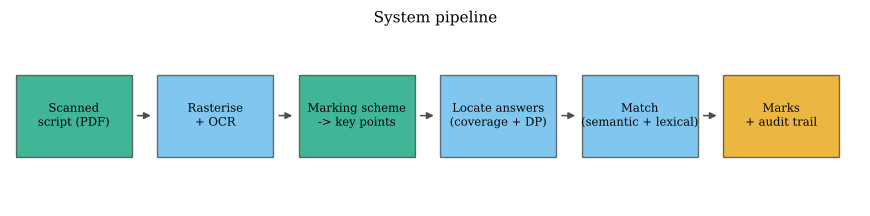

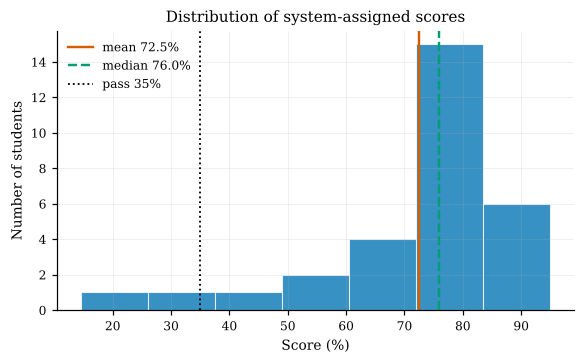

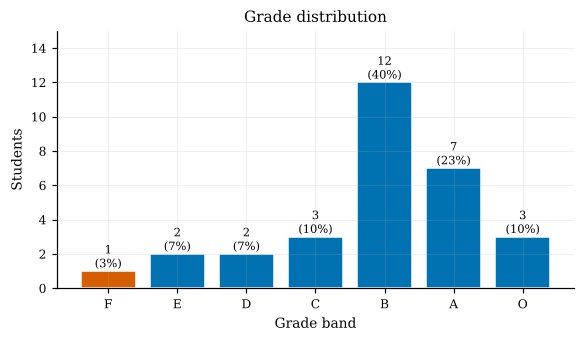

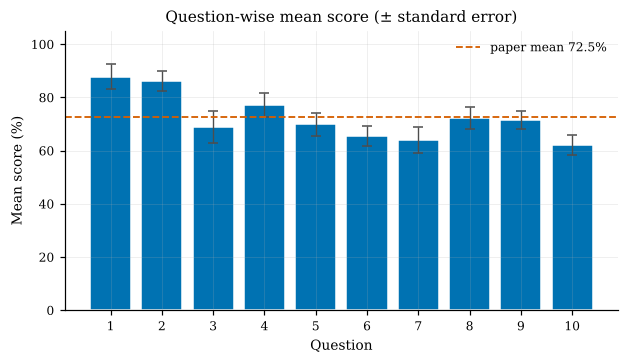

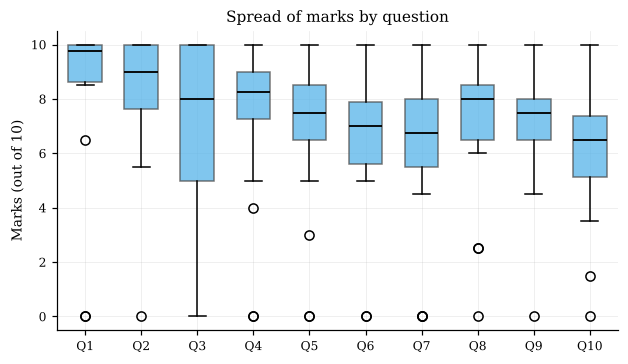

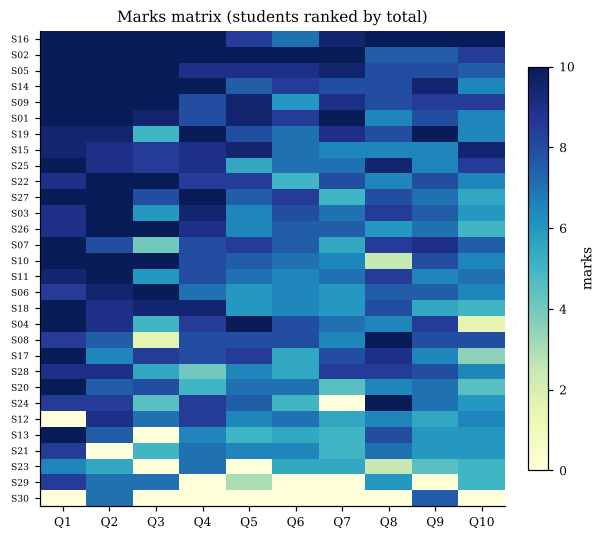

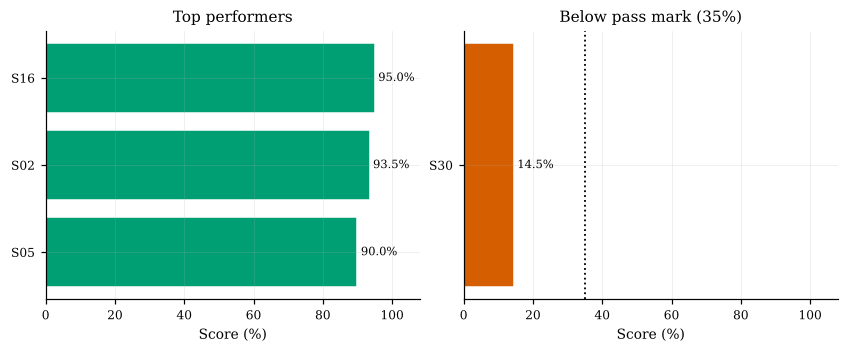

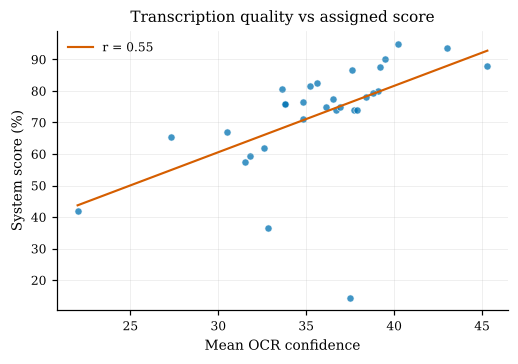

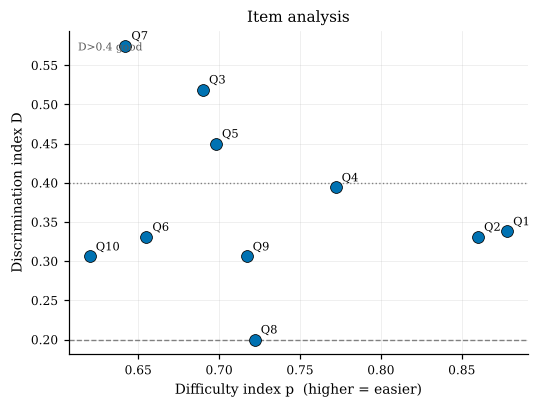

In [36]:
def fig_distribution():
    fig, ax = plt.subplots(figsize=(5.2, 3.2))
    d = results["percent"]
    ax.hist(d, bins=min(18, max(6, len(d) // 4)), color=CB[0], alpha=.78,
            edgecolor="white", linewidth=.7)
    ax.axvline(d.mean(), color=CB[3], lw=1.6, label=f"mean {d.mean():.1f}%")
    ax.axvline(d.median(), color=CB[2], lw=1.6, ls="--", label=f"median {d.median():.1f}%")
    ax.axvline(PASS_PCT, color="k", lw=1.2, ls=":", label=f"pass {PASS_PCT:g}%")
    ax.set_xlabel("Score (%)"); ax.set_ylabel("Number of students")
    ax.set_title("Distribution of system-assigned scores")
    ax.legend(frameon=False)
    return savefig(fig, "fig1_score_distribution")


def fig_grade_bands():
    counts = results["grade"].value_counts().reindex(BAND_ORDER).fillna(0)
    fig, ax = plt.subplots(figsize=(5.2, 3.0))
    cols = [CB[3] if g == "F" else CB[0] for g in counts.index]
    b = ax.bar(counts.index, counts.values, color=cols, edgecolor="white")
    for r, v in zip(b, counts.values):
        if v:
            ax.text(r.get_x() + r.get_width() / 2, v, f"{int(v)}\n({100 * v / len(results):.0f}%)",
                    ha="center", va="bottom", fontsize=7.5)
    ax.set_xlabel("Grade band"); ax.set_ylabel("Students")
    ax.set_title("Grade distribution")
    ax.set_ylim(0, counts.max() * 1.25)
    return savefig(fig, "fig2_grade_bands")


def fig_question_difficulty():
    fig, ax = plt.subplots(figsize=(5.6, 3.2))
    m = results[QCOLS].mean() / MARKS_PER_Q * 100
    se = results[QCOLS].sem() / MARKS_PER_Q * 100
    ax.bar(range(1, NQ + 1), m.values, yerr=se.values, capsize=3,
           color=CB[0], edgecolor="white", error_kw=dict(lw=.9, ecolor="0.3"))
    ax.axhline(m.mean(), color=CB[3], ls="--", lw=1.2, label=f"paper mean {m.mean():.1f}%")
    ax.set_xticks(range(1, NQ + 1)); ax.set_xlabel("Question")
    ax.set_ylabel("Mean score (%)"); ax.set_ylim(0, 105)
    ax.set_title("Question-wise mean score (± standard error)")
    ax.legend(frameon=False)
    return savefig(fig, "fig3_question_difficulty")


def fig_question_box():
    fig, ax = plt.subplots(figsize=(5.6, 3.2))
    bp = ax.boxplot([results[q].to_numpy() for q in QCOLS], patch_artist=True,
                    medianprops=dict(color="k", lw=1.2), widths=.6)
    for patch in bp["boxes"]:
        patch.set_facecolor(CB[5]); patch.set_alpha(.75); patch.set_edgecolor("0.3")
    ax.set_xticklabels([q for q in QCOLS])
    ax.set_ylabel(f"Marks (out of {MARKS_PER_Q:g})")
    ax.set_title("Spread of marks by question")
    return savefig(fig, "fig4_question_boxplot")


def fig_heatmap(max_students=40):
    sub = results.nlargest(min(max_students, len(results)), "total")
    M = sub[QCOLS].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(5.4, max(3.0, .16 * len(sub))))
    im = ax.imshow(M, aspect="auto", cmap="YlGnBu", vmin=0, vmax=MARKS_PER_Q)
    ax.set_xticks(range(NQ)); ax.set_xticklabels(QCOLS)
    step = max(1, len(sub) // 22)
    ax.set_yticks(range(0, len(sub), step))
    ax.set_yticklabels(sub["student"].iloc[::step], fontsize=6)
    ax.set_title("Marks matrix (students ranked by total)")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="marks", shrink=.85)
    return savefig(fig, "fig5_marks_heatmap")


def fig_top_and_fail():
    fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.1))
    t = top_list.head(8).iloc[::-1]
    axes[0].barh(t["student"], t["percent"], color=CB[2], edgecolor="white")
    for y, v in zip(range(len(t)), t["percent"]):
        axes[0].text(v + 1, y, f"{v:.1f}%", va="center", fontsize=7.5)
    axes[0].set_xlabel("Score (%)"); axes[0].set_title(f"Top performers")
    axes[0].set_xlim(0, 108)

    f = fail_list.head(10).iloc[::-1]
    if len(f):
        axes[1].barh(f["student"], f["percent"], color=CB[3], edgecolor="white")
        for y, v in zip(range(len(f)), f["percent"]):
            axes[1].text(v + 1, y, f"{v:.1f}%", va="center", fontsize=7.5)
        axes[1].axvline(PASS_PCT, color="k", ls=":", lw=1.2)
    else:
        axes[1].text(.5, .5, "no failures", ha="center", va="center", transform=axes[1].transAxes)
    axes[1].set_xlabel("Score (%)"); axes[1].set_title(f"Below pass mark ({PASS_PCT:g}%)")
    axes[1].set_xlim(0, 108)
    return savefig(fig, "fig6_top_and_failing")


def fig_ocr_vs_score():
    if "ocr_conf" not in results:
        print("  (skipped fig7: no ocr_conf column)"); return None
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    x, y = results["ocr_conf"], results["percent"]
    ax.scatter(x, y, s=22, color=CB[0], alpha=.75, edgecolor="white", linewidth=.5)
    if len(x) > 2 and x.std() > 0:
        k, b = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 50)
        r = np.corrcoef(x, y)[0, 1]
        ax.plot(xs, k * xs + b, color=CB[3], lw=1.4, label=f"r = {r:.2f}")
        ax.legend(frameon=False)
    ax.set_xlabel("Mean OCR confidence"); ax.set_ylabel("System score (%)")
    ax.set_title("Transcription quality vs assigned score")
    return savefig(fig, "fig7_ocr_vs_score")


def fig_item_quadrant():
    fig, ax = plt.subplots(figsize=(4.8, 3.6))
    ax.scatter(items["difficulty p"], items["discrimination D"], s=60,
               color=CB[0], edgecolor="k", linewidth=.5, zorder=3)
    for _, r in items.iterrows():
        ax.annotate(r["question"], (r["difficulty p"], r["discrimination D"]),
                    xytext=(4, 4), textcoords="offset points", fontsize=7.5)
    ax.axhline(0.2, color="0.5", ls="--", lw=.9)
    ax.axhline(0.4, color="0.5", ls=":", lw=.9)
    ax.set_xlabel("Difficulty index p  (higher = easier)")
    ax.set_ylabel("Discrimination index D")
    ax.set_title("Item analysis")
    ax.text(.02, .965, "D>0.4 good", transform=ax.transAxes, fontsize=7, va="top", color="0.35")
    return savefig(fig, "fig8_item_quadrant")


def fig_pipeline():
    """Methods diagram - system architecture."""
    steps = ["Scanned\nscript (PDF)", "Rasterise\n+ OCR", "Marking scheme\n-> key points",
             "Locate answers\n(coverage + DP)", "Match\n(semantic + lexical)", "Marks\n+ audit trail"]
    fig, ax = plt.subplots(figsize=(7.8, 1.85))
    ax.set_xlim(0, len(steps) * 2.05); ax.set_ylim(0, 2); ax.axis("off"); ax.grid(False)
    for i, s in enumerate(steps):
        x = i * 2.05 + .07
        c = CB[2] if i in (0, 2) else CB[5] if i < 5 else CB[1]
        ax.add_patch(Rectangle((x, .55), 1.68, .95, facecolor=c, alpha=.75,
                               edgecolor="0.25", linewidth=.9))
        ax.text(x + .84, 1.03, s, ha="center", va="center", fontsize=7.6)
        if i < len(steps) - 1:
            ax.add_patch(FancyArrowPatch((x + 1.72, 1.03), (x + 2.0, 1.03),
                                         arrowstyle="-|>", mutation_scale=9, color="0.3"))
    ax.set_title("System pipeline", fontsize=10)
    return savefig(fig, "fig0_pipeline")


print("Generating Tier 1 figures...")
for f in (fig_pipeline, fig_distribution, fig_grade_bands, fig_question_difficulty,
          fig_question_box, fig_heatmap, fig_top_and_fail, fig_ocr_vs_score,
          fig_item_quadrant):
    f()
plt.show()

In [37]:
from sklearn.metrics import cohen_kappa_score


def agreement_stats(h, s):
    h, s = np.asarray(h, float), np.asarray(s, float)
    d = s - h
    ss_res = float(((h - s) ** 2).sum())
    ss_tot = float(((h - h.mean()) ** 2).sum())
    return {
        "n": len(h),
        "MAE": float(np.abs(d).mean()),
        "RMSE": float(np.sqrt((d ** 2).mean())),
        "R2": 1 - ss_res / ss_tot if ss_tot > 0 else float("nan"),
        "pearson r": float(np.corrcoef(h, s)[0, 1]) if len(h) > 2 else float("nan"),
        "bias": float(d.mean()),
        "LoA lower": float(d.mean() - 1.96 * d.std(ddof=1)),
        "LoA upper": float(d.mean() + 1.96 * d.std(ddof=1)),
        "within 1 mark %": float(100 * (np.abs(d) <= 1).mean()),
        "within 2 marks %": float(100 * (np.abs(d) <= 2).mean()),
    }


if human_df is None:
    print("No human marks supplied - Tier 2 skipped.")
    print("Set HUMAN_CSV to a file with columns: file, human_total [, human_Q1 ... human_Qn]")
    val = None
else:
    val = results.merge(human_df, on="file", how="inner")
    assert len(val), "No matching 'file' values between results and human marks."
    stats = agreement_stats(val["human_total"], val["total"])
    print(f"AGREEMENT WITH HUMAN MARKER  (n = {stats['n']} scripts, out of {val['max'].iloc[0]:g})")
    display(pd.DataFrame([stats]).round(3))

    kap = None

    def fig_agreement():
        fig, ax = plt.subplots(figsize=(4.3, 4.1))
        x, y = val["human_total"], val["total"]
        lim = [0, float(val["max"].iloc[0])]
        ax.plot(lim, lim, color="0.45", ls="--", lw=1.1, label="perfect agreement")
        ax.scatter(x, y, s=26, color=CB[0], alpha=.75, edgecolor="white", linewidth=.5)
        if len(x) > 2:
            k, b = np.polyfit(x, y, 1)
            xs = np.linspace(*lim, 50)
            ax.plot(xs, k * xs + b, color=CB[3], lw=1.4,
                    label=f"fit: y={k:.2f}x{b:+.1f}")
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_xlabel("Human marker (total)"); ax.set_ylabel("System (total)")
        ax.set_title("System vs human marks")
        ax.text(.04, .96, f"MAE = {stats['MAE']:.2f}\nRMSE = {stats['RMSE']:.2f}\n"
                          f"$R^2$ = {stats['R2']:.3f}\nr = {stats['pearson r']:.3f}",
                transform=ax.transAxes, va="top", fontsize=8,
                bbox=dict(fc="white", ec="0.7", lw=.6, alpha=.9))
        ax.legend(frameon=False, loc="lower right")
        return savefig(fig, "fig9_agreement_scatter")

    def fig_bland_altman():
        fig, ax = plt.subplots(figsize=(4.8, 3.4))
        mean = (val["human_total"] + val["total"]) / 2
        diff = val["total"] - val["human_total"]
        ax.scatter(mean, diff, s=24, color=CB[0], alpha=.75, edgecolor="white", linewidth=.5)
        ax.axhline(stats["bias"], color=CB[3], lw=1.4, label=f"bias {stats['bias']:+.2f}")
        for v, lbl in [(stats["LoA upper"], "+1.96 SD"), (stats["LoA lower"], "-1.96 SD")]:
            ax.axhline(v, color="0.4", ls="--", lw=1.0)
            ax.text(mean.max(), v, f" {lbl} ({v:+.2f})", fontsize=7, va="bottom", ha="right")
        ax.axhline(0, color="0.75", lw=.8, zorder=0)
        ax.set_xlabel("Mean of human and system marks")
        ax.set_ylabel("System - human (marks)")
        ax.set_title("Bland-Altman agreement")
        ax.legend(frameon=False, loc="upper left")
        return savefig(fig, "fig10_bland_altman")

    def fig_error_analysis():
        fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.1))
        diff = val["total"] - val["human_total"]
        axes[0].hist(diff, bins=15, color=CB[5], edgecolor="white", alpha=.85)
        axes[0].axvline(0, color="k", lw=1.0)
        axes[0].axvline(diff.mean(), color=CB[3], lw=1.4, ls="--",
                        label=f"bias {diff.mean():+.2f}")
        axes[0].set_xlabel("System - human (marks)"); axes[0].set_ylabel("Scripts")
        axes[0].set_title("Error distribution"); axes[0].legend(frameon=False)

        hq = [f"human_Q{q[1:]}" for q in QCOLS]
        if all(c in val.columns for c in hq):
            mae = [np.abs(val[q] - val[h]).mean() for q, h in zip(QCOLS, hq)]
            axes[1].bar(range(1, NQ + 1), mae, color=CB[1], edgecolor="white")
            axes[1].axhline(np.mean(mae), color=CB[3], ls="--", lw=1.2,
                            label=f"mean {np.mean(mae):.2f}")
            axes[1].set_xticks(range(1, NQ + 1))
            axes[1].set_xlabel("Question"); axes[1].set_ylabel("MAE (marks)")
            axes[1].set_title("Per-question error"); axes[1].legend(frameon=False)
        else:
            axes[1].text(.5, .5, "per-question human marks\nnot supplied",
                         ha="center", va="center", transform=axes[1].transAxes, fontsize=8)
            axes[1].set_axis_off()
        return savefig(fig, "fig11_error_analysis")

    def fig_confusion():
        nonlocal_k = {}
        hp = 100 * val["human_total"] / val["max"]
        sp = 100 * val["total"] / val["max"]
        hg = [BAND_ORDER.index(grade_of(v)) for v in hp]
        sg = [BAND_ORDER.index(grade_of(v)) for v in sp]
        k = len(BAND_ORDER)
        M = np.zeros((k, k), int)
        for a, b in zip(hg, sg):
            M[a, b] += 1
        try:
            qwk = cohen_kappa_score(hg, sg, weights="quadratic", labels=list(range(k)))
        except Exception:
            qwk = float("nan")
        nonlocal_k["qwk"] = qwk

        fig, ax = plt.subplots(figsize=(4.4, 4.0))
        im = ax.imshow(M, cmap="Blues")
        for i in range(k):
            for j in range(k):
                if M[i, j]:
                    ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8,
                            color="white" if M[i, j] > M.max() * .55 else "black")
        ax.set_xticks(range(k)); ax.set_xticklabels(BAND_ORDER)
        ax.set_yticks(range(k)); ax.set_yticklabels(BAND_ORDER)
        ax.set_xlabel("System grade"); ax.set_ylabel("Human grade")
        exact = 100 * np.trace(M) / M.sum()
        ax.set_title(f"Grade agreement\nexact {exact:.1f}%, QWK = {qwk:.3f}")
        ax.grid(False)
        savefig(fig, "fig12_grade_confusion")
        return nonlocal_k["qwk"]

    fig_agreement(); fig_bland_altman(); fig_error_analysis()
    kap = fig_confusion()
    plt.show()

    print(f"\nReport in the paper: MAE {stats['MAE']:.2f}, RMSE {stats['RMSE']:.2f}, "
          f"R2 {stats['R2']:.3f}, bias {stats['bias']:+.2f} "
          f"(LoA {stats['LoA lower']:.2f} to {stats['LoA upper']:.2f}), QWK {kap:.3f}, "
          f"{stats['within 2 marks %']:.0f}% within 2 marks.")

No human marks supplied - Tier 2 skipped.
Set HUMAN_CSV to a file with columns: file, human_total [, human_Q1 ... human_Qn]


> **Note (R1).** The next five cells repeat the figure block above with the improved Tier-2 code (cell order kept as in
> the submitted notebook). They regenerate the same Tier-1 figures, so only one copy of each should go into the paper
> (Reviewer 3: *reduce repetitive plots*). With `METHOD_VERSION = "submitted"` these figures describe the **submitted**
> system; the revised system's figures are produced in section 12.

In [38]:
import os, sys, io, json, glob, zipfile, importlib.util, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ipywidgets"], check=False)

# ============================== SETTINGS ==============================
FIGDIR      = ("/content/grading/figures" if IN_COLAB else "./grading/figures")
RESULTS_CSV = ("/content/grading/marks.csv" if IN_COLAB else "./grading/marks.csv")
HUMAN_CSV   = None      # e.g. "./grading/human_marks.csv" -> unlocks Tier 2 figures
PASS_PCT    = 35.0      # below this % = fail (your "<35 out of 100")
TOP_N       = 3
GRADE_BANDS = [("O", 90), ("A", 80), ("B", 70), ("C", 60), ("D", 50), ("E", PASS_PCT), ("F", 0)]
FIG_FORMATS = ["png", "pdf"]
# ======================================================================

os.makedirs(FIGDIR, exist_ok=True)

# Okabe-Ito: colourblind-safe and it survives greyscale printing
CB = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#999999"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300,
    "font.family": "serif", "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
    "savefig.bbox": "tight", "figure.constrained_layout.use": True,
    "axes.prop_cycle": plt.cycler(color=CB),
})

DEMO = False            # set automatically in the next cell
SAVED_FIGS = []

def savefig(fig, name):
    """Save a figure in every configured format. Watermarks anything built on demo data."""
    if DEMO:
        fig.text(0.5, 0.5, "SIMULATED DATA\nNOT FOR PUBLICATION",
                 fontsize=26, color="red", alpha=0.16, rotation=30,
                 ha="center", va="center", zorder=1000, weight="bold")
    paths = []
    for ext in FIG_FORMATS:
        p = os.path.join(FIGDIR, f"{name}.{ext}")
        fig.savefig(p)
        paths.append(p)
    SAVED_FIGS.append(paths[0])
    print(f"  saved {name}: " + ", ".join(os.path.basename(p) for p in paths))
    return fig

print("Figure style ready. Output ->", FIGDIR)

Figure style ready. Output -> ./grading/figures


In [39]:
def _simulate(n_students=60, n_q=8, marks_per_q=10.0, seed=7):
    """Plausible synthetic cohort, used only to preview the figures and GUI."""
    rng = np.random.default_rng(seed)
    ability = rng.beta(5.5, 2.6, n_students)                 # skewed toward competent
    difficulty = rng.uniform(0.55, 0.95, n_q)
    rows = []
    for i in range(n_students):
        r = {"file": f"student_{i + 1:03d}.pdf",
             "ocr_conf": float(np.clip(rng.normal(56, 9), 25, 95))}
        for q in range(1, n_q + 1):
            base = ability[i] * difficulty[q - 1] + rng.normal(0, 0.09)
            r[f"Q{q}"] = float(np.clip(round(base * marks_per_q * 2) / 2, 0, marks_per_q))
        r["total"] = sum(r[f"Q{q}"] for q in range(1, n_q + 1))
        r["max"] = n_q * marks_per_q
        rows.append(r)
    df = pd.DataFrame(rows)

    # a human marker: correlated with the system, noisier where OCR is poor
    noise = rng.normal(0, 1.0, n_students) + (60 - df["ocr_conf"]).clip(0) * 0.055
    human = (df["total"] * 1.04 - 1.1 + noise).clip(0, df["max"])
    hum = pd.DataFrame({"file": df["file"],
                        "human_total": (human * 2).round() / 2})
    for q in range(1, n_q + 1):
        hq = (df[f"Q{q}"] * 1.04 - 0.15 + rng.normal(0, 0.85, n_students)).clip(0, marks_per_q)
        hum[f"human_Q{q}"] = (hq * 2).round() / 2
    return df, hum


human_df = None

if "marks_df" in globals() and isinstance(globals()["marks_df"], pd.DataFrame) and len(globals()["marks_df"]):
    results = globals()["marks_df"].copy()
    DEMO = False
    print(f"Using marks_df already in memory ({len(results)} scripts).")
elif os.path.exists(RESULTS_CSV):
    results = pd.read_csv(RESULTS_CSV)
    DEMO = False
    print(f"Loaded {RESULTS_CSV} ({len(results)} scripts).")
else:
    results, human_df = _simulate()
    DEMO = True
    print("!! No real results found - using SIMULATED data so you can preview the figures.")
    print("!! Every figure will be watermarked. Re-run after a real batch to get clean output.")

if HUMAN_CSV and os.path.exists(HUMAN_CSV):
    human_df = pd.read_csv(HUMAN_CSV)
    print(f"Loaded human marks from {HUMAN_CSV} - Tier 2 validation figures enabled.")

QCOLS = sorted([c for c in results.columns if c.startswith("Q") and c[1:].isdigit()],
               key=lambda c: int(c[1:]))
NQ = len(QCOLS)
MARKS_PER_Q = float(results["max"].iloc[0]) / NQ if "max" in results else 10.0
if "max" not in results:
    results["max"] = NQ * MARKS_PER_Q
if "total" not in results:
    results["total"] = results[QCOLS].sum(axis=1)
results["percent"] = 100.0 * results["total"] / results["max"]
if "student" not in results:
    results["student"] = results["file"].astype(str).str.replace(r"\.pdf$", "", regex=True)

print(f"\n{len(results)} scripts | {NQ} questions x {MARKS_PER_Q:g} marks "
      f"| mean {results['percent'].mean():.1f}%")
results.head()

Using marks_df already in memory (30 scripts).

30 scripts | 10 questions x 10 marks | mean 72.5%


,file,ocr_conf,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,total,max,review,percent,student
0,S01.pdf,37.6,10.0,10.0,9.5,8.0,9.5,8.5,10.0,6.5,8.0,6.5,86.5,100.0,"Q8,Q10",86.5,S01
1,S02.pdf,43.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,7.5,7.5,8.5,93.5,100.0,Q9,93.5,S02
2,S03.pdf,38.4,9.0,10.0,6.0,9.5,6.5,8.0,7.0,8.5,7.5,6.0,78.0,100.0,"Q3,Q5,Q7,Q10",78.0,S03
3,S04.pdf,36.7,10.0,9.0,5.0,8.5,10.0,8.0,7.0,6.5,8.5,1.5,74.0,100.0,"Q3,Q7,Q8",74.0,S04
4,S05.pdf,39.5,10.0,10.0,10.0,9.0,9.0,9.0,9.5,8.0,8.0,7.5,90.0,100.0,,90.0,S05


In [40]:
def grade_of(pct):
    for name, cut in GRADE_BANDS:
        if pct >= cut:
            return name
    return GRADE_BANDS[-1][0]

BAND_ORDER = [b[0] for b in GRADE_BANDS][::-1]      # weakest -> strongest
results["grade"] = results["percent"].map(grade_of)
results["rank"] = results["total"].rank(ascending=False, method="min").astype(int)


def toppers(df, n=TOP_N):
    """Top n by rank, keeping every student tied at the cut-off."""
    cut = df["rank"].nsmallest(n).max()
    return df[df["rank"] <= cut].sort_values("rank")


def failures(df, pass_pct=PASS_PCT):
    return df[df["percent"] < pass_pct].sort_values("percent")


def item_analysis(df, qcols, max_per_q):
    """
    Classical test theory per question.
      difficulty p : mean fraction scored (higher = easier)
      discrimination D : top 27% mean minus bottom 27% mean, in fractions
                         (>0.4 excellent, 0.2-0.4 acceptable, <0.2 poor, <0 broken)
    """
    n = len(df)
    k = max(1, int(round(0.27 * n)))
    hi = df.nlargest(k, "total")
    lo = df.nsmallest(k, "total")
    rows = []
    for q in qcols:
        p = df[q].mean() / max_per_q
        D = (hi[q].mean() - lo[q].mean()) / max_per_q
        rows.append({"question": q, "mean marks": round(df[q].mean(), 2),
                     "sd": round(df[q].std(ddof=1), 2),
                     "difficulty p": round(p, 3), "discrimination D": round(D, 3),
                     "quality": "good" if D >= 0.4 else "fair" if D >= 0.2 else "poor"})
    return pd.DataFrame(rows)


def cronbach_alpha(df, qcols):
    """Internal consistency of the question set. >0.7 is the usual acceptability threshold."""
    X = df[qcols].to_numpy(dtype=float)
    k = X.shape[1]
    if k < 2:
        return float("nan")
    item_var = X.var(axis=0, ddof=1).sum()
    total_var = X.sum(axis=1).var(ddof=1)
    if total_var == 0:
        return float("nan")
    return float(k / (k - 1) * (1 - item_var / total_var))


summary_stats = pd.DataFrame([{
    "scripts": len(results),
    "mean %": round(results["percent"].mean(), 2),
    "median %": round(results["percent"].median(), 2),
    "sd": round(results["percent"].std(ddof=1), 2),
    "min %": round(results["percent"].min(), 2),
    "max %": round(results["percent"].max(), 2),
    "pass rate %": round(100 * (results["percent"] >= PASS_PCT).mean(), 1),
    "Cronbach alpha": round(cronbach_alpha(results, QCOLS), 3),
}])

items = item_analysis(results, QCOLS, MARKS_PER_Q)
top_list = toppers(results)
fail_list = failures(results)

print("COHORT SUMMARY"); display(summary_stats)
print("\nITEM ANALYSIS"); display(items)
print(f"\nTOP {TOP_N}")
display(top_list[["rank", "student", "total", "max", "percent", "grade"]])
print(f"\nFAILED (< {PASS_PCT:g}%): {len(fail_list)} of {len(results)}")
display(fail_list[["student", "total", "max", "percent", "grade"]].head(20))

COHORT SUMMARY


,scripts,mean %,median %,sd,min %,max %,pass rate %,Cronbach alpha
0,30,72.53,76.0,17.18,14.5,95.0,96.7,0.891



ITEM ANALYSIS


,question,mean marks,sd,difficulty p,discrimination D,quality
0,Q1,8.78,2.52,0.878,0.338,fair
1,Q2,8.60,2.06,0.860,0.331,fair
2,Q3,6.90,3.27,0.690,0.519,good
3,Q4,7.72,2.53,0.772,0.394,fair
4,Q5,6.98,2.47,0.698,0.450,good
5,Q6,6.55,2.15,0.655,0.331,fair
6,Q7,6.42,2.68,0.642,0.575,good
7,Q8,7.22,2.24,0.722,0.200,fair
8,Q9,7.17,1.87,0.717,0.306,fair
9,Q10,6.20,2.09,0.620,0.306,fair



TOP 3


,rank,student,total,max,percent,grade
15,1,S16,95.0,100.0,95.0,O
1,2,S02,93.5,100.0,93.5,O
4,3,S05,90.0,100.0,90.0,O



FAILED (< 35%): 1 of 30


,student,total,max,percent,grade
29,S30,14.5,100.0,14.5,F


Generating Tier 1 figures...


  saved fig0_pipeline: fig0_pipeline.png, fig0_pipeline.pdf


  saved fig1_score_distribution: fig1_score_distribution.png, fig1_score_distribution.pdf


  saved fig2_grade_bands: fig2_grade_bands.png, fig2_grade_bands.pdf


  saved fig3_question_difficulty: fig3_question_difficulty.png, fig3_question_difficulty.pdf


  saved fig4_question_boxplot: fig4_question_boxplot.png, fig4_question_boxplot.pdf


  saved fig5_marks_heatmap: fig5_marks_heatmap.png, fig5_marks_heatmap.pdf
  saved fig6_top_and_failing: fig6_top_and_failing.png, fig6_top_and_failing.pdf


  saved fig7_ocr_vs_score: fig7_ocr_vs_score.png, fig7_ocr_vs_score.pdf


  saved fig8_item_quadrant: fig8_item_quadrant.png, fig8_item_quadrant.pdf


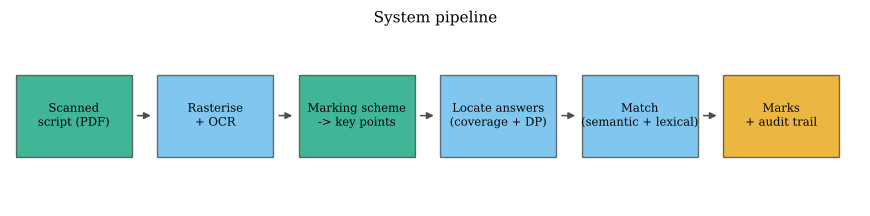

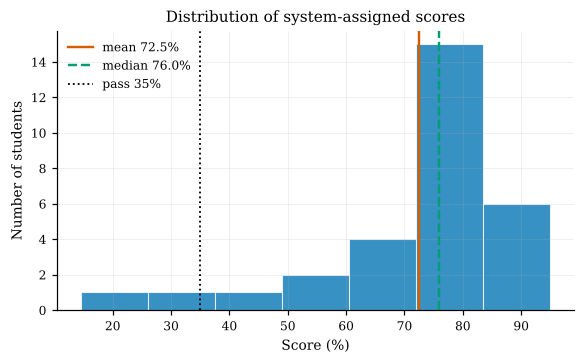

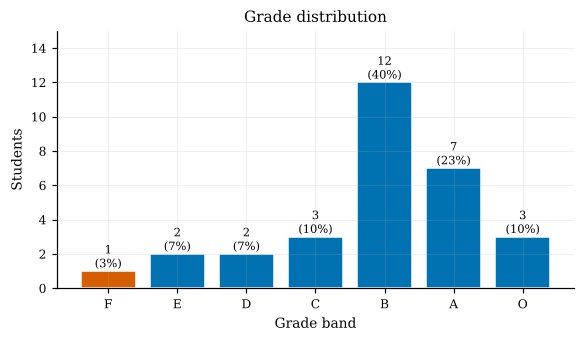

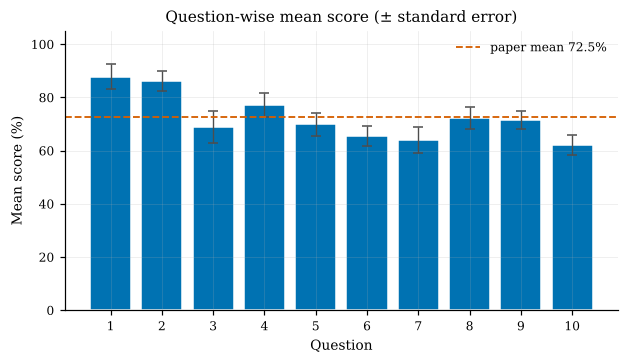

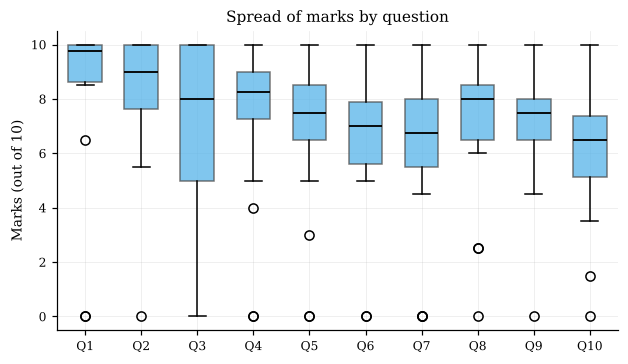

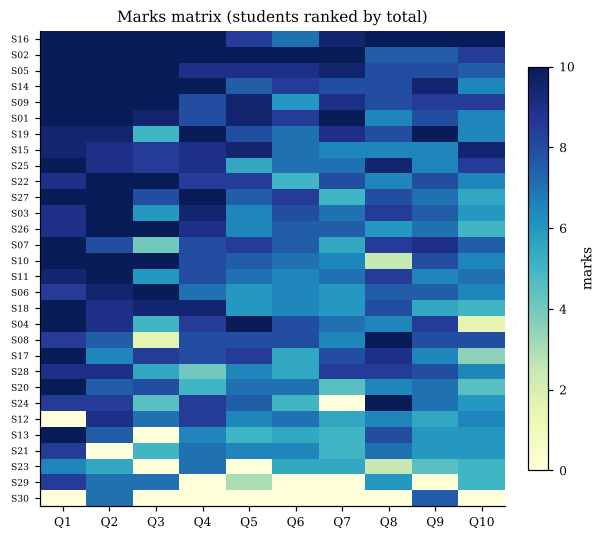

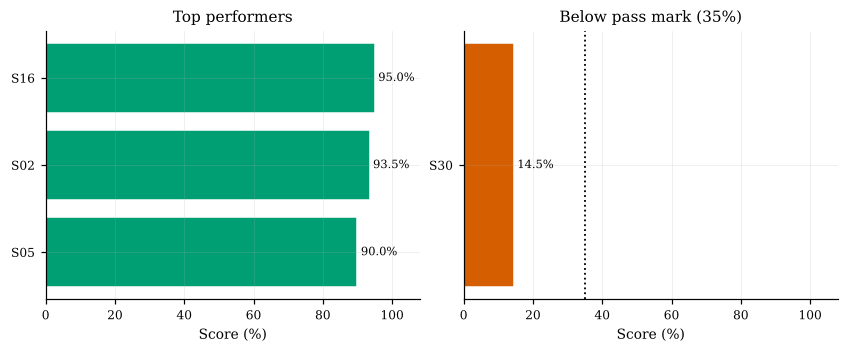

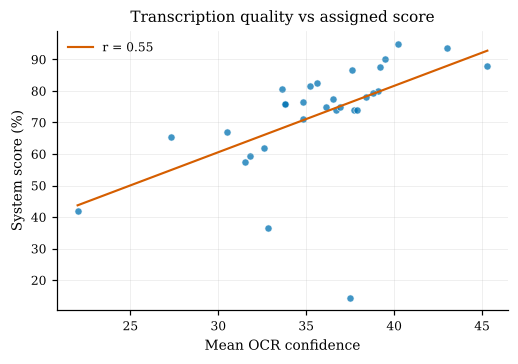

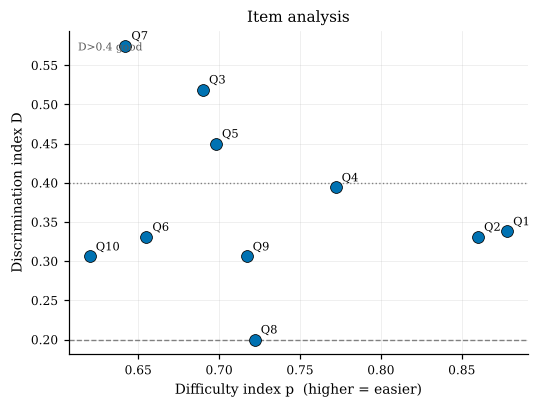

In [41]:
def fig_distribution():
    fig, ax = plt.subplots(figsize=(5.2, 3.2))
    d = results["percent"]
    ax.hist(d, bins=min(18, max(6, len(d) // 4)), color=CB[0], alpha=.78,
            edgecolor="white", linewidth=.7)
    ax.axvline(d.mean(), color=CB[3], lw=1.6, label=f"mean {d.mean():.1f}%")
    ax.axvline(d.median(), color=CB[2], lw=1.6, ls="--", label=f"median {d.median():.1f}%")
    ax.axvline(PASS_PCT, color="k", lw=1.2, ls=":", label=f"pass {PASS_PCT:g}%")
    ax.set_xlabel("Score (%)"); ax.set_ylabel("Number of students")
    ax.set_title("Distribution of system-assigned scores")
    ax.legend(frameon=False)
    return savefig(fig, "fig1_score_distribution")


def fig_grade_bands():
    counts = results["grade"].value_counts().reindex(BAND_ORDER).fillna(0)
    fig, ax = plt.subplots(figsize=(5.2, 3.0))
    cols = [CB[3] if g == "F" else CB[0] for g in counts.index]
    b = ax.bar(counts.index, counts.values, color=cols, edgecolor="white")
    for r, v in zip(b, counts.values):
        if v:
            ax.text(r.get_x() + r.get_width() / 2, v, f"{int(v)}\n({100 * v / len(results):.0f}%)",
                    ha="center", va="bottom", fontsize=7.5)
    ax.set_xlabel("Grade band"); ax.set_ylabel("Students")
    ax.set_title("Grade distribution")
    ax.set_ylim(0, counts.max() * 1.25)
    return savefig(fig, "fig2_grade_bands")


def fig_question_difficulty():
    fig, ax = plt.subplots(figsize=(5.6, 3.2))
    m = results[QCOLS].mean() / MARKS_PER_Q * 100
    se = results[QCOLS].sem() / MARKS_PER_Q * 100
    ax.bar(range(1, NQ + 1), m.values, yerr=se.values, capsize=3,
           color=CB[0], edgecolor="white", error_kw=dict(lw=.9, ecolor="0.3"))
    ax.axhline(m.mean(), color=CB[3], ls="--", lw=1.2, label=f"paper mean {m.mean():.1f}%")
    ax.set_xticks(range(1, NQ + 1)); ax.set_xlabel("Question")
    ax.set_ylabel("Mean score (%)"); ax.set_ylim(0, 105)
    ax.set_title("Question-wise mean score (± standard error)")
    ax.legend(frameon=False)
    return savefig(fig, "fig3_question_difficulty")


def fig_question_box():
    fig, ax = plt.subplots(figsize=(5.6, 3.2))
    bp = ax.boxplot([results[q].to_numpy() for q in QCOLS], patch_artist=True,
                    medianprops=dict(color="k", lw=1.2), widths=.6)
    for patch in bp["boxes"]:
        patch.set_facecolor(CB[5]); patch.set_alpha(.75); patch.set_edgecolor("0.3")
    ax.set_xticklabels([q for q in QCOLS])
    ax.set_ylabel(f"Marks (out of {MARKS_PER_Q:g})")
    ax.set_title("Spread of marks by question")
    return savefig(fig, "fig4_question_boxplot")


def fig_heatmap(max_students=40):
    sub = results.nlargest(min(max_students, len(results)), "total")
    M = sub[QCOLS].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(5.4, max(3.0, .16 * len(sub))))
    im = ax.imshow(M, aspect="auto", cmap="YlGnBu", vmin=0, vmax=MARKS_PER_Q)
    ax.set_xticks(range(NQ)); ax.set_xticklabels(QCOLS)
    step = max(1, len(sub) // 22)
    ax.set_yticks(range(0, len(sub), step))
    ax.set_yticklabels(sub["student"].iloc[::step], fontsize=6)
    ax.set_title("Marks matrix (students ranked by total)")
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="marks", shrink=.85)
    return savefig(fig, "fig5_marks_heatmap")


def fig_top_and_fail():
    fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.1))
    t = top_list.head(8).iloc[::-1]
    axes[0].barh(t["student"], t["percent"], color=CB[2], edgecolor="white")
    for y, v in zip(range(len(t)), t["percent"]):
        axes[0].text(v + 1, y, f"{v:.1f}%", va="center", fontsize=7.5)
    axes[0].set_xlabel("Score (%)"); axes[0].set_title(f"Top performers")
    axes[0].set_xlim(0, 108)

    f = fail_list.head(10).iloc[::-1]
    if len(f):
        axes[1].barh(f["student"], f["percent"], color=CB[3], edgecolor="white")
        for y, v in zip(range(len(f)), f["percent"]):
            axes[1].text(v + 1, y, f"{v:.1f}%", va="center", fontsize=7.5)
        axes[1].axvline(PASS_PCT, color="k", ls=":", lw=1.2)
    else:
        axes[1].text(.5, .5, "no failures", ha="center", va="center", transform=axes[1].transAxes)
    axes[1].set_xlabel("Score (%)"); axes[1].set_title(f"Below pass mark ({PASS_PCT:g}%)")
    axes[1].set_xlim(0, 108)
    return savefig(fig, "fig6_top_and_failing")


def fig_ocr_vs_score():
    if "ocr_conf" not in results:
        print("  (skipped fig7: no ocr_conf column)"); return None
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    x, y = results["ocr_conf"], results["percent"]
    ax.scatter(x, y, s=22, color=CB[0], alpha=.75, edgecolor="white", linewidth=.5)
    if len(x) > 2 and x.std() > 0:
        k, b = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 50)
        r = np.corrcoef(x, y)[0, 1]
        ax.plot(xs, k * xs + b, color=CB[3], lw=1.4, label=f"r = {r:.2f}")
        ax.legend(frameon=False)
    ax.set_xlabel("Mean OCR confidence"); ax.set_ylabel("System score (%)")
    ax.set_title("Transcription quality vs assigned score")
    return savefig(fig, "fig7_ocr_vs_score")


def fig_item_quadrant():
    fig, ax = plt.subplots(figsize=(4.8, 3.6))
    ax.scatter(items["difficulty p"], items["discrimination D"], s=60,
               color=CB[0], edgecolor="k", linewidth=.5, zorder=3)
    for _, r in items.iterrows():
        ax.annotate(r["question"], (r["difficulty p"], r["discrimination D"]),
                    xytext=(4, 4), textcoords="offset points", fontsize=7.5)
    ax.axhline(0.2, color="0.5", ls="--", lw=.9)
    ax.axhline(0.4, color="0.5", ls=":", lw=.9)
    ax.set_xlabel("Difficulty index p  (higher = easier)")
    ax.set_ylabel("Discrimination index D")
    ax.set_title("Item analysis")
    ax.text(.02, .965, "D>0.4 good", transform=ax.transAxes, fontsize=7, va="top", color="0.35")
    return savefig(fig, "fig8_item_quadrant")


def fig_pipeline():
    """Methods diagram - system architecture."""
    steps = ["Scanned\nscript (PDF)", "Rasterise\n+ OCR", "Marking scheme\n-> key points",
             "Locate answers\n(coverage + DP)", "Match\n(semantic + lexical)", "Marks\n+ audit trail"]
    fig, ax = plt.subplots(figsize=(7.8, 1.85))
    ax.set_xlim(0, len(steps) * 2.05); ax.set_ylim(0, 2); ax.axis("off"); ax.grid(False)
    for i, s in enumerate(steps):
        x = i * 2.05 + .07
        c = CB[2] if i in (0, 2) else CB[5] if i < 5 else CB[1]
        ax.add_patch(Rectangle((x, .55), 1.68, .95, facecolor=c, alpha=.75,
                               edgecolor="0.25", linewidth=.9))
        ax.text(x + .84, 1.03, s, ha="center", va="center", fontsize=7.6)
        if i < len(steps) - 1:
            ax.add_patch(FancyArrowPatch((x + 1.72, 1.03), (x + 2.0, 1.03),
                                         arrowstyle="-|>", mutation_scale=9, color="0.3"))
    ax.set_title("System pipeline", fontsize=10)
    return savefig(fig, "fig0_pipeline")


print("Generating Tier 1 figures...")
for f in (fig_pipeline, fig_distribution, fig_grade_bands, fig_question_difficulty,
          fig_question_box, fig_heatmap, fig_top_and_fail, fig_ocr_vs_score,
          fig_item_quadrant):
    f()
plt.show()

In [42]:
from sklearn.metrics import cohen_kappa_score

tier2_stats, tier2_val, tier2_qwk = None, None, None


def agreement_stats(h, s):
    h, s = np.asarray(h, float), np.asarray(s, float)
    d = s - h
    ss_res = float(((h - s) ** 2).sum())
    ss_tot = float(((h - h.mean()) ** 2).sum())
    return {
        "n": len(h),
        "MAE": float(np.abs(d).mean()),
        "RMSE": float(np.sqrt((d ** 2).mean())),
        "R2": 1 - ss_res / ss_tot if ss_tot > 0 else float("nan"),
        "pearson r": float(np.corrcoef(h, s)[0, 1]) if len(h) > 2 else float("nan"),
        "bias": float(d.mean()),
        "LoA lower": float(d.mean() - 1.96 * d.std(ddof=1)) if len(h) > 1 else float("nan"),
        "LoA upper": float(d.mean() + 1.96 * d.std(ddof=1)) if len(h) > 1 else float("nan"),
        "within 1 mark %": float(100 * (np.abs(d) <= 1).mean()),
        "within 2 marks %": float(100 * (np.abs(d) <= 2).mean()),
    }


def run_tier2(hdf):
    """Generate every agreement figure. Returns the stats dict, or None if no human marks."""
    global tier2_stats, tier2_val, tier2_qwk

    if hdf is None or not len(hdf):
        print("No human marks supplied - Tier 2 skipped.")
        print("Use section E2 below to download a pre-filled template and upload it back.")
        return None

    val = results.merge(hdf, on="file", how="inner")
    if not len(val):
        print("No rows matched. The 'file' column must match your results exactly.")
        print("  results:", list(results['file'])[:3])
        print("  human   :", list(hdf['file'])[:3])
        return None
    if len(val) < 10:
        print(f"NOTE: only {len(val)} matched scripts. Limits of agreement will be very wide; "
              "aim for 30+ before quoting these numbers in a paper.")

    stats = agreement_stats(val["human_total"], val["total"])
    maxm = float(val["max"].iloc[0])
    print(f"AGREEMENT WITH HUMAN MARKER  (n = {stats['n']} scripts, out of {maxm:g})")
    display(pd.DataFrame([stats]).round(3))

    def fig_agreement():
        fig, ax = plt.subplots(figsize=(4.3, 4.1))
        x, y = val["human_total"], val["total"]
        lim = [0, maxm]
        ax.plot(lim, lim, color="0.45", ls="--", lw=1.1, label="perfect agreement")
        ax.scatter(x, y, s=26, color=CB[0], alpha=.75, edgecolor="white", linewidth=.5)
        if len(x) > 2 and x.std() > 0:
            k, b = np.polyfit(x, y, 1)
            xs = np.linspace(*lim, 50)
            ax.plot(xs, k * xs + b, color=CB[3], lw=1.4, label=f"fit: y={k:.2f}x{b:+.1f}")
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_xlabel("Human marker (total)"); ax.set_ylabel("System (total)")
        ax.set_title("System vs human marks")
        ax.text(.04, .96, f"MAE = {stats['MAE']:.2f}\nRMSE = {stats['RMSE']:.2f}\n"
                          f"$R^2$ = {stats['R2']:.3f}\nr = {stats['pearson r']:.3f}",
                transform=ax.transAxes, va="top", fontsize=8,
                bbox=dict(fc="white", ec="0.7", lw=.6, alpha=.9))
        ax.legend(frameon=False, loc="lower right")
        return savefig(fig, "fig9_agreement_scatter")

    def fig_bland_altman():
        fig, ax = plt.subplots(figsize=(4.8, 3.4))
        mean = (val["human_total"] + val["total"]) / 2
        diff = val["total"] - val["human_total"]
        ax.scatter(mean, diff, s=24, color=CB[0], alpha=.75, edgecolor="white", linewidth=.5)
        ax.axhline(stats["bias"], color=CB[3], lw=1.4, label=f"bias {stats['bias']:+.2f}")
        for v, lbl in [(stats["LoA upper"], "+1.96 SD"), (stats["LoA lower"], "-1.96 SD")]:
            if np.isfinite(v):
                ax.axhline(v, color="0.4", ls="--", lw=1.0)
                ax.text(mean.max(), v, f" {lbl} ({v:+.2f})", fontsize=7, va="bottom", ha="right")
        ax.axhline(0, color="0.75", lw=.8, zorder=0)
        ax.set_xlabel("Mean of human and system marks")
        ax.set_ylabel("System - human (marks)")
        ax.set_title("Bland-Altman agreement")
        ax.legend(frameon=False, loc="upper left")
        return savefig(fig, "fig10_bland_altman")

    def fig_error_analysis():
        fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.1))
        diff = val["total"] - val["human_total"]
        axes[0].hist(diff, bins=min(15, max(5, len(diff) // 3)), color=CB[5],
                     edgecolor="white", alpha=.85)
        axes[0].axvline(0, color="k", lw=1.0)
        axes[0].axvline(diff.mean(), color=CB[3], lw=1.4, ls="--", label=f"bias {diff.mean():+.2f}")
        axes[0].set_xlabel("System - human (marks)"); axes[0].set_ylabel("Scripts")
        axes[0].set_title("Error distribution"); axes[0].legend(frameon=False)

        hq = [f"human_Q{q[1:]}" for q in QCOLS]
        if all(c in val.columns for c in hq):
            mae = [np.abs(val[q] - val[h]).mean() for q, h in zip(QCOLS, hq)]
            axes[1].bar(range(1, NQ + 1), mae, color=CB[1], edgecolor="white")
            axes[1].axhline(np.mean(mae), color=CB[3], ls="--", lw=1.2,
                            label=f"mean {np.mean(mae):.2f}")
            axes[1].set_xticks(range(1, NQ + 1))
            axes[1].set_xlabel("Question"); axes[1].set_ylabel("MAE (marks)")
            axes[1].set_title("Per-question error"); axes[1].legend(frameon=False)
        else:
            axes[1].text(.5, .5, "per-question human marks\nnot supplied",
                         ha="center", va="center", transform=axes[1].transAxes, fontsize=8)
            axes[1].set_axis_off()
        return savefig(fig, "fig11_error_analysis")

    def fig_confusion():
        hp = 100 * val["human_total"] / val["max"]
        sp = 100 * val["total"] / val["max"]
        hg = [BAND_ORDER.index(grade_of(v)) for v in hp]
        sg = [BAND_ORDER.index(grade_of(v)) for v in sp]
        k = len(BAND_ORDER)
        M = np.zeros((k, k), int)
        for a, b in zip(hg, sg):
            M[a, b] += 1
        try:
            qwk = float(cohen_kappa_score(hg, sg, weights="quadratic", labels=list(range(k))))
        except Exception:
            qwk = float("nan")
        fig, ax = plt.subplots(figsize=(4.4, 4.0))
        im = ax.imshow(M, cmap="Blues")
        for i in range(k):
            for j in range(k):
                if M[i, j]:
                    ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8,
                            color="white" if M[i, j] > M.max() * .55 else "black")
        ax.set_xticks(range(k)); ax.set_xticklabels(BAND_ORDER)
        ax.set_yticks(range(k)); ax.set_yticklabels(BAND_ORDER)
        ax.set_xlabel("System grade"); ax.set_ylabel("Human grade")
        exact = 100 * np.trace(M) / M.sum()
        ax.set_title(f"Grade agreement\nexact {exact:.1f}%, QWK = {qwk:.3f}")
        ax.grid(False)
        savefig(fig, "fig12_grade_confusion")
        return qwk

    fig_agreement(); fig_bland_altman(); fig_error_analysis()
    qwk = fig_confusion()
    plt.show()

    print(f"\nReport in the paper: n = {stats['n']}, MAE {stats['MAE']:.2f}, "
          f"RMSE {stats['RMSE']:.2f}, R2 {stats['R2']:.3f}, bias {stats['bias']:+.2f} "
          f"(LoA {stats['LoA lower']:.2f} to {stats['LoA upper']:.2f}), QWK {qwk:.3f}, "
          f"{stats['within 2 marks %']:.0f}% within 2 marks.")

    tier2_stats, tier2_val, tier2_qwk = stats, val, qwk
    return stats


tier2_stats = run_tier2(human_df)

No human marks supplied - Tier 2 skipped.
Use section E2 below to download a pre-filled template and upload it back.


In [43]:
TEMPLATE_PATH = os.path.join(os.path.dirname(RESULTS_CSV) or ".", "human_marks_template.csv")


def make_template(path=TEMPLATE_PATH, per_question=True, blank=True):
    """Template pre-filled with the exact filenames from this batch."""
    tpl = pd.DataFrame({"file": results["file"].astype(str)})
    if per_question:
        for q in QCOLS:
            tpl[f"human_{q}"] = "" if blank else results[q]
    tpl["human_total"] = "" if blank else results["total"]
    tpl.to_csv(path, index=False)
    print(f"Template written: {path}")
    print(f"  {len(tpl)} rows | columns: {', '.join(tpl.columns)}")
    print(f"  Marks out of {MARKS_PER_Q:g} per question, {results['max'].iloc[0]:g} total.")
    return path


def validate_human(hdf, verbose=True):
    """Check an uploaded human-marks table before it reaches the statistics."""
    problems, notes = [], []
    hdf = hdf.copy()
    hdf.columns = [str(c).strip() for c in hdf.columns]

    if "file" not in hdf.columns:
        problems.append("missing required column 'file' (found: "
                        + ", ".join(map(str, hdf.columns[:6])) + ")")
        if verbose:
            print("  ERROR:", problems[0])
        return None, problems, notes

    hdf["file"] = hdf["file"].astype(str).str.strip()
    hq = [f"human_{q}" for q in QCOLS]

    for c in [c for c in hdf.columns if c != "file"]:
        hdf[c] = pd.to_numeric(hdf[c], errors="coerce")

    # only treat per-question columns as supplied if they hold real values
    has_q = all(c in hdf.columns for c in hq) and bool(hdf[hq].notna().any().any())

    if "human_total" not in hdf.columns or hdf["human_total"].isna().all():
        if has_q:
            hdf["human_total"] = hdf[hq].sum(axis=1, min_count=1)
            notes.append("human_total was blank - computed from the per-question columns")
        else:
            problems.append("need either 'human_total' or all of " + ", ".join(hq))
            return None, problems, notes

    before = len(hdf)
    hdf = hdf.dropna(subset=["human_total"])
    if len(hdf) < before:
        notes.append(f"{before - len(hdf)} row(s) had no total and were dropped (not yet marked)")

    dup = hdf["file"].duplicated().sum()
    if dup:
        problems.append(f"{dup} duplicate filename(s) in the human marks")

    maxm = float(results["max"].iloc[0])
    bad = hdf[(hdf["human_total"] < 0) | (hdf["human_total"] > maxm)]
    if len(bad):
        problems.append(f"{len(bad)} total(s) outside 0-{maxm:g}: "
                        f"{list(bad['file'])[:3]}")

    if has_q:
        full_rows = hdf[hq].notna().all(axis=1)
        sub = hdf[full_rows]
        gap = (sub[hq].sum(axis=1) - sub["human_total"]).abs()
        off = sub[gap > 0.5]
        if len(off):
            notes.append(f"{len(off)} row(s) where per-question marks do not sum to the total "
                         f"(e.g. {list(off['file'])[:2]})")
        qbad = [c for c in hq if ((hdf[c] < 0) | (hdf[c] > MARKS_PER_Q)).any()]
        if qbad:
            problems.append(f"marks outside 0-{MARKS_PER_Q:g} in: {', '.join(qbad)}")

    ours = set(results["file"].astype(str))
    theirs = set(hdf["file"])
    matched = ours & theirs
    if not matched:
        problems.append("no filenames matched the graded batch - check the 'file' column")
    else:
        if theirs - ours:
            notes.append(f"{len(theirs - ours)} human row(s) not in the batch, ignored: "
                         f"{sorted(theirs - ours)[:3]}")
        if ours - theirs:
            notes.append(f"{len(ours - theirs)} graded script(s) not yet hand-marked")

    if verbose:
        for p in problems:
            print("  ERROR:", p)
        for n in notes:
            print("  note :", n)
        if not problems:
            print(f"  OK - {len(matched)} script(s) ready for comparison.")
    return (None if problems else hdf), problems, notes


def load_human_marks(path):
    """Read, validate and apply a human-marks CSV, then regenerate the Tier 2 figures."""
    global human_df, tier2_stats
    raw = pd.read_csv(path)
    print(f"Read {path}: {len(raw)} rows")
    clean, problems, _ = validate_human(raw)
    if clean is None:
        print("\nNot applied - fix the errors above and upload again.")
        return None
    human_df = clean
    print()
    tier2_stats = run_tier2(human_df)
    return human_df


# R1: the examiners' marks are uploaded at the start (section 3), so no template is made or downloaded here.
def upload_human_marks(path=None):
    """Kept for compatibility: R1 reads the examiners' marks from the start-up upload."""
    return load_human_marks(path) if path else None


In [44]:
# R1: no upload box here - examiner 1's marks were read at the start (section 3);
# the next cell applies them to the Tier-2 figures.
print("Examiner marks come from the start-up upload.")

Examiner marks come from the start-up upload.


Examiner 1: examiner 1's file from the start-up upload
Read /content/grading/human_marks_examiner1_coded.csv: 30 rows
  OK - 30 script(s) ready for comparison.

AGREEMENT WITH HUMAN MARKER  (n = 30 scripts, out of 100)


,n,MAE,RMSE,R2,pearson r,bias,LoA lower,LoA upper,within 1 mark %,within 2 marks %
0,30,28.367,30.76,-2.235,0.633,27.1,-1.91,56.11,0.0,0.0


  saved fig9_agreement_scatter: fig9_agreement_scatter.png, fig9_agreement_scatter.pdf


  saved fig10_bland_altman: fig10_bland_altman.png, fig10_bland_altman.pdf


  saved fig11_error_analysis: fig11_error_analysis.png, fig11_error_analysis.pdf


  saved fig12_grade_confusion: fig12_grade_confusion.png, fig12_grade_confusion.pdf


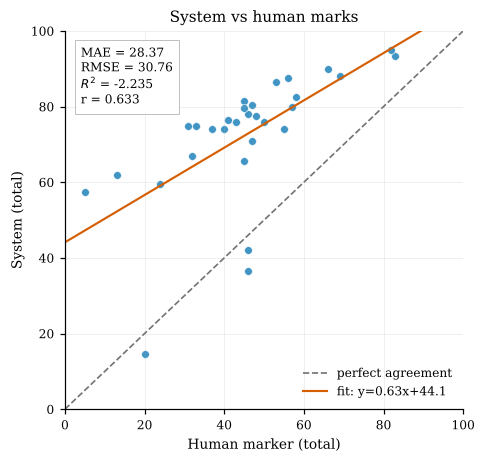

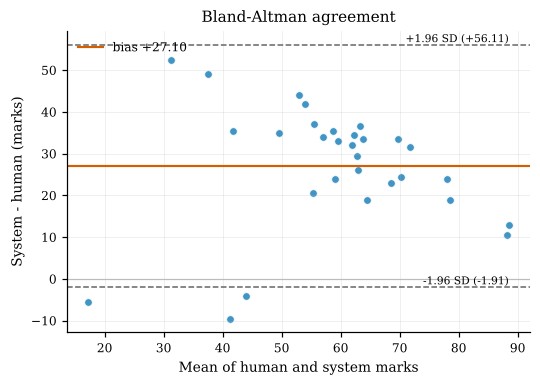

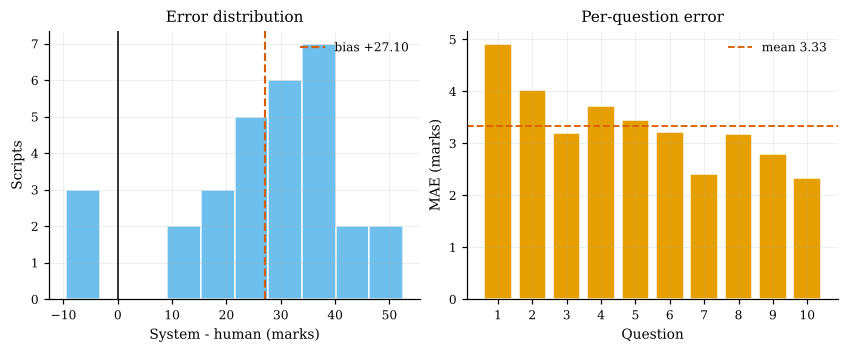

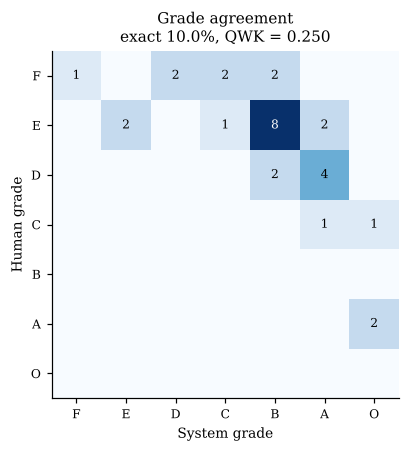


Report in the paper: n = 30, MAE 28.37, RMSE 30.76, R2 -2.235, bias +27.10 (LoA -1.91 to 56.11), QWK 0.250, 0% within 2 marks.


In [45]:
# ===================== R1 · examiner 1's marks (read at the start) applied to the Tier-2 figures =====================
# The scripts carry codes (S01..). Examiner 1's file from the start-up upload is translated to the codes here and the
# Tier-2 figures above are regenerated. If no examiner-1 file was uploaded, the reference copy of the course examiner's
# marks (matched by file hash) is used.
def _coded_human_csv():
    p = globals().get("EXAMINER1_PATH")
    if p and os.path.exists(p):
        d = pd.read_csv(p)
        d["file"] = d["file"].astype(str).str.strip().map(to_code)
        if d["file"].isin(results["file"]).any():
            return d, "examiner 1's file from the start-up upload"
        print("  ! examiner 1's file names do not match the uploaded PDFs - see the input check in section 3.")
    rows = []
    for code, h in FILE_HASH.items():
        ref = REFERENCE_DATA.get(h)
        if ref and code in set(results["file"]):
            rows.append([code] + list(ref["examiner1"]) + [sum(ref["examiner1"])])
    if rows:
        cols = ["file"] + [f"human_{q}" for q in QCOLS] + ["human_total"]
        if len(rows[0]) == len(cols):
            return pd.DataFrame(rows, columns=cols), "reference copy (matched by file hash)"
    return None, None


_d, _src = _coded_human_csv()
if _d is not None:
    _p = f"{WORK}/human_marks_examiner1_coded.csv"
    _d.to_csv(_p, index=False)
    print("Examiner 1:", _src)
    load_human_marks(_p)
else:
    print("No examiner-1 marks - Tier 2 skipped (section 12 uses the reference copy if the scripts are recognised).")

In [46]:
OUT = os.path.dirname(RESULTS_CSV) or "."
tables = {
    "table1_cohort_summary": summary_stats,
    "table2_item_analysis": items,
    "table3_toppers": top_list[["rank", "student", "total", "max", "percent", "grade"]],
    "table4_failures": fail_list[["student", "total", "max", "percent", "grade"]],
    "table5_all_students": results.sort_values("rank")[
        ["rank", "student"] + QCOLS + ["total", "max", "percent", "grade"]],
}
if tier2_stats is not None:
    tables["table6_agreement"] = pd.DataFrame([tier2_stats]).round(3)

for name, df in tables.items():
    df.to_csv(f"{OUT}/{name}.csv", index=False)

# LaTeX for direct paste into a manuscript
with open(f"{OUT}/tables.tex", "w") as fh:
    for name, df in tables.items():
        try:
            fh.write(f"% ---- {name} ----\n")
            fh.write(df.to_latex(index=False, escape=True,
                                 caption=name.split("_", 1)[1].replace("_", " ").title(),
                                 label=f"tab:{name.split('_')[0]}"))
            fh.write("\n\n")
        except Exception as e:
            fh.write(f"% {name} failed: {e}\n\n")

bundle = f"{OUT}/results_bundle.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for p in glob.glob(f"{FIGDIR}/*"):
        z.write(p, f"figures/{os.path.basename(p)}")
    for name in tables:
        z.write(f"{OUT}/{name}.csv", f"tables/{name}.csv")
    z.write(f"{OUT}/tables.tex", "tables/tables.tex")

print(f"{len(tables)} tables (CSV + LaTeX) and {len(glob.glob(f'{FIGDIR}/*'))} figure files")
print("Bundle:", bundle)
if DEMO:
    print("\n!! Built from SIMULATED data - regenerate after a real batch before using anywhere.")

# R1: downloaded with all other results at the end (section 12.17).

6 tables (CSV + LaTeX) and 26 figure files
Bundle: ./grading/results_bundle.zip


---
# 12 · Reviewer-response evaluation (Revision R1)

This section produces every number and figure the revision needs, **from the same cached OCR** the batch
in section 10 used, so no script is read twice. Each subsection names the reviewer comment it answers.
**Run it top to bottom after section 11.**

| § | What it measures | Reviewer comment |
|---|---|---|
| 12.1 | Reference data, examiner marks, environment record | R2 (independence), R3 (privacy claim) |
| 12.2 | How the colour image is processed, step by step; accounting of every red mark | R1 ("sample screens"); R2 ("14 vs 13") |
| 12.3 | **Localisation accuracy on all five scripts** (line/word P, R, F1; question identity; boundaries) + ablation: text-only vs red, greedy vs Hungarian, drop vs merge | R1, R2, R3 |
| 12.4 | Localisation stress tests: out of order, skipped/optional, continuation and sub-part marks, answer continued later, forgotten red pen, examiner red marks | R2 (examiner red ink); R3 (continued answers, repeated numbers, subparts, optional questions) |
| 12.5 | OCR error rate against manual transcription (CER/WER), vs Tesseract confidence | R3 ("confidence is not an error rate"); R1 ("comparison with poor OCR") |
| 12.6 | Signals for every answer **and for every control**, computed once | – |
| 12.7 | Reproduction check; lexical saturation; chance anchor hits | R2 (lexical = 1.000; r ≥ 0.38 > floor; short terms) |
| 12.8 | **Held-out calibration** (leave-one-script-out), content-blind baselines, threshold sensitivity, frozen protocol | R2 (thresholds not fixed in advance); R3 (independent set) |
| 12.9 | **Negative and adversarial controls**: wrong question, shuffled, random text, keyword-stuffed wrong answers, paraphrased correct answers, graded OCR noise | R2 (negative controls); R3 (keywords in wrong answers; different wording) |
| 12.10 | **Three evaluation levels: Easy / Moderate / Tough** | Author request |
| 12.11 | Answer-level agreement (n = 50) with cluster-bootstrap CIs; mark granularity | R2 (unit of analysis; granularity) |
| 12.12 | Script-level agreement with CIs; κ without the failing script; direction of every grade change; regression intercept; proportional bias | R2; R3 (LoA, 60 % exact) |
| 12.13 | Scoring ablation: single signals vs ensemble | R1 |
| 12.14 | Modern HTR comparator (TrOCR, local) and optional vision-LLM comparator | R1 |
| 12.15 | Review triage and workload, fairness, examiner-vs-examiner consistency | R3; R2 (two examiners) |
| 12.16 | Item-analysis sensitivity | R2 |
| 12.17 | Reviewer-response map, exports, Word report | – |

> **What this section can and cannot establish.** All of it uses five scripts, one paper and one examiner.
> It does not substitute for the 30–50 script study the reviewers request; it makes the current evidence
> honest (held-out estimates, confidence intervals, controls) and leaves the notebook ready for the larger
> cohort: point `SCRIPTS_DIR` at more scripts and set `EVAL["SPLIT"]` (12.1) to a fixed calibration/test split.

## 12.1 · Setup: reference data, examiner marks, environment
*R2: independence of the evidence. R3: the privacy statement must match where the code ran.*

In [47]:
# ============================== 12.1 · SETUP AND REFERENCE DATA ==============================
EVAL = {
    "SEED": 2027,
    "BOOTSTRAP_B": 2000,               # cluster-bootstrap resamples (scripts are the clusters)
    "SPLIT": "loso",                   # "loso" (leave-one-script-out) or
                                       # {"calibration": ["S01.pdf", ...], "test": ["S04.pdf", ...]}
    "RAMP_LO_GRID": [round(x, 2) for x in np.arange(0.20, 0.461, 0.02)],
    "RAMP_HI_GRID": [round(x, 2) for x in np.arange(0.46, 0.861, 0.02)],
    "STRESS_VARIANTS": 6,              # synthetic variants per scenario per script (12.4)
    "STRESS_TIME_BUDGET_S": 240,       # 12.4 stops adding variant rounds after this many seconds
    "NOISE_CER": [0.0, 0.10, 0.20, 0.30, 0.45],   # synthetic OCR noise levels (12.8)
    "RUN_HTR": False,                  # TrOCR comparator (12.14): not needed for the TPC conditions; True adds
                                       # ~10-15 min on CPU (results cached on Drive)
    "HTR_MODEL": None,                 # None = trocr-base-handwritten on GPU, trocr-small on CPU
    "RUN_VLM": False,                  # vision-LLM comparator: sends page images to an external API
    "TRANSCRIPT_PAGES_PER_SCRIPT": 2,  # pages exported for manual transcription (12.5)
    "EXAMINER_MIN_PER_SCRIPT": None,   # measured manual marking time per script (minutes), if known
    "REVIEW_MIN_PER_ANSWER": None,     # measured time to check one flagged answer (minutes), if known
    "HUMAN2_CSV": None,                # optional path overriding examiner 2's file from the start-up upload
    "REFERENCE_MARKS": "examiner1",    # what the system is calibrated and judged against when two examiners
                                       # exist: "examiner1" (the course examiner) | "mean" (average of both)
}
R1DIR = f"{WORK}/r1"
R1FIG = f"{FIGDIR}/r1" if "FIGDIR" in globals() else f"{WORK}/figures/r1"
for _d in (R1DIR, R1FIG):
    os.makedirs(_d, exist_ok=True)
rng0 = np.random.default_rng(EVAL["SEED"])

# ---------------------------------------------------------------------------------------------
# Scripts, cached reads, questions
# ---------------------------------------------------------------------------------------------
SCRIPTS = sorted(glob.glob(f"{SCRIPTS_DIR}/*.pdf"))
REC = {os.path.basename(p): read_script(p, CONFIG) for p in SCRIPTS}     # cached from section 10
CODES = list(REC)
QNUMS = [q.num for q in questions]
QBYNUM = {q.num: q for q in questions}
MAXQ = {q.num: q.max_marks for q in questions}
annotate_keywords(questions, verbose=False)
def _layout_score(rec, ref):
    """Share of reference red marks found at the same page and height in this script (an edited PDF -
    e.g. with the USN blacked out - keeps its red question numbers where they were)."""
    det = [(p["page"], m["y"]) for p in rec["pages"] for m in p["marks_v1"]]
    gt = [(p, y) for p, y, _ in _parse_marks(ref["marks"], rec["dpi"])]
    if not det or not gt:
        return 0.0
    hit = sum(1 for p, y in gt if any(p == pp and abs(y - yy) <= 8 for pp, yy in det))
    return hit / max(len(gt), len(det))


REF, REF_HOW = {}, {}
for c in CODES:
    r = REFERENCE_DATA.get(REC[c]["sha"])
    REF[c], REF_HOW[c] = r, ("file hash" if r else None)
_free = [h for h in REFERENCE_DATA if not any(REFERENCE_DATA[h] is REF[c] for c in CODES)]
_cand = sorted(((_layout_score(REC[c], REFERENCE_DATA[h]), c, h) for c in CODES if REF[c] is None
                for h in _free if not REC[c].get("text_layer")), reverse=True)
for sc, c, h in _cand:                                   # one-to-one, best layout match first
    if sc >= 0.8 and REF[c] is None and h in _free:
        REF[c], REF_HOW[c] = REFERENCE_DATA[h], f"red-mark layout ({100 * sc:.0f}% of marks coincide)"
        _free.remove(h)
print(f"{len(CODES)} scripts; reference data (ground truth, examiner copy, published marks) found for "
      f"{sum(r is not None for r in REF.values())}:")
for c in CODES:
    print(f"   {c}: {REF_HOW[c] or 'NOT FOUND - localisation accuracy (12.3) cannot be measured for this script'}")


# ---------------------------------------------------------------------------------------------
# Examiner marks: the files read at the start (section 3), else (examiner 1 only) the
# reference copy above. Original file names are translated to codes automatically.
# ---------------------------------------------------------------------------------------------
def _translate_human(df, label=""):
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    if "file" not in df.columns:
        return None
    df["file"] = df["file"].astype(str).str.strip().map(to_code)
    bad = sorted(set(df.loc[~df["file"].isin(CODES), "file"]))
    if bad and label:
        print(f"   ! {label}: {len(bad)} row(s) name a file that was not uploaded: {bad[:5]}. The 'file' column "
              f"must use the names of the uploaded PDFs ({', '.join(sorted(ANON_MAP)[:5])}).")
    df = df[df["file"].isin(CODES)]
    qc = [f"human_Q{n}" for n in QNUMS]
    if not len(df) or not all(c in df.columns for c in qc):
        return None
    for c in qc:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    if df[qc].isna().all().all():
        return None
    df["human_total"] = df[qc].sum(axis=1)
    return df.set_index("file")[qc + ["human_total"]]


def load_examiner(which=1):
    """Examiner marks from the start-up upload (section 3); examiner 1 falls back to the reference copy."""
    if which == 1 and "human_df" in globals() and isinstance(human_df, pd.DataFrame):
        t = _translate_human(human_df)
        if t is not None and len(t) == len(CODES):
            return t, "start-up upload (as applied to the Tier-2 figures)"
    p = globals().get("EXAMINER1_PATH" if which == 1 else "EXAMINER2_PATH")
    if which == 2 and EVAL["HUMAN2_CSV"]:
        p = EVAL["HUMAN2_CSV"]
    if p and os.path.exists(p):
        t = _translate_human(pd.read_csv(p), label=os.path.basename(p))
        if t is not None and len(t):
            return t, "start-up upload"
    if which == 1:
        rows = {c: REF[c]["examiner1"] for c in CODES if REF[c] and len(REF[c]["examiner1"]) == len(QNUMS)}
        if rows:
            t = pd.DataFrame.from_dict(rows, orient="index", columns=[f"human_Q{n}" for n in QNUMS])
            t["human_total"] = t.sum(axis=1)
            return t, "reference copy embedded in 12.1 (course examiner's marks)"
    return None, "not available"


H1, H1_SRC = load_examiner(1)
H2, H2_SRC = load_examiner(2)
print("examiner 1:", H1_SRC, "" if H1 is None else f"({len(H1)} scripts)")
print("examiner 2:", H2_SRC + f" ({len(H2)} scripts)" if H2 is not None else
      "not supplied (include examiner 2's marks in the start-up upload, section 3)")
EXAMINER1 = H1.copy() if H1 is not None else None          # kept for examiner-vs-examiner comparisons
if H2 is not None and H1 is not None:
    _c = [c for c in H1.index if c in H2.index]
    _qc = [f"human_Q{n}" for n in QNUMS]
    _diff = (H1.loc[_c, _qc] - H2.loc[_c, _qc]).abs()
    print(f"examiner 2 check: {len(_c)} scripts matched; marks within 0-{max(MAXQ.values()):g}: "
          f"{bool(((H2[_qc] >= 0) & (H2[_qc] <= max(MAXQ.values()))).all().all())}; "
          f"answers marked differently from examiner 1: {int((_diff > 0).sum().sum())}/{_diff.size}")
    STUDY_DECLARATION["number_of_independent_examiners"] = 2
    if STUDY_DECLARATION.get("examiner_2_marked_blind") is None:
        print("   declaration: state STUDY_DECLARATION['examiner_2_marked_blind'] in section 3b (TPC condition 4).")
    if (_diff == 0).all().all():
        print("!! WARNING: examiner 2's marks are IDENTICAL to examiner 1's. That is not an independent second "
              "marking; do not report it as one.")
if H2 is not None and H1 is not None and EVAL["REFERENCE_MARKS"] == "mean":
    common = [c for c in H1.index if c in H2.index]
    H1 = ((H1.loc[common] + H2.loc[common]) / 2)
    H1_SRC = f"mean of examiner 1 and examiner 2 ({len(common)} scripts)"
    print("reference marks for calibration and agreement:", H1_SRC)
else:
    print("reference marks for calibration and agreement: examiner 1")
PAPER_MARKS = {c: REF[c]["paper"] for c in CODES if REF[c] and REF[c].get("paper")}  # LOCAL RUN: new scripts have no published marks


def gt_line_labels(code, version="v2"):
    """Ground-truth question of every OCR line (None = header / before the first answer)."""
    ref, rec = REF.get(code), REC[code]
    if not ref:
        return None
    starts = _parse_starts(ref["starts"], rec["dpi"])
    L = rec["lines"]
    pos = []
    for q, p, y in starts:
        cand = [i for i, l in enumerate(L) if l["page"] == p and l["y"] >= y - 48]
        if not cand:
            cand = [i for i, l in enumerate(L) if l["page"] > p][:1]
        if cand:
            pos.append((cand[0], q))
    pos.sort()
    lab = [None] * len(L)
    for k, (i, q) in enumerate(pos):
        e = pos[k + 1][0] if k + 1 < len(pos) else len(L)
        for j in range(i, e):
            lab[j] = q
    return lab


GT_LINES = {c: gt_line_labels(c) for c in CODES}
GT_ATTEMPTED = {c: (sorted(set(x for x in GT_LINES[c] if x is not None)) if GT_LINES[c] else None)
                for c in CODES}

# ---------------------------------------------------------------------------------------------
# Small shared helpers: tables and figures are collected for the exports in 12.17
# ---------------------------------------------------------------------------------------------
R1_TABLES, R1_FIGS, R1_FACTS = {}, [], {}


def r1_table(df, name, caption, show=True, index=False):
    R1_TABLES[name] = (df.copy(), caption, index)
    df.to_csv(f"{R1DIR}/{name}.csv", index=index)
    if show:
        print(f"\n[{name}] {caption}")
        display(df)
    return df


def r1_fig(fig, name, caption):
    paths = []
    for ext in ("png", "pdf"):
        p = f"{R1FIG}/{name}.{ext}"
        fig.savefig(p, dpi=300, bbox_inches="tight")
        paths.append(p)
    R1_FIGS.append((paths[0], caption))
    print(f"  saved {name}")
    return fig


def mae(a, b):
    return float(np.mean(np.abs(np.asarray(a, float) - np.asarray(b, float))))


# ---------------------------------------------------------------------------------------------
# Environment record (Reviewer 3: privacy claim must match where the code actually ran)
# ---------------------------------------------------------------------------------------------
def _ver(mod):
    try:
        return __import__(mod).__version__
    except Exception:
        return "n/a"


try:
    _tv = str(pytesseract.get_tesseract_version())
except Exception:
    _tv = "n/a"
try:
    import torch as _torch
    _gpu = _torch.cuda.is_available()
except Exception:
    _torch, _gpu = None, False
import platform
ENV = {"run_utc": pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d %H:%M"),
       "where": "Google Colab - a cloud VM operated by Google; scripts were uploaded to it"
                if IN_COLAB else f"local machine ({platform.node() or 'unnamed'})",
       "python": platform.python_version(), "tesseract": _tv, "opencv": cv2.__version__,
       "rapidfuzz": _ver("rapidfuzz"), "scikit-learn": _ver("sklearn"),
       "sentence-transformers": _ver("sentence_transformers"),
       "semantic backend": sim.backend, "gpu": _gpu,
       "METHOD_VERSION (main run)": METHOD_VERSION, "EVAL_LEVEL (main run)": EVAL_LEVEL,
       "scheme sha256": file_sha(SCHEME_PATH), "external services used": "none"
       if not EVAL["RUN_VLM"] and CONFIG.get("OCR_BACKEND") == "tesseract" else "vision-LLM API"}
if globals().get("RUN_LOCATION"):                    # LOCAL RUN: state the real execution environment
    ENV["where"] = RUN_LOCATION
r1_table(pd.DataFrame([ENV]).T.rename(columns={0: "value"}), "t00_environment",
         "Execution environment. The privacy statement in the paper must describe this environment.",
         index=True)
if "sentence-transformers" not in sim.backend:
    print("NOTE: the semantic signal is using the TF-IDF fallback, not MiniLM. Numbers will differ from "
          "the paper. Re-run with internet access so all-MiniLM-L6-v2 can load.")

30 scripts; reference data (ground truth, examiner copy, published marks) found for 30:
   S01.pdf: file hash
   S02.pdf: file hash
   S03.pdf: file hash
   S04.pdf: file hash
   S05.pdf: file hash
   S06.pdf: file hash
   S07.pdf: file hash
   S08.pdf: file hash
   S09.pdf: file hash
   S10.pdf: file hash
   S11.pdf: file hash
   S12.pdf: file hash
   S13.pdf: file hash
   S14.pdf: file hash
   S15.pdf: file hash
   S16.pdf: file hash
   S17.pdf: file hash
   S18.pdf: file hash
   S19.pdf: file hash
   S20.pdf: file hash
   S21.pdf: file hash
   S22.pdf: file hash
   S23.pdf: file hash
   S24.pdf: file hash
   S25.pdf: file hash
   S26.pdf: file hash
   S27.pdf: file hash
   S28.pdf: file hash
   S29.pdf: file hash
   S30.pdf: file hash
examiner 1: start-up upload (as applied to the Tier-2 figures) (30 scripts)
examiner 2: start-up upload (30 scripts)
examiner 2 check: 30 scripts matched; marks within 0-10: True; answers marked differently from examiner 1: 179/300
   declaration: stat


[t00_environment] Execution environment. The privacy statement in the paper must describe this environment.


,value
run_utc,2026-11-23 17:46
where,"Anthropic-hosted cloud sandbox (Claude agent workspace, Linux VM); the scrip..."
python,3.13.18
tesseract,5.3.4
opencv,5.0.0
rapidfuzz,3.14.6
scikit-learn,1.9.1
sentence-transformers,6.3.0
semantic backend,sentence-transformers/all-MiniLM-L6-v2
gpu,False


## 12.2 · How the colour image is processed; every red mark accounted for
*R1: "Sample screens of how the image is processed across red". R2: "Fig. 4 lists per-page red-mark counts that sum to 14, but the log reports 13. Both exceed the ten questions."*


[t01_red_mark_accounting] Every red mark accounted for. The 4.6 log printed 'anchor lines', which is the per-page sum minus marks that projected onto an already-anchored line; the surplus over the number of questions came from page-edge streaks and from digits or circles split into two components, not from continuation pages. R1 rejects the streaks and re-joins the pieces.


,script,4.6 marks,4.6 anchor lines,lost to same-line projection,edge / gutter streaks,split digits / circles,R1 marks,R1 anchor lines,red ink outside margin (examiner),GT red numbers,GT answers with no red mark,4.6 precision,R1 true marks,R1 precision,R1 recall
0,S01.pdf,11,11,0,0,1,10,10,5,10,1,0.909,10,1.000,1.000
1,S02.pdf,10,10,0,0,0,10,10,0,10,0,1.000,10,1.000,1.000
2,S03.pdf,10,10,0,0,0,10,10,6,10,0,1.000,10,1.000,1.000
3,S04.pdf,11,10,1,0,1,10,10,11,10,0,0.909,10,1.000,1.000
4,S05.pdf,10,10,0,0,0,10,10,1,10,0,1.000,10,1.000,1.000
5,S06.pdf,10,10,0,0,0,10,10,2,10,0,1.000,10,1.000,1.000
6,S07.pdf,12,10,2,1,1,10,10,3,10,0,0.833,9,0.900,0.900
7,S08.pdf,13,13,0,0,0,13,13,5,10,0,0.769,10,0.769,1.000
8,S09.pdf,11,11,0,0,1,10,10,8,10,0,0.909,10,1.000,1.000
9,S10.pdf,14,12,2,0,3,11,10,1,10,0,0.714,10,0.909,1.000


  saved r1_fig1_red_processing_too_thin_edge


  saved r1_fig2_red_processing_merged_fragment


  saved r1_fig3_red_processing_outside_margin


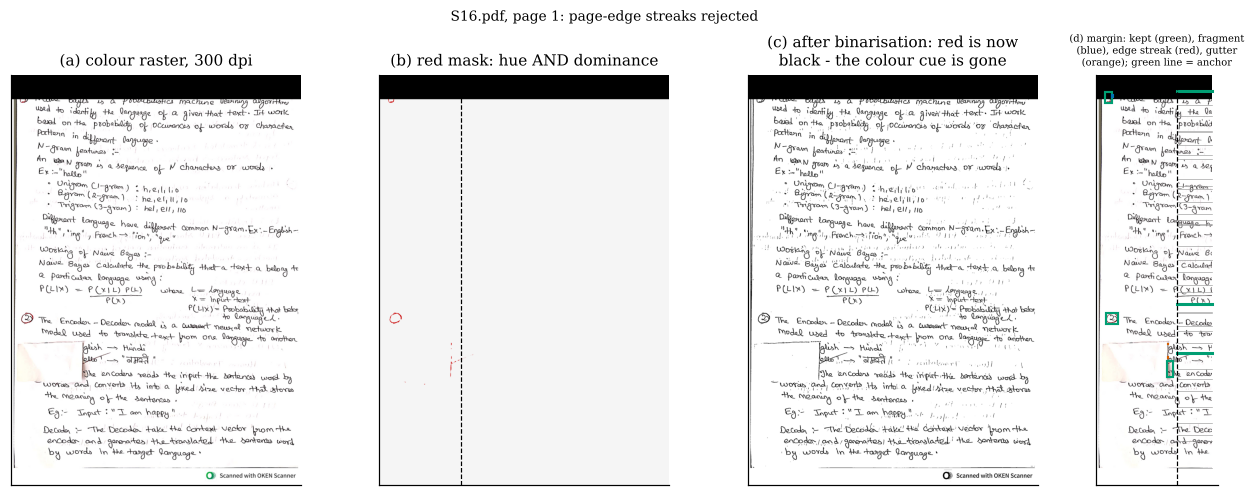

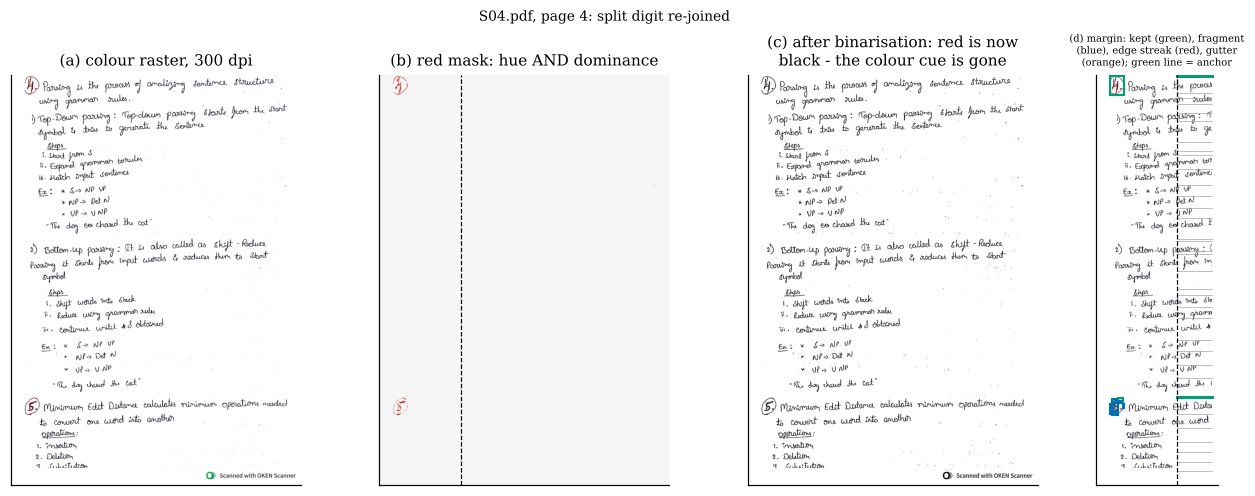

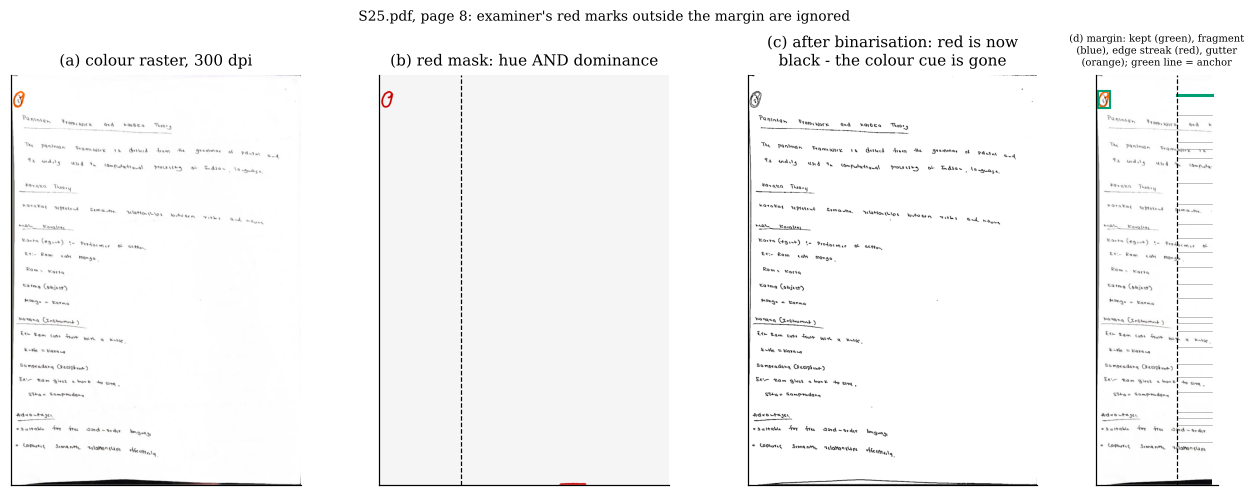

Ground-truth check sheets written to /content/grading/r1/gt_check_*.png - please confirm every label.


In [48]:
# ============================== 12.2 · RED-INK PROCESSING, MARK ACCOUNTING ==============================
from matplotlib.patches import Rectangle as _Rect


def page_bgr(code, page, dpi=None):
    pil = convert_from_path(f"{SCRIPTS_DIR}/{code}", dpi=dpi or REC[code]["dpi"], first_page=page, last_page=page)[0]
    return cv2.cvtColor(np.array(pil.convert("RGB")), cv2.COLOR_RGB2BGR)


def redact_page(bgr, code, page):
    """Black out the page-1 header (name, USN, date): everything above the first answer mark."""
    out = bgr.copy()
    if page == 1:
        s = out.shape[0] / REC[code]["pages"][0]["H"]            # works at any rendering resolution
        ms = REC[code]["pages"][0]["marks_v2"] or REC[code]["pages"][0]["marks_v1"]
        ycut = int(max(0, ((ms[0]["y"] if ms else 300) - 30) * s))
        out[:max(ycut, int(0.06 * out.shape[0]))] = 0
    return out


def _label_v1_marks(code):
    """Ground-truth label of each mark the 4.6 detector accepted (number / f / e)."""
    ref = REF.get(code)
    if not ref:
        return None
    gt = _parse_marks(ref["marks"], REC[code]["dpi"])
    lab = []
    for p in REC[code]["pages"]:
        for m in p["marks_v1"]:
            hit = [l for (pg, y, l) in gt if pg == p["page"] and abs(y - m["y"]) <= 6]
            lab.append(hit[0] if hit else "?")
    return lab


rows = []
for c in CODES:
    s = mark_summary(REC[c])
    v1 = s["v1 marks (per-page sum)"]
    streaks = sum(1 for p in REC[c]["pages"] for m in p["marks_v1"]
                  if any(abs(m["y"] - x["y"]) <= 2 and abs(m["x"] - x["x"]) <= 2 and
                         x["status"] in ("too_thin_edge", "dark_background") for x in p["component_log"]))
    row = {"script": c, "4.6 marks": v1, "4.6 anchor lines": s["v1 distinct anchor lines"],
           "lost to same-line projection": s["v1 marks lost to same-line projection"],
           "edge / gutter streaks": streaks,
           "split digits / circles": v1 - s["R1 marks"] - streaks,
           "R1 marks": s["R1 marks"], "R1 anchor lines": s["R1 distinct anchor lines"],
           "red ink outside margin (examiner)": s["red components outside margin (examiner ink etc.)"]}
    lab = _label_v1_marks(c)
    if lab is not None:
        gt_numbers = sum(1 for (_, _, l) in _parse_marks(REF[c]["marks"], REC[c]["dpi"]) if l.isdigit())
        n_starts = len(_parse_starts(REF[c]["starts"], REC[c]["dpi"]))
        gtn = [(pg, y) for (pg, y, l) in _parse_marks(REF[c]["marks"], REC[c]["dpi"]) if l.isdigit()]
        tp = sum(1 for p in REC[c]["pages"] for m in p["marks_v2"]
                 if any(pg == p["page"] and m["y"] - 10 <= y <= m["y"] + m["h"] + 10 for pg, y in gtn))
        row.update({"GT red numbers": gt_numbers, "GT answers with no red mark": n_starts - gt_numbers,
                    "4.6 precision": round(sum(l.isdigit() for l in lab) / max(1, len(lab)), 3),
                    "R1 true marks": tp,
                    "R1 precision": round(tp / max(1, s["R1 marks"]), 3),
                    "R1 recall": round(tp / max(1, gt_numbers), 3)})
    rows.append(row)
MARK_TABLE = pd.DataFrame(rows)
tot = MARK_TABLE.select_dtypes("number").sum()
MARK_TABLE.loc[len(MARK_TABLE)] = {"script": "all", **{k: (v if "precision" not in k and "recall" not in k
                                                         else np.nan) for k, v in tot.items()}}
MARK_TABLE = MARK_TABLE.astype({k: "Int64" for k in MARK_TABLE.columns
                                if k != "script" and "precision" not in k and "recall" not in k})
if "GT red numbers" in MARK_TABLE:
    a = MARK_TABLE.iloc[-1]
    MARK_TABLE.loc[MARK_TABLE.index[-1], "4.6 precision"] = round(a["GT red numbers"] / a["4.6 marks"], 3)
    MARK_TABLE.loc[MARK_TABLE.index[-1], "R1 precision"] = round(a["R1 true marks"] / a["R1 marks"], 3)
    MARK_TABLE.loc[MARK_TABLE.index[-1], "R1 recall"] = round(a["R1 true marks"] / a["GT red numbers"], 3)
r1_table(MARK_TABLE, "t01_red_mark_accounting",
         "Every red mark accounted for. The 4.6 log printed 'anchor lines', which is the per-page sum minus "
         "marks that projected onto an already-anchored line; the surplus over the number of questions came "
         "from page-edge streaks and from digits or circles split into two components, not from continuation "
         "pages. R1 rejects the streaks and re-joins the pieces.")
R1_FACTS["red marks"] = MARK_TABLE.iloc[-1].to_dict()


def fig_red_processing(code, page, title):
    """Colour page -> red mask -> binarised page -> margin detail with every decision drawn."""
    bgr = page_bgr(code, page)
    H, W = bgr.shape[:2]
    shown = redact_page(bgr, code, page)
    p = REC[code]["pages"][page - 1]
    mask = red_mask(bgr)
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    binar = cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 15)
    binar = redact_page(cv2.cvtColor(binar, cv2.COLOR_GRAY2BGR), code, page)
    fig, ax = plt.subplots(1, 4, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1, 1, 1, 0.42]})
    ax[0].imshow(cv2.cvtColor(shown, cv2.COLOR_BGR2RGB)); ax[0].set_title("(a) colour raster, 300 dpi")
    vis = np.full((H, W, 3), 245, np.uint8); vis[mask > 0] = (200, 0, 0)
    vis = redact_page(vis, code, page)
    ax[1].imshow(vis); ax[1].axvline(W * RED_MARGIN_FRAC, color="k", ls="--", lw=.8)
    ax[1].set_title("(b) red mask: hue AND dominance")
    ax[2].imshow(cv2.cvtColor(binar, cv2.COLOR_BGR2RGB)); ax[2].set_title("(c) after binarisation: red is now\nblack - the colour cue is gone")
    xs = int(W * 0.40)
    ax[3].imshow(cv2.cvtColor(shown[:, :xs], cv2.COLOR_BGR2RGB))
    colours = {"accepted": "#009E73", "merged_fragment": "#0072B2", "too_thin_edge": "#D55E00",
               "dark_background": "#E69F00", "size": "#999999", "stroke_shape": "#999999"}
    for cmp in p["component_log"]:
        if cmp["status"] == "outside_margin" or cmp["x"] > xs:
            continue
        ax[3].add_patch(_Rect((cmp["x"], cmp["y"]), cmp["w"], cmp["h"], fill=False, lw=1.4,
                              ec=colours.get(cmp["status"], "k")))
    lines = [l for l in REC[code]["lines"] if l["page"] == page]
    for l in lines:
        ax[3].plot([W * RED_MARGIN_FRAC, xs], [l["y"], l["y"]], color="0.6", lw=.4)
    base = next(i for i, l in enumerate(REC[code]["lines"]) if l["page"] == page) if lines else 0
    for a in REC[code]["anchors_v2"]:
        if base <= a < base + len(lines):
            ax[3].plot([W * RED_MARGIN_FRAC, xs], [lines[a - base]["y"]] * 2, color="#009E73", lw=2)
    ax[3].axvline(W * RED_MARGIN_FRAC, color="k", ls="--", lw=.8)
    ax[3].set_title("(d) margin: kept (green), fragment\n(blue), edge streak (red), gutter\n(orange); green line = anchor",
                    fontsize=6.5)
    for a_ in ax:
        a_.set_xticks([]); a_.set_yticks([]); a_.grid(False)
    fig.suptitle(f"{code}, page {page}: {title}", fontsize=9)
    return fig


def _pick_pages():
    best = {}
    for c in CODES:
        for p in REC[c]["pages"]:
            st = pd.Series([x["status"] for x in p["component_log"]]).value_counts()
            for k in ("too_thin_edge", "merged_fragment", "outside_margin"):
                v = int(st.get(k, 0))
                if k == "outside_margin":
                    v = p["red_px"] if v else 0
                if v and v > best.get(k, (0,))[0]:
                    best[k] = (v, c, p["page"])
    return best


_picks = _pick_pages()
_titles = {"too_thin_edge": "page-edge streaks rejected", "merged_fragment": "split digit re-joined",
           "outside_margin": "examiner's red marks outside the margin are ignored"}
for k, i in zip(("too_thin_edge", "merged_fragment", "outside_margin"), (1, 2, 3)):
    if k in _picks:
        _, c, pg = _picks[k]
        r1_fig(fig_red_processing(c, pg, _titles[k]), f"r1_fig{i}_red_processing_{k}",
               f"Processing of the colour image ({c}, page {pg}): {_titles[k]}. Page-1 header blacked out.")
plt.show()


def fig_mark_sheet(code, max_tiles=16):
    """Contact sheet of every red mark with its ground-truth label - for the authors to confirm."""
    rec = REC[code]
    lab = _label_v1_marks(code) or ["?"] * 999
    tiles, k = [], 0
    for p in rec["pages"]:
        if not p["marks_v1"]:
            continue
        bgr = redact_page(page_bgr(code, p["page"], dpi=150), code, p["page"])
        s = 150 / rec["dpi"]
        for m in p["marks_v1"]:
            x0, y0 = int(max(0, m["x"] - 40) * s), int(max(0, m["y"] - 40) * s)
            crop = bgr[y0:int((m["y"] + m["h"] + 80) * s), x0:int((m["x"] + m["w"] + 420) * s)]
            tiles.append((crop, f"p{p['page']} y{m['y']}: {lab[k] if k < len(lab) else '?'}"))
            k += 1
    tiles = tiles[:max_tiles]
    n = len(tiles); cols = 4; rws = (n + cols - 1) // cols
    fig, ax = plt.subplots(rws, cols, figsize=(10, 1.5 * rws))
    ax = np.atleast_1d(ax).ravel()
    for a_ in ax:
        a_.axis("off")
    for a_, (cr, t) in zip(ax, tiles):
        a_.imshow(cv2.cvtColor(cr, cv2.COLOR_BGR2RGB)); a_.set_title(t, fontsize=7)
    fig.suptitle(f"{code}: every mark the 4.6 detector accepted, with its ground-truth label "
                 "(digit = question, f = fragment, e = edge streak)", fontsize=8)
    return fig


for c in CODES:
    if REF.get(c):
        f_ = fig_mark_sheet(c)
        f_.savefig(f"{R1DIR}/gt_check_{c[:-4]}.png", dpi=150, bbox_inches="tight")
        plt.close(f_)
print(f"Ground-truth check sheets written to {R1DIR}/gt_check_*.png - please confirm every label.")

## 12.3 · Localisation accuracy on all five scripts, and the localisation ablation
*R1: "Localisation is shown for a single script with no corpus-level precision or recall"; "text-only versus red anchoring, greedy versus Hungarian". R2: "Please report localisation accuracy (correct question and correct boundary) for all five scripts." R3: "Evaluate answer localisation separately from grading."*

In [54]:
# ============================== 12.3 · LOCALISATION ACCURACY + ABLATION ==============================
LOC_METHODS = {
    "L0 text-only DP aligner (no red ink)":                 {"kind": "text"},
    "L1 submitted: 4.6 marks, split, Hungarian, drop":      {"kind": "v1"},
    "L2 R1 marks, split, Hungarian, drop":                  {"kind": "red", "marks": "v2", "assigner": "hungarian", "split": "always", "policy": "drop"},
    "L3 R1 marks, split, Hungarian, merge":                 {"kind": "red", "marks": "v2", "assigner": "hungarian", "split": "always", "policy": "merge"},
    "L4 R1 marks, split-unclaimed, Hungarian, merge (R1)":  {"kind": "red", "marks": "v2", "assigner": "hungarian", "split": "unclaimed", "policy": "merge"},
    "L5 4.6 marks, R1 assignment":                          {"kind": "red", "marks": "v1", "assigner": "hungarian", "split": "unclaimed", "policy": "merge"},
    "L6 R1 marks, split-unclaimed, greedy, merge":          {"kind": "red", "marks": "v2", "assigner": "greedy", "split": "unclaimed", "policy": "merge"},
    "L7 R1 marks, sequential (k-th span = Qk)":             {"kind": "red", "marks": "v2", "assigner": "sequential", "split": "unclaimed", "policy": "merge"},
}
LOC_SUBMITTED = "L1 submitted: 4.6 marks, split, Hungarian, drop"
LOC_REVISED = "L4 R1 marks, split-unclaimed, Hungarian, merge (R1)"


def run_localisation(code, m, lines=None, anchors=None, min_sim=None):
    rec = REC[code]
    if m["kind"] == "text":
        L = lines or script_lines(rec, "v2")
        return textonly_with_ranges(L, questions)
    if m["kind"] == "v1":
        L = lines or script_lines(rec, "v1")
        A = rec["anchors_v1"] if anchors is None else anchors
        res = segment_by_red_redanchor_v1(L, A, questions)
        if res is None:
            return textonly_with_ranges(L, questions)
        for q in questions:
            v = res[q.num]
            v["ranges"] = [(v["start_line"], v["start_line"] + v["spans"])] if v["start_line"] is not None else []
        return res
    L = lines or script_lines(rec, m["marks"])
    A = rec[f"anchors_{m['marks']}"] if anchors is None else anchors
    res = segment_by_red_v2(L, A, questions, assigner=m["assigner"], policy=m["policy"],
                            split=m["split"], min_sim=min_sim)
    return res if res is not None else textonly_with_ranges(L, questions)


def pred_line_labels(res, n):
    lab = [None] * n
    for qn, v in res.items():
        for a, b in v.get("ranges", []):
            for j in range(a, min(b, n)):
                lab[j] = qn
    return lab


def loc_metrics(code, res, gt=None, words=None):
    """Line- and word-level precision/recall of every answer, plus answer-level decisions."""
    gt = GT_LINES[code] if gt is None else gt
    n = len(gt)
    pr = pred_line_labels(res, n)
    if words is None:
        words = [max(1, len(l["text"].split())) for l in REC[code]["lines"]]
    rows = []
    for qn in QNUMS:
        g = [i for i in range(n) if gt[i] == qn]
        p = [i for i in range(n) if pr[i] == qn]
        tp = [i for i in p if gt[i] == qn]
        att = bool(g)
        w = lambda idx: sum(words[i] for i in idx)
        P = len(tp) / len(p) if p else (1.0 if not att else 0.0)
        R = len(tp) / len(g) if g else (1.0 if not p else 0.0)
        gs, ge = (min(g), max(g)) if g else (None, None)
        ps, pe = (min(p), max(p)) if p else (None, None)
        ident = (not att and not p) or (att and bool(p) and len(tp) >= 0.5 * len(p))
        rows.append({"script": code, "Q": qn, "attempted (GT)": att, "predicted": bool(p),
                     "gt start": gs, "gt end": ge, "pred start": ps, "pred end": pe,
                     "boundary ok": bool(att and p and ident and abs(ps - gs) <= 1 and abs(pe - ge) <= 1),
                     "gt lines": len(g), "pred lines": len(p), "tp lines": len(tp),
                     "gt words": w(g), "pred words": w(p), "tp words": w(tp),
                     "precision": P, "recall": R,
                     "identity ok": ident,
                     "start ok": (not att and not p) or (att and ps is not None and abs(ps - gs) <= 1),
                     "localised ok": (not att and not p) or (att and P >= 0.9 and R >= 0.9)})
    return rows


def summarise_loc(rows):
    d = pd.DataFrame(rows)
    a = d[d["attempted (GT)"]]
    na = d[~d["attempted (GT)"]]
    s = lambda col: d[col].sum()
    P = s("tp lines") / max(1, s("pred lines"))
    R = s("tp lines") / max(1, s("gt lines"))
    Pw = s("tp words") / max(1, s("pred words"))
    Rw = s("tp words") / max(1, s("gt words"))
    return {"line P": P, "line R": R, "line F1": 2 * P * R / max(1e-9, P + R),
            "word P": Pw, "word R": Rw, "word F1": 2 * Pw * Rw / max(1e-9, Pw + Rw),
            "answers localised (P,R>=0.9)": f"{int(d['localised ok'].sum())}/{len(d)}",
            "question identity correct": f"{int(d['identity ok'].sum())}/{len(d)}",
            "start line within 1": f"{int(a['start ok'].sum())}/{len(a)}",
            "non-attempts reported": f"{int((~na['predicted']).sum())}/{len(na)}",
            "attempted answers missed": int((~a["predicted"]).sum()),
            "answer text not graded (words)": int(s("gt words") - s("tp words"))}


LOC_RES, LOC_ROWS = {}, {}
for name, m in LOC_METHODS.items():
    rows = []
    for c in CODES:
        if GT_LINES[c] is None:
            continue
        res = run_localisation(c, m)
        LOC_RES[(name, c)] = res
        rows += loc_metrics(c, res)
    LOC_ROWS[name] = rows

if LOC_ROWS and any(LOC_ROWS.values()):
    LOC_TABLE = pd.DataFrame({k: summarise_loc(v) for k, v in LOC_ROWS.items() if v}).T
    for col in ("line P", "line R", "line F1", "word P", "word R", "word F1"):
        LOC_TABLE[col] = LOC_TABLE[col].astype(float).round(3)
    r1_table(LOC_TABLE.reset_index().rename(columns={"index": "localisation method"}), "t02_localisation_ablation",
             f"Localisation against ground truth on all {len(set(r['script'] for r in LOC_ROWS[LOC_REVISED]))} scripts "
             f"({len(LOC_ROWS[LOC_REVISED])} question slots). Line/word P,R,F1 are "
             "micro-averaged over the corpus. 'Answer text not graded' counts words of genuine answers that end "
             "up under no question or the wrong one.")
    # TPC condition 3: correct question AND correct answer boundary, for every script
    def _lp(code, i):
        if i is None:
            return "-"
        l = REC[code]["lines"][min(i, len(REC[code]["lines"]) - 1)]
        return f"p{l['page']}:{l['idx_on_page'] + 1}"

    per_rows, ans_rows = [], []
    for c in CODES:
        if GT_LINES[c] is None:
            continue
        row = {"script": c}
        for lab, name in (("submitted", LOC_SUBMITTED), ("R1", LOC_REVISED)):
            d = pd.DataFrame([r for r in LOC_ROWS[name] if r["script"] == c])
            a = d[d["attempted (GT)"]]
            row["answers written"] = len(a)
            row[f"{lab}: correct question"] = f"{int(d['identity ok'].sum())}/{len(d)}"
            row[f"{lab}: correct boundary"] = f"{int(a['boundary ok'].sum())}/{len(a)}"
            row[f"{lab}: words not graded"] = int(d["gt words"].sum() - d["tp words"].sum())
        per_rows.append(row)
        for qn in QNUMS:
            r_s = next(r for r in LOC_ROWS[LOC_SUBMITTED] if r["script"] == c and r["Q"] == qn)
            r_r = next(r for r in LOC_ROWS[LOC_REVISED] if r["script"] == c and r["Q"] == qn)
            ans_rows.append({"script": c, "Q": qn, "written": r_r["attempted (GT)"],
                             "true span": f"{_lp(c, r_r['gt start'])} - {_lp(c, r_r['gt end'])}" if r_r["attempted (GT)"] else "not attempted",
                             "submitted span": f"{_lp(c, r_s['pred start'])} - {_lp(c, r_s['pred end'])}" if r_s["predicted"] else "none",
                             "submitted question ok": r_s["identity ok"], "submitted boundary ok": r_s["boundary ok"],
                             "R1 span": f"{_lp(c, r_r['pred start'])} - {_lp(c, r_r['pred end'])}" if r_r["predicted"] else "none",
                             "R1 question ok": r_r["identity ok"], "R1 boundary ok": r_r["boundary ok"]})
    PER_SCRIPT_LOC = pd.DataFrame(per_rows)
    tot = {"script": "all"}
    for lab, name in (("submitted", LOC_SUBMITTED), ("R1", LOC_REVISED)):
        d = pd.DataFrame(LOC_ROWS[name]); a = d[d["attempted (GT)"]]
        tot["answers written"] = len(a)
        tot[f"{lab}: correct question"] = f"{int(d['identity ok'].sum())}/{len(d)}"
        tot[f"{lab}: correct boundary"] = f"{int(a['boundary ok'].sum())}/{len(a)}"
        tot[f"{lab}: words not graded"] = int(d["gt words"].sum() - d["tp words"].sum())
        R1_FACTS.setdefault("localisation per condition 3", {})[lab] = {
            "correct question": tot[f"{lab}: correct question"], "correct boundary": tot[f"{lab}: correct boundary"],
            "words not graded": tot[f"{lab}: words not graded"]}
    PER_SCRIPT_LOC.loc[len(PER_SCRIPT_LOC)] = tot
    r1_table(PER_SCRIPT_LOC, "t03_localisation_per_script",
             "Localisation accuracy for every script (TPC condition 3). Correct question: the span assigned to a "
             "question is mostly that question's answer, or nothing is assigned to a question the candidate did not "
             "attempt (10 slots per script). Correct boundary: the assigned span starts and ends within one OCR line "
             "of the true answer (written answers only).")
    r1_table(pd.DataFrame(ans_rows), "t03b_localisation_per_answer",
             f"Localisation of every one of the {len(ans_rows)} question slots: true answer span and the span each pipeline "
             "assigned (page:line of the OCR transcript).", show=False)
    sub = pd.DataFrame(LOC_ROWS[LOC_SUBMITTED])
    bad = sub[(sub["attempted (GT)"]) & (sub["recall"] < 0.9)][["script", "Q", "gt words", "tp words", "recall"]]
    if len(bad):
        r1_table(bad.round(3), "t04_submitted_localisation_losses",
                 "Answers whose text the submitted pipeline (L1) did not fully grade (recall < 0.9).")
    R1_FACTS["localisation"] = {k: LOC_TABLE.loc[k].to_dict() for k in (LOC_SUBMITTED, LOC_REVISED)}

    # span-level view for the revised default: what happened to every span
    span_rows = []
    for c in CODES:
        L = script_lines(REC[c], "v2")
        _, lg = segment_by_red_v2(L, REC[c]["anchors_v2"], questions, return_log=True)
        _, lg1 = segment_by_red_v2(script_lines(REC[c], "v1"), REC[c]["anchors_v1"], questions,
                                   policy="drop", split="always", keep_short=False, return_log=True)
        span_rows.append({"script": c, "4.6 spans": len(lg1),
                          "4.6 spans not graded": sum(r["assigned Q"] is None for r in lg1),
                          "4.6 words not graded": sum(r["words"] for r in lg1 if r["assigned Q"] is None),
                          "R1 spans": len(lg), "R1 continuations attached": sum(r["role"] == "continuation" for r in lg),
                          "R1 spans not graded": sum(r["assigned Q"] is None for r in lg)})
    r1_table(pd.DataFrame(span_rows), "t05_span_fate",
             "What happens to surplus spans (Reviewer 2: 'is continuation text graded or dropped?'). In the "
             "submitted run leftover spans were dropped; R1 attaches them to their best question.")
else:
    print("No localisation ground truth for these scripts - supply it in REFERENCE_DATA (12.1) to run 12.3.")


[t02_localisation_ablation] Localisation against ground truth on all 30 scripts (300 question slots). Line/word P,R,F1 are micro-averaged over the corpus. 'Answer text not graded' counts words of genuine answers that end up under no question or the wrong one.


,localisation method,line P,line R,line F1,word P,word R,word F1,"answers localised (P,R>=0.9)",question identity correct,start line within 1,non-attempts reported,attempted answers missed,answer text not graded (words)
0,L0 text-only DP aligner (no red ink),0.486,0.450,0.467,0.492,0.450,0.470,34/300,153/300,74/290,7/10,1,24536
1,"L1 submitted: 4.6 marks, split, Hungarian, drop",0.906,0.820,0.861,0.900,0.819,0.858,230/300,264/300,245/290,8/10,10,8061
2,"L2 R1 marks, split, Hungarian, drop",0.913,0.829,0.869,0.909,0.831,0.868,232/300,266/300,247/290,8/10,10,7546
3,"L3 R1 marks, split, Hungarian, merge",0.873,0.874,0.874,0.872,0.873,0.873,236/300,261/300,247/290,8/10,10,5658
4,"L4 R1 marks, split-unclaimed, Hungarian, merge (R1)",0.896,0.898,0.897,0.899,0.900,0.900,251/300,268/300,250/290,8/10,10,4454
5,"L5 4.6 marks, R1 assignment",0.890,0.891,0.891,0.893,0.894,0.893,248/300,266/300,248/290,8/10,10,4754
6,"L6 R1 marks, split-unclaimed, greedy, merge",0.870,0.871,0.870,0.868,0.869,0.869,232/300,251/300,234/290,8/10,24,5841
7,"L7 R1 marks, sequential (k-th span = Qk)",0.748,0.749,0.748,0.748,0.749,0.749,194/300,212/300,198/290,8/10,30,11193



[t03_localisation_per_script] Localisation accuracy for every script (TPC condition 3). Correct question: the span assigned to a question is mostly that question's answer, or nothing is assigned to a question the candidate did not attempt (10 slots per script). Correct boundary: the assigned span starts and ends within one OCR line of the true answer (written answers only).


,script,answers written,submitted: correct question,submitted: correct boundary,submitted: words not graded,R1: correct question,R1: correct boundary,R1: words not graded
0,S01.pdf,10,10/10,6/10,245,9/10,6/10,312
1,S02.pdf,10,10/10,10/10,2,10/10,10/10,2
2,S03.pdf,10,8/10,3/10,1057,8/10,6/10,386
3,S04.pdf,10,10/10,10/10,5,10/10,10/10,5
4,S05.pdf,10,10/10,8/10,238,10/10,10/10,0
5,S06.pdf,10,9/10,7/10,395,10/10,10/10,5
6,S07.pdf,10,10/10,10/10,1,10/10,10/10,0
7,S08.pdf,10,10/10,7/10,167,10/10,8/10,27
8,S09.pdf,10,10/10,8/10,237,10/10,10/10,0
9,S10.pdf,10,10/10,10/10,55,10/10,10/10,32



[t04_submitted_localisation_losses] Answers whose text the submitted pipeline (L1) did not fully grade (recall < 0.9).


,script,Q,gt words,tp words,recall
1,S01.pdf,2,310,125,0.407
20,S03.pdf,1,203,0,0.000
22,S03.pdf,3,286,55,0.200
24,S03.pdf,5,229,99,0.381
26,S03.pdf,7,264,86,0.261
...,...,...,...,...,...
286,S29.pdf,7,65,0,0.000
287,S29.pdf,8,113,0,0.000
288,S29.pdf,9,113,0,0.000
289,S29.pdf,10,183,0,0.000



[t05_span_fate] What happens to surplus spans (Reviewer 2: 'is continuation text graded or dropped?'). In the submitted run leftover spans were dropped; R1 attaches them to their best question.


,script,4.6 spans,4.6 spans not graded,4.6 words not graded,R1 spans,R1 continuations attached,R1 spans not graded
0,S01.pdf,11,1,185,10,0,0
1,S02.pdf,10,0,0,10,0,0
2,S03.pdf,14,4,650,10,0,0
3,S04.pdf,10,0,0,10,0,0
4,S05.pdf,12,2,238,10,0,0
5,S06.pdf,12,2,274,10,0,0
6,S07.pdf,10,0,0,10,0,0
7,S08.pdf,13,3,159,13,2,0
8,S09.pdf,12,2,232,10,0,0
9,S10.pdf,10,0,0,10,0,0


## 12.4 · Localisation stress tests
*R3: "Include continued answers, repeated question numbers, subparts, and optional questions." R2: "what happens if the scripts carry examiner marks in red".*

  round 1/6 done (141s)


  round 2/6 done (261s)
  time budget of 240s reached - stopping after 2 rounds

[t06_stress_word_f1] Localisation stress tests, word-level F1 (real OCR text, rearranged layouts; 2 random variant(s) per scenario and script). The slow text-only aligner was run once per script, on the real layout and on shuffled answers only.


method,scenario,"R1 (split-unclaimed, Hungarian, merge)",greedy (best question per span),sequential (k-th span = Qk),"submitted (split, Hungarian, drop)",text-only DP (no red ink)
0,as written,0.926,0.858,0.841,0.883,0.470
1,answers out of order,0.927,0.861,0.117,0.883,0.159
2,2 questions skipped / optional,0.880,0.844,0.278,0.849,NaN
3,continuation & sub-part marks,0.894,0.843,0.450,0.844,NaN
4,answer continued later,0.879,0.847,0.797,0.853,NaN
5,forgotten red pen,0.857,0.817,0.548,0.862,NaN
6,examiner red marks in margin,0.891,0.832,0.483,0.839,NaN
7,all of the above,0.738,0.774,0.156,0.754,NaN


  saved r1_fig4_stress_tests


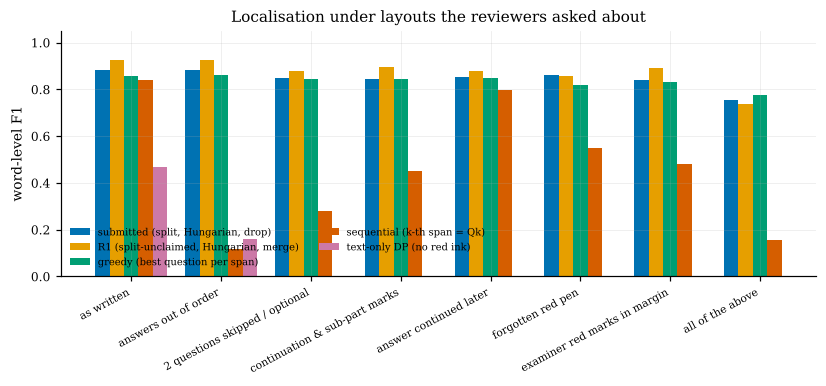

stress tests: 18600 answer slots evaluated in 262s


In [50]:
# ============================== 12.4 · LOCALISATION STRESS TESTS ==============================
# Real OCR lines with ground-truth labels are rearranged to create the situations the reviewers name.
# Only the layout is synthetic; the text each method must recognise is the real, noisy transcript.
STRESS_METHODS = {
    "submitted (split, Hungarian, drop)": dict(assigner="hungarian", split="always", policy="drop", keep_short=False),
    "R1 (split-unclaimed, Hungarian, merge)": dict(assigner="hungarian", split="unclaimed", policy="merge"),
    "greedy (best question per span)": dict(assigner="greedy", split="unclaimed", policy="merge"),
    "sequential (k-th span = Qk)": dict(assigner="sequential", split="unclaimed", policy="merge"),
    "text-only DP (no red ink)": None,
}
SCENARIOS = {
    "as written":                          "the real layout",
    "answers out of order":                "answer blocks shuffled",
    "2 questions skipped / optional":      "two answers removed (e.g. 'answer any eight')",
    "continuation & sub-part marks":       "1-3 extra red marks inside answers (re-numbered pages, (a)/(b))",
    "answer continued later":              "second half of one answer moved to the end, with its own mark",
    "forgotten red pen":                   "one answer's red mark removed",
    "examiner red marks in margin":        "2 spurious marks at random lines",
    "all of the above":                    "shuffled + 2 skipped + 1 extra mark + 1 forgotten mark + 1 spurious",
}


def _blocks(code):
    gt, L = GT_LINES[code], script_lines(REC[code], "v2")
    out, cur = [], None
    for i, q in enumerate(gt):
        if q is None:
            continue
        if cur and cur[0] == q and cur[1][-1] == i - 1:
            cur[1].append(i)
        else:
            cur = [q, [i]]; out.append(cur)
    return [(q, [L[i] for i in idx]) for q, idx in out]


def stress_variant(code, scen, rng):
    B = [(q, list(t)) for q, t in _blocks(code)]
    # each item: (question, lines, has_mark)
    items = [(q, t, True) for q, t in B]
    extra_marks = 0

    def shuffle(it):
        idx = rng.permutation(len(it)); return [it[i] for i in idx]

    def skip(it, k=2):
        if len(it) <= k + 1:
            return it
        drop = set(rng.choice(len(it), k, replace=False).tolist()); return [x for i, x in enumerate(it) if i not in drop]

    def forget(it):
        cand = [i for i in range(1, len(it))]
        if cand:
            i = int(rng.choice(cand)); q, t, _ = it[i]; it = it[:i] + [(q, t, False)] + it[i + 1:]
        return it

    def continued(it):
        long = [i for i, (q, t, m) in enumerate(it) if len(t) >= 12]
        if not long:
            return it
        i = int(rng.choice(long)); q, t, m = it[i]; h = len(t) // 2
        return it[:i] + [(q, t[:h], m)] + it[i + 1:] + [(q, t[h:], True)]

    if scen in ("answers out of order", "all of the above"):
        items = shuffle(items)
    if scen in ("2 questions skipped / optional", "all of the above"):
        items = skip(items)
    if scen == "answer continued later":
        items = continued(items)
    if scen in ("forgotten red pen", "all of the above"):
        items = forget(items)
    lines, labels, anchors = [], [], []
    for q, t, m in items:
        if m:
            anchors.append(len(lines))
        lines += t; labels += [q] * len(t)
    if scen == "continuation & sub-part marks":
        extra_marks = int(rng.integers(1, 4))
    if scen == "all of the above":
        extra_marks = 1
    starts = set(anchors)
    for _ in range(extra_marks):                       # inside an answer, >= 4 lines from its start
        ok = [i for i in range(4, len(lines) - 4) if all(abs(i - a) >= 4 for a in starts)
              and labels[i] == labels[i - 4]]
        if ok:
            a = int(rng.choice(ok)); anchors.append(a); starts.add(a)
    if scen in ("examiner red marks in margin", "all of the above"):
        for _ in range(2 if scen != "all of the above" else 1):
            ok = [i for i in range(2, len(lines) - 2) if all(abs(i - a) >= 2 for a in starts)]
            if ok:
                a = int(rng.choice(ok)); anchors.append(a); starts.add(a)
    return lines, sorted(anchors), labels


def stress_run(lines, anchors, labels, method):
    if method is None:
        res = textonly_with_ranges(lines, questions)
    else:
        res = segment_by_red_v2(lines, anchors, questions, **method)
        if res is None:
            res = textonly_with_ranges(lines, questions)
    words = [max(1, len(t.split())) for t in lines]
    return loc_metrics("_stress", res, gt=labels, words=words)


_codes_gt = [c for c in CODES if GT_LINES[c] is not None]
t_start = time.time()
stress_rows = []
TEXT_ONLY_SCENARIOS = ("as written", "answers out of order")   # the slow text-only aligner runs once, on these
rounds_done = 0
if _codes_gt:
    for v in range(EVAL["STRESS_VARIANTS"]):                    # whole rounds, so every scenario gets equal variants
        for scen in SCENARIOS:
            if scen == "as written" and v > 0:
                continue
            for c in _codes_gt:
                rng = np.random.default_rng([EVAL["SEED"], v, CODES.index(c), list(SCENARIOS).index(scen)])
                lines, anchors, labels = stress_variant(c, scen, rng)
                for mname, m in STRESS_METHODS.items():
                    if m is None and not (v == 0 and scen in TEXT_ONLY_SCENARIOS):
                        continue
                    for r in stress_run(lines, anchors, labels, m):
                        stress_rows.append({"scenario": scen, "method": mname, "script": c, "variant": v, **r})
        rounds_done = v + 1
        el = time.time() - t_start
        print(f"  round {rounds_done}/{EVAL['STRESS_VARIANTS']} done ({el:.0f}s)")
        if el > EVAL["STRESS_TIME_BUDGET_S"] and rounds_done >= 2:
            print(f"  time budget of {EVAL['STRESS_TIME_BUDGET_S']}s reached - stopping after {rounds_done} rounds")
            break
    SD = pd.DataFrame(stress_rows)

    def _f1(d):
        P = d["tp words"].sum() / max(1, d["pred words"].sum()); R = d["tp words"].sum() / max(1, d["gt words"].sum())
        return 2 * P * R / max(1e-9, P + R)

    tab = SD.groupby(["scenario", "method"]).apply(lambda d: pd.Series({
        "word F1": round(_f1(d), 3),
        "answers localised %": round(100 * d["localised ok"].mean(), 1),
        "non-attempts reported %": round(100 * (~d.loc[~d["attempted (GT)"], "predicted"]).mean(), 1)
        if (~d["attempted (GT)"]).any() else np.nan,
        "variants": d["variant"].nunique() * d["script"].nunique()})).reset_index()
    piv = tab.pivot(index="scenario", columns="method", values="word F1").reindex(list(SCENARIOS))
    r1_table(piv.reset_index(), "t06_stress_word_f1",
             f"Localisation stress tests, word-level F1 (real OCR text, rearranged layouts; {rounds_done} random "
             "variant(s) per scenario and script). The slow text-only aligner was run once per script, on the real "
             "layout and on shuffled answers only.")
    r1_table(tab, "t07_stress_detail", "Stress tests: all metrics per scenario and method.", show=False)

    fig, ax = plt.subplots(figsize=(7.4, 3.4))
    meths = list(STRESS_METHODS)
    w = 0.8 / len(meths)
    for k, mname in enumerate(meths):
        vals = [piv.loc[s, mname] if mname in piv.columns else np.nan for s in SCENARIOS]
        ax.bar(np.arange(len(SCENARIOS)) + k * w - 0.4 + w / 2, vals, w, label=mname, color=CB[k % len(CB)])
    ax.set_xticks(range(len(SCENARIOS))); ax.set_xticklabels(list(SCENARIOS), rotation=28, ha="right", fontsize=7)
    ax.set_ylabel("word-level F1"); ax.set_ylim(0, 1.05)
    ax.set_title("Localisation under layouts the reviewers asked about")
    ax.legend(fontsize=6.5, frameon=False, ncol=2, loc="lower left")
    r1_fig(fig, "r1_fig4_stress_tests", "Localisation stress tests: word-level F1 by scenario and method.")
    plt.show()
    R1_FACTS["stress word F1"] = piv.round(3).to_dict()
print(f"stress tests: {len(stress_rows)} answer slots evaluated in {time.time() - t_start:.0f}s")

## 12.5 · OCR error rate against manual transcription
*R3: "OCR confidence is not a measured transcription error rate. Compare OCR output with manually transcribed answers and report actual recognition errors."*

In [51]:
# ============================== 12.5 · OCR ERROR RATE vs MANUAL TRANSCRIPTION ==============================
# Reviewer 3: "OCR confidence is not a measured transcription error rate." This cell exports a sample of
# pages (header blacked out) for a person to transcribe, then measures CER and WER against those files.
from rapidfuzz.distance import Levenshtein as _Lev

TRANSCRIPT_DIR = f"{WORK}/transcripts"         # put <code>_p<NN>.txt here, e.g. S01_p02.txt
EXPORT_DIR = f"{R1DIR}/pages_for_transcription"
os.makedirs(TRANSCRIPT_DIR, exist_ok=True); os.makedirs(EXPORT_DIR, exist_ok=True)


def _tnorm(s):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9]+", " ", unicodedata.normalize("NFKC", str(s)).lower())).strip()


def cer_wer(hyp, ref):
    h, r = _tnorm(hyp), _tnorm(ref)
    if not r:
        return np.nan, np.nan
    cer = _Lev.distance(h, r) / len(r)
    wer = _Lev.distance(h.split(), r.split()) / max(1, len(r.split()))
    return cer, wer


def page_text(code, page, source="tesseract"):
    L = script_lines(REC[code], "v2")
    return "\n".join(t for t, l in zip(L, REC[code]["lines"]) if l["page"] == page and t != "[header redacted]")


TRANSCRIBE_PLAN = []
for c in CODES:
    n = len(REC[c]["pages"])
    cand = list(range(2, n + 1)) or [1]                  # page 1 carries the header: avoid it
    pick = sorted(np.random.default_rng([EVAL["SEED"], CODES.index(c)]).choice(
        cand, min(EVAL["TRANSCRIPT_PAGES_PER_SCRIPT"], len(cand)), replace=False).tolist())
    for p in pick:
        TRANSCRIBE_PLAN.append((c, p))
        png = f"{EXPORT_DIR}/{c[:-4]}_p{p:02d}.png"
        if not os.path.exists(png):
            im = redact_page(page_bgr(c, p, dpi=160), c, p)
            h = 1800 / im.shape[0]
            cv2.imwrite(png, cv2.resize(im, (int(im.shape[1] * h), 1800)))
        txt = f"{TRANSCRIPT_DIR}/{c[:-4]}_p{p:02d}.txt"
        if not os.path.exists(txt):
            open(txt, "w").close()


def ocr_error_table(extra_sources=None):
    rows = []
    for f in sorted(glob.glob(f"{TRANSCRIPT_DIR}/*.txt")):
        m = re.match(r"(S\d+|.+)_p(\d+)\.txt$", os.path.basename(f))
        ref = open(f, encoding="utf-8", errors="ignore").read()
        if not m or not ref.strip():
            continue
        c, p = m.group(1) + ".pdf", int(m.group(2))
        if c not in REC:
            continue
        row = {"script": c, "page": p, "ref words": len(_tnorm(ref).split()),
               "tesseract conf": round(REC[c]["pages"][p - 1]["conf"], 1)}
        row["Tesseract CER"], row["Tesseract WER"] = cer_wer(page_text(c, p), ref)
        for name, fn in (extra_sources or {}).items():
            hyp = fn(c, p)
            if hyp is not None:
                row[f"{name} CER"], row[f"{name} WER"] = cer_wer(hyp, ref)
        rows.append(row)
    return pd.DataFrame(rows)


OCR_ERR = ocr_error_table()
if len(OCR_ERR):
    r1_table(OCR_ERR.round(3), "t08_ocr_error_rate",
             "Measured recognition error against manual transcription (character and word error rate).")
    if len(OCR_ERR) >= 4:
        from scipy.stats import spearmanr
        rho, pv = spearmanr(OCR_ERR["tesseract conf"], OCR_ERR["Tesseract CER"])
        print(f"Spearman(Tesseract confidence, CER) = {rho:+.2f} (p = {pv:.2f}, n = {len(OCR_ERR)} pages)")
    R1_FACTS["ocr error"] = {"pages": len(OCR_ERR), "mean CER": float(OCR_ERR["Tesseract CER"].mean()),
                             "mean WER": float(OCR_ERR["Tesseract WER"].mean())}
else:
    print(f"No transcripts yet. {len(TRANSCRIBE_PLAN)} page images (header blacked out) were exported to\n"
          f"  {EXPORT_DIR}\nType each page verbatim (keep the student's spelling, one line per written line) into\n"
          f"  {TRANSCRIPT_DIR}/<code>_p<NN>.txt  (empty files are already there), then re-run this cell.")
    if IN_COLAB:
        def upload_transcripts():
            """Upload finished .txt transcripts (or a .zip of them), then re-run 12.5 and 12.14."""
            from google.colab import files as _f
            got = _f.upload()
            for name in got:
                if name.endswith(".zip"):
                    with zipfile.ZipFile(name) as z:
                        z.extractall(TRANSCRIPT_DIR)
                else:
                    os.replace(name, f"{TRANSCRIPT_DIR}/{os.path.basename(name)}")
            print("saved to", TRANSCRIPT_DIR)
        _zip = f"{R1DIR}/pages_for_transcription.zip"
        with zipfile.ZipFile(_zip, "w") as z:
            for f in glob.glob(f"{EXPORT_DIR}/*.png"):
                z.write(f, os.path.basename(f))
        print(f"Page images zipped: {_zip}  (in the final download, folder private_not_for_submission/; "
              "transcripts can be added later with upload_transcripts())")

No transcripts yet. 59 page images (header blacked out) were exported to
  /content/grading/r1/pages_for_transcription
Type each page verbatim (keep the student's spelling, one line per written line) into
  /content/grading/transcripts/<code>_p<NN>.txt  (empty files are already there), then re-run this cell.


## 12.6 · Signals for every answer and every control (computed once)

In [52]:
# ============================== 12.6 · SIGNALS FOR ALL ANSWERS AND CONTROLS ==============================
# Every (answer text, rubric) pair is scored once; every configuration below is arithmetic on these signals.
CSIM = CachedSim(sim)
SIG = {}
_t0 = time.time()


def sig_for(text, q, holdout=False):
    k = (hashlib.md5(text.encode("utf-8", "ignore")).hexdigest(), q.num, holdout)
    if k not in SIG:
        SIG[k] = answer_signals(text, q, CSIM, holdout_alts=holdout)
    return k


# ---- answer texts under the submitted and the R1 localisation, for every script --------------------
ANSWERS = {}
for loc in (LOC_SUBMITTED, LOC_REVISED):
    for c in CODES:
        res = LOC_RES.get((loc, c)) or run_localisation(c, LOC_METHODS[loc])
        LOC_RES[(loc, c)] = res
        for qn in QNUMS:
            ANSWERS[(loc, c, qn)] = res[qn]["text"]


def _span_conf(code, res, qn):
    idx = [i for a, b in res[qn].get("ranges", []) for i in range(a, b)]
    cs = [REC[code]["lines"][i]["conf"] for i in idx if i < len(REC[code]["lines"])]
    return float(np.mean(cs)) if cs else np.nan


rows = []
for c in CODES:
    res = LOC_RES[(LOC_REVISED, c)]
    for qn in QNUMS:
        t = ANSWERS[(LOC_REVISED, c, qn)]
        rows.append({"script": c, "Q": qn, "words": len(canon(t).split()),
                     "human": float(H1.loc[c, f"human_Q{qn}"]) if H1 is not None and c in H1.index else np.nan,
                     "attempted (GT)": (qn in GT_ATTEMPTED[c]) if GT_ATTEMPTED.get(c) is not None else np.nan,
                     "locate conf": res[qn]["locate_conf"], "span OCR conf": _span_conf(c, res, qn),
                     "continuations": res[qn].get("n_cont", 0)})
ANS_TABLE = pd.DataFrame(rows)

# ---- pairs: (answer text, rubric, control type, noise) -------------------------------------------------
PAIRS = []


def add_pair(control, text, q_ans, q_rub, script=None, noise=0.0, holdout=False, loc=None, extra=None):
    PAIRS.append({"control": control, "script": script, "q_ans": q_ans, "q_rub": q_rub, "noise": noise,
                  "holdout": holdout, "loc": loc, "key": sig_for(text, QBYNUM[q_rub], holdout),
                  "words": len(canon(text).split()), **(extra or {})})


for loc in (LOC_SUBMITTED, LOC_REVISED):
    for c in CODES:
        for qn in QNUMS:
            add_pair("matched", ANSWERS[(loc, c, qn)], qn, qn, c, loc=loc)

rng = np.random.default_rng(EVAL["SEED"])
attempted = [(c, qn, ANSWERS[(LOC_REVISED, c, qn)]) for c in CODES for qn in QNUMS
             if len(canon(ANSWERS[(LOC_REVISED, c, qn)]).split()) >= CONFIG["MIN_WORDS"]]


def _reflow(tokens, template):
    """Put tokens back into lines with the same token counts as the template text."""
    out, k = [], 0
    for ln in [l for l in template.splitlines() if l.strip()]:
        n = len(ln.split())
        out.append(" ".join(tokens[k:k + n])); k += n
    if k < len(tokens):
        out.append(" ".join(tokens[k:]))
    return "\n".join(out)


vocab_by_q = {qn: [w for c, q2, t in attempted if q2 != qn for w in t.split()] for qn in QNUMS}
_letters = "abcdefghijklmnopqrstuvwxyz"
for c, qn, t in attempted:
    toks = t.split()
    for q2 in QNUMS:                                               # C1 wrong question
        if q2 != qn:
            add_pair("wrong question", t, qn, q2, c)
    add_pair("shuffled words", _reflow(list(rng.permutation(toks)), t), qn, qn, c)          # C2
    pool = vocab_by_q[qn]
    add_pair("random OCR words", _reflow([pool[i] for i in rng.integers(0, len(pool), len(toks))], t),
             qn, qn, c)                                                                     # C3
    lens = [len(w) for w in toks]
    add_pair("random characters", _reflow(["".join(rng.choice(list(_letters), max(1, L)))
                                            for L in lens], t), qn, qn, c)                  # C4


# ---- rubric-derived texts: clean positive controls and adversarial wrong answers, with OCR noise -------
def ocr_noise(text, cer, rng):
    """Synthetic OCR corruption at a target character error rate: substitutions (from confusable
    shapes), deletions, insertions and word splits, in the proportions handwriting OCR shows."""
    if cer <= 0:
        return text
    conf = {"a": "ocu", "e": "co", "i": "l1j", "l": "1it", "m": "nrn", "n": "mu", "o": "a0c", "r": "n",
            "s": "5z", "t": "f+l", "u": "vn", "c": "e(", "d": "cl", "h": "b", "g": "q9y", "y": "g"}
    out = []
    for ch in text:
        r = rng.random()
        if ch.isalpha() and r < cer * 0.55:
            opts = conf.get(ch.lower(), _letters)
            out.append(opts[int(rng.integers(len(opts)))])
        elif ch.isalpha() and r < cer * 0.80:
            continue
        elif ch.isalpha() and r < cer * 0.92:
            out.append(ch + _letters[int(rng.integers(26))])
        elif ch.isalpha() and r < cer:
            out.append(ch + " ")
        else:
            out.append(ch)
    return "".join(out)


def _as_lines(sentences, per=8):
    words = " ".join(sentences).split()
    return "\n".join(" ".join(words[i:i + per]) for i in range(0, len(words), per))


def ref_text(q):
    return _as_lines([k.text for k in q.keypoints])


def alt_text(q):
    alts = [a for k in q.keypoints for a in getattr(k, "alts", [])[:1]]
    return _as_lines(alts) if alts else None


def keyword_stuffed(q, q_wrong, rng):
    """Correct keywords of q embedded in the content of a different question (Reviewer 3)."""
    words = ref_text(q_wrong).split()
    keys = [t for k in q.keypoints for t in (getattr(k, "kw", {}).get("key") or [])]
    for t in keys:
        words.insert(int(rng.integers(0, len(words) + 1)), t)
    return _as_lines([" ".join(words)])


def keyword_salad(q, rng):
    keys = [t for k in q.keypoints for t in (getattr(k, "kw", {}).get("key") or [])]
    seq = list(keys)
    while len(" ".join(seq).split()) < CONFIG["MIN_WORDS"]:
        seq += keys
    return _as_lines(list(rng.permutation(seq)))


for qn in QNUMS:
    q = QBYNUM[qn]
    others = [x for x in QNUMS if x != qn]
    wrongs = rng.choice(others, min(3, len(others)), replace=False).tolist()
    add_pair("keyword salad", keyword_salad(q, rng), qn, qn)
    for cer in EVAL["NOISE_CER"]:
        for s_ in range(2):
            r_ = np.random.default_rng([EVAL["SEED"], qn, int(cer * 100), s_])
            add_pair("reference answer", ocr_noise(ref_text(q), cer, r_), qn, qn, noise=cer)
            if alt_text(q):
                add_pair("paraphrase (held-out ALT)", ocr_noise(alt_text(q), cer, r_), qn, qn,
                         noise=cer, holdout=True)
        for q2 in wrongs:
            r_ = np.random.default_rng([EVAL["SEED"], qn, q2, int(cer * 100)])
            add_pair("keyword-stuffed wrong answer", ocr_noise(keyword_stuffed(q, QBYNUM[q2], r_), cer, r_),
                     qn, qn, noise=cer)
            add_pair("wrong question (clean reference)", ocr_noise(ref_text(QBYNUM[q2]), cer, r_), q2, qn,
                     noise=cer)
PAIRS_DF = pd.DataFrame(PAIRS)
print(f"{len(PAIRS_DF)} (answer, rubric) pairs, {len(SIG)} distinct signal sets, "
      f"computed in {time.time() - _t0:.0f}s")
display(PAIRS_DF.groupby(["control"]).size().rename("pairs").to_frame())


# ---- vectorised marks for any configuration ------------------------------------------------------------
def kp_rows(pairs, cfg):
    """One row per key point: raw blended score and the gate cap, for a configuration."""
    out = []
    for pi, p in enumerate(pairs.itertuples(index=False)):
        sg = SIG[p.key]
        for rec in sg["kps"]:
            frac_full, raw, a, lex = kp_fraction(rec, dict(cfg, lo=-1.0, hi=0.0))   # cap only
            cap = 1.0
            if rec["has_keys"] and rec["explicit"] and cfg["blend"] == "ensemble":
                if cfg["level"] == "moderate" and a < cfg["gate"]:
                    cap = cfg["cap"]
                elif cfg["level"] == "tough":
                    cap = a
            out.append((pi, rec["weight"], raw, cap))
    a = np.array(out, dtype=float) if out else np.zeros((0, 4))
    return a


def marks_vec(pairs, cfg, lo=None, hi=None, K=None):
    lo = cfg["lo"] if lo is None else lo
    hi = cfg["hi"] if hi is None else hi
    K = kp_rows(pairs, cfg) if K is None else K
    frac = np.clip((K[:, 2] - lo) / max(hi - lo, 1e-9), 0, 1)
    frac = np.where(K[:, 2] <= lo, 0.0, np.where(K[:, 2] >= hi, 1.0, frac))
    frac = np.minimum(frac, K[:, 3])
    earned = np.bincount(K[:, 0].astype(int), weights=K[:, 1] * frac, minlength=len(pairs))
    mx = np.array([MAXQ[q] for q in pairs["q_rub"]])
    m = np.minimum(np.round(earned * 2) / 2.0, mx)
    m[pairs["words"].to_numpy() < CONFIG["MIN_WORDS"]] = 0.0
    return m


print("signals ready; marks_vec(pairs, cfg) scores any configuration")

4494 (answer, rubric) pairs, 4225 distinct signal sets, computed in 1151s


,pairs
control,
keyword salad,10
keyword-stuffed wrong answer,150
matched,600
paraphrase (held-out ALT),100
random OCR words,282
random characters,282
reference answer,100
shuffled words,282
wrong question,2538


signals ready; marks_vec(pairs, cfg) scores any configuration


## 12.7 · Reproduction check, lexical saturation, chance anchor matches
*R2: "RapidFuzz partial_token_set_ratio returns 100 whenever the two strings share any single token"; "Short anchor terms tested with partial_ratio at threshold 72 against a 200-word noisy transcript will also match by chance."*

In [53]:
# ============================== 12.7 · REPRODUCTION CHECK AND LEXICAL SATURATION ==============================
CFG_SUB = make_cfg("submitted", "moderate")
CFG_R1 = make_cfg("revised", "moderate")
M = PAIRS_DF[PAIRS_DF["control"] == "matched"]
M_SUB = M[M["loc"] == LOC_SUBMITTED].reset_index(drop=True)
M_R1 = M[M["loc"] == LOC_REVISED].reset_index(drop=True)


def marks_matrix(pairs, cfg, **kw):
    m = marks_vec(pairs, cfg, **kw)
    d = pairs[["script", "q_rub"]].copy(); d["m"] = m
    return d.pivot(index="script", columns="q_rub", values="m").reindex(index=CODES, columns=QNUMS)


SYS_SUB = marks_matrix(M_SUB, CFG_SUB)
SYS_R1 = marks_matrix(M_R1, make_cfg())          # whatever the main run used (METHOD_VERSION/EVAL_LEVEL)
SYS_R1_MOD = marks_matrix(M_R1, CFG_R1)

# 1) the signal arithmetic reproduces the batch run of section 10
if "marks_df" in globals() and len(marks_df):
    md = marks_df.set_index("file").reindex(CODES)[[f"Q{n}" for n in QNUMS]]
    md.columns = QNUMS
    ref_mat = SYS_SUB if METHOD_VERSION == "submitted" else SYS_R1
    same = int((np.abs(md.to_numpy() - ref_mat.to_numpy()) < 1e-9).sum())
    print(f"Reproduction: section-10 batch vs signal arithmetic ({METHOD_VERSION}/{EVAL_LEVEL}): "
          f"{same}/{md.size} answers identical (max |diff| {np.nanmax(np.abs(md.to_numpy() - ref_mat.to_numpy())):.2f})")

# 2) the submitted configuration re-run today vs the numbers printed in the paper
if PAPER_MARKS:
    pm = pd.DataFrame.from_dict(PAPER_MARKS, orient="index", columns=QNUMS).reindex(CODES)
    diff = (SYS_SUB - pm)
    r1_table(pd.DataFrame({"script": CODES, "paper total": pm.sum(axis=1).values,
                           "submitted config re-run": SYS_SUB.sum(axis=1).values,
                           "answers identical": (np.abs(diff) < 1e-9).sum(axis=1).values}),
             "t09_rerun_vs_paper",
             "The submitted configuration re-run in this session against Table 2 of the paper. Differences come "
             "from the marking-scheme file (sha shown in t00), the Tesseract version and the semantic backend, "
             "not from the method. The paper must report the scheme and versions it used.")

# 3) lexical saturation (Reviewer 2)
def _kp_frame(pairs):
    rows = []
    for p in pairs.itertuples(index=False):
        for rec in SIG[p.key]["kps"]:
            cfg_t = dict(CFG_R1, level="moderate")
            rows.append({"control": p.control, "noise": p.noise, "words": p.words, "kind": rec["kind"],
                         "sem": rec["sem"], "lex_pts": rec["lex_pts"], "lex_cont": rec["lex_cont"],
                         "anchor_partial": anchor_alpha(rec, CFG_SUB), "anchor_token": anchor_alpha(rec, cfg_t),
                         "n_key": rec["n_key"],
                         "key_hits_partial": _hits(rec, "key", CFG_SUB), "key_hits_token": _hits(rec, "key", cfg_t)})
    return pd.DataFrame(rows)


KPF = _kp_frame(PAIRS_DF[(PAIRS_DF["words"] >= CONFIG["MIN_WORDS"]) & (PAIRS_DF["noise"] == 0) &
                         ((PAIRS_DF["loc"].isna()) | (PAIRS_DF["loc"] == LOC_REVISED))])
_ctl = ["matched", "wrong question", "shuffled words", "random OCR words", "random characters"]
sat = KPF[KPF["control"].isin(_ctl)].groupby("control").agg(
    key_points=("lex_pts", "size"),
    pct_lex_submitted_eq_1=("lex_pts", lambda x: round(100 * (x >= 0.999).mean(), 1)),
    mean_lex_submitted=("lex_pts", "mean"),
    pct_lex_R1_eq_1=("lex_cont", lambda x: round(100 * (x >= 0.999).mean(), 1)),
    mean_lex_R1=("lex_cont", "mean")).reindex(_ctl).round(3).reset_index()
r1_table(sat, "t10_lexical_saturation",
         "Lexical signal by control. The submitted partial_token_set_ratio is 1.0 for almost every key point, "
         "including answers to the wrong question and random text; the R1 content-token overlap is not.")
floor_credit = (0.85 * 0.45 * 1.0 - MATCH_FLOOR) / (MATCH_CEIL - MATCH_FLOOR)
print(f"With lexical = 1 and nothing else: r = 0.85 x 0.45 = {0.85 * 0.45:.3f} > floor {MATCH_FLOOR}, "
      f"so every prose key point receives {100 * floor_credit:.0f}% credit before any content is matched.")
R1_FACTS["lexical saturation"] = sat.set_index("control").to_dict("index")
R1_FACTS["free credit per key point (submitted)"] = round(float(floor_credit), 3)

chance = KPF[KPF["control"].isin(_ctl) & (KPF["n_key"] > 0)].groupby("control").apply(lambda d: pd.Series({
    "KEY terms tested": int(d["n_key"].sum()),
    "hit rate, submitted partial_ratio (72/66)": round(100 * d["key_hits_partial"].sum() / d["n_key"].sum(), 1),
    "hit rate, R1 token match": round(100 * d["key_hits_token"].sum() / d["n_key"].sum(), 1)})).reindex(_ctl).reset_index()
r1_table(chance, "t11_anchor_chance_hits",
         "How often KEY terms are declared 'present'. In answers to other questions and in random text every hit "
         "is a chance match (Reviewer 2: short terms matched by chance against a 200-word transcript).")
R1_FACTS["anchor chance hits"] = chance.set_index("control").to_dict("index")

Reproduction: section-10 batch vs signal arithmetic (submitted/moderate): 300/300 answers identical (max |diff| 0.00)



[t10_lexical_saturation] Lexical signal by control. The submitted partial_token_set_ratio is 1.0 for almost every key point, including answers to the wrong question and random text; the R1 content-token overlap is not.


,control,key_points,pct_lex_submitted_eq_1,mean_lex_submitted,pct_lex_R1_eq_1,mean_lex_R1
0,matched,1019,94.9,0.975,0.6,0.245
1,wrong question,9133,91.9,0.960,0.0,0.085
2,shuffled words,1019,94.9,0.975,0.5,0.232
3,random OCR words,1019,94.1,0.970,0.0,0.091
4,random characters,1019,57.4,0.756,0.0,0.001


With lexical = 1 and nothing else: r = 0.85 x 0.45 = 0.383 > floor 0.32, so every prose key point receives 22% credit before any content is matched.

[t11_anchor_chance_hits] How often KEY terms are declared 'present'. In answers to other questions and in random text every hit is a chance match (Reviewer 2: short terms matched by chance against a 200-word transcript).


,control,KEY terms tested,"hit rate, submitted partial_ratio (72/66)","hit rate, R1 token match"
0,matched,3846.0,33.0,17.9
1,wrong question,34506.0,15.0,2.3
2,shuffled words,3846.0,32.2,16.4
3,random OCR words,3846.0,16.7,2.5
4,random characters,3846.0,4.4,0.1


## 12.8 · Held-out calibration, content-blind baselines, threshold sensitivity
*R2: "The thresholds were not fixed in advance on separate scripts … the current figures are not held-out results." R3: "Report performance on an independent evaluation set."*


[t18_calibration] Answer-level MAE (marks /10, n = 300) with the provisional ramp, an in-sample fit (optimistic) and held-out leave-one-script-out; and the credit each final ramp gives to answers scored against the wrong question (correct value 0). 'constrained' = most accurate ramp that gives wrong-question answers at most 1/10. Content-blind baselines show how much of the agreement attempt detection alone achieves on this cohort.


,config,calibration objective,"MAE, provisional 0.32/0.60","MAE, in-sample fit","MAE, held-out (LOSO)",final floor/ceiling,wrong-question credit /10 (final ramp)
0,submitted,constrained,3.327,2.718,2.718,0.50/0.90,1.04
1,R1 easy,constrained,3.088,2.247,2.245,0.14/0.68,0.93
2,R1 moderate,constrained,3.543,2.273,2.273,0.14/0.56,0.97
3,R1 tough,constrained,3.637,3.123,3.128,0.06/0.38,0.11
4,submitted,examiner,3.327,1.908,1.972,0.28/0.90,3.97
5,R1 easy,examiner,3.088,1.892,1.908,0.00/0.76,2.38
6,R1 moderate,examiner,3.543,1.873,1.962,0.00/0.62,2.76
7,R1 tough,examiner,3.637,3.123,3.128,0.06/0.38,0.11
8,baseline: attempted -> constant,examiner,NaN,NaN,1.968,NaN,4.67
9,baseline: attempted -> f(log length),examiner,NaN,NaN,1.973,NaN,4.67



[t19_calibration_folds] Ramp chosen in each fold and the error on the held-out script.


,config,held-out,floor,ceiling,calibration MAE,held-out MAE
0,submitted,S01.pdf,0.50,0.90,2.710,2.95
1,submitted,S02.pdf,0.50,0.90,2.669,4.15
2,submitted,S03.pdf,0.50,0.90,2.688,3.60
3,submitted,S04.pdf,0.50,0.90,2.743,2.00
4,submitted,S05.pdf,0.50,0.90,2.707,3.05
...,...,...,...,...,...,...
115,R1 tough,S26.pdf,0.06,0.38,3.141,2.60
116,R1 tough,S27.pdf,0.02,0.42,3.131,2.95
117,R1 tough,S28.pdf,0.06,0.38,3.097,3.90
118,R1 tough,S29.pdf,0.06,0.38,3.072,4.60


  saved r1_fig7_calibration_sensitivity


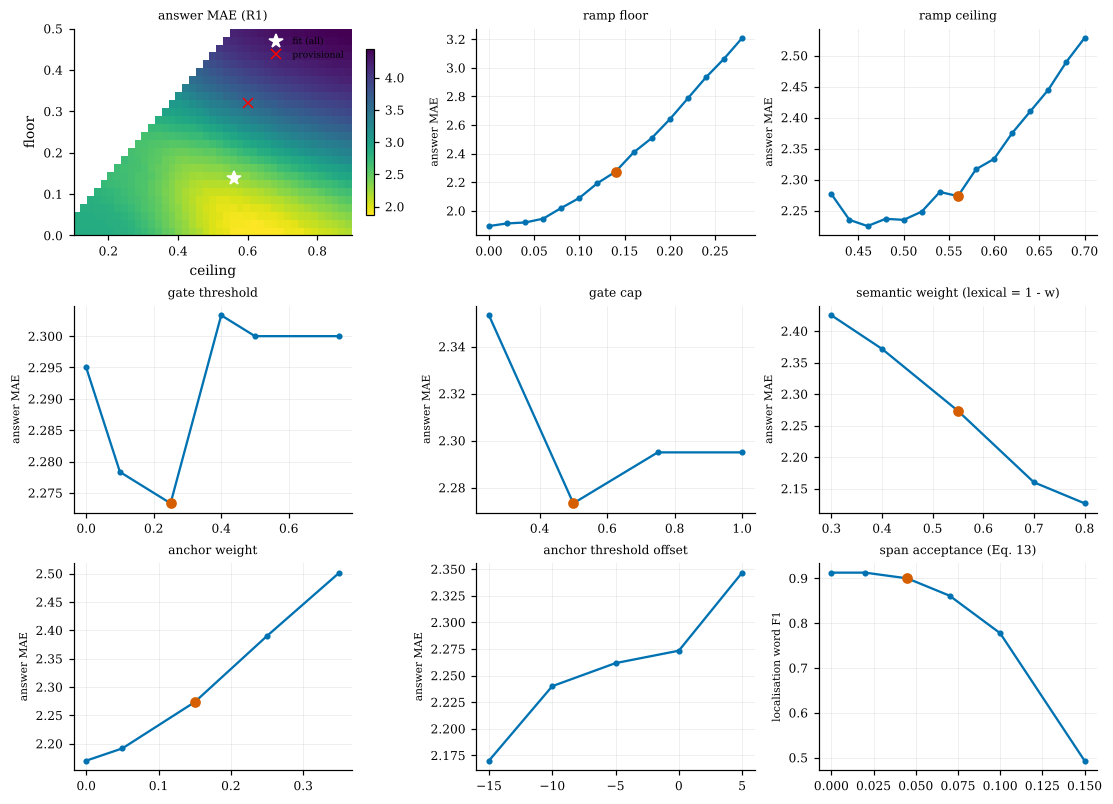

Frozen protocol written (cf48a9ba364a3526...). For the 30-50 script study: keep this file, put the new scripts in a fresh folder, set R1['RAMP_LO']/R1['RAMP_HI'] from it, and mark them once.


In [55]:
# ============================== 12.8 · HELD-OUT CALIBRATION AND THRESHOLD SENSITIVITY ==============================
# Reviewer 2: "the thresholds were not fixed in advance on separate scripts". Reviewer 3: "report performance on
# an independent evaluation set". With five scripts the honest estimate is leave-one-script-out (LOSO): the ramp
# floor and ceiling are fitted on four scripts and the fifth is marked with them, five times. Every other
# threshold stays at its pre-declared value; their influence is shown by the sensitivity sweeps below.
LO_GRID = [round(x, 2) for x in np.arange(0.00, 0.501, 0.02)]
HI_GRID = [round(x, 2) for x in np.arange(0.10, 0.901, 0.02)]
EVAL["RAMP_LO_GRID"], EVAL["RAMP_HI_GRID"] = LO_GRID, HI_GRID


def _human_vec(pairs):
    return np.array([H1.loc[c, f"human_Q{q}"] for c, q in zip(pairs["script"], pairs["q_rub"])], float)


def _splits():
    if isinstance(EVAL["SPLIT"], dict):
        return [(list(EVAL["SPLIT"]["calibration"]), list(EVAL["SPLIT"]["test"]))]
    return [([c for c in CODES if c != s], [s]) for s in CODES]


WRONG_R1 = PAIRS_DF[PAIRS_DF["control"] == "wrong question"].reset_index(drop=True)
CAL_OBJECTIVES = {"examiner": None,                 # minimise MAE on the examiner's marks only
                  "constrained": 1.0}               # ... subject to wrong-question credit <= 1 mark in 10
EVAL.setdefault("CAL_OBJECTIVE", "constrained")     # used for every downstream R1 result


def calibrate(pairs, cfg, name, max_wrong=None, controls=None):
    """Grid-fit (floor, ceiling) on calibration scripts, predict the held-out script (LOSO or fixed split).
    Objective: answer MAE on the examiner's marks. If max_wrong is set, only ramps that give answers scored
    against the wrong question (correct mark 0 by construction - no examiner judgement involved) at most
    max_wrong marks on average, on the calibration scripts, are allowed."""
    control_weight = max_wrong
    controls = WRONG_R1 if controls is None else controls
    K = kp_rows(pairs, cfg)
    Kc = kp_rows(controls, cfg) if control_weight is not None and len(controls) else None
    h = _human_vec(pairs)
    scripts = pairs["script"].to_numpy()
    cscripts = controls["script"].to_numpy() if Kc is not None else None
    grid = [(lo, hi) for lo in LO_GRID for hi in HI_GRID if hi >= lo + 0.06]
    P = np.stack([marks_vec(pairs, cfg, lo, hi, K) for lo, hi in grid])
    E = np.abs(P - h[None, :])
    C = np.stack([marks_vec(controls, cfg, lo, hi, Kc) for lo, hi in grid]) if Kc is not None else None

    def best(cal):
        e = E[:, np.isin(scripts, cal)].mean(axis=1)
        pen = np.array([abs(lo - cfg["lo"]) + abs(hi - cfg["hi"]) for lo, hi in grid])
        if C is not None:
            cw = C[:, np.isin(cscripts, cal)].mean(axis=1)
            feas = cw <= control_weight + 1e-9
            if feas.any():
                e = np.where(feas, e, np.inf)
            else:                                        # nothing feasible: least wrong-question credit
                e = cw
        i = int(np.lexsort((pen, np.round(e, 6)))[0])
        return grid[i], float(E[i, np.isin(scripts, cal)].mean())

    folds, pred = [], np.full(len(pairs), np.nan)
    for cal, test in _splits():
        (lo, hi), e_in = best(cal)
        tm = np.isin(scripts, test)
        pred[tm] = marks_vec(pairs, cfg, lo, hi, K)[tm]
        folds.append({"config": name, "held-out": ", ".join(test), "floor": lo, "ceiling": hi,
                      "calibration MAE": round(e_in, 3), "held-out MAE": round(mae(pred[tm], h[tm]), 3)})
    (lo_all, hi_all), _ = best(CODES)
    return {"name": name, "pairs": pairs, "cfg": cfg, "K": K, "human": h, "folds": folds,
            "pred_cv": pred, "pred_prov": marks_vec(pairs, cfg, K=K), "final": dict(cfg, lo=lo_all, hi=hi_all),
            "pred_insample": marks_vec(pairs, cfg, lo_all, hi_all, K),
            "grid": grid, "grid_mae": E.mean(axis=1), "control_weight": control_weight}


def baseline_predictions(pairs):
    """Content-blind baselines (Reviewer 2: 'agreement may largely reflect whether an answer was attempted and
    how long it is'): attempted -> the calibration scripts' mean mark; and a log-length regression."""
    h = _human_vec(pairs)
    w = pairs["words"].to_numpy(float)
    att = w >= CONFIG["MIN_WORDS"]
    scripts = pairs["script"].to_numpy()
    p_const, p_len, fits = np.zeros(len(pairs)), np.zeros(len(pairs)), []
    for cal, test in _splits():
        cm, tm = np.isin(scripts, cal) & att, np.isin(scripts, test)
        c = float(np.mean(h[cm])) if cm.any() else 0.0
        b = np.polyfit(np.log1p(w[cm]), h[cm], 1) if cm.sum() > 2 else np.array([0.0, c])
        p_const[tm] = np.where(att[tm], np.round(c * 2) / 2, 0.0)
        p_len[tm] = np.where(att[tm], np.clip(np.round(np.polyval(b, np.log1p(w[tm])) * 2) / 2, 0, 10), 0.0)
        fits.append({"held-out": ", ".join(test), "constant": round(c, 2), "slope": round(float(b[0]), 2),
                     "intercept": round(float(b[1]), 2)})
    return {"attempted -> constant": p_const, "attempted -> f(log length)": p_len}, fits


CAL, CAL_ALT = {}, {}
if H1 is not None:
    _w = CAL_OBJECTIVES[EVAL["CAL_OBJECTIVE"]]
    _alt = [k for k in CAL_OBJECTIVES if k != EVAL["CAL_OBJECTIVE"]][0]
    for key, pairs, cfg in [("submitted", M_SUB, CFG_SUB)] + \
            [(f"R1 {lv}", M_R1, make_cfg("revised", lv)) for lv in ("easy", "moderate", "tough")]:
        CAL[key] = calibrate(pairs, cfg, key, _w)
        CAL_ALT[key] = calibrate(pairs, cfg, key, CAL_OBJECTIVES[_alt])
    CAL_R1 = CAL["R1 moderate"]
    BASE_PRED, BASE_FITS = baseline_predictions(M_R1)

    summ = []
    _wq = WRONG_R1
    for objective, table in ((EVAL["CAL_OBJECTIVE"], CAL), (_alt, CAL_ALT)):
        for k, c in table.items():
            mask = ~np.isnan(c["pred_cv"])
            summ.append({"config": k, "calibration objective": objective,
                         "MAE, provisional 0.32/0.60": round(mae(c["pred_prov"][mask], c["human"][mask]), 3),
                         "MAE, in-sample fit": round(mae(c["pred_insample"][mask], c["human"][mask]), 3),
                         "MAE, held-out (LOSO)": round(mae(c["pred_cv"][mask], c["human"][mask]), 3),
                         "final floor/ceiling": f"{c['final']['lo']:.2f}/{c['final']['hi']:.2f}",
                         "wrong-question credit /10 (final ramp)": round(float(np.mean(marks_vec(_wq, c["final"]))), 2)})
    hb = _human_vec(M_R1)
    for bname, p in BASE_PRED.items():
        summ.append({"config": f"baseline: {bname}", "calibration objective": "examiner",
                     "MAE, held-out (LOSO)": round(mae(p, hb), 3),
                     "wrong-question credit /10 (final ramp)": round(float(np.mean(np.where(
                         _wq["words"] >= CONFIG["MIN_WORDS"], np.mean(hb[M_R1["words"] >= CONFIG["MIN_WORDS"]]), 0))), 2)})
    CAL_SUMMARY = r1_table(pd.DataFrame(summ), "t18_calibration",
                           f"Answer-level MAE (marks /10, n = {len(M_R1)}) with the provisional ramp, an in-sample fit (optimistic) "
                           "and held-out leave-one-script-out; and the credit each final ramp gives to answers scored "
                           "against the wrong question (correct value 0). 'constrained' = most accurate ramp that gives "
                           "wrong-question answers at most 1/10. Content-blind baselines show how much of the agreement "
                           "attempt detection alone achieves on this cohort.")
    r1_table(pd.DataFrame([f for c in CAL.values() for f in c["folds"]]), "t19_calibration_folds",
             "Ramp chosen in each fold and the error on the held-out script.")
    R1_FACTS["calibration"] = CAL_SUMMARY.to_dict("records")

    # ---- sensitivity of the R1 (moderate) result to every threshold, one at a time -------------------
    base = CAL_R1["final"]
    h = CAL_R1["human"]
    sweeps = {
        "ramp floor": ("lo", np.round(np.arange(max(0, base["lo"] - .14), base["lo"] + .141, .02), 2)),
        "ramp ceiling": ("hi", np.round(np.arange(base["hi"] - .14, base["hi"] + .141, .02), 2)),
        "gate threshold": ("gate", [0.0, 0.1, 0.25, 0.4, 0.5, 0.75]),
        "gate cap": ("cap", [0.25, 0.5, 0.75, 1.0]),
        "semantic weight (lexical = 1 - w)": ("w_sem", [0.3, 0.4, 0.55, 0.7, 0.8]),
        "anchor weight": ("w_anchor", [0.0, 0.05, 0.15, 0.25, 0.35]),
        "anchor threshold offset": ("anchor_offset", [-15, -10, -5, 0, 5]),
    }
    srows = []
    for lab, (key, vals) in sweeps.items():
        for v in vals:
            cfg = dict(base, **{key: float(v)})
            if key == "w_sem":
                cfg["w_lex"] = 1 - float(v)
            if cfg["hi"] <= cfg["lo"]:
                continue
            m = marks_vec(M_R1, cfg)
            srows.append({"parameter": lab, "value": float(v), "answer MAE": mae(m, h),
                          "is default": abs(float(v) - float(base.get(key, np.nan))) < 1e-9})
    SENS = pd.DataFrame(srows)
    # localisation acceptance threshold (Eq. 13) - affects which spans are graded
    for v in [0.0, 0.02, 0.045, 0.07, 0.10, 0.15]:
        rows_ = []
        for c in CODES:
            if GT_LINES[c] is not None:
                rows_ += loc_metrics(c, run_localisation(c, LOC_METHODS[LOC_REVISED], min_sim=v))
        if rows_:
            srows.append({"parameter": "span acceptance (Eq. 13)", "value": v,
                          "localisation word F1": summarise_loc(rows_)["word F1"], "is default": abs(v - RED_MIN_SIM) < 1e-9})
    SENS = pd.DataFrame(srows)
    r1_table(SENS.round(3), "t20_sensitivity", "One-at-a-time sensitivity of the R1 result to each threshold.",
             show=False)

    fig, axs = plt.subplots(3, 3, figsize=(10, 7.2))
    axs = axs.ravel()
    gm = CAL_R1["grid_mae"]
    G = np.full((len(LO_GRID), len(HI_GRID)), np.nan)
    for (lo, hi), e in zip(CAL_R1["grid"], gm):
        G[LO_GRID.index(lo), HI_GRID.index(hi)] = e
    im = axs[0].imshow(G, origin="lower", aspect="auto", cmap="viridis_r",
                       extent=[HI_GRID[0], HI_GRID[-1], LO_GRID[0], LO_GRID[-1]])
    axs[0].plot(base["hi"], base["lo"], "w*", ms=9, label="fit (all)")
    for f in CAL_R1["folds"]:
        axs[0].plot(f["ceiling"], f["floor"], "wo", ms=3)
    axs[0].plot(MATCH_CEIL, MATCH_FLOOR, "rx", ms=7, label="provisional")
    axs[0].set_xlabel("ceiling"); axs[0].set_ylabel("floor"); axs[0].set_title("answer MAE (R1)", fontsize=8)
    axs[0].legend(fontsize=6, frameon=False); axs[0].grid(False)
    fig.colorbar(im, ax=axs[0], shrink=.8)
    for a_, lab in zip(axs[1:], list(sweeps) + ["span acceptance (Eq. 13)"]):
        d = SENS[SENS["parameter"] == lab]
        col = "localisation word F1" if lab.startswith("span") else "answer MAE"
        if d.empty or col not in d.columns:           # LOCAL RUN fix: no localisation ground truth -> no panel
            a_.set_visible(False)
            continue
        a_.plot(d["value"], d[col], "o-", color=CB[0], ms=3)
        dd = d[d["is default"]]
        a_.plot(dd["value"], dd[col], "o", color=CB[3], ms=6)
        a_.set_title(lab, fontsize=8); a_.set_ylabel(col, fontsize=7)
    r1_fig(fig, "r1_fig7_calibration_sensitivity",
           "Calibration surface for the R1 ramp (held-out fold choices as dots) and one-at-a-time sensitivity of the "
           "result to every other threshold (red = value used).")
    plt.show()

    # ---- frozen protocol for the next, larger study --------------------------------------------------
    PROTOCOL = {"frozen_utc": pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d %H:%M"),
                "scheme_sha256": file_sha(SCHEME_PATH), "semantic_backend": sim.backend, "tesseract": ENV["tesseract"],
                "R1": R1, "LEVELS": LEVELS, "RED": {"margin": RED_MARGIN_FRAC, "sat": RED_SAT_MIN,
                                                    "dominance": RED_DOMINANCE, "accept": RED_MIN_SIM},
                "ramp_by_config": {k: {"floor": c["final"]["lo"], "ceiling": c["final"]["hi"]} for k, c in CAL.items()},
                "calibrated_on": CODES, "examiner_marks_source": H1_SRC}
    _blob = json.dumps(PROTOCOL, sort_keys=True, default=str).encode()
    PROTOCOL["sha256"] = hashlib.sha256(_blob).hexdigest()
    with open(f"{R1DIR}/protocol_R1_frozen.json", "w") as fh:
        json.dump(PROTOCOL, fh, indent=2, default=str)
    print(f"Frozen protocol written ({PROTOCOL['sha256'][:16]}...). For the 30-50 script study: keep this file, "
          f"put the new scripts in a fresh folder, set R1['RAMP_LO']/R1['RAMP_HI'] from it, and mark them once.")
else:
    CAL = {}
    print("No examiner marks: calibration skipped. Controls and levels below use the provisional ramp.")


def best_cfg(key, fallback):
    return CAL[key]["final"] if key in CAL else fallback

## 12.9 · Negative and adversarial controls
*R2: "Please report negative controls: each answer scored against the wrong question's key points; shuffled or random text of the same length; the distribution of each signal for correct versus mismatched pairs." R3: "Test the scoring rules against incorrect answers containing expected keywords. Also test correct answers expressed differently."*


[t12_controls] Negative and adversarial controls (clean text, no added noise). Mean marks out of 10 and the share of pairs receiving any credit. 'Wrong question' scores every attempted answer against the other nine rubrics; 'random OCR words' draws real OCR tokens from answers to other questions. Calibrated ramps come from 12.8 (fitted on the examiner's marks of the real answers only; no control was used).


,control,expected,pairs,"submitted, published ramp: mean /10","submitted, published ramp: % any credit","submitted, calibrated: mean /10","submitted, calibrated: % any credit","R1, calibrated: mean /10","R1, calibrated: % any credit","R1, calibrated on examiner only: mean /10","R1, calibrated on examiner only: % any credit",baseline attempted->constant: mean /10
0,matched,real answers,282,7.80,100.0,2.40,96.8,3.47,95.7,4.55,100.0,4.5
1,wrong question,≈ 0,2538,6.15,99.7,1.04,86.1,0.97,71.9,2.76,100.0,4.5
2,shuffled words,?,282,7.80,100.0,2.23,95.7,3.21,95.4,4.38,100.0,4.5
3,random OCR words,≈ 0,282,6.41,100.0,1.14,88.7,1.04,78.0,2.85,100.0,4.5
4,random characters,0,282,3.30,85.5,0.34,48.9,0.04,8.5,2.07,100.0,4.5
5,keyword salad,low,10,10.00,100.0,7.30,100.0,9.55,100.0,9.25,100.0,4.5
6,keyword-stuffed wrong answer,low,30,10.00,100.0,7.18,100.0,9.90,100.0,9.63,100.0,4.5
7,wrong question (clean reference),≈ 0,30,7.52,100.0,2.68,100.0,3.50,100.0,4.55,100.0,4.5
8,paraphrase (held-out ALT),high,20,9.80,100.0,6.95,100.0,8.15,100.0,8.20,100.0,4.5
9,reference answer,≈ full,20,10.00,100.0,9.95,100.0,10.00,100.0,10.00,100.0,4.5



[t13_signal_separation] How well each signal separates a key point's own answer from answers to other questions (AUC 0.5 = no information).


,signal,mean (matched),mean (wrong question),ROC AUC
0,semantic σ,0.346,0.291,0.682
1,"lexical, submitted",0.975,0.960,0.515
2,"lexical, R1",0.245,0.085,0.764
3,"anchor, submitted",0.330,0.150,0.681
4,"anchor, R1",0.179,0.024,0.692



[t14_noise_curves] Marks awarded to rubric-derived texts as synthetic OCR noise rises (character error rate). Correct answers should stay high; wrong answers, even with the right keywords, should stay low.


CER,control,config,0.0,0.1,0.2,0.3,0.45
0,keyword-stuffed wrong answer,"R1, calibrated",9.90,9.17,7.63,5.27,3.03
1,keyword-stuffed wrong answer,"R1, calibrated on examiner only",9.63,8.85,7.55,5.85,4.32
2,keyword-stuffed wrong answer,"submitted, calibrated",7.18,6.13,5.13,3.95,2.32
3,keyword-stuffed wrong answer,"submitted, published ramp",10.00,10.00,10.00,9.83,8.50
4,paraphrase (held-out ALT),"R1, calibrated",8.15,6.80,5.40,3.65,1.35
5,paraphrase (held-out ALT),"R1, calibrated on examiner only",8.20,6.98,5.90,4.65,2.88
6,paraphrase (held-out ALT),"submitted, calibrated",6.95,5.35,3.48,2.58,1.23
7,paraphrase (held-out ALT),"submitted, published ramp",9.80,9.70,8.90,7.92,6.38
8,reference answer,"R1, calibrated",10.00,10.00,9.68,8.07,3.50
9,reference answer,"R1, calibrated on examiner only",10.00,10.00,9.50,7.88,4.65


  saved r1_fig5_controls


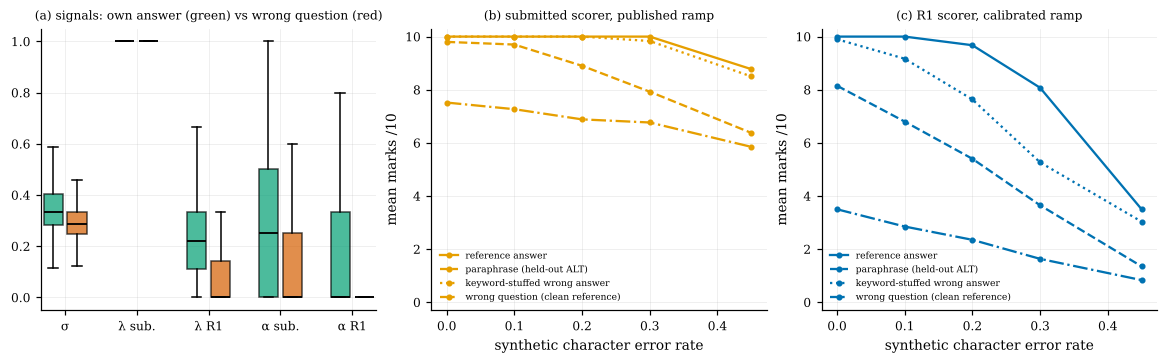


[t12b_score_distributions] Distribution of the awarded score (marks /10) for matched pairs (each written answer scored against its own question) and mismatched pairs (the same answer against the other nine questions' key points; random text of the same length). TPC condition 2. The AUC row is the probability that a matched pair outscores a mismatched one (0.5 = no separation).


,scorer,pair type,pairs,mean /10,SD,median,IQR,min,max,% scored > 0,% scored >= 5
0,"submitted, published ramp",matched (own question),282,7.800,1.76,8.00,6.5-9.0,0.5,10.0,100.0,96.1
1,"submitted, published ramp",mismatched: wrong question's key points,2538,6.150,1.61,6.50,5.0-7.0,0.0,10.0,99.7,86.6
2,"submitted, published ramp","random OCR words, same length",282,6.410,1.58,6.50,5.0-7.0,1.0,10.0,100.0,90.1
3,"submitted, published ramp","random characters, same length",282,3.300,2.06,3.50,2.0-5.0,0.0,8.0,85.5,35.8
4,"submitted, published ramp",separation: AUC matched vs wrong question,2820,0.767,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,"submitted, calibrated",matched (own question),282,2.400,1.42,2.25,1.5-3.0,0.0,6.5,96.8,7.4
6,"submitted, calibrated",mismatched: wrong question's key points,2538,1.040,0.76,1.00,0.5-1.5,0.0,5.0,86.1,0.1
7,"submitted, calibrated","random OCR words, same length",282,1.140,0.78,1.00,0.5-1.5,0.0,3.5,88.7,0.0
8,"submitted, calibrated","random characters, same length",282,0.340,0.40,0.00,0.0-0.5,0.0,1.5,48.9,0.0
9,"submitted, calibrated",separation: AUC matched vs wrong question,2820,0.797,NaN,NaN,NaN,NaN,NaN,NaN,NaN


  saved r1_fig5b_score_distributions


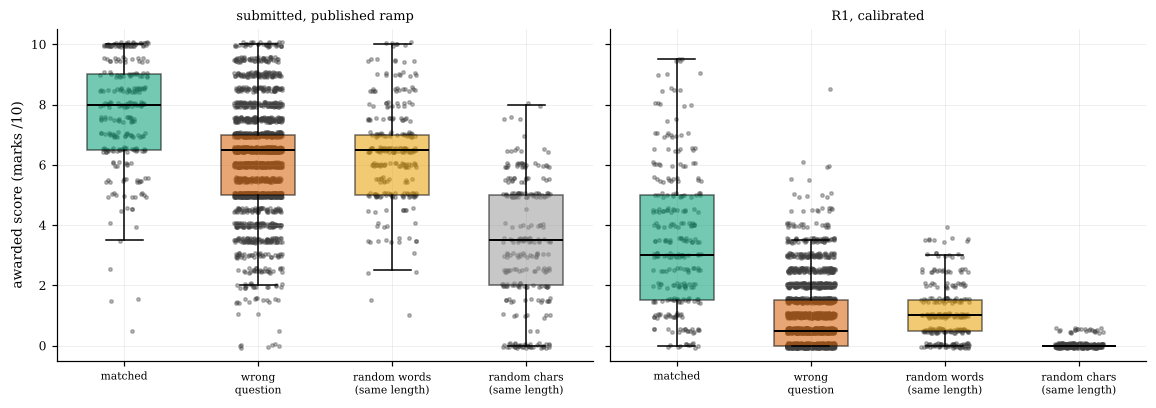

In [56]:
# ============================== 12.9 · NEGATIVE AND ADVERSARIAL CONTROLS ==============================
from sklearn.metrics import roc_auc_score

CTRL_ORDER = ["matched", "wrong question", "shuffled words", "random OCR words", "random characters",
              "keyword salad", "keyword-stuffed wrong answer", "wrong question (clean reference)",
              "paraphrase (held-out ALT)", "reference answer"]
EXPECT = {"matched": "real answers", "wrong question": "≈ 0", "shuffled words": "?", "random OCR words": "≈ 0",
          "random characters": "0", "keyword salad": "low", "keyword-stuffed wrong answer": "low",
          "wrong question (clean reference)": "≈ 0", "paraphrase (held-out ALT)": "high",
          "reference answer": "≈ full"}


def control_table(cfgs, noise=0.0):
    rows = []
    P = PAIRS_DF[((PAIRS_DF["loc"].isna()) | (PAIRS_DF["loc"] == LOC_REVISED)) &
                 ((PAIRS_DF["noise"] == noise) | (PAIRS_DF["control"].isin(_ctl + ["keyword salad"])))]
    for ctl in CTRL_ORDER:
        d = P[P["control"] == ctl].reset_index(drop=True)
        if ctl == "matched":
            d = d[d["words"] >= CONFIG["MIN_WORDS"]].reset_index(drop=True)
        if not len(d):
            continue
        row = {"control": ctl, "expected": EXPECT[ctl], "pairs": len(d)}
        for name, cfg in cfgs.items():
            m = marks_vec(d, cfg)
            row[f"{name}: mean /10"] = round(float(np.mean(m)), 2)
            row[f"{name}: % any credit"] = round(100 * float(np.mean(m > 0)), 1)
        if _bc is not None:
            row["baseline attempted->constant: mean /10"] = round(float(np.mean(
                np.where(d["words"] >= CONFIG["MIN_WORDS"], np.round(_bc * 2) / 2, 0))), 2)
        rows.append(row)
    return pd.DataFrame(rows)


CTRL_CFGS = {"submitted, published ramp": CFG_SUB,
             "submitted, calibrated": best_cfg("submitted", CFG_SUB),
             "R1, calibrated": best_cfg("R1 moderate", CFG_R1)}
if "R1 moderate" in CAL_ALT:
    CTRL_CFGS["R1, calibrated on examiner only"] = CAL_ALT["R1 moderate"]["final"]
_bc = float(np.mean(_human_vec(M_R1)[M_R1["words"] >= CONFIG["MIN_WORDS"]])) if H1 is not None else None
CTRL = control_table(CTRL_CFGS)
r1_table(CTRL, "t12_controls",
         "Negative and adversarial controls (clean text, no added noise). Mean marks out of 10 and the share of "
         "pairs receiving any credit. 'Wrong question' scores every attempted answer against the other nine "
         "rubrics; 'random OCR words' draws real OCR tokens from answers to other questions. Calibrated ramps "
         "come from 12.8 (fitted on the examiner's marks of the real answers only; no control was used).")
R1_FACTS["controls"] = CTRL.set_index("control").to_dict("index")

# signal separation: matched (attempted) vs wrong-question key points
sep = []
mk = KPF[KPF["control"].isin(["matched", "wrong question"])]
y = (mk["control"] == "matched").astype(int)
for col, lab in [("sem", "semantic σ"), ("lex_pts", "lexical, submitted"), ("lex_cont", "lexical, R1"),
                 ("anchor_partial", "anchor, submitted"), ("anchor_token", "anchor, R1")]:
    try:
        auc = roc_auc_score(y, mk[col])
    except ValueError:
        auc = np.nan
    sep.append({"signal": lab, "mean (matched)": round(mk.loc[y == 1, col].mean(), 3),
                "mean (wrong question)": round(mk.loc[y == 0, col].mean(), 3), "ROC AUC": round(auc, 3)})
SEP = r1_table(pd.DataFrame(sep), "t13_signal_separation",
               "How well each signal separates a key point's own answer from answers to other questions "
               "(AUC 0.5 = no information).")
R1_FACTS["signal AUC"] = SEP.set_index("signal")["ROC AUC"].to_dict()

# noise curves
noise_rows = []
for ctl in ["reference answer", "paraphrase (held-out ALT)", "keyword-stuffed wrong answer",
            "wrong question (clean reference)"]:
    for cer in EVAL["NOISE_CER"]:
        d = PAIRS_DF[(PAIRS_DF["control"] == ctl) & (PAIRS_DF["noise"] == cer)].reset_index(drop=True)
        if not len(d):
            continue
        for name, cfg in CTRL_CFGS.items():
            noise_rows.append({"control": ctl, "CER": cer, "config": name,
                               "mean marks /10": float(np.mean(marks_vec(d, cfg)))})
NOISE = pd.DataFrame(noise_rows)
r1_table(NOISE.pivot_table(index=["control", "config"], columns="CER", values="mean marks /10").round(2).reset_index(),
         "t14_noise_curves",
         "Marks awarded to rubric-derived texts as synthetic OCR noise rises (character error rate). Correct "
         "answers should stay high; wrong answers, even with the right keywords, should stay low.")

fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.2))
cols = ["sem", "lex_pts", "lex_cont", "anchor_partial", "anchor_token"]
labs = ["σ", "λ sub.", "λ R1", "α sub.", "α R1"]
for i, col in enumerate(cols):
    for j, (ctl, colr) in enumerate([("matched", CB[2]), ("wrong question", CB[3])]):
        v = KPF.loc[KPF["control"] == ctl, col].dropna()
        bp = ax[0].boxplot(v, positions=[i * 3 + j], widths=.8, patch_artist=True, showfliers=False,
                           medianprops=dict(color="k", lw=1.2))
        for b in bp["boxes"]:
            b.set_facecolor(colr); b.set_alpha(.7)
ax[0].set_xticks([i * 3 + .5 for i in range(len(cols))]); ax[0].set_xticklabels(labs)
ax[0].set_title("(a) signals: own answer (green) vs wrong question (red)", fontsize=8)
for k, (ctl, ls) in enumerate([("reference answer", "-"), ("paraphrase (held-out ALT)", "--"),
                               ("keyword-stuffed wrong answer", ":"), ("wrong question (clean reference)", "-.")]):
    for name, colr in (("submitted, published ramp", CB[1]), ("R1, calibrated", CB[0])):
        d = NOISE[(NOISE["control"] == ctl) & (NOISE["config"] == name)]
        a_ = ax[1] if name.startswith("submitted") else ax[2]
        a_.plot(d["CER"], d["mean marks /10"], ls=ls, marker="o", ms=3, color=colr, label=ctl)
for a_, t in ((ax[1], "(b) submitted scorer, published ramp"), (ax[2], "(c) R1 scorer, calibrated ramp")):
    a_.set_xlabel("synthetic character error rate"); a_.set_ylabel("mean marks /10"); a_.set_ylim(-0.3, 10.3)
    a_.set_title(t, fontsize=8)
for a_ in (ax[1], ax[2]):
    a_.legend(fontsize=6, frameon=False, loc="lower left")
r1_fig(fig, "r1_fig5_controls", "Signal distributions for an answer's own question versus other questions, and "
       "marks for correct, paraphrased and keyword-stuffed texts as OCR noise increases.")
plt.show()

# ---- TPC condition 2: distribution of the AWARDED SCORE for matched and mismatched pairs ----------------
DIST_TYPES = [("matched (own question)", "matched"), ("mismatched: wrong question's key points", "wrong question"),
              ("random OCR words, same length", "random OCR words"), ("random characters, same length", "random characters")]


def _pairs_of(ctl):
    d = PAIRS_DF[(PAIRS_DF["control"] == ctl) & ((PAIRS_DF["loc"].isna()) | (PAIRS_DF["loc"] == LOC_REVISED))]
    if ctl == "matched":
        d = d[d["words"] >= CONFIG["MIN_WORDS"]]          # written answers only (blank ones are trivially 0)
    return d.reset_index(drop=True)


dist_rows, DIST = [], {}
for cname, cfg in CTRL_CFGS.items():
    for lab, ctl in DIST_TYPES:
        d = _pairs_of(ctl)
        if not len(d):
            continue
        m = marks_vec(d, cfg)
        DIST[(cname, lab)] = m
        q1, med, q3 = np.percentile(m, [25, 50, 75])
        dist_rows.append({"scorer": cname, "pair type": lab, "pairs": len(m), "mean /10": round(float(m.mean()), 2),
                          "SD": round(float(m.std(ddof=1)), 2) if len(m) > 1 else np.nan,
                          "median": round(float(med), 2), "IQR": f"{q1:.1f}-{q3:.1f}",
                          "min": float(m.min()), "max": float(m.max()),
                          "% scored > 0": round(100 * float(np.mean(m > 0)), 1),
                          "% scored >= 5": round(100 * float(np.mean(m >= 5)), 1)})
    mm, mw = DIST.get((cname, DIST_TYPES[0][0])), DIST.get((cname, DIST_TYPES[1][0]))
    if mm is not None and mw is not None:
        auc = roc_auc_score(np.r_[np.ones(len(mm)), np.zeros(len(mw))], np.r_[mm, mw])
        R1_FACTS.setdefault("score AUC matched vs wrong question", {})[cname] = round(float(auc), 3)
        dist_rows.append({"scorer": cname, "pair type": "separation: AUC matched vs wrong question",
                          "pairs": len(mm) + len(mw), "mean /10": round(float(auc), 3)})
DIST_TABLE = r1_table(pd.DataFrame(dist_rows), "t12b_score_distributions",
                      "Distribution of the awarded score (marks /10) for matched pairs (each written answer scored "
                      "against its own question) and mismatched pairs (the same answer against the other nine "
                      "questions' key points; random text of the same length). TPC condition 2. The AUC row is the "
                      "probability that a matched pair outscores a mismatched one (0.5 = no separation).")
R1_FACTS["score distributions"] = DIST_TABLE.to_dict("records")

_show = [k for k in ("submitted, published ramp", "R1, calibrated") if k in CTRL_CFGS]
fig, axs = plt.subplots(1, len(_show), figsize=(5.2 * len(_show), 3.6), sharey=True)
axs = np.atleast_1d(axs)
rj = np.random.default_rng(3)
for a_, cname in zip(axs, _show):
    vals = [DIST.get((cname, lab), np.array([])) for lab, _ in DIST_TYPES]
    bp = a_.boxplot(vals, widths=.55, patch_artist=True, showfliers=False, medianprops=dict(color="k", lw=1.3))
    for b, colr in zip(bp["boxes"], [CB[2], CB[3], CB[1], CB[7]]):
        b.set_facecolor(colr); b.set_alpha(.55)
    for k, v in enumerate(vals, 1):
        if len(v):
            a_.scatter(k + rj.uniform(-.18, .18, len(v)), v + rj.uniform(-.08, .08, len(v)), s=5, color="0.25", alpha=.35)
    a_.set_xticks(range(1, len(DIST_TYPES) + 1))
    a_.set_xticklabels(["matched", "wrong\nquestion", "random words\n(same length)", "random chars\n(same length)"], fontsize=7)
    a_.set_title(cname, fontsize=8.5); a_.set_ylim(-0.5, 10.5)
axs[0].set_ylabel("awarded score (marks /10)")
r1_fig(fig, "r1_fig5b_score_distributions",
       "Awarded scores for matched pairs (each written answer against its own question) and mismatched pairs (against "
       "the other questions' key points, or random text of the same length). Boxes: quartiles; dots: individual pairs.")
plt.show()

## 12.10 · Three evaluation levels: Easy, Moderate, Tough
Easy counts every keyword in the scheme; Moderate counts the examiner's `KEY:` terms (the submitted rule); Tough counts only the strong keywords. Each level gets its own held-out ramp from 12.8.

Keyword pools used by the three levels (examiner: check 'strong'; star terms in the scheme to override)
Keyword pools per key point (check the 'strong' column; star terms in the scheme to override):


,Q,kp,marks,KEY (moderate),strong (tough),extra words (easy)
0,1,1,3.0,"Bayes, language, detect, text","Bayes, detect","naive, classifier, automatically, detects, written, dete..."
1,1,2,3.0,"gram, character, word",character,"uses, patterns, instead, full, sequence, characters, ide..."
2,1,3,2.0,"gram, hello, hel","hello, hel","unigram, bigram, trigram, give, gives, single, characters"
3,1,4,2.0,"training, data, probability, select",select,"collects, many, computes, picks, highest, collect, multi..."
4,2,1,3.0,"encoder, decoder, neural, sequence","encoder, decoder","network, architecture, machine, translation, generate, l..."
5,2,2,3.0,"encoder, input, hidden, read","encoder, hidden","reads, converts, representation, first, stage, interpret..."
6,2,3,2.0,"context, vector, meaning",vector,"final, hidden, state, becomes, stores, complete, acts, b..."
7,2,4,2.0,"decoder, output, word, translat",decoder,"uses, vector, generate, translated, time, gives, sequenc..."
8,3,1,3.0,"human, automatic, evaluat","human, automatic","machine, translation, evaluated, evaluation, divided"
9,3,2,3.0,"human, adequacy, fluency, expensive","human, adequacy","evaluation, checks, preserved, grammatically, correct, a..."



[t16_levels] Three evaluation levels. R1 levels use their own calibrated ramp (12.8); the submitted rows use the published ramp. Control columns are mean marks /10: low is right for wrong answers, high for paraphrases and noisy reference answers.


,level,mean total /100,ramp,answer MAE (fit all),answer bias,script MAE,answer MAE held-out (LOSO),wrong question,keyword-stuffed wrong answer,keyword-stuffed wrong answer @CER 0.3,paraphrase (held-out ALT),paraphrase (held-out ALT) @CER 0.3,reference answer @CER 0.3
0,R1 / easy,32.5,0.14/0.68,2.25,-1.29,13.47,2.25,0.93,8.9,4.68,8.40,4.12,7.97
1,R1 / moderate,32.6,0.14/0.56,2.27,-1.28,13.20,2.27,0.97,9.9,5.27,8.15,3.65,8.07
2,R1 / tough,19.7,0.06/0.38,3.12,-2.57,25.70,3.13,0.11,10.0,4.83,5.35,2.95,4.80
3,submitted / easy,88.4,0.32/0.60,4.68,4.29,42.97,NaN,8.54,10.0,9.93,10.00,9.55,10.00
4,submitted / moderate,73.3,0.32/0.60,3.38,2.79,29.35,NaN,6.15,10.0,9.83,9.80,7.92,10.00
5,submitted / tough,33.1,0.32/0.60,2.54,-1.24,13.75,NaN,1.17,10.0,6.68,7.10,4.85,7.70



[t17_levels_totals] Script totals (/100) under each level (R1 signals), next to the examiner.


,script,examiner,R1 / easy,R1 / moderate,R1 / tough
0,S01.pdf,53,42.5,42.5,29.0
1,S02.pdf,83,69.0,69.5,46.0
2,S03.pdf,46,34.0,35.0,21.5
3,S04.pdf,40,31.0,27.5,13.0
4,S05.pdf,66,56.5,57.0,31.5
5,S06.pdf,31,29.0,30.0,11.5
6,S07.pdf,41,28.5,31.0,13.5
7,S08.pdf,55,37.0,37.5,23.5
8,S09.pdf,56,45.0,45.0,30.5
9,S10.pdf,43,31.0,31.0,13.5


  saved r1_fig6_levels


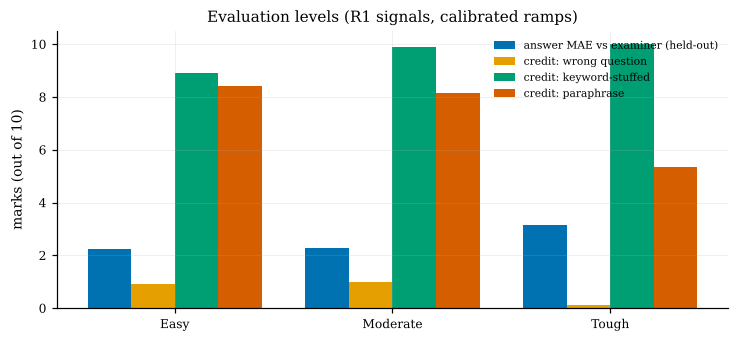

In [57]:
# ============================== 12.10 · THREE EVALUATION LEVELS: EASY / MODERATE / TOUGH ==============================
print("Keyword pools used by the three levels (examiner: check 'strong'; star terms in the scheme to override)")
KW_TABLE = annotate_keywords(questions, verbose=True)
r1_table(KW_TABLE, "t15_keyword_pools", "Keyword pools per key point: Moderate uses KEY, Tough uses strong, "
         "Easy uses KEY plus the extra content words.", show=False)

LEVEL_CFGS = {f"R1 / {lv}": best_cfg(f"R1 {lv}", make_cfg("revised", lv)) for lv in ("easy", "moderate", "tough")}
LEVEL_CFGS.update({f"submitted / {lv}": make_cfg("submitted", lv) for lv in ("easy", "moderate", "tough")})


def human_matrix():
    if H1 is None:
        return None
    h = H1[[f"human_Q{n}" for n in QNUMS]].copy(); h.columns = QNUMS
    return h.reindex(CODES)


HM = human_matrix()


def ans_level(sysm, hm, attempted_only=False):
    s, h = sysm.to_numpy().ravel(), hm.to_numpy().ravel()
    keep = ~np.isnan(h)
    if attempted_only:
        att = np.array([[(qn in (GT_ATTEMPTED.get(c) or [])) if GT_ATTEMPTED.get(c) is not None else
                         (hm.loc[c, qn] > 0) for qn in QNUMS] for c in CODES]).ravel()
        keep &= att
    return s[keep], h[keep]


level_rows, LEVEL_MATS = [], {}
for name, cfg in LEVEL_CFGS.items():
    mat = marks_matrix(M_R1, cfg)
    LEVEL_MATS[name] = mat
    row = {"level": name, "mean total /100": round(float(mat.sum(axis=1).mean()), 1)}
    if HM is not None:
        s, h = ans_level(mat, HM)
        row.update({"ramp": f"{cfg['lo']:.2f}/{cfg['hi']:.2f}",
                    "answer MAE (fit all)": round(mae(s, h), 2), "answer bias": round(float(np.mean(s - h)), 2),
                    "script MAE": round(mae(mat.sum(axis=1), HM.sum(axis=1)), 2)})
        ck = name.replace("R1 / ", "R1 ")
        if ck in CAL:
            row["answer MAE held-out (LOSO)"] = round(mae(CAL[ck]["pred_cv"], CAL[ck]["human"]), 2)
    for ctl, nz in [("wrong question", 0.0), ("keyword-stuffed wrong answer", 0.0),
                    ("keyword-stuffed wrong answer", 0.30), ("paraphrase (held-out ALT)", 0.0),
                    ("paraphrase (held-out ALT)", 0.30), ("reference answer", 0.30)]:
        d = PAIRS_DF[(PAIRS_DF["control"] == ctl) & (PAIRS_DF["noise"] == nz)].reset_index(drop=True)
        if len(d):
            row[f"{ctl}{' @CER ' + str(nz) if nz else ''}"] = round(float(np.mean(marks_vec(d, cfg))), 2)
    level_rows.append(row)
LEVELS_TABLE = r1_table(pd.DataFrame(level_rows), "t16_levels",
                        "Three evaluation levels. R1 levels use their own calibrated ramp (12.8); the submitted rows use "
                        "the published ramp. Control columns are mean marks /10: low is right for wrong answers, high "
                        "for paraphrases and noisy reference answers.")
R1_FACTS["levels"] = LEVELS_TABLE.set_index("level").to_dict("index")

tot = pd.DataFrame({name: m.sum(axis=1) for name, m in LEVEL_MATS.items() if name.startswith("R1")})
if HM is not None:
    tot.insert(0, "examiner", HM.sum(axis=1))
r1_table(tot.reset_index().rename(columns={"index": "script"}), "t17_levels_totals",
         "Script totals (/100) under each level (R1 signals), next to the examiner.")
for name, m in LEVEL_MATS.items():
    m.to_csv(f"{R1DIR}/marks_matrix_{name.replace(' / ', '_')}.csv")

fig, ax = plt.subplots(figsize=(6.6, 3.0))
lv = ["easy", "moderate", "tough"]
metrics = [("answer MAE held-out (LOSO)", "answer MAE vs examiner (held-out)"), ("wrong question", "credit: wrong question"),
           ("keyword-stuffed wrong answer", "credit: keyword-stuffed"),
           ("paraphrase (held-out ALT)", "credit: paraphrase")]
w = 0.8 / len(metrics)
for k, (col, lab) in enumerate(metrics):
    vals = [LEVELS_TABLE.set_index("level").get(col, pd.Series(dtype=float)).get(f"R1 / {l}", np.nan) for l in lv]
    ax.bar(np.arange(3) + k * w - 0.4 + w / 2, vals, w, label=lab, color=CB[k])
ax.set_xticks(range(3)); ax.set_xticklabels([l.capitalize() for l in lv]); ax.set_ylabel("marks (out of 10)")
ax.set_title("Evaluation levels (R1 signals, calibrated ramps)"); ax.legend(fontsize=7, frameon=False)
r1_fig(fig, "r1_fig6_levels", "Easy, Moderate and Tough levels: error against the examiner and credit given to "
       "wrong, keyword-stuffed and paraphrased answers.")
plt.show()

## 12.11 · Answer-level agreement (n = 50)
*R2: "the primary unit should be the answer (n = 50) … Report exact agreement and agreement within 0.5 and within 1 mark per answer, plus an agreement statistic for answer marks." "State the human marking granularity."*


[t21_answer_agreement] Answer-level agreement with the examiner (Reviewer 2: the answer, not the script total, is the unit). 95% CIs resample whole scripts (2000 cluster-bootstrap draws). 'Attempted only' removes the answers the candidate did not write, which both markers trivially score 0.


,configuration,subset,n,MAE,MAE 95% CI,bias,"exact, system rounded to whole marks %",within 0.5 %,within 1 %,within 1 95% CI,QWK (half-mark scale),QWK 95% CI,"ICC(A,1)"
0,"submitted, re-run (published ramp)",all answers,300,3.327,3.03-3.65,2.710,9.667,12.333,20.667,15-27,0.200,0.08-0.32,0.200
1,"submitted, re-run (published ramp)",attempted only,290,3.393,3.10-3.71,2.783,7.586,10.345,18.966,14-25,0.128,0.03-0.21,0.128
2,"submitted, held-out (constrained)",all answers,300,2.718,2.40-3.04,-2.355,14.000,18.333,27.333,20-35,0.183,0.08-0.27,0.183
3,"submitted, held-out (constrained)",attempted only,290,2.786,2.46-3.12,-2.421,12.069,16.552,25.862,19-32,0.149,0.04-0.24,0.150
4,"submitted, held-out (examiner only)",all answers,300,1.972,1.78-2.17,-0.042,14.000,24.667,38.667,32-45,0.268,0.10-0.39,0.269
5,"submitted, held-out (examiner only)",attempted only,290,2.009,1.80-2.23,-0.047,12.069,22.759,37.241,31-44,0.168,0.01-0.28,0.169
6,"R1 moderate, held-out (constrained)",all answers,300,2.273,2.02-2.57,-1.283,15.000,23.333,38.000,31-45,0.359,0.18-0.49,0.360
7,"R1 moderate, held-out (constrained)",attempted only,290,2.326,2.06-2.64,-1.312,13.103,21.724,36.897,30-43,0.317,0.13-0.47,0.318
8,"R1 moderate, held-out (examiner only)",all answers,300,1.962,1.79-2.15,-0.278,18.333,27.333,41.000,35-47,0.344,0.17-0.46,0.345
9,"R1 moderate, held-out (examiner only)",attempted only,290,2.002,1.81-2.22,-0.284,16.207,25.517,39.655,33-46,0.269,0.08-0.41,0.269



[t22_per_question_mae] Per-question mean absolute error. With n = 30 scripts and differences in steps of 0.5, every value is a multiple of 0.0167.


,configuration,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,mean
0,"submitted, re-run (published ramp)",4.92,4.03,3.20,3.72,3.45,3.22,2.42,3.18,2.80,2.33,3.33
1,"R1 moderate, held-out (constrained)",2.20,2.45,2.25,1.90,1.98,2.12,2.77,2.30,2.45,2.32,2.27


Granularity: examiner marks are whole marks (values used: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10); system marks are rounded to the nearest 0.5 (Eq. 24).


  saved r1_fig8_answer_agreement


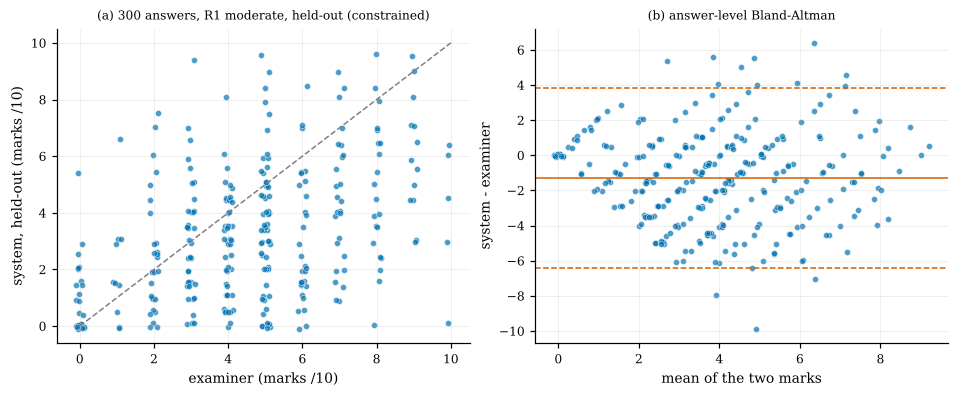

In [58]:
# ============================== 12.11 · ANSWER-LEVEL AGREEMENT (n = 50) ==============================
from scipy.stats import pearsonr, spearmanr, linregress
from sklearn.metrics import cohen_kappa_score


def _mat_from_pred(pairs, pred):
    d = pairs[["script", "q_rub"]].copy(); d["m"] = pred
    return d.pivot(index="script", columns="q_rub", values="m").reindex(index=CODES, columns=QNUMS)


def icc_a1(x, y):
    """ICC(A,1): two-way random effects, absolute agreement, single rater (Shrout & Fleiss ICC(2,1))."""
    X = np.column_stack([x, y]).astype(float); n, k = X.shape
    gm, rm, cm = X.mean(), X.mean(axis=1), X.mean(axis=0)
    msr = k * ((rm - gm) ** 2).sum() / (n - 1)
    msc = n * ((cm - gm) ** 2).sum() / (k - 1)
    mse = ((X - rm[:, None] - cm[None, :] + gm) ** 2).sum() / ((n - 1) * (k - 1))
    den = msr + (k - 1) * mse + k * (msc - mse) / n
    return float((msr - mse) / den) if den > 0 else np.nan


def qwk(a, b, step=0.5, top=10.0):
    ia, ib = np.round(np.asarray(a) / step).astype(int), np.round(np.asarray(b) / step).astype(int)
    try:
        return float(cohen_kappa_score(ib, ia, weights="quadratic", labels=list(range(int(top / step) + 1))))
    except Exception:
        return np.nan


def answer_stats(s, h):
    s, h = np.asarray(s, float), np.asarray(h, float)
    d = s - h
    whole = np.floor(s + 0.5)
    return {"n": len(h), "MAE": mae(s, h), "RMSE": float(np.sqrt(np.mean(d ** 2))), "bias": float(d.mean()),
            "LoA lower": float(d.mean() - 1.96 * d.std(ddof=1)), "LoA upper": float(d.mean() + 1.96 * d.std(ddof=1)),
            "exact %": 100 * float(np.mean(np.abs(d) < 1e-9)),
            "exact, system rounded to whole marks %": 100 * float(np.mean(np.abs(whole - h) < 1e-9)),
            "within 0.5 %": 100 * float(np.mean(np.abs(d) <= 0.5)), "within 1 %": 100 * float(np.mean(np.abs(d) <= 1)),
            "within 2 %": 100 * float(np.mean(np.abs(d) <= 2)),
            "Pearson r": float(pearsonr(s, h)[0]) if np.std(s) > 0 and np.std(h) > 0 else np.nan,
            "Spearman rho": float(spearmanr(s, h)[0]) if np.std(s) > 0 and np.std(h) > 0 else np.nan,
            "QWK (half-mark scale)": qwk(s, h), "ICC(A,1)": icc_a1(s, h)}


def cluster_ci(s, h, groups, fn, B=None, seed=None):
    """95% percentile CI by resampling whole scripts (answers within a script are not independent)."""
    B = B or EVAL["BOOTSTRAP_B"]
    r = np.random.default_rng(EVAL["SEED"] if seed is None else seed)
    g = np.asarray(groups); ug = np.unique(g); idx = {u: np.where(g == u)[0] for u in ug}
    vals = []
    for _ in range(B):
        pick = np.concatenate([idx[u] for u in r.choice(ug, len(ug), replace=True)])
        try:
            v = fn(s[pick], h[pick])
        except Exception:
            v = np.nan
        vals.append(v)
    vals = np.array(vals, float)
    return (float(np.nanpercentile(vals, 2.5)), float(np.nanpercentile(vals, 97.5))) if np.isfinite(vals).any() else (np.nan, np.nan)


PRED = {}
if HM is not None:
    if PAPER_MARKS:
        PRED["as published (paper Table 2)"] = pd.DataFrame.from_dict(PAPER_MARKS, orient="index",
                                                                      columns=QNUMS).reindex(CODES)
    PRED["submitted, re-run (published ramp)"] = SYS_SUB
    for key, lab in (("submitted", "submitted"), ("R1 moderate", "R1 moderate"), ("R1 easy", "R1 easy"),
                     ("R1 tough", "R1 tough")):
        if key in CAL:
            PRED[f"{lab}, held-out ({EVAL['CAL_OBJECTIVE']})"] = _mat_from_pred(CAL[key]["pairs"], CAL[key]["pred_cv"])
        if key in CAL_ALT and key in ("submitted", "R1 moderate"):
            PRED[f"{lab}, held-out (examiner only)"] = _mat_from_pred(CAL_ALT[key]["pairs"], CAL_ALT[key]["pred_cv"])
    for bname, p in BASE_PRED.items():
        PRED[f"baseline: {bname}"] = _mat_from_pred(M_R1, p)
    PRIMARY = f"R1 moderate, held-out ({EVAL['CAL_OBJECTIVE']})"
    # LOCAL RUN: scripts not in the paper have no published marks; the submitted system re-run on them stands in
    PUB_KEY = next((k for k in PRED if k.startswith("as published")), None) or \
        ("submitted, re-run (published ramp)" if "submitted, re-run (published ramp)" in PRED else None)
    PUB_LABEL = "system as published" if (PUB_KEY or "").startswith("as published") else "submitted system (re-run)"

    grp = np.repeat(np.array(CODES), len(QNUMS))
    rows = []
    for name, mat in PRED.items():
        for subset in ("all answers", "attempted only"):
            s, h = ans_level(mat, HM, attempted_only=(subset == "attempted only"))
            g = grp[~np.isnan(HM.to_numpy().ravel())]
            if subset == "attempted only":
                att = np.array([[(qn in (GT_ATTEMPTED.get(c) or [])) if GT_ATTEMPTED.get(c) is not None
                                 else HM.loc[c, qn] > 0 for qn in QNUMS] for c in CODES]).ravel()
                g = grp[att & ~np.isnan(HM.to_numpy().ravel())]
            st = answer_stats(s, h)
            lo_, hi_ = cluster_ci(s, h, g, mae)
            q_lo, q_hi = cluster_ci(s, h, g, qwk)
            w_lo, w_hi = cluster_ci(s, h, g, lambda a, b: 100 * np.mean(np.abs(a - b) <= 1))
            rows.append({"configuration": name, "subset": subset, **{k: (round(v, 3) if isinstance(v, float) else v)
                                                                     for k, v in st.items()},
                         "MAE 95% CI": f"{lo_:.2f}-{hi_:.2f}", "QWK 95% CI": f"{q_lo:.2f}-{q_hi:.2f}",
                         "within 1 95% CI": f"{w_lo:.0f}-{w_hi:.0f}"})
    ANS_AGREE = pd.DataFrame(rows)
    show_cols = ["configuration", "subset", "n", "MAE", "MAE 95% CI", "bias", "exact, system rounded to whole marks %",
                 "within 0.5 %", "within 1 %", "within 1 95% CI", "QWK (half-mark scale)", "QWK 95% CI", "ICC(A,1)"]
    r1_table(ANS_AGREE[show_cols], "t21_answer_agreement",
             "Answer-level agreement with the examiner (Reviewer 2: the answer, not the script total, is the unit). "
             "95% CIs resample whole scripts (2000 cluster-bootstrap draws). 'Attempted only' removes the answers "
             "the candidate did not write, which both markers trivially score 0.")
    r1_table(ANS_AGREE, "t21b_answer_agreement_full", "Answer-level agreement, all statistics.", show=False)
    R1_FACTS["answer agreement"] = ANS_AGREE[show_cols].to_dict("records")

    # per-question MAE, computed directly (Reviewer 2: granularity)
    pq = {name: (mat - HM).abs().mean(axis=0).round(2) for name, mat in PRED.items()
          if name.startswith(("as published", "submitted, re-run", PRIMARY))}
    PQ = pd.DataFrame(pq).T
    PQ.columns = [f"Q{c}" for c in PQ.columns]
    PQ["mean"] = PQ.mean(axis=1).round(2)
    r1_table(PQ.reset_index().rename(columns={"index": "configuration"}), "t22_per_question_mae",
             f"Per-question mean absolute error. With n = {len(CODES)} scripts and differences in steps of 0.5, every "
             f"value is a multiple of {0.5 / len(CODES):.3g}.")
    hv = np.unique(HM.to_numpy()[~np.isnan(HM.to_numpy())])
    gran_h = "whole marks" if np.allclose(hv, np.round(hv)) else "half marks" if np.allclose(hv * 2, np.round(hv * 2)) else "finer"
    print(f"Granularity: examiner marks are {gran_h} (values used: {', '.join(f'{v:g}' for v in hv)}); "
          f"system marks are rounded to the nearest 0.5 (Eq. 24).")
    R1_FACTS["granularity"] = {"examiner": gran_h, "system": "half marks",
                               "per-question MAE as published": PQ.iloc[0].to_dict() if len(PQ) else {}}

    s, h = ans_level(PRED[PRIMARY], HM)
    jit = np.random.default_rng(1).uniform(-.12, .12, (2, len(s)))
    fig, ax = plt.subplots(1, 2, figsize=(8.6, 3.5))
    ax[0].scatter(h + jit[0], s + jit[1], s=16, alpha=.7, color=CB[0], edgecolor="white", lw=.4)
    ax[0].plot([0, 10], [0, 10], "--", color="0.5", lw=1)
    ax[0].set_xlabel("examiner (marks /10)"); ax[0].set_ylabel("system, held-out (marks /10)")
    ax[0].set_title(f"(a) {len(s)} answers, {PRIMARY}", fontsize=8)
    d = s - h; mn = (s + h) / 2
    ax[1].scatter(mn + jit[0], d + jit[1], s=16, alpha=.7, color=CB[0], edgecolor="white", lw=.4)
    for v, ls in ((d.mean(), "-"), (d.mean() + 1.96 * d.std(ddof=1), "--"), (d.mean() - 1.96 * d.std(ddof=1), "--")):
        ax[1].axhline(v, color=CB[3], ls=ls, lw=1)
    ax[1].set_xlabel("mean of the two marks"); ax[1].set_ylabel("system - examiner")
    ax[1].set_title("(b) answer-level Bland-Altman", fontsize=8)
    r1_fig(fig, "r1_fig8_answer_agreement", "Answer-level agreement for the held-out R1 system (points jittered).")
    plt.show()
else:
    print("No examiner marks - agreement sections skipped.")

## 12.12 · Script-level agreement, grade changes, sensitivity
*R2: "Weighted κ is driven by the one failing script"; "Fig. 12 shows one script marked A by the examiner and B by the system. That is a downgrade"; "the fitted intercept is 5.0". R3: "High correlation does not establish grading agreement."*

In [59]:
# ============================== 12.12 · SCRIPT-LEVEL AGREEMENT, GRADE CHANGES, SENSITIVITY ==============================
from scipy.stats import t as _t


def band_index(total, maxm):
    return BAND_ORDER.index(grade_of(100 * total / maxm))


def script_stats(s, h, maxm=None):
    s, h = np.asarray(s, float), np.asarray(h, float)
    maxm = maxm or float(sum(MAXQ.values()))
    d = s - h; n = len(h)
    sd = d.std(ddof=1) if n > 1 else np.nan
    se_loa = sd * np.sqrt(3.0 / n) if n > 1 else np.nan          # Bland & Altman (1999)
    tq = _t.ppf(0.975, n - 1) if n > 1 else np.nan
    hb, sb = [band_index(v, maxm) for v in h], [band_index(v, maxm) for v in s]
    try:
        kw = float(cohen_kappa_score(hb, sb, weights="quadratic", labels=list(range(len(BAND_ORDER)))))
    except Exception:
        kw = np.nan
    lr = linregress(h, s) if n > 2 and np.std(h) > 0 else None
    pb = linregress((s + h) / 2, d) if n > 2 and np.std(s + h) > 0 else None
    ss_tot = ((h - h.mean()) ** 2).sum()
    return {"n": n, "MAE": mae(s, h), "RMSE": float(np.sqrt(np.mean(d ** 2))),
            "R2": float(1 - ((h - s) ** 2).sum() / ss_tot) if ss_tot > 0 else np.nan,
            "Pearson r": float(pearsonr(s, h)[0]) if n > 2 and np.std(s) > 0 else np.nan,
            "bias": float(d.mean()), "LoA lower": float(d.mean() - 1.96 * sd), "LoA upper": float(d.mean() + 1.96 * sd),
            "LoA lower 95% CI": f"{d.mean() - 1.96 * sd - tq * se_loa:.1f} to {d.mean() - 1.96 * sd + tq * se_loa:.1f}",
            "LoA upper 95% CI": f"{d.mean() + 1.96 * sd - tq * se_loa:.1f} to {d.mean() + 1.96 * sd + tq * se_loa:.1f}",
            "exact band %": 100 * float(np.mean(np.array(hb) == np.array(sb))), "QWK (bands)": kw,
            "slope": float(lr.slope) if lr else np.nan, "intercept": float(lr.intercept) if lr else np.nan,
            "intercept SE": float(lr.intercept_stderr) if lr else np.nan,
            "proportional bias slope": float(pb.slope) if pb else np.nan,
            "proportional bias p": float(pb.pvalue) if pb else np.nan}


if HM is not None:
    HT = HM.sum(axis=1)
    rows, changes = [], []
    for name, mat in PRED.items():
        st = script_stats(mat.sum(axis=1).to_numpy(), HT.to_numpy())
        rows.append({"configuration": name, **{k: (round(v, 3) if isinstance(v, float) else v) for k, v in st.items()}})
    SCRIPT_AGREE = pd.DataFrame(rows)
    r1_table(SCRIPT_AGREE, "t23_script_agreement",
             f"Script-level agreement (totals /100, n = {len(CODES)}). The limits of agreement carry their own 95% CI "
             f"(Bland & Altman 1999), which is the honest statement of how imprecise {len(CODES)} scripts are.")
    R1_FACTS["script agreement"] = SCRIPT_AGREE.set_index("configuration").to_dict("index")

    # sensitivity: drop the script with the lowest examiner total (Reviewer 2: kappa driven by one script)
    low = HT.idxmin()
    keep = [c for c in CODES if c != low]
    sens = []
    for name, mat in PRED.items():
        full = script_stats(mat.sum(axis=1).to_numpy(), HT.to_numpy())
        red = script_stats(mat.loc[keep].sum(axis=1).to_numpy(), HT.loc[keep].to_numpy())
        sens.append({"configuration": name, "QWK all 5": round(full["QWK (bands)"], 3),
                     f"QWK without {low}": round(red["QWK (bands)"], 3),
                     "r all 5": round(full["Pearson r"], 3), f"r without {low}": round(red["Pearson r"], 3),
                     "MAE all 5": round(full["MAE"], 2), f"MAE without {low}": round(red["MAE"], 2)})
    r1_table(pd.DataFrame(sens), "t24_kappa_sensitivity",
             f"Sensitivity of the script-level statistics to the one failing script ({low}, which attempted only "
             f"{len(GT_ATTEMPTED.get(low) or [])} questions).")
    R1_FACTS["kappa sensitivity"] = pd.DataFrame(sens).to_dict("records")

    # leave-one-script-out influence on the published numbers
    pub = PUB_KEY                                     # LOCAL RUN: falls back to the submitted system re-run
    if pub:
        infl = []
        for c in CODES:
            kk = [x for x in CODES if x != c]
            st = script_stats(PRED[pub].loc[kk].sum(axis=1).to_numpy(), HT.loc[kk].to_numpy())
            infl.append({"script removed": c, "MAE": round(st["MAE"], 2), "r": round(st["Pearson r"], 3),
                         "QWK": round(st["QWK (bands)"], 3), "LoA": f"{st['LoA lower']:.1f} to {st['LoA upper']:.1f}"})
        r1_table(pd.DataFrame(infl), "t25_influence", f"Script-level statistics of the {PUB_LABEL} with each script removed in turn.")

    # direction of every grade change (Reviewer 2: 'no candidate was moved down' is incorrect)
    maxm = float(sum(MAXQ.values()))
    for name in [k for k in PRED if k.startswith(("as published", PRIMARY)) or k == pub]:
        tot_s = PRED[name].sum(axis=1)
        for c in CODES:
            hg, sg = grade_of(100 * HT[c] / maxm), grade_of(100 * tot_s[c] / maxm)
            mv = BAND_ORDER.index(sg) - BAND_ORDER.index(hg)
            changes.append({"configuration": name, "script": c, "examiner total": HT[c], "examiner grade": hg,
                            "system total": tot_s[c], "system grade": sg, "difference": tot_s[c] - HT[c],
                            "grade moved": "up" if mv > 0 else "down" if mv < 0 else "same",
                            "pass/fail changed": (HT[c] >= PASS_PCT * maxm / 100) != (tot_s[c] >= PASS_PCT * maxm / 100)})
    GC = pd.DataFrame(changes)
    r1_table(GC, "t26_grade_changes", "Every grade change and its direction.")
    for name, d in GC.groupby("configuration"):
        up, down = int((d["grade moved"] == "up").sum()), int((d["grade moved"] == "down").sum())
        over = d.loc[d["difference"] > 0, "script"].tolist(); under = d.loc[d["difference"] < 0, "script"].tolist()
        print(f"{name}: {up} grade(s) moved up, {down} moved down; over-marked {over}, under-marked {under}.")
        R1_FACTS.setdefault("grade changes", {})[name] = {"up": up, "down": down, "over": over, "under": under}
    if pub:
        st = SCRIPT_AGREE.set_index("configuration").loc[pub]
        print(f"Regression of system on examiner ({PUB_LABEL}): system = {st['slope']:.2f} x examiner "
              f"{st['intercept']:+.1f}  (intercept SE {st['intercept SE']:.1f}); proportional-bias slope "
              f"{st['proportional bias slope']:+.3f} (p = {st['proportional bias p']:.2f}).")


[t23_script_agreement] Script-level agreement (totals /100, n = 30). The limits of agreement carry their own 95% CI (Bland & Altman 1999), which is the honest statement of how imprecise 30 scripts are.


,configuration,n,MAE,RMSE,R2,Pearson r,bias,LoA lower,LoA upper,LoA lower 95% CI,LoA upper 95% CI,exact band %,QWK (bands),slope,intercept,intercept SE,proportional bias slope,proportional bias p
0,"submitted, re-run (published ramp)",30,28.367,30.760,-2.235,0.633,27.100,-1.910,56.110,-11.5 to 7.7,46.5 to 65.7,10.000,0.250,0.626,44.114,7.009,-0.016,0.932
1,"submitted, held-out (constrained)",30,23.917,26.187,-1.344,0.773,-23.550,-46.382,-0.718,-53.9 to -38.8,-8.3 to 6.8,23.333,0.215,0.432,2.261,3.253,-0.632,0.000
2,"submitted, held-out (examiner only)",30,11.417,14.149,0.316,0.568,-0.417,-28.610,27.777,-37.9 to -19.3,18.5 to 37.1,40.000,0.441,0.367,28.331,4.884,-0.540,0.007
3,"R1 moderate, held-out (constrained)",30,13.200,16.552,0.063,0.806,-12.833,-33.674,8.007,-40.6 to -26.8,1.1 to 14.9,33.333,0.677,0.772,-2.470,5.203,-0.048,0.703
4,"R1 moderate, held-out (examiner only)",30,10.583,13.375,0.388,0.658,-2.783,-28.863,23.296,-37.5 to -20.3,14.7 to 31.9,40.000,0.666,0.520,19.007,5.467,-0.281,0.108
5,"R1 easy, held-out (constrained)",30,12.017,15.658,0.162,0.803,-11.217,-32.995,10.561,-40.2 to -25.8,3.4 to 17.7,43.333,0.781,0.828,-3.413,5.644,0.035,0.784
6,"R1 tough, held-out (constrained)",30,25.750,27.665,-1.616,0.812,-25.750,-45.909,-5.591,-52.6 to -39.3,-12.2 to 1.1,23.333,0.143,0.580,-6.670,3.819,-0.367,0.004
7,baseline: attempted -> constant,30,12.917,17.362,-0.030,0.216,-2.817,-36.969,31.335,-48.2 to -25.7,20.1 to 42.6,40.000,0.025,0.095,38.299,3.939,-1.166,0.000
8,baseline: attempted -> f(log length),30,12.900,17.191,-0.010,0.230,-1.567,-35.694,32.560,-47.0 to -24.4,21.3 to 43.8,43.333,0.047,0.106,39.038,4.135,-1.101,0.000



[t24_kappa_sensitivity] Sensitivity of the script-level statistics to the one failing script (S21.pdf, which attempted only 10 questions).


,configuration,QWK all 5,QWK without S21.pdf,r all 5,r without S21.pdf,MAE all 5,MAE without S21.pdf
0,"submitted, re-run (published ramp)",0.250,0.240,0.633,0.633,28.37,27.53
1,"submitted, held-out (constrained)",0.215,0.212,0.773,0.771,23.92,24.55
2,"submitted, held-out (examiner only)",0.441,0.443,0.568,0.568,11.42,10.72
3,"R1 moderate, held-out (constrained)",0.677,0.671,0.806,0.792,13.20,13.55
4,"R1 moderate, held-out (examiner only)",0.666,0.651,0.658,0.635,10.58,10.24
5,"R1 easy, held-out (constrained)",0.781,0.775,0.803,0.791,12.02,12.31
6,"R1 tough, held-out (constrained)",0.143,0.142,0.812,0.802,25.75,26.53
7,baseline: attempted -> constant,0.025,0.029,0.216,0.270,12.92,11.98
8,baseline: attempted -> f(log length),0.047,0.049,0.230,0.234,12.90,12.07



[t25_influence] Script-level statistics of the submitted system (re-run) with each script removed in turn.


,script removed,MAE,r,QWK,LoA
0,S01.pdf,28.19,0.630,0.254,-2.5 to 56.3
1,S02.pdf,28.98,0.607,0.208,-1.2 to 56.5
2,S03.pdf,28.24,0.634,0.258,-2.5 to 56.4
3,S04.pdf,28.17,0.636,0.258,-2.5 to 56.3
4,S05.pdf,28.52,0.617,0.239,-2.3 to 56.7
5,S06.pdf,27.83,0.646,0.265,-2.3 to 55.3
6,S07.pdf,28.12,0.637,0.258,-2.5 to 56.2
7,S08.pdf,28.69,0.635,0.253,-2.0 to 56.7
8,S09.pdf,28.26,0.627,0.254,-2.5 to 56.4
9,S10.pdf,28.21,0.635,0.258,-2.5 to 56.3



[t26_grade_changes] Every grade change and its direction.


,configuration,script,examiner total,examiner grade,system total,system grade,difference,grade moved,pass/fail changed
0,"submitted, re-run (published ramp)",S01.pdf,53,D,86.5,A,33.5,up,False
1,"submitted, re-run (published ramp)",S02.pdf,83,A,93.5,O,10.5,up,False
2,"submitted, re-run (published ramp)",S03.pdf,46,E,78.0,B,32.0,up,False
3,"submitted, re-run (published ramp)",S04.pdf,40,E,74.0,B,34.0,up,False
4,"submitted, re-run (published ramp)",S05.pdf,66,C,90.0,O,24.0,up,False
5,"submitted, re-run (published ramp)",S06.pdf,31,F,75.0,B,44.0,up,True
6,"submitted, re-run (published ramp)",S07.pdf,41,E,76.5,B,35.5,up,False
7,"submitted, re-run (published ramp)",S08.pdf,55,D,74.0,B,19.0,up,False
8,"submitted, re-run (published ramp)",S09.pdf,56,D,87.5,A,31.5,up,False
9,"submitted, re-run (published ramp)",S10.pdf,43,E,76.0,B,33.0,up,False


R1 moderate, held-out (constrained): 0 grade(s) moved up, 20 moved down; over-marked ['S12.pdf', 'S21.pdf'], under-marked ['S01.pdf', 'S02.pdf', 'S03.pdf', 'S04.pdf', 'S05.pdf', 'S06.pdf', 'S07.pdf', 'S08.pdf', 'S09.pdf', 'S10.pdf', 'S11.pdf', 'S13.pdf', 'S14.pdf', 'S15.pdf', 'S16.pdf', 'S17.pdf', 'S18.pdf', 'S19.pdf', 'S20.pdf', 'S22.pdf', 'S23.pdf', 'S24.pdf', 'S25.pdf', 'S26.pdf', 'S27.pdf', 'S28.pdf', 'S29.pdf', 'S30.pdf'].
submitted, re-run (published ramp): 27 grade(s) moved up, 0 moved down; over-marked ['S01.pdf', 'S02.pdf', 'S03.pdf', 'S04.pdf', 'S05.pdf', 'S06.pdf', 'S07.pdf', 'S08.pdf', 'S09.pdf', 'S10.pdf', 'S11.pdf', 'S12.pdf', 'S13.pdf', 'S14.pdf', 'S15.pdf', 'S16.pdf', 'S17.pdf', 'S18.pdf', 'S19.pdf', 'S20.pdf', 'S21.pdf', 'S22.pdf', 'S24.pdf', 'S25.pdf', 'S26.pdf', 'S27.pdf', 'S28.pdf'], under-marked ['S23.pdf', 'S29.pdf', 'S30.pdf'].
Regression of system on examiner (submitted system (re-run)): system = 0.63 x examiner +44.1  (intercept SE 7.0); proportional-bias slope

## 12.13 · Scoring ablation: single signals vs the ensemble
*R1: "single signals versus ensemble".*

In [60]:
# ============================== 12.13 · SCORING ABLATION: SINGLE SIGNALS vs ENSEMBLE ==============================
ABLATION = {
    "A1 semantic only":                   make_cfg("revised", "moderate", blend="sem"),
    "A2 lexical only (submitted)":        make_cfg("revised", "moderate", blend="lex", lex="pts"),
    "A3 lexical only (R1)":               make_cfg("revised", "moderate", blend="lex"),
    "A4 anchors only (R1, KEY terms)":    make_cfg("revised", "moderate", blend="anchor"),
    "A5 semantic + lexical (R1), no anchors/gate": make_cfg("revised", "moderate", blend="semlex"),
    "A6 full ensemble, submitted signals": make_cfg("submitted", "moderate"),
    "A7 full ensemble, R1 signals":       make_cfg("revised", "moderate"),
}
if H1 is not None:
    rows = []
    _w = CAL_OBJECTIVES[EVAL["CAL_OBJECTIVE"]]
    ctl = {k: PAIRS_DF[(PAIRS_DF["control"] == k) & (PAIRS_DF["noise"] == 0)].reset_index(drop=True)
           for k in ("random OCR words", "keyword-stuffed wrong answer", "paraphrase (held-out ALT)")}
    for name, cfg in ABLATION.items():
        cc = calibrate(M_R1, cfg, name, _w)
        ce = calibrate(M_R1, cfg, name, None)
        row = {"variant": name,
               f"held-out MAE ({EVAL['CAL_OBJECTIVE']})": round(mae(cc["pred_cv"], cc["human"]), 3),
               "held-out MAE (examiner only)": round(mae(ce["pred_cv"], ce["human"]), 3),
               "held-out QWK": round(qwk(cc["pred_cv"], cc["human"]), 3),
               "ramp": f"{cc['final']['lo']:.2f}/{cc['final']['hi']:.2f}",
               "wrong-question credit": round(float(np.mean(marks_vec(WRONG_R1, cc["final"]))), 2)}
        for k, d in ctl.items():
            row[f"{k} credit"] = round(float(np.mean(marks_vec(d, cc["final"]))), 2)
        rows.append(row)
    for bname, p in BASE_PRED.items():
        rows.append({"variant": f"baseline: {bname}", "held-out MAE (examiner only)": round(mae(p, _human_vec(M_R1)), 3),
                     "held-out QWK": round(qwk(p, _human_vec(M_R1)), 3)})
    ABL = r1_table(pd.DataFrame(rows), "t27_scoring_ablation",
                   "Scoring ablation on the R1 localisation. Every variant gets its own held-out ramp (LOSO). Credit "
                   "columns are mean marks /10 on controls under the final ramp (lower is better except paraphrase).")
    R1_FACTS["scoring ablation"] = ABL.to_dict("records")


[t27_scoring_ablation] Scoring ablation on the R1 localisation. Every variant gets its own held-out ramp (LOSO). Credit columns are mean marks /10 on controls under the final ramp (lower is better except paraphrase).


,variant,held-out MAE (constrained),held-out MAE (examiner only),held-out QWK,ramp,wrong-question credit,random OCR words credit,keyword-stuffed wrong answer credit,paraphrase (held-out ALT) credit
0,A1 semantic only,2.852,1.957,0.193,0.28/0.58,0.99,1.03,8.30,9.15
1,A2 lexical only (submitted),4.875,4.878,0.075,0.50/0.90,9.27,9.47,10.00,10.00
2,A3 lexical only (R1),2.327,2.123,0.350,0.08/0.56,0.98,1.01,9.07,6.80
3,"A4 anchors only (R1, KEY terms)",2.557,2.557,0.339,0.00/0.42,0.53,0.58,10.00,7.95
4,"A5 semantic + lexical (R1), no anchors/gate",2.385,1.898,0.348,0.18/0.54,0.99,1.05,9.43,8.80
5,"A6 full ensemble, submitted signals",2.657,1.960,0.196,0.50/0.90,1.04,1.14,7.18,6.95
6,"A7 full ensemble, R1 signals",2.273,1.962,0.359,0.14/0.56,0.97,1.04,9.90,8.15
7,baseline: attempted -> constant,NaN,1.968,0.114,NaN,NaN,NaN,NaN,NaN
8,baseline: attempted -> f(log length),NaN,1.973,0.127,NaN,NaN,NaN,NaN,NaN


## 12.14 · Modern HTR comparator (TrOCR) and optional vision-LLM
*R1: "a modern HTR or vision-LLM comparator".*

In [61]:
# ============================== 12.14 · MODERN HTR COMPARATOR (TrOCR) AND OPTIONAL VISION-LLM ==============================
# Reviewer 1: "a modern HTR or vision-LLM comparator". TrOCR reads the SAME line boxes Tesseract found, so only the
# recogniser changes: red anchors, assignment and scoring are identical. It runs locally (open weights).
HTR = {}


def _htr_lines(code, proc, model, dev, mname, bs):
    rec = REC[code]
    disk = f"{CACHE_DIR}/htr_{rec['sha']}_{mname.split('/')[-1]}.json"
    if os.path.exists(disk):
        return json.load(open(disk))
    import torch
    out = []
    for p in rec["pages"]:
        pil = convert_from_path(f"{SCRIPTS_DIR}/{code}", dpi=rec["dpi"], first_page=p["page"],
                                last_page=p["page"])[0].convert("RGB")
        W, H = pil.size
        L = [l for l in rec["lines"] if l["page"] == p["page"]]
        crops = [pil.crop((max(0, l["x0"] - 8), max(0, l["y"] - 6), min(W, l["x1"] + 8), min(H, l["y1"] + 6)))
                 for l in L]
        for i in range(0, len(crops), bs):
            pv = proc(images=crops[i:i + bs], return_tensors="pt").pixel_values.to(dev)
            with torch.no_grad():
                ids = model.generate(pv, max_new_tokens=64)
            out += proc.batch_decode(ids, skip_special_tokens=True)
    json.dump(out, open(disk, "w"))
    return out


if EVAL["RUN_HTR"]:
    try:
        import torch
        from transformers import TrOCRProcessor, VisionEncoderDecoderModel
        _cuda = torch.cuda.is_available()
        mname = EVAL["HTR_MODEL"] or ("microsoft/trocr-base-handwritten" if _cuda
                                      else "microsoft/trocr-small-handwritten")
        dev = "cuda" if _cuda else "cpu"
        print(f"TrOCR comparator: {mname} on {dev} (runs locally; nothing leaves this machine)")
        _proc = TrOCRProcessor.from_pretrained(mname)
        _model = VisionEncoderDecoderModel.from_pretrained(mname).to(dev).eval()
        t0 = time.time()
        for c in CODES:
            t1 = time.time()
            HTR[c] = _htr_lines(c, _proc, _model, dev, mname, 32 if _cuda else 8)
            print(f"  {c}: {len(HTR[c])} lines in {time.time() - t1:.0f}s")
        ENV["HTR model"] = mname
        R1_FACTS["htr seconds"] = round(time.time() - t0, 1)
    except Exception as ex:
        print("TrOCR comparator skipped:", type(ex).__name__, str(ex)[:200])
        HTR = {}

if HTR:
    def htr_script_lines(c):
        base = script_lines(REC[c], "v2")
        return [b if b == "[header redacted]" else _ID_PATTERNS[0].sub("[ID]", t) for b, t in zip(base, HTR[c])]

    loc_rows, htr_pairs = [], []
    for c in CODES:
        Lh = htr_script_lines(c)
        res = segment_by_red_v2(Lh, REC[c]["anchors_v2"], questions) or textonly_with_ranges(Lh, questions)
        if GT_LINES[c] is not None:
            loc_rows += loc_metrics(c, res)
        for qn in QNUMS:
            PAIRS.append({"control": "matched (TrOCR)", "script": c, "q_ans": qn, "q_rub": qn, "noise": 0.0,
                          "holdout": False, "loc": "TrOCR", "key": sig_for(res[qn]["text"], QBYNUM[qn]),
                          "words": len(canon(res[qn]["text"]).split())})
    _htr_ans = {}
    for c in CODES:
        Lh = htr_script_lines(c)
        res = segment_by_red_v2(Lh, REC[c]["anchors_v2"], questions) or textonly_with_ranges(Lh, questions)
        for qn in QNUMS:
            _htr_ans[(c, qn)] = res[qn]["text"]
    for (c, qn), t in _htr_ans.items():
        if len(canon(t).split()) >= CONFIG["MIN_WORDS"]:
            for q2 in QNUMS:
                if q2 != qn:
                    PAIRS.append({"control": "wrong question (TrOCR)", "script": c, "q_ans": qn, "q_rub": q2,
                                  "noise": 0.0, "holdout": False, "loc": "TrOCR", "key": sig_for(t, QBYNUM[q2]),
                                  "words": len(canon(t).split())})
    PAIRS_DF = pd.DataFrame(PAIRS)
    M_HTR = PAIRS_DF[PAIRS_DF["control"] == "matched (TrOCR)"].reset_index(drop=True)
    W_HTR = PAIRS_DF[PAIRS_DF["control"] == "wrong question (TrOCR)"].reset_index(drop=True)
    rows = []
    if loc_rows:
        lt = summarise_loc(loc_rows)
        rows.append({"recogniser": "TrOCR", "localisation word F1": round(lt["word F1"], 3)})
        rows.append({"recogniser": "Tesseract", "localisation word F1": round(LOC_TABLE.loc[LOC_REVISED, "word F1"], 3)})
    if H1 is not None:
        cal_h = calibrate(M_HTR, CFG_R1, "R1 moderate (TrOCR)", CAL_OBJECTIVES[EVAL["CAL_OBJECTIVE"]],
                          controls=W_HTR)
        for r in rows:
            if r["recogniser"] == "TrOCR":
                r.update({"answer MAE held-out": round(mae(cal_h["pred_cv"], cal_h["human"]), 3),
                          "answer QWK held-out": round(qwk(cal_h["pred_cv"], cal_h["human"]), 3),
                          "script MAE held-out": round(mae(_mat_from_pred(M_HTR, cal_h["pred_cv"]).sum(axis=1), HT), 2),
                          "wrong-question credit": round(float(np.mean(marks_vec(W_HTR, cal_h["final"]))), 2)})
            else:
                r.update({"answer MAE held-out": round(mae(CAL_R1["pred_cv"], CAL_R1["human"]), 3),
                          "answer QWK held-out": round(qwk(CAL_R1["pred_cv"], CAL_R1["human"]), 3),
                          "script MAE held-out": round(mae(PRED[PRIMARY].sum(axis=1), HT), 2),
                          "wrong-question credit": round(float(np.mean(marks_vec(WRONG_R1, CAL_R1["final"]))), 2)})
        CAL["R1 moderate (TrOCR)"] = cal_h
    HTR_TABLE = r1_table(pd.DataFrame(rows), "t28_htr_comparator",
                         "Same pipeline with a modern handwriting recogniser (TrOCR) in place of Tesseract.")
    R1_FACTS["htr"] = HTR_TABLE.to_dict("records")
    if len(glob.glob(f"{TRANSCRIPT_DIR}/*.txt")):
        def _htr_page(c, p):
            return "\n".join(t for t, l in zip(htr_script_lines(c), REC[c]["lines"])
                             if l["page"] == p and t != "[header redacted]")
        OCR_ERR = ocr_error_table({"TrOCR": _htr_page})
        if len(OCR_ERR):
            r1_table(OCR_ERR.round(3), "t08_ocr_error_rate",
                     "Measured recognition error against manual transcription: Tesseract and TrOCR.")

# ---- optional vision-LLM comparator: sends page images to an external API (privacy!) -----------------------
if EVAL["RUN_VLM"]:
    print("Vision-LLM comparator: page images of every script are sent to", CONFIG["LLM_MODEL"])
    try:
        vrows = []
        for c in CODES:
            pages = convert_from_path(f"{SCRIPTS_DIR}/{c}", dpi=CONFIG["DPI"])
            txt, _ = ocr_llm(pages, CONFIG["LLM_MODEL"], CONFIG["MAX_PAGE_PIXELS"])
            segs = segment_answers_textonly(txt, questions)
            for qn in QNUMS:
                k = sig_for(segs[qn]["text"], QBYNUM[qn])
                vrows.append({"control": "matched (VLM)", "script": c, "q_ans": qn, "q_rub": qn, "noise": 0.0,
                              "holdout": False, "loc": "VLM", "key": k, "words": len(canon(segs[qn]["text"]).split())})
        M_VLM = pd.DataFrame(vrows)
        if H1 is not None:
            cv = calibrate(M_VLM, CFG_R1, "R1 moderate (VLM transcription)", CAL_OBJECTIVES[EVAL["CAL_OBJECTIVE"]])
            print(f"VLM transcription + R1 scoring: held-out answer MAE {mae(cv['pred_cv'], cv['human']):.2f}")
    except Exception as ex:
        print("VLM comparator failed:", type(ex).__name__, str(ex)[:200])
else:
    print("Vision-LLM comparator off (EVAL['RUN_VLM'] = False): it would send student scripts to an external service.")

Vision-LLM comparator off (EVAL['RUN_VLM'] = False): it would send student scripts to an external service.


## 12.15 · Review triage, workload, fairness, examiner consistency
*R3: "Add evidence about teacher workload, review decisions, grading fairness, and consistency between human examiners." R2: "Use two independent examiners."*


[t29_triage] Review triage with the existing flag rule (BORDERLINE_REVIEW, VERY_SHORT, NOT_ATTEMPTED, low locate confidence). 'After review' assumes the examiner replaces each flagged mark with their own.


,value
answers,300.00
flagged for review,129.00
"flagged, excluding blank answers",111.00
MAE of flagged answers,1.86
MAE of unflagged answers,2.58
errors >= 2 marks,157.00
of which flagged,54.00
answer MAE before review,2.27
answer MAE after examiner corrects flagged answers,1.47


  saved r1_fig9_triage_fairness


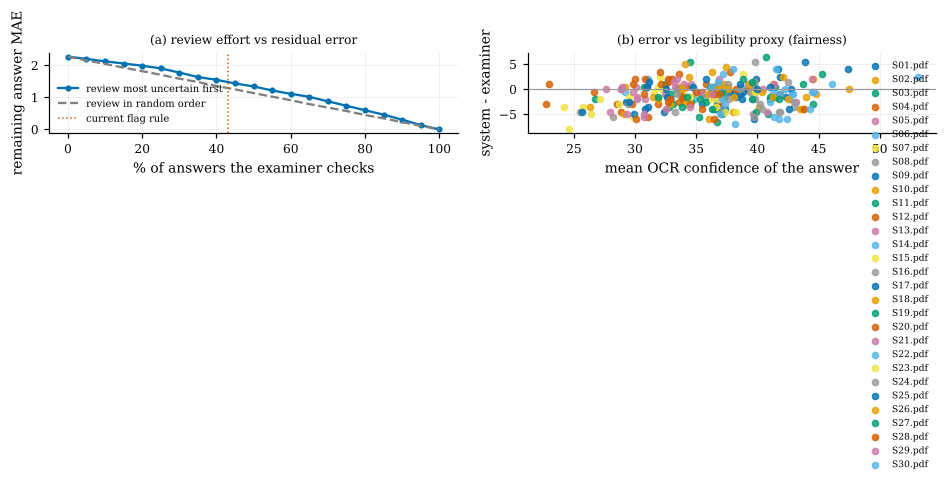


[t30_fairness_by_script] Answer-level bias and error per candidate (attempted answers).


,script,answers,mean error (bias),MAE,mean span OCR conf
0,S01.pdf,10,-1.05,2.65,37.4
1,S02.pdf,10,-1.35,2.05,42.0
2,S03.pdf,10,-1.10,2.90,39.1
3,S04.pdf,10,-1.25,2.35,35.6
4,S05.pdf,10,-0.90,1.90,39.5
5,S06.pdf,10,-0.10,1.50,35.9
6,S07.pdf,10,-1.00,1.60,34.1
7,S08.pdf,10,-1.75,1.85,36.9
8,S09.pdf,10,-1.10,2.30,39.3
9,S10.pdf,10,-1.20,1.60,34.0


Spearman(|error|, span OCR conf) = -0.02 (p = 0.69, n = 282 answers, not independent)
Spearman(|error|, words) = -0.07 (p = 0.23, n = 282 answers, not independent)
Machine time: 971s of OCR for 30 scripts (32s per script), plus scoring.
Examiner workload not estimated: enter measured times in EVAL['EXAMINER_MIN_PER_SCRIPT'] and EVAL['REVIEW_MIN_PER_ANSWER'] (time the examiner on a few scripts; do not assume).



[t31_examiner_consistency] Agreement between two independent examiners on the same 300 answers, against agreement between the system and each examiner (TPC condition 4). If the system-examiner error is no larger than the examiner-examiner error, the system is within human marking variation; if it is larger, it is not. Answer-level CIs resample whole scripts.


,comparison,answers,answer MAE,MAE 95% CI,exact %,within 0.5 %,within 1 %,QWK (answers),"ICC(A,1)",script MAE,script LoA,exact grade band %,QWK (bands)
0,examiner 1 vs examiner 2,300,0.67,0.60-0.75,40.3,40.3,94.0,0.933,0.933,5.83,-11.6 to 0.2,46.7,0.865
1,submitted system (re-run) vs examiner 1,300,3.33,3.03-3.65,6.0,12.3,20.7,0.200,0.200,28.37,-1.9 to 56.1,10.0,0.250
2,submitted system (re-run) vs examiner 2,300,2.91,2.62-3.22,8.7,17.3,24.3,0.256,0.257,23.13,-6.4 to 49.2,10.0,0.371
3,submitted system (re-run) vs mean of examiners,300,3.11,2.82-3.42,6.3,14.7,22.3,0.229,0.229,25.75,-4.0 to 52.5,10.0,0.305
4,system R1 (held-out (constrained)) vs examiner 1,300,2.27,2.02-2.57,8.0,23.3,38.0,0.359,0.360,13.20,-33.7 to 8.0,33.3,0.677
5,system R1 (held-out (constrained)) vs examiner 2,300,2.56,2.28-2.88,9.0,21.3,32.0,0.324,0.325,18.53,-39.4 to 2.3,16.7,0.487
6,system R1 (held-out (constrained)) vs mean of examiners,300,2.40,2.13-2.70,7.7,23.0,34.3,0.345,0.346,15.68,-36.3 to 5.0,30.0,0.600



[t31b_examiner_consistency_written_only] As t31, written answers only (blank answers, which every marker scores 0, removed).


,comparison,answers,answer MAE,exact %,within 1 %,"ICC(A,1)"
0,examiner 1 vs examiner 2,290,0.69,38.6,93.8,0.925
1,submitted system (re-run) vs examiner 1,290,3.39,3.8,19.0,0.128
2,submitted system (re-run) vs examiner 2,290,2.97,6.6,22.8,0.169
3,submitted system (re-run) vs mean of examiners,290,3.17,4.1,20.7,0.149
4,system R1 (held-out (constrained)) vs examiner 1,290,2.33,5.9,36.9,0.318
5,system R1 (held-out (constrained)) vs examiner 2,290,2.62,6.9,30.7,0.283
6,system R1 (held-out (constrained)) vs mean of examiners,290,2.45,5.5,33.1,0.304


  saved r1_fig10_examiner_consistency


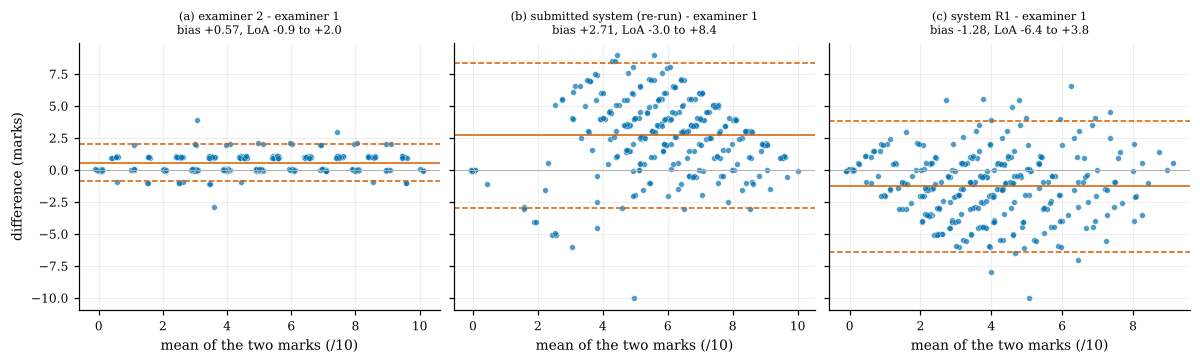

In [62]:
# ============================== 12.15 · REVIEW TRIAGE, WORKLOAD, FAIRNESS, EXAMINER CONSISTENCY ==============================
# Reviewer 3: "Add evidence about teacher workload, review decisions, grading fairness, and consistency between
# human examiners." Reviewer 2: "Use two independent examiners".
if H1 is not None and "R1 moderate" in CAL:
    cfgF = CAL_R1["final"]
    rows = []
    for i, p in enumerate(M_R1.itertuples(index=False)):
        r = marks_from_signals(SIG[p.key], QBYNUM[p.q_rub], cfgF)
        a = ANS_TABLE[(ANS_TABLE["script"] == p.script) & (ANS_TABLE["Q"] == p.q_rub)].iloc[0]
        rows.append({"script": p.script, "Q": p.q_rub, "system (held-out)": CAL_R1["pred_cv"][i],
                     "examiner": CAL_R1["human"][i], "pct": r["pct"], "flags": ",".join(r["flags"]),
                     "locate conf": a["locate conf"], "span OCR conf": a["span OCR conf"], "words": a["words"],
                     "attempted (GT)": a["attempted (GT)"]})
    TRI = pd.DataFrame(rows)
    TRI["error"] = TRI["system (held-out)"] - TRI["examiner"]
    TRI["abs error"] = TRI["error"].abs()
    TRI["flagged"] = (TRI["flags"] != "") | (TRI["locate conf"] < 0.35)
    TRI["flagged (attempted)"] = TRI["flagged"] & ~TRI["flags"].str.contains("NOT_ATTEMPTED")
    big = TRI["abs error"] >= 2

    def _resid(mask):
        e = TRI["abs error"].where(~mask, 0.0)
        return float(e.mean())

    tri = {"answers": len(TRI), "flagged for review": int(TRI["flagged"].sum()),
           "flagged, excluding blank answers": int(TRI["flagged (attempted)"].sum()),
           "MAE of flagged answers": round(float(TRI.loc[TRI["flagged"], "abs error"].mean()), 2) if TRI["flagged"].any() else np.nan,
           "MAE of unflagged answers": round(float(TRI.loc[~TRI["flagged"], "abs error"].mean()), 2) if (~TRI["flagged"]).any() else np.nan,
           "errors >= 2 marks": int(big.sum()),
           "of which flagged": int((big & TRI["flagged"]).sum()),
           "answer MAE before review": round(float(TRI["abs error"].mean()), 2),
           "answer MAE after examiner corrects flagged answers": round(_resid(TRI["flagged"]), 2)}
    r1_table(pd.DataFrame([tri]).T.rename(columns={0: "value"}), "t29_triage",
             "Review triage with the existing flag rule (BORDERLINE_REVIEW, VERY_SHORT, NOT_ATTEMPTED, low locate "
             "confidence). 'After review' assumes the examiner replaces each flagged mark with their own.", index=True)
    R1_FACTS["triage"] = tri

    u = (TRI["pct"].clip(0, 100).pipe(lambda x: np.minimum(x, 100 - x)) / 50) + (1 - TRI["locate conf"])
    order = np.argsort(-u.to_numpy())
    ks = np.linspace(0, 1, 21)
    curve, rnd = [], []
    rr = np.random.default_rng(EVAL["SEED"])
    for k in ks:
        n = int(round(k * len(TRI)))
        m = np.zeros(len(TRI), bool); m[order[:n]] = True
        curve.append(_resid(pd.Series(m, index=TRI.index)))
        vals = []
        for _ in range(200):
            m2 = np.zeros(len(TRI), bool); m2[rr.permutation(len(TRI))[:n]] = True
            vals.append(_resid(pd.Series(m2, index=TRI.index)))
        rnd.append(float(np.mean(vals)))
    fig, ax = plt.subplots(1, 2, figsize=(8.6, 3.2))
    ax[0].plot(100 * ks, curve, "o-", ms=3, color=CB[0], label="review most uncertain first")
    ax[0].plot(100 * ks, rnd, "--", color="0.5", label="review in random order")
    ax[0].axvline(100 * TRI["flagged"].mean(), color=CB[3], lw=1, ls=":", label="current flag rule")
    ax[0].set_xlabel("% of answers the examiner checks"); ax[0].set_ylabel("remaining answer MAE")
    ax[0].set_title("(a) review effort vs residual error", fontsize=8); ax[0].legend(fontsize=6.5, frameon=False)
    for k_, c in enumerate(CODES):
        d = TRI[(TRI["script"] == c) & (TRI["words"] >= CONFIG["MIN_WORDS"])]
        ax[1].scatter(d["span OCR conf"], d["error"], s=16, color=CB[k_ % len(CB)], label=c, alpha=.8)
    ax[1].axhline(0, color="0.6", lw=.8)
    ax[1].set_xlabel("mean OCR confidence of the answer"); ax[1].set_ylabel("system - examiner")
    ax[1].set_title("(b) error vs legibility proxy (fairness)", fontsize=8); ax[1].legend(fontsize=6, frameon=False)
    r1_fig(fig, "r1_fig9_triage_fairness", "Review triage curve and answer-level error against OCR confidence.")
    plt.show()

    att = TRI[TRI["words"] >= CONFIG["MIN_WORDS"]]
    fair = [{"script": c, "answers": len(d), "mean error (bias)": round(d["error"].mean(), 2),
             "MAE": round(d["abs error"].mean(), 2), "mean span OCR conf": round(d["span OCR conf"].mean(), 1)}
            for c, d in att.groupby("script")]
    r1_table(pd.DataFrame(fair), "t30_fairness_by_script", "Answer-level bias and error per candidate (attempted answers).")
    if len(att) > 5:
        for col in ("span OCR conf", "words"):
            rho, pv = spearmanr(att[col], att["abs error"])
            print(f"Spearman(|error|, {col}) = {rho:+.2f} (p = {pv:.2f}, n = {len(att)} answers, not independent)")
            R1_FACTS[f"fairness rho |error| vs {col}"] = round(float(rho), 3)

    machine = sum(REC[c].get("t_total", 0) for c in CODES)
    print(f"Machine time: {machine:.0f}s of OCR for {len(CODES)} scripts ({machine / max(1, len(CODES)):.0f}s per script), "
          f"plus scoring.")
    if EVAL["EXAMINER_MIN_PER_SCRIPT"] and EVAL["REVIEW_MIN_PER_ANSWER"]:
        manual = EVAL["EXAMINER_MIN_PER_SCRIPT"] * len(CODES)
        assisted = EVAL["REVIEW_MIN_PER_ANSWER"] * int(TRI["flagged"].sum())
        print(f"Examiner time: manual {manual:.0f} min vs reviewing flagged answers {assisted:.0f} min "
              f"(from the measured times entered in EVAL).")
        R1_FACTS["workload"] = {"manual_min": manual, "assisted_min": assisted}
    else:
        print("Examiner workload not estimated: enter measured times in EVAL['EXAMINER_MIN_PER_SCRIPT'] and "
              "EVAL['REVIEW_MIN_PER_ANSWER'] (time the examiner on a few scripts; do not assume).")
    TRI.to_csv(f"{R1DIR}/answer_level_R1.csv", index=False)

# ---- examiner-to-examiner consistency (TPC condition 4; Reviewer 2) ----------------------------------------
if H2 is not None and EXAMINER1 is not None:
    def _qm(df):
        m = df[[f"human_Q{n}" for n in QNUMS]].copy(); m.columns = QNUMS
        return m.reindex(CODES)

    E1M, H2M = _qm(EXAMINER1), _qm(H2)
    pub = PUB_KEY                                     # LOCAL RUN: falls back to the submitted system re-run
    comps = [("examiner 1 vs examiner 2", E1M, H2M)]
    for lab, key in ((PUB_LABEL, pub), (f"system R1 ({PRIMARY.split(', ', 1)[1]})", PRIMARY)):
        if key:
            comps += [(f"{lab} vs examiner 1", PRED[key], E1M), (f"{lab} vs examiner 2", PRED[key], H2M),
                      (f"{lab} vs mean of examiners", PRED[key], (E1M + H2M) / 2)]
    grp = np.repeat(np.array(CODES), len(QNUMS))
    rows, rows_att = [], []
    for name, a_, b_ in comps:
        s, h = a_.to_numpy().ravel(), b_.to_numpy().ravel()
        k = ~np.isnan(s) & ~np.isnan(h)
        st = answer_stats(s[k], h[k])
        lo_, hi_ = cluster_ci(s[k], h[k], grp[k], mae)
        sc = script_stats(a_.sum(axis=1).to_numpy(), b_.sum(axis=1).to_numpy())
        rows.append({"comparison": name, "answers": int(k.sum()), "answer MAE": round(st["MAE"], 2),
                     "MAE 95% CI": f"{lo_:.2f}-{hi_:.2f}", "exact %": round(st["exact %"], 1),
                     "within 0.5 %": round(st["within 0.5 %"], 1), "within 1 %": round(st["within 1 %"], 1),
                     "QWK (answers)": round(st["QWK (half-mark scale)"], 3), "ICC(A,1)": round(st["ICC(A,1)"], 3),
                     "script MAE": round(sc["MAE"], 2), "script LoA": f"{sc['LoA lower']:.1f} to {sc['LoA upper']:.1f}",
                     "exact grade band %": round(sc["exact band %"], 1), "QWK (bands)": round(sc["QWK (bands)"], 3)})
        att = np.array([[(qn in (GT_ATTEMPTED.get(c) or [])) if GT_ATTEMPTED.get(c) is not None else E1M.loc[c, qn] > 0
                         for qn in QNUMS] for c in CODES]).ravel() & k
        st2 = answer_stats(s[att], h[att])
        rows_att.append({"comparison": name, "answers": int(att.sum()), "answer MAE": round(st2["MAE"], 2),
                         "exact %": round(st2["exact %"], 1), "within 1 %": round(st2["within 1 %"], 1),
                         "ICC(A,1)": round(st2["ICC(A,1)"], 3)})
    CONS = r1_table(pd.DataFrame(rows), "t31_examiner_consistency",
                    f"Agreement between two independent examiners on the same {len(CODES) * len(QNUMS)} answers, against agreement between "
                    "the system and each examiner (TPC condition 4). If the system-examiner error is no larger than "
                    "the examiner-examiner error, the system is within human marking variation; if it is larger, it "
                    "is not. Answer-level CIs resample whole scripts.")
    r1_table(pd.DataFrame(rows_att), "t31b_examiner_consistency_written_only",
             "As t31, written answers only (blank answers, which every marker scores 0, removed).")
    R1_FACTS["examiner consistency"] = CONS.to_dict("records")

    e12 = (H2M - E1M).to_numpy().ravel()
    m12 = ((H2M + E1M) / 2).to_numpy().ravel()
    panels = [("(a) examiner 2 - examiner 1", e12, m12)]
    for lab, key in ((f"(b) {PUB_LABEL} - examiner 1", pub), ("(c) system R1 - examiner 1", PRIMARY)):
        if key:
            s_ = PRED[key].to_numpy().ravel(); e_ = E1M.to_numpy().ravel()
            panels.append((lab, s_ - e_, (s_ + e_) / 2))
    fig, axs = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 3.2), sharey=True)
    axs = np.atleast_1d(axs)
    rj = np.random.default_rng(4)
    for a_, (t_, d_, m_) in zip(axs, panels):
        k = ~np.isnan(d_)
        a_.scatter(m_[k] + rj.uniform(-.12, .12, k.sum()), d_[k] + rj.uniform(-.08, .08, k.sum()),
                   s=14, color=CB[0], alpha=.7, edgecolor="white", lw=.3)
        mu, sd = d_[k].mean(), d_[k].std(ddof=1)
        for v, ls in ((mu, "-"), (mu + 1.96 * sd, "--"), (mu - 1.96 * sd, "--")):
            a_.axhline(v, color=CB[3], ls=ls, lw=1)
        a_.axhline(0, color="0.7", lw=.7)
        a_.set_title(f"{t_}\nbias {mu:+.2f}, LoA {mu - 1.96 * sd:+.1f} to {mu + 1.96 * sd:+.1f}", fontsize=7.5)
        a_.set_xlabel("mean of the two marks (/10)")
    axs[0].set_ylabel("difference (marks)")
    r1_fig(fig, "r1_fig10_examiner_consistency",
           f"Answer-level Bland-Altman plots ({len(CODES) * len(QNUMS)} answers, jittered): the second examiner against the first, and the "
           "system against the first examiner.")
    plt.show()
else:
    print("Second examiner not supplied (TPC condition 4 needs it). Add examiner 2's marks file (with 'examiner2' in "
          "its name) to the start-up upload in section 3 and run the notebook again.")

## 12.16 · Item-analysis sensitivity
*R2: "These statistics describe the system's marks on five scripts, not the quality of the question paper. Remove the section or reduce it to one sentence."*

In [63]:
# ============================== 12.16 · ITEM-ANALYSIS SENSITIVITY ==============================
# Reviewer 2: "With n = 5, the top and bottom 27% groups contain one student each ... these statistics describe the
# system's marks on five scripts, not the quality of the question paper."
k27 = max(1, int(round(0.27 * len(CODES))))
rows = []
for name, mat in [(PUB_LABEL if "PUB_LABEL" in globals() else "system as published",
                   PRED.get(PUB_KEY) if globals().get("PUB_KEY") else None),
                  ("system R1 held-out", PRED.get(PRIMARY) if "PRIMARY" in globals() else None),
                  ("examiner", HM)]:
    if mat is None:
        continue
    df_ = mat.copy(); df_.columns = [f"Q{c}" for c in df_.columns]
    df_["total"] = df_.sum(axis=1)
    low = df_["total"].idxmin()
    rows.append({"marks": name, "Cronbach alpha (all)": round(cronbach_alpha(df_, list(df_.columns[:-1])), 3),
                 f"alpha without {low}": round(cronbach_alpha(df_.drop(index=low), list(df_.columns[:-1])), 3),
                 "students per 27% group": k27})
ITEM_SENS = r1_table(pd.DataFrame(rows), "t32_item_analysis_sensitivity",
                     f"Cronbach's alpha with and without the lowest-scoring script. With {len(CODES)} scripts each "
                     f"27% group holds {k27} student(s)" + (", so the discrimination index D is the difference between two "
                     "individual scripts" if k27 == 1 else "") + ". Item statistics are reported here only as a "
                     "description of these marks.")
R1_FACTS["item analysis"] = ITEM_SENS.to_dict("records")


[t32_item_analysis_sensitivity] Cronbach's alpha with and without the lowest-scoring script. With 30 scripts each 27% group holds 8 student(s). Item statistics are reported here only as a description of these marks.


,marks,Cronbach alpha (all),alpha without S30.pdf,students per 27% group,alpha without S23.pdf,alpha without S21.pdf
0,submitted system (re-run),0.891,0.833,8,NaN,NaN
1,system R1 held-out,0.905,NaN,8,0.893,NaN
2,examiner,0.891,NaN,8,NaN,0.865


## 12.17 · Reviewer-response map, exports and Word report

In [64]:
# ============================== 12.17 · REVIEWER-RESPONSE SUMMARY, EXPORTS, WORD REPORT ==============================
# full per-key-point audit trail of the R1 system for every answer (final calibrated ramp)
if "R1 moderate" in CAL:
    aud = []
    for p in M_R1.itertuples(index=False):
        r = marks_from_signals(SIG[p.key], QBYNUM[p.q_rub], CAL_R1["final"])
        for d in r["detail"]:
            aud.append({"script": p.script, "Q": p.q_rub, "answer marks": r["marks"], "flags": ",".join(r["flags"]), **d})
        if not r["detail"]:
            aud.append({"script": p.script, "Q": p.q_rub, "answer marks": 0.0, "flags": ",".join(r["flags"])})
    pd.DataFrame(aud).to_csv(f"{R1DIR}/audit_trail_R1.csv", index=False)
    print(f"Audit trail for all {len(M_R1)} answers: {R1DIR}/audit_trail_R1.csv")


def _fact(path, default="see table"):
    cur = R1_FACTS
    for k in path:
        if isinstance(cur, dict) and k in cur:
            cur = cur[k]
        else:
            return default
    return cur


RESPONSE = [
    ("R1", "Localisation shown for one script; no corpus-level precision/recall", "t02, t03",
     f"word F1 submitted {_fact(['localisation', LOC_SUBMITTED, 'word F1'])} -> R1 {_fact(['localisation', LOC_REVISED, 'word F1'])}"),
    ("R1", "Red-ink requirement unrealistic / unexplained", "declaration, t06, r1_fig4",
     "stress tests: forgotten pen, examiner marks; protocol to be stated by authors"),
    ("R1", "Sample screens of how the image is processed across red", "r1_fig1-3", "colour, mask, binarised, margin decisions"),
    ("R1", "Comparison with poor OCR", "t08, t14, t28", "measured CER/WER; synthetic-noise curves; TrOCR"),
    ("R1", "Text-only vs red; greedy vs Hungarian; single signals vs ensemble; HTR/VLM", "t02, t06, t27, t28",
     "all four ablations"),
    ("R1", "At least 50 papers", "-", f"{len(CODES)} scripts, {len(CODES) * len(QNUMS)} answers; LOSO held-out; protocol frozen"),
    ("R2", "Kappa driven by the failing script", "t24", f"{_fact(['kappa sensitivity'])!s:.120}"),
    ("R2", "Thresholds not fixed in advance; no calibration set", "t18, t19, t20", "LOSO held-out; sensitivity; frozen protocol"),
    ("R2", "Examiner an author? marks fixed before? who wrote scheme?", "study_declaration.json", "to be filled by authors"),
    ("R2", "Lexical signal saturates (partial_token_set_ratio)", "t10, t13",
     f"free credit per key point {_fact(['free credit per key point (submitted)'])}; replaced by content-token overlap"),
    ("R2", "Short anchor terms match by chance", "t11", "token matching with length-aware thresholds"),
    ("R2", "Negative controls (wrong question, random text, signal distributions)", "t12, t13, r1_fig5", "all three + more"),
    ("R2", "Localisation not validated; 14 vs 13 marks; surplus spans", "t01, t05", "every mark accounted for; spans merged"),
    ("R2", "Red-ink protocol; examiner red marks", "t01 (outside-margin column), t06", "margin filter + stress test"),
    ("R2", "Misreported direction of errors; regression intercept", "t23, t26", f"{_fact(['grade changes'])!s:.160}"),
    ("R2", "Item analysis adds little", "t32", "alpha without the failing script; D from single scripts"),
    ("R2", "Unit of analysis = answer; exact / within 0.5 / within 1", "t21", "answer-level with cluster-bootstrap CIs"),
    ("R2", "Mark granularity (Q9 0.35, Q10 0.98 impossible)", "t22", f"{_fact(['granularity', 'examiner'])} vs half marks"),
    ("R2", "Ethics; replace USNs", "section 3b", f"codes S01..S{len(CODES):02d}; header redaction; private map"),
    ("R2", "Two independent examiners", "t31", f"examiner 2 marked {len(H2)} scripts" if H2 is not None else
     "ready; needs a second examiner's marks"),
    ("R3", "Selection, provenance, permission", "study_declaration.json", "to be filled by authors"),
    ("R3", "Independent evaluation set", "t18, t21", "LOSO held-out estimates"),
    ("R3", "OCR confidence is not an error rate", "t08", "CER/WER against manual transcription"),
    ("R3", "Localisation separately; continued answers, repeated numbers, subparts, optional", "t02, t06", "stress suite"),
    ("R3", "Multi-page answers and one-to-one assignment", "t05", "continuation policy"),
    ("R3", "Incorrect answers with keywords; correct answers worded differently", "t12, t14", "keyword-stuffed; held-out ALT"),
    ("R3", "Correlation is not agreement; LoA; 60% exact bands", "t21, t23", "LoA with CIs, exact %"),
    ("R3", "Grade-band discussion and regression interpretation", "t23, t26", "computed directly"),
    ("R3", "Privacy claim (cloud notebook vs on-premise)", "t00", ENV["where"]),
    ("R3", "Workload, review decisions, fairness, examiner consistency", "t29, t30, t31, r1_fig9", "triage curve; bias by script"),
]
RESP = r1_table(pd.DataFrame(RESPONSE, columns=["reviewer", "comment", "evidence", "key result"]),
                "t33_reviewer_response", "Where each reviewer comment is answered in this notebook.")

# ---- ICTIEE 2027 conditional acceptance: the seven conditions, with the evidence filled in ---------------------
def _g(d, *keys, default=None):
    for k in keys:
        if isinstance(d, dict) and k in d:
            d = d[k]
        else:
            return default
    return d


def _dist(scorer, lab):
    r = next((x for x in R1_FACTS.get("score distributions", []) if x.get("scorer") == scorer and x.get("pair type") == lab), None)
    return r or {}


_pub = globals().get("PUB_KEY")                       # LOCAL RUN: as published, else the submitted system re-run
_publab = globals().get("PUB_LABEL", "system as published")
_n_gt = sum(1 for c in CODES if GT_LINES.get(c) is not None)
_lsub, _lr1 = _g(R1_FACTS, "localisation per condition 3", "submitted", default={}), _g(R1_FACTS, "localisation per condition 3", "R1", default={})
_m, _w = "matched (own question)", "mismatched: wrong question's key points"
_rw, _rc = "random OCR words, same length", "random characters, same length"
_S, _R = "submitted, published ramp", "R1, calibrated"


def _dsent(scorer):
    dm, dw, dr = _dist(scorer, _m), _dist(scorer, _w), _dist(scorer, _rw)
    if not dm:
        return ""
    auc = _g(R1_FACTS, "score AUC matched vs wrong question", scorer, default=float("nan"))
    return (f"matched pairs median {dm.get('median')}/10 (IQR {dm.get('IQR')}), wrong-question pairs median "
            f"{dw.get('median')}/10 (IQR {dw.get('IQR')}, {dw.get('% scored > 0')}% given any credit), random text of "
            f"the same length median {dr.get('median')}/10 ({dr.get('% scored > 0')}% given credit); AUC {auc:.2f}")


_gc = R1_FACTS.get("grade changes", {}).get(_pub, {}) if _pub else {}
_gc_rows = GC[(GC["configuration"] == _pub) & (GC["grade moved"] != "same")] if _pub and "GC" in globals() else pd.DataFrame()
_gc_txt = "; ".join(f"{str(r['script']).replace('.pdf', '')} {r['examiner grade']} -> {r['system grade']} ({r['grade moved']})"
                    for _, r in _gc_rows.iterrows())
_sa = R1_FACTS.get("script agreement", {}).get(_pub, {}) if _pub else {}
_cons = {r["comparison"]: r for r in R1_FACTS.get("examiner consistency", [])}
_c12 = _cons.get("examiner 1 vs examiner 2")
_csp = _cons.get(f"{_publab} vs examiner 1")
_csr = next((v for k, v in _cons.items() if k.startswith("system R1") and k.endswith("vs examiner 1")), None)
_sat = R1_FACTS.get("lexical saturation", {})
_auc = R1_FACTS.get("signal AUC", {})


def _cons_txt(r):
    return (f"MAE {r['answer MAE']} (95% CI {r['MAE 95% CI']}), exact {r['exact %']}%, within 0.5 {r['within 0.5 %']}%, "
            f"within 1 {r['within 1 %']}%, ICC(A,1) {r['ICC(A,1)']}") if r else "n/a"


TPC = [
    ("1", "Remove all student USNs from figures and tables, and remove the Colab/Google Drive link.",
     f"Scripts were renamed S01-S{len(CODES):02d} before processing; page-1 headers are blacked out in every page image; OCR header "
     "lines are redacted; reference data are matched by file hash. All exported tables, figures and reports were "
     "scanned automatically for registration numbers (result in t35). The Colab/Google Drive link is removed from "
     "the manuscript.", "t35, section 3b"),
    ("2", "Add negative controls ... Report the score distributions for matched and mismatched pairs.",
     f"Every written answer was scored against its own question (matched), against the other nine questions' key "
     f"points (mismatched) and against random text of the same length. Submitted scorer: {_dsent(_S)}. Revised "
     f"scorer: {_dsent(_R)}.", "t12, t12b, t13, r1_fig5, r1_fig5b"),
    ("3", "Report localisation accuracy (correct question and correct answer boundary) for all five scripts.",
     (f"Against answer starts labelled from the page images for all {_n_gt} scripts [authors: confirm the labels "
      f"with the r1/gt_check_*.png sheets]: submitted pipeline - correct question "
      f"{_lsub.get('correct question')}, correct boundary {_lsub.get('correct boundary')} written answers, "
      f"{_lsub.get('words not graded')} words of answers not graded; revised pipeline - correct question "
      f"{_lr1.get('correct question')}, correct boundary {_lr1.get('correct boundary')}, "
      f"{_lr1.get('words not graded')} words not graded.") if _n_gt else
     "NOT YET AVAILABLE - these scripts have no answer-boundary labels (REFERENCE_DATA, section 3b).",
     "t03, t03b, t02, t01"),
    ("4", "Second examiner ... agreement between the two examiners ... compared with ... system and the examiner.",
     (f"Examiner 1 vs examiner 2: {_cons_txt(_c12)}. {_publab[0].upper() + _publab[1:]} vs examiner 1: {_cons_txt(_csp)}. "
      f"Revised system vs examiner 1: {_cons_txt(_csr)}.") if _c12 else
     "NOT YET AVAILABLE - upload the second examiner's marks and re-run 12.1 and 12.15.", "t31, t31b, r1_fig10"),
    ("5", "Correct the statement that no candidate was graded down. Fig. 12 shows an A->B change.",
     f"Corrected. Grade-band changes of the {_publab} against examiner 1 on these {len(CODES)} scripts: "
     f"{_gc_txt or 'none'} - {_gc.get('up', '?')} up, "
     f"{_gc.get('down', '?')} down. The regression of system on examiner totals is y = {_sa.get('slope', float('nan')):.2f}x "
     f"{_sa.get('intercept', float('nan')):+.1f}; the statement that it has no intercept is also corrected.", "t26, t23"),
    ("6", "Replace or justify the lexical similarity measure, which returns 100 when two texts share a single word.",
     f"Replaced. partial_token_set_ratio equalled 1.0 for {_g(_sat, 'wrong question', 'pct_lex_submitted_eq_1')}% of key "
     f"points of answers scored against the wrong question and gave every prose key point "
     f"{100 * (R1_FACTS.get('free credit per key point (submitted)') or 0):.0f}% credit before any content matched. It is "
     f"replaced by the share of the key point's content words, stop-words removed, found in the answer with length-"
     f"dependent fuzzy matching ({_g(_sat, 'wrong question', 'pct_lex_R1_eq_1')}% of wrong-question key points reach 1.0). "
     f"Separation of own-question from "
     f"wrong-question key points: AUC {_auc.get('lexical, submitted')} (submitted) vs {_auc.get('lexical, R1')} (revised).",
     "t10, t11, t13"),
    ("7", "Present the work as a pilot study, and limit the claims to the five scripts evaluated.",
     f"The manuscript is reframed as a pilot study of {len(CODES)} scripts ({len(CODES) * len(QNUMS)} answers) from one "
     f"examination; all statistics are reported for these scripts only, with cluster-bootstrap CIs, held-out "
     f"(leave-one-script-out) estimates, and the limitations listed.", "t18, t21, t23"),
]
TPC_TABLE = r1_table(pd.DataFrame(TPC, columns=["condition", "requirement", "response (numbers from this run)", "evidence"]),
                     "t34_tpc_conditions", "ICTIEE 2027 conditional acceptance: each condition and the evidence produced "
                     "by this run. 'Where in the paper' is added by the authors in the response document.")


def privacy_audit():
    """Scan every exported text, table, report and figure for registration numbers or original file names."""
    stems = [os.path.splitext(o)[0] for o in ANON_MAP if not re.fullmatch(r"S\d+\.pdf", o)]
    pats = [_ID_PATTERNS[0]] + [re.compile(re.escape(s), re.I) for s in stems]
    fuzzy = re.compile(r"[1lI]?\s*N\s*C\s*2\s*[0-9]\s*C\s*D", re.I)

    def _hits(txt):
        return sorted({m.group(0) for p in pats + [fuzzy] for m in p.finditer(txt)})

    rows = []
    outdir = os.path.dirname(RESULTS_CSV) or "."
    roots = [R1DIR, R1FIG, FIGDIR, outdir]
    seen = set()
    for root in roots:
        for f in glob.glob(f"{root}/**/*", recursive=True):
            if f in seen or os.path.isdir(f) or "/private/" in f or "pages_for_transcription" in f:
                continue
            seen.add(f)
            b = os.path.basename(f).lower()
            if b.startswith("human_marks") or "/scripts" in f or "/cache/" in f or "/transcripts/" in f:
                continue                                   # inputs and working caches, not exports
            ext = os.path.splitext(b)[1]
            if ext == ".csv":
                try:
                    if any(str(col).startswith("human_Q") for col in pd.read_csv(f, nrows=0).columns):
                        continue                           # an examiner's marks file: an input, not an export
                except Exception:
                    pass
            txt = ""
            try:
                if ext in (".csv", ".tex", ".json", ".txt", ".md"):
                    txt = open(f, encoding="utf-8", errors="ignore").read()
                elif ext == ".xlsx":
                    txt = " ".join(s_.to_csv() for s_ in pd.read_excel(f, sheet_name=None).values())
                elif ext == ".docx":
                    from docx import Document as _D
                    dd = _D(f)
                    txt = "\n".join(p.text for p in dd.paragraphs) + "\n".join(c.text for t in dd.tables
                                                                                for r in t.rows for c in r.cells)
                elif ext == ".zip":
                    with zipfile.ZipFile(f) as z:
                        txt = " ".join(z.namelist()) + " " + " ".join(
                            z.read(n).decode("utf-8", "ignore") for n in z.namelist()
                            if n.endswith((".csv", ".tex", ".json", ".txt")))
                elif ext == ".png":
                    txt = pytesseract.image_to_string(Image.open(f).convert("L"))
                else:
                    continue
            except Exception as ex:
                rows.append({"file": os.path.relpath(f, WORK), "identifiers found": f"not checked ({type(ex).__name__})"})
                continue
            h = _hits(txt)
            rows.append({"file": os.path.relpath(f, WORK), "identifiers found": ", ".join(h) if h else ""})
    return pd.DataFrame(rows)


# ---- exports -----------------------------------------------------------------------------------------------
with open(f"{R1DIR}/R1_tables.tex", "w") as fh:
    for name, (df_, cap, idx) in R1_TABLES.items():
        try:
            fh.write(f"% ---- {name} ----\n" + df_.to_latex(index=idx, escape=True, caption=cap[:200],
                                                           label=f"tab:{name}", float_format="%.3g") + "\n\n")
        except Exception as ex:
            fh.write(f"% {name}: {ex}\n")
with open(f"{R1DIR}/R1_facts.json", "w") as fh:
    json.dump(R1_FACTS, fh, indent=2, default=str)


def _docx_table(doc, d, Pt, max_rows=60):
    d = d.head(max_rows)
    t = doc.add_table(rows=1, cols=len(d.columns)); t.style = "Table Grid"
    for j, c in enumerate(d.columns):
        t.rows[0].cells[j].text = str(c)
    for _, r in d.iterrows():
        cells = t.add_row().cells
        for j, v in enumerate(r):
            cells[j].text = (f"{v:.3f}" if isinstance(v, float) and abs(v) < 1000 else str(v))[:400]
    for row in t.rows:
        for cell in row.cells:
            for para in cell.paragraphs:
                for run in para.runs:
                    run.font.size = Pt(6.5 if len(d.columns) > 8 else 8)
    return t


def write_tpc_response(path):
    """Draft of the response document the TPC asked for: each condition, the response, the evidence."""
    from docx import Document as _Doc
    from docx.shared import Pt
    doc = _Doc()
    st = doc.styles["Normal"]; st.font.name = "Calibri"; st.font.size = Pt(10)
    doc.add_heading("Paper ID 118 - Response to the conditions for acceptance (ICTIEE 2027)", 0)
    doc.add_paragraph("RedAnchor-ASAG: AI-Driven Colour-Anchored Answer Localisation and Rubric-Weighted Partial Credit "
                      "for Auditable Automatic Grading of Handwritten Examination Scripts under Low-Confidence OCR")
    doc.add_paragraph("We thank the Technical Program Committee and the reviewers. Each condition is answered below. "
                      "Numbers come from the revised analysis notebook; changes in the manuscript are highlighted. "
                      "Text in [square brackets] is to be completed by the authors.")
    keyt = {"1": ["t35_privacy_audit"], "2": ["t12b_score_distributions"], "3": ["t03_localisation_per_script"],
            "4": ["t31_examiner_consistency"], "5": ["t26_grade_changes"], "6": ["t10_lexical_saturation"], "7": []}
    for num, req, resp, ev in TPC:
        doc.add_heading(f"Condition {num}", 1)
        p = doc.add_paragraph(); r = p.add_run("Condition: "); r.bold = True; p.add_run(req)
        p = doc.add_paragraph(); r = p.add_run("Response: "); r.bold = True; p.add_run(resp)
        p = doc.add_paragraph(); r = p.add_run("Where in the paper: "); r.bold = True
        p.add_run("[Section / Table / Figure numbers in the revised manuscript]")
        p = doc.add_paragraph(); r = p.add_run("Supporting material: "); r.bold = True; p.add_run(ev)
        for tname in keyt.get(num, []):
            if tname in R1_TABLES:
                d, cap, idx = R1_TABLES[tname]
                d = d.reset_index() if idx else d
                if tname == "t26_grade_changes" and _pub:
                    d = d[d["configuration"] == _pub]
                if tname == "t35_privacy_audit":
                    d = pd.DataFrame([{"files checked": len(d), "files with identifiers": int((d["identifiers found"] != "").sum())}])
                doc.add_paragraph(cap).runs[0].italic = True
                _docx_table(doc, d, Pt)
    doc.add_heading("Statement of study conditions", 1)
    for k, v in STUDY_DECLARATION.items():
        doc.add_paragraph(f"{k.replace('_', ' ')}: {v if v is not None else '[to be stated]'}", style="List Bullet")
    doc.save(path)
    return path


def write_word_report(path):
    from docx import Document as _Doc
    from docx.shared import Pt, Inches
    doc = _Doc()
    st = doc.styles["Normal"]; st.font.name = "Calibri"; st.font.size = Pt(9)
    doc.add_heading("RedAnchor-ASAG - Revision R1: evaluation results", 0)
    doc.add_heading("ICTIEE 2027 conditions for acceptance", 1)
    _docx_table(doc, TPC_TABLE, Pt)
    doc.add_paragraph(f"Generated {ENV['run_utc']} UTC on {ENV['where']}. Scheme sha256 {ENV['scheme sha256']}; "
                      f"semantic backend {ENV['semantic backend']}; Tesseract {ENV['tesseract']}. Scripts are coded "
                      f"S01..S{len(CODES):02d}; no registration numbers appear in this report.")
    doc.add_heading("Study declaration", 1)
    for k, v in STUDY_DECLARATION.items():
        doc.add_paragraph(f"{k}: {v if v is not None else 'NOT YET STATED'}", style="List Bullet")
    for name, (df_, cap, idx) in R1_TABLES.items():
        if name == "t34_tpc_conditions":
            continue
        d = df_.reset_index() if idx else df_
        doc.add_heading(name, 2); doc.add_paragraph(cap)
        _docx_table(doc, d, Pt, max_rows=60)
    doc.add_heading("Figures", 1)
    for p, cap in R1_FIGS:
        try:
            doc.add_picture(p, width=Inches(6.3)); doc.add_paragraph(cap)
        except Exception:
            pass
    doc.save(path)
    return path


AUDIT = privacy_audit()
r1_table(AUDIT, "t35_privacy_audit", "Automatic check of every exported table, figure, report and bundle for student "
         "registration numbers or original file names (TPC condition 1). Figures are read with OCR.", show=False)
_bad = AUDIT[AUDIT["identifiers found"] != ""]
print(f"Privacy audit (condition 1): {len(AUDIT)} exported files checked - "
      + ("PASS, no registration numbers found." if not len(_bad) else f"FAIL in {len(_bad)} file(s):"))
if len(_bad):
    display(_bad)
R1_FACTS["privacy audit"] = {"files": len(AUDIT), "with identifiers": len(_bad)}

try:
    rep = write_word_report(f"{R1DIR}/R1_results_report.docx")
    print("Word report:", rep)
except Exception as ex:
    rep = None
    print("Word report not written:", ex)
try:
    resp = write_tpc_response(f"{R1DIR}/TPC_response_draft.docx")
    print("Response-document draft:", resp)
except Exception as ex:
    resp = None
    print("Response draft not written:", ex)

bundle = f"{WORK}/R1_reviewer_response_bundle.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(R1DIR):
        if "pages_for_transcription" in root:
            continue                                   # student handwriting: keep out of the shareable bundle
        for f in fs:
            if f.endswith(".zip"):
                continue
            z.write(os.path.join(root, f), os.path.join("r1", os.path.relpath(os.path.join(root, f), R1DIR)))
    for f in glob.glob(f"{R1FIG}/*"):
        z.write(f, f"figures/{os.path.basename(f)}")
    z.write(f"{WORK}/study_declaration.json", "study_declaration.json")
print(f"{len(R1_TABLES)} tables, {len(R1_FIGS)} figures -> {bundle}")

# ---- ONE download with every result of this run ------------------------------------------------------------
FINAL_ZIP = f"{WORK}/RedAnchor_R1_ALL_RESULTS.zip"
README = f"""RedAnchor-ASAG - Revision R1 - all results of the run on {ENV['run_utc']} UTC
Scripts are coded S01..S{len(CODES):02d}; the code-to-file map is NOT included (it stays in the private folder of the run).

FOR THE SUBMISSION
  TPC_response_draft.docx        response to the 7 ICTIEE conditions, numbers filled in ([brackets] to complete)
  R1_results_report.docx         every new table and figure with captions
  r1/t*.csv, r1/R1_tables.tex    the tables (CSV and LaTeX); r1/R1_facts.json = key numbers
  figures/r1/*.png|pdf           new figures (r1_fig1 ... r1_fig10)
  figures/*.png|pdf              the original Tier-1/Tier-2 figures, regenerated with codes
  tables/                        the original tables (cohort summary, item analysis, ...)
  marks/                         system marks per script and question (marks.csv / marks.xlsx)
  R1_reviewer_response_bundle.zip  the shareable subset (no handwriting images)
  study_declaration.json         the declaration from section 3b
PRIVATE - NOT FOR SUBMISSION
  private_not_for_submission/pages_for_transcription/   page images to transcribe for the CER/WER check (12.5)
Privacy audit (condition 1): {R1_FACTS.get('privacy audit', {}).get('files', '?')} files checked, \
{R1_FACTS.get('privacy audit', {}).get('with identifiers', '?')} with identifiers.
"""
_outdir = os.path.dirname(RESULTS_CSV) or "."
with zipfile.ZipFile(FINAL_ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    z.writestr("README.txt", README)
    for p in (rep, resp):
        if p and os.path.exists(p):
            z.write(p, os.path.basename(p))
    for root, _, fs in os.walk(R1DIR):
        for f in fs:
            full = os.path.join(root, f)
            if f.endswith(".zip") or f in ("TPC_response_draft.docx", "R1_results_report.docx"):
                continue
            rel = os.path.relpath(full, R1DIR)
            arc = (f"private_not_for_submission/{rel}" if "pages_for_transcription" in rel else f"r1/{rel}")
            z.write(full, arc)
    for root, _, fs in os.walk(FIGDIR):
        for f in fs:
            full = os.path.join(root, f)
            z.write(full, os.path.join("figures", os.path.relpath(full, FIGDIR)))
    for f in sorted(glob.glob(f"{_outdir}/table*.csv") + glob.glob(f"{_outdir}/tables.tex")):
        z.write(f, f"tables/{os.path.basename(f)}")
    for f in (f"{_outdir}/marks.csv", f"{_outdir}/marks.xlsx"):
        if os.path.exists(f):
            z.write(f, f"marks/{os.path.basename(f)}")
    for f in (bundle, f"{WORK}/study_declaration.json"):
        if os.path.exists(f):
            z.write(f, os.path.basename(f))
print(f"All results: {FINAL_ZIP} ({os.path.getsize(FINAL_ZIP) / 1e6:.1f} MB)")
print("Not included: the code-to-file map (private).")
if IN_COLAB:
    from google.colab import files as _f
    _f.download(FINAL_ZIP)
    print("Download started: RedAnchor_R1_ALL_RESULTS.zip (allow the download if the browser asks).")
    if "PERSIST_DIR" in globals() and PERSIST_DIR:
        shutil.copy(FINAL_ZIP, f"{PERSIST_DIR}/RedAnchor_R1_ALL_RESULTS.zip")
        print(f"A copy is also on your Google Drive: {PERSIST_DIR}/RedAnchor_R1_ALL_RESULTS.zip")

Audit trail for all 300 answers: /content/grading/r1/audit_trail_R1.csv

[t33_reviewer_response] Where each reviewer comment is answered in this notebook.


,reviewer,comment,evidence,key result
0,R1,Localisation shown for one script; no corpus-level precision/recall,"t02, t03",word F1 submitted 0.858 -> R1 0.9
1,R1,Red-ink requirement unrealistic / unexplained,"declaration, t06, r1_fig4","stress tests: forgotten pen, examiner marks; protocol to be stated by authors"
2,R1,Sample screens of how the image is processed across red,r1_fig1-3,"colour, mask, binarised, margin decisions"
3,R1,Comparison with poor OCR,"t08, t14, t28",measured CER/WER; synthetic-noise curves; TrOCR
4,R1,Text-only vs red; greedy vs Hungarian; single signals vs ensemble; HTR/VLM,"t02, t06, t27, t28",all four ablations
5,R1,At least 50 papers,-,"30 scripts, 300 answers; LOSO held-out; protocol frozen"
6,R2,Kappa driven by the failing script,t24,"[{'configuration': 'submitted, re-run (published ramp)', 'QWK all 5': 0.25, ..."
7,R2,Thresholds not fixed in advance; no calibration set,"t18, t19, t20",LOSO held-out; sensitivity; frozen protocol
8,R2,Examiner an author? marks fixed before? who wrote scheme?,study_declaration.json,to be filled by authors
9,R2,Lexical signal saturates (partial_token_set_ratio),"t10, t13",free credit per key point 0.223; replaced by content-token overlap



[t34_tpc_conditions] ICTIEE 2027 conditional acceptance: each condition and the evidence produced by this run. 'Where in the paper' is added by the authors in the response document.


,condition,requirement,response (numbers from this run),evidence
0,1,"Remove all student USNs from figures and tables, and remove the Colab/Google...",Scripts were renamed S01-S30 before processing; page-1 headers are blacked o...,"t35, section 3b"
1,2,Add negative controls ... Report the score distributions for matched and mis...,"Every written answer was scored against its own question (matched), against ...","t12, t12b, t13, r1_fig5, r1_fig5b"
2,3,Report localisation accuracy (correct question and correct answer boundary) ...,Against answer starts labelled from the page images for all 30 scripts [auth...,"t03, t03b, t02, t01"
3,4,Second examiner ... agreement between the two examiners ... compared with .....,"Examiner 1 vs examiner 2: MAE 0.67 (95% CI 0.60-0.75), exact 40.3%, within 0...","t31, t31b, r1_fig10"
4,5,Correct the statement that no candidate was graded down. Fig. 12 shows an A-...,Corrected. Grade-band changes of the submitted system (re-run) against exami...,"t26, t23"
5,6,"Replace or justify the lexical similarity measure, which returns 100 when tw...",Replaced. partial_token_set_ratio equalled 1.0 for 91.9% of key points of an...,"t10, t11, t13"
6,7,"Present the work as a pilot study, and limit the claims to the five scripts ...",The manuscript is reframed as a pilot study of 30 scripts (300 answers) from...,"t18, t21, t23"


Privacy audit (condition 1): 191 exported files checked - PASS, no registration numbers found.


Word report: /content/grading/r1/R1_results_report.docx


Response-document draft: /content/grading/r1/TPC_response_draft.docx


37 tables, 11 figures -> /content/grading/R1_reviewer_response_bundle.zip


All results: /content/grading/RedAnchor_R1_ALL_RESULTS.zip (98.5 MB)
Not included: the code-to-file map (private).
